# MobiPredict — Flujo MLOps de extremo a extremo con datos reales

**Velocidad de los corredores de Medellín a 1 hora, alertas de colapso y demanda/densidad con la EOD 2025 (AMVA).**

```
Fuentes oficiales ─► Estandarización ─► EDA ─► Features ─► Entrenamiento + Optuna ─► MLflow ─► Selección ─► API ─► Docker
```

| Fuente | Uso | Enlace |
| --- | --- | --- |
| Cámaras ARS/CCTV del SIMM (Observatorio de Movilidad) | **Serie del modelo vigente**, 22 tramos, sep-2019 a sep-2026 | Exportación de bases diarias (no es dato abierto) |
| Velocidad y tiempo de viaje GT (SIMM, MEData) | Serie del modelo anterior y del EDA, 22 tramos, 2017-2020 | https://www.datos.gov.co/d/7t5n-3b3w |
| EOD 2025 (AMVA), API del visor oficial | Demanda horaria, reparto modal, matriz OD 67 macrozonas | https://eod2025.metropol.gov.co/ |
| Siniestralidad Medellín 2008-2025 (Mendeley, CC BY 4.0) | EDA de siniestralidad | https://doi.org/10.17632/r6g5dfnpgh.1 |
| Open-Meteo (ERA5) | Lluvia horaria | https://open-meteo.com/en/docs/historical-weather-api |
| Aforos vehiculares (MEData) | Composición vehicular | https://www.datos.gov.co/d/b9s9-jw7c |

El notebook contiene **todo el proyecto**:

1. **Parte A — Código y tablas de referencia.** Cada archivo se escribe con `%%writefile`.
2. **Parte B — Datos y pipeline.** Descarga de las fuentes oficiales (~175 MB la primera vez), flujo de Prefect con la serie GT (EDA y modelo anterior), reentrenamiento con las cámaras ARS (modelo vigente) y revisión de cada etapa.
3. **Parte C — Servicio.** API FastAPI, pruebas y despliegue.

**Modelo vigente:** red neuronal MLP (velocidad) y LightGBM (colapso), entrenados con las cámaras ARS: train sep-2019 a 2023, validación 2024, prueba 2025 y holdout ene-sep 2026. Las figuras del EDA son de la serie GT 2017-2020.

**Protección de los modelos:** si `models/metadata.json` ya existe (por ejemplo, abierto dentro del repositorio), el notebook **no reentrena**: solo revisa los artefactos guardados. Para reentrenar, ponga `REENTRENAR = True` en la sección 0. El reentrenamiento ARS necesita la carpeta de exportación `Datos_camaras_ARS` (variable `MOBIPREDICT_ARS_DIR`) o el parquet `data/interim/sensores_ars_horaria.parquet`; sin ellos, el modelo queda en la versión GT.

Requiere internet en la primera ejecución. *Kernel → Restart & Run All*.

## 0. Entorno

In [1]:
import os, sys, importlib.util
from pathlib import Path

aqui = Path.cwd()
if aqui.name == "notebooks" and (aqui.parent / "run_pipeline.py").exists():
    PROJECT_DIR = aqui.parent
elif (aqui / "run_pipeline.py").exists():
    PROJECT_DIR = aqui
else:
    PROJECT_DIR = aqui / "mobipredict"
PROJECT_DIR.mkdir(exist_ok=True)
os.chdir(PROJECT_DIR)
for d in ["src/mobipredict", "api", "tests/fixtures", "notebooks", "scripts", "data/raw", "data/interim",
          "data/processed", "data/reference/eod2025", "eda/figures", "eda/reports", "models", "docs", "mlruns"]:
    Path(d).mkdir(parents=True, exist_ok=True)
print("Proyecto en:", Path.cwd())

# Reentrenar solo si no hay modelos guardados (protege los modelos ARS del repositorio).
REENTRENAR = not Path("models/metadata.json").exists()
print("REENTRENAR =", REENTRENAR)

Proyecto en: C:\Users\User\Documents\Proyecto Final\mobipredict
REENTRENAR = False


In [2]:
paquetes = {"prefect": "prefect>=3.0", "mlflow": "mlflow>=2.16", "optuna": "optuna>=3.6", "lightgbm": "lightgbm>=4.3",
            "fastapi": "fastapi>=0.110", "httpx": "httpx>=0.27", "pyarrow": "pyarrow>=15", "sklearn": "scikit-learn>=1.5",
            "pytest": "pytest>=8", "holidays": "holidays>=0.50", "openpyxl": "openpyxl>=3.1"}
faltan = [spec for mod, spec in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", faltan)
    %pip install -q {" ".join(faltan)}
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


---
# Parte A — Código y tablas de referencia

### `requirements.txt`

In [3]:
%%writefile requirements.txt
# Rangos probados con Python 3.12 (Windows y Linux). El límite superior evita que una versión
# mayor futura rompa el proyecto. Versiones exactas verificadas: ver requirements-lock.txt
# Núcleo de datos y modelado
numpy>=1.26,<3
pandas>=2.2,<4
pyarrow>=15,<26
scipy>=1.12,<2
scikit-learn>=1.5,<2
lightgbm>=4.3,<5
optuna>=3.6,<6
joblib>=1.3,<2
matplotlib>=3.8,<4
# MLOps
mlflow>=2.16,<4
prefect>=3.0,<4
# API y frontend
fastapi>=0.110,<1
uvicorn[standard]>=0.29,<1
pydantic>=2.6,<3
httpx>=0.27,<1
# Fuentes
holidays>=0.50,<1
openpyxl>=3.1,<4

Overwriting requirements.txt


### `data/fuentes_datos.csv` — catálogo de fuentes con URLs, licencias y cobertura

In [4]:
%%writefile data/fuentes_datos.csv
id,fuente,publicador,uso_en_proyecto,cobertura,formato,tamano,licencia,url_descarga,ficha,archivo_local
velocidad_gt,Velocidad y tiempo de viaje GT,Secretaría de Movilidad de Medellín (SIMM) vía MEData,Serie del modelo (velocidad horaria por tramo),"22 tramos, 6:00-20:00, 2017-02-01 a 2020-12-15, 682.502 filas",CSV,89.8 MB,Datos abiertos Alcaldía de Medellín,https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000287/Velocidad_y_tiempo_de_viaje_GT.csv,https://www.datos.gov.co/d/7t5n-3b3w,data/raw/medata_velocidad_tiempo_viaje_gt.csv
eod2025,Encuesta Origen-Destino 2025 (API del visor oficial),Área Metropolitana del Valle de Aburrá,"Demanda por hora y modo, reparto modal, motorización, matriz OD de 67 macrozonas","Valle de Aburrá, día hábil 2025, 6.490.299 viajes",API JSON,~0.3 MB,Datos públicos AMVA,https://eod2025.metropol.gov.co/api/api/indicadores/1/agregado,https://eod2025.metropol.gov.co/,data/raw/eod2025_indicadores.json (copia en data/reference/eod2025/)
eod2025_macrozonas,Diccionario y centroides de macrozonas EOD 2025,Área Metropolitana del Valle de Aburrá,Relación id de macrozona -> municipio/nombre y ubicación,67 macrozonas,CSV (extraído del visor),4 KB,Datos públicos AMVA,https://eod2025.metropol.gov.co/macrozonas_actualizado.geo.json,https://eod2025.metropol.gov.co/,data/reference/eod2025_macrozonas.csv
siniestros,Road-traffic incidents and fatalities in Medellín 2008-2025,Correa Álvarez et al. (2026) - Mendeley Data (registros Secretaría de Movilidad),Siniestralidad georreferenciada (EDA),"702.540 incidentes, 2008-01-01 a 2025-08-31",ZIP con XLSX,63 MB,CC BY 4.0,https://data.mendeley.com/public-files/datasets/r6g5dfnpgh/files/e992c888-5819-40c6-9538-41980ea1d429/file_downloaded,https://doi.org/10.17632/r6g5dfnpgh.1,data/raw/mendeley_siniestros_medellin_2008_2025.zip
clima,Open-Meteo Historical Weather API (ERA5/ERA5-Land),Open-Meteo / Copernicus,Lluvia y temperatura horaria (features),"Medellín (6.2442, -75.5812), 2017-2020, horario",API JSON,~1 MB,CC BY 4.0,https://archive-api.open-meteo.com/v1/archive?latitude=6.2442&longitude=-75.5812&start_date=2017-01-01&end_date=2020-12-31&hourly=precipitation&timezone=America%2FBogota,https://open-meteo.com/en/docs/historical-weather-api,data/raw/open_meteo_medellin_horario.csv
aforos,Aforos vehiculares,Secretaría de Movilidad de Medellín vía MEData,Composición vehicular (EDA),"74.900 registros de 15 min, 2017-2019, hasta 113 intersecciones",CSV,19.7 MB,Datos abiertos Alcaldía de Medellín,https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000301/Aforos_Vehiculares.csv,https://www.datos.gov.co/d/b9s9-jw7c,data/raw/medata_aforos_vehiculares.csv
corredores_simm,Ubicación de cámaras SIMM por corredor,Secretaría de Movilidad de Medellín vía MEData (Conteo Vehicular Simmtrafficdata),Coordenadas de los tramos,"49 corredores, enero 2021",CSV (derivado),2 KB,Datos abiertos Alcaldía de Medellín,https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000300/simmtrafficdata.csv,https://www.datos.gov.co/d/6ymu-tzvs,data/reference/corredores_simm.csv
festivos,Festivos de Colombia,Paquete holidays (Ley 51 de 1983),Tipo de día (features),2017-2026,Calculado,—,MIT,https://pypi.org/project/holidays/,https://pypi.org/project/holidays/,data/interim/festivos_colombia.csv
referencia_muertes_2025,Balance de siniestralidad 2025,Observatorio de Movilidad de Medellín (vía El Colombiano),Cifra de referencia: 276 muertes (162 motociclistas; 100 peatones),2025,Nota de prensa,—,—,https://www.elcolombiano.com/medellin/balance-de-accidentalidad-en-medellin-el-ano-pasado-PF32374139,https://www.elcolombiano.com/medellin/balance-de-accidentalidad-en-medellin-el-ano-pasado-PF32374139,—
referencia_eod_2017_2025,Resultados EOD 2025 frente a 2017,AMVA (vía El Colombiano),Cifras de referencia: +48 % tenencia de motos; -14 % participación TP; +5.9 % viajes,2017-2025,Nota de prensa,—,—,https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145,https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145,—

Overwriting data/fuentes_datos.csv


### Tablas de referencia oficiales
`eod2025_macrozonas.csv`: diccionario id → municipio/macrozona de la EOD 2025 y centroides (visor oficial del AMVA).

In [5]:
%%writefile data/reference/eod2025_macrozonas.csv
id_macrozona,municipio,macrozona,tipo,lat,lon
1,Itagüí,Comuna 06,Urbano,6.16956,-75.63346
2,Itagüí,Comuna 05,Urbano,6.17663,-75.61493
3,Itagüí,Comuna 04,Urbano,6.18693,-75.59373
4,Itagüí,Comuna 03,Urbano,6.18073,-75.60699
5,Bello,Comuna 05,Urbano,6.34126,-75.56992
6,Bello,Comuna 06,Urbano,6.35300,-75.56693
7,Itagüí,Comuna 02,Urbano,6.16217,-75.62282
8,Bello,Comuna 03,Urbano,6.32646,-75.56331
9,Bello,Comuna 07,Urbano,6.34737,-75.55309
10,Bello,Comuna 04,Urbano,6.33590,-75.55838
11,Medellín,Robledo,Urbano,6.27886,-75.59252
12,Medellín,El Poblado,Urbano,6.20169,-75.56458
13,Medellín,Manrique,Urbano,6.27308,-75.54477
14,Medellín,Guayabal,Urbano,6.21315,-75.58639
15,Medellín,Buenos Aires,Urbano,6.23149,-75.55290
16,Medellín,Belén,Urbano,6.22508,-75.59982
17,Medellín,Aranjuez,Urbano,6.27620,-75.56157
18,Medellín,La América,Urbano,6.25420,-75.60612
19,Medellín,La Candelaria,Urbano,6.24772,-75.56808
20,Medellín,Villa Hermosa,Urbano,6.24754,-75.54412
21,Medellín,Laureles-Estadio,Urbano,6.25055,-75.59183
22,Medellín,San Javier,Urbano,6.25931,-75.61557
23,Itagüí,Comuna 01,Urbano,6.17002,-75.60852
24,Caldas,Urbana Caldas,Urbano,6.07658,-75.63321
25,La Estrella,Urbana La Estrella,Urbano,6.14300,-75.63781
26,Barbosa,Urbana Barbosa,Urbano,6.43690,-75.33290
27,Girardota,Urbana Girardota,Urbano,6.38089,-75.44330
28,Bello,Comuna 02,Urbano,6.31737,-75.56136
29,Bello,Comuna 10,Urbano,6.32892,-75.54260
30,Medellín,Castilla,Urbano,6.29231,-75.56868
31,Medellín,Popular,Urbano,6.29364,-75.54420
32,Medellín,Doce de Octubre,Urbano,6.29932,-75.57920
33,Medellín,Santa Cruz,Urbano,6.29842,-75.55453
34,Bello,Comuna 11,Urbano,6.31478,-75.55032
35,Copacabana,Urbana Copacabana,Urbano,6.34666,-75.50869
36,Bello,Comuna 08,Urbano,6.34218,-75.54239
37,Bello,Comuna 09,Urbano,6.34457,-75.52599
38,Bello,Comuna 01,Urbano,6.31515,-75.58052
39,Bello,Comuna 12,Urbano,6.30040,-75.53030
40,Bello,Rural Bello,Rural,6.31460,-75.53806
41,Barbosa,Rural Barbosa,Rural,6.44324,-75.32944
42,Copacabana,Rural Copacabana,Rural,6.35223,-75.50019
43,Girardota,Rural Girardota,Rural,6.38078,-75.44836
44,Medellín,Corregimiento San Sebastián de Palmitas,Rural,6.32759,-75.68934
45,Medellín,Corregimiento San Cristóbal,Rural,6.29073,-75.64056
46,Medellín,Corregimiento Altavista,Rural,6.22731,-75.63531
47,Medellín,Corregimiento Santa Elena,Rural,6.23482,-75.51665
48,Medellín,Corregimiento San Antonio de Prado,Rural,6.21609,-75.67336
49,Itagüí,Rural Itagüí,Rural,6.18766,-75.61716
50,La Estrella,Rural La Estrella,Rural,6.12075,-75.62244
51,Envigado,Zona 01,Urbano,6.17492,-75.59422
52,Envigado,Zona 08,Urbano,6.16691,-75.59567
53,Envigado,Zona 07,Urbano,6.15937,-75.59320
54,Envigado,Zona 06,Urbano,6.15383,-75.58208
55,Envigado,Zona 05,Urbano,6.16114,-75.57290
56,Envigado,Zona 03,Urbano,6.17430,-75.57799
57,Envigado,Zona 09,Urbano,6.17008,-75.58423
58,Envigado,Zona 02,Urbano,6.17894,-75.58531
59,Envigado,Zona 04,Urbano,6.17409,-75.56835
60,Envigado,Rural 03,Rural,6.14641,-75.53229
61,Envigado,Rural 01,Rural,6.14137,-75.55718
62,Envigado,Rural 02,Rural,6.12489,-75.57265
63,Envigado,Rural 04,Rural,6.17196,-75.51541
64,Sabaneta,Urbana Sabaneta,Urbano,6.15197,-75.61651
65,Sabaneta,Rural Sabaneta,Rural,6.13442,-75.60763
66,Caldas,Rural Caldas,Rural,6.05397,-75.62707
67,Sin especificar,Sin especificar,Ninguno,,

Overwriting data/reference/eod2025_macrozonas.csv


`corredores_simm.csv`: ubicación media de las cámaras del SIMM por corredor (MEData).

In [6]:
%%writefile data/reference/corredores_simm.csv
corredor,n_camaras,lat,lon,lat_min,lat_max
Avenida Regional,8,6.22661,-75.57752,6.1888,6.2599
Autopista Sur,6,6.22761,-75.57797,6.2010,6.2587
Autopista Norte,8,6.28897,-75.56805,6.2627,6.3095
Avenida 80,7,6.23750,-75.59731,6.2007,6.2733
Avenida Las Palmas,4,6.22337,-75.56249,6.2153,6.2330
Avenida El Poblado,6,6.21256,-75.57140,6.1927,6.2312
Avenida Guayabal,4,6.21201,-75.58376,6.2020,6.2217
Avenida 33,5,6.23885,-75.59005,6.2381,6.2397
Calle 30,2,6.23133,-75.59243,6.2309,6.2318
Avenida San Juan,4,6.24919,-75.58931,6.2470,6.2520
Avenida Ferrocarril,2,6.25168,-75.57504,6.2498,6.2536
Avenida Oriental,3,6.25245,-75.56321,6.2491,6.2548
Avenida Las Vegas,5,6.21220,-75.57667,6.1907,6.2255
Avenida Bolivariana,2,6.24626,-75.58292,6.2454,6.2471
Carrera 65,4,6.24544,-75.58275,6.2318,6.2561
Calle 10,4,6.21147,-75.57269,6.2084,6.2136
Calle 80,3,6.28394,-75.57583,6.2763,6.2913
Carrera 70,2,6.23594,-75.59038,6.2227,6.2492

Overwriting data/reference/corredores_simm.csv


`eod2025/indicadores_api.json`: los 42 indicadores agregados oficiales de la EOD 2025 (respaldo si la API no responde).

In [7]:
%%writefile data/reference/eod2025/indicadores_api.json
{"fuente":"https://eod2025.metropol.gov.co/api/api/indicadores/{id}/agregado","descargado":"2026-10-23","nota":"Indicadores agregados oficiales de la EOD 2025 (AMVA), sin filtros. El indicador 15 (matriz OD) está en matriz_od_macrozonas.csv.","indicadores":{"1":{"id_indicador":1,"nombre":"Total de viajes en un día hábil","valor":6490298.966998089},"2":{"id_indicador":2,"nombre":"% de personas que no viajan","valor":0.3158524088010615},"3":{"id_indicador":3,"nombre":"Tiempo promedio de viaje","valor":39.27870070992075},"4":{"id_indicador":4,"nombre":"Viajes diarios en modos privados","valor":1879453.9713011228},"5":{"id_indicador":5,"nombre":"Viajes diarios en modos no motorizados","valor":2179414.7241534367},"6":{"id_indicador":6,"nombre":"Viajes diarios en modos públicos","valor":2196960.64438758},"7":{"id_indicador":7,"nombre":"Viajes diarios promedio por persona","valor":1.6002034842581587},"8":{"id_indicador":8,"nombre":"Viajes diarios promedio por personas que realizan viajes","valor":2.338974082264724},"9":{"id_indicador":9,"nombre":"Cantidad total de vehículos propios (toda tipología)","valor":815414.1689828252},"10":{"id_indicador":10,"nombre":"Cantidad promedio de vehículos por hogar","valor":0.49524241921998535},"11":{"id_indicador":11,"nombre":"% de vehículos que operan con tecnologías limpias","valor":0.050379833517386015},"12":{"id_indicador":12,"nombre":"Autos por 1000 habitantes","valor":67.13468059512508},"13":{"id_indicador":13,"nombre":"Motocicletas por 1000 habitantes","valor":120.49587941972563},"14":{"id_indicador":14,"nombre":"Bicicletas por 1000 habitantes","valor":10.459201907116244},"16":{"id_indicador":16,"nombre":"Distribución de viajes INFORMALES en un día (según hora de inicio)","grupos":[{"criterio":"0","valor":578.035690235962},{"criterio":"1","valor":1037.3069253288738},{"criterio":"2","valor":1760.7710750105157},{"criterio":"3","valor":976.1150325750498},{"criterio":"4","valor":1995.4369813710855},{"criterio":"5","valor":6721.494300771577},{"criterio":"6","valor":16545.99832581314},{"criterio":"7","valor":19531.684336329847},{"criterio":"8","valor":14244.13998762791},{"criterio":"9","valor":17450.073429551536},{"criterio":"10","valor":20024.893247835684},{"criterio":"11","valor":14477.753188719704},{"criterio":"12","valor":12338.865530631272},{"criterio":"13","valor":11715.246614681224},{"criterio":"14","valor":14095.984049977324},{"criterio":"15","valor":13932.957149727663},{"criterio":"16","valor":15673.828298456896},{"criterio":"17","valor":17909.10224323727},{"criterio":"18","valor":10813.525442054895},{"criterio":"19","valor":8178.340326988511},{"criterio":"20","valor":3953.4254517691666},{"criterio":"21","valor":4581.188330494268},{"criterio":"22","valor":4130.108894613837},{"criterio":"23","valor":1803.352302146688}]},"17":{"id_indicador":17,"nombre":"Distribución de viajes PRIVADOS en un día (según hora de inicio)","grupos":[{"criterio":"0","valor":1774.7469483317132},{"criterio":"1","valor":3685.0561991777913},{"criterio":"2","valor":6873.077611480348},{"criterio":"3","valor":7441.9389507124115},{"criterio":"4","valor":26722.660755887347},{"criterio":"5","valor":114379.55223617573},{"criterio":"6","valor":230844.39939990384},{"criterio":"7","valor":200941.4500576473},{"criterio":"8","valor":100780.1781694766},{"criterio":"9","valor":65838.90440871674},{"criterio":"10","valor":72141.59133239134},{"criterio":"11","valor":69099.06830546347},{"criterio":"12","valor":123540.3994122522},{"criterio":"13","valor":85685.78678599474},{"criterio":"14","valor":98802.99682666906},{"criterio":"15","valor":92947.28962411202},{"criterio":"16","valor":130123.38587103249},{"criterio":"17","valor":181713.69287311845},{"criterio":"18","valor":97205.39055286715},{"criterio":"19","valor":54752.863195717335},{"criterio":"20","valor":50848.44218584645},{"criterio":"21","valor":27629.96683715258},{"criterio":"22","valor":22792.78267543439},{"criterio":"23","valor":12888.35008556135}]},"18":{"id_indicador":18,"nombre":"Distribución de viajes PÚBLICOS en un día (según hora de inicio)","grupos":[{"criterio":"0","valor":2927.319656217451},{"criterio":"1","valor":1346.81844639251},{"criterio":"2","valor":3112.8481965453184},{"criterio":"3","valor":5859.297134218854},{"criterio":"4","valor":64219.92343283563},{"criterio":"5","valor":148582.4473178992},{"criterio":"6","valor":239033.82777169722},{"criterio":"7","valor":175366.5762563718},{"criterio":"8","valor":118391.92307937666},{"criterio":"9","valor":98624.04557403381},{"criterio":"10","valor":113663.1310523966},{"criterio":"11","valor":100226.735791438},{"criterio":"12","valor":119081.95222054442},{"criterio":"13","valor":105321.89261197843},{"criterio":"14","valor":131900.0151001582},{"criterio":"15","valor":116221.47584944085},{"criterio":"16","valor":157919.4309809503},{"criterio":"17","valor":212837.43173775356},{"criterio":"18","valor":130452.63896955352},{"criterio":"19","valor":60774.29456102083},{"criterio":"20","valor":41997.68242871865},{"criterio":"21","valor":27154.7899345171},{"criterio":"22","valor":19844.25739059742},{"criterio":"23","valor":2099.888892923741}]},"19":{"id_indicador":19,"nombre":"Distribución de viajes NO MOTORIZADOS en un día (según hora de inicio)","grupos":[{"criterio":"0","valor":1777.9142353626562},{"criterio":"1","valor":1530.3299639274028},{"criterio":"2","valor":1883.043385729484},{"criterio":"3","valor":2343.192553185073},{"criterio":"4","valor":9844.874540203098},{"criterio":"5","valor":74269.58458655693},{"criterio":"6","valor":230544.48418767488},{"criterio":"7","valor":123770.6747408812},{"criterio":"8","valor":113921.654827102},{"criterio":"9","valor":110015.44009968324},{"criterio":"10","valor":135480.95746848156},{"criterio":"11","valor":151332.7111681349},{"criterio":"12","valor":341052.36205545},{"criterio":"13","valor":110942.50639313029},{"criterio":"14","valor":102425.07517371999},{"criterio":"15","valor":95025.6115326948},{"criterio":"16","valor":107067.2429872778},{"criterio":"17","valor":225682.97609597948},{"criterio":"18","valor":111277.10558261658},{"criterio":"19","valor":58161.94718220544},{"criterio":"20","valor":31118.225403923494},{"criterio":"21","valor":17632.495055980427},{"criterio":"22","valor":16027.558798468448},{"criterio":"23","valor":6286.756135067512}]},"20":{"id_indicador":20,"nombre":"Distribución de viajes según su duración (% de viajes)","grupos":[{"criterio":"0-15","valor":0.27369425181075224},{"criterio":"16-30","valor":0.2877777135949483},{"criterio":"31-45","valor":0.1351136554047951},{"criterio":"46-60","valor":0.1479037112353575},{"criterio":"61-90","valor":0.10448587545318512},{"criterio":"91-120","valor":0.031525046529495344},{"criterio":"120 o más","valor":0.019499745971466448}]},"21":{"id_indicador":21,"nombre":"Frecuencia del viaje (% de viajes)","grupos":[{"criterio":"Todos los días","valor":0.0919942337904701},{"criterio":"Entre 2 y 6 días a la semana","valor":0.6692473948774752},{"criterio":"Solo un día a la semana","valor":0.052094549656699},{"criterio":"Es un viaje eventual","valor":0.18666382167535578}]},"22":{"id_indicador":22,"nombre":"Viajes diarios según estrato (% de viajes)","grupos":[{"criterio":1,"valor":0.13375582154303625},{"criterio":2,"valor":0.39894913393942105},{"criterio":3,"valor":0.2944229047661828},{"criterio":4,"valor":0.05870129079164888},{"criterio":5,"valor":0.0701921093024816},{"criterio":6,"valor":0.04397873965722944}]},"23":{"id_indicador":23,"nombre":"Tiempo promedio de viaje por tipo de transporte PÚBLICO (min)","valor":56.57551106011754},"24":{"id_indicador":24,"nombre":"Tiempo promedio de viaje por tipo de transporte PRIVADO (min)","valor":39.02584885434897},"25":{"id_indicador":25,"nombre":"Tiempo promedio de viaje por tipo de transporte INFORMAL (min)","valor":38.87273036775368},"26":{"id_indicador":26,"nombre":"Tiempo promedio de viaje por tipo de transporte NO MOTORIZADO (min)","valor":22.104364839317785},"27":{"id_indicador":27,"nombre":"Modo Principal (% de viajes)","grupos":[{"criterio":"A pie","valor":0.32675755626936775},{"criterio":"Masivo","valor":0.16435523598385357},{"criterio":"TPC","valor":0.14943573067562463},{"criterio":"Motocicleta","valor":0.14574688048404896},{"criterio":"Automóvil","valor":0.11702439103460727},{"criterio":"Taxi","valor":0.024708177302718126},{"criterio":"Bicicleta","valor":0.008647864943511776},{"criterio":"Otros","valor":0.06332416330626801}]},"28":{"id_indicador":28,"nombre":"Motivo de viaje (% de viajes)","grupos":[{"criterio":"Trabajo","valor":0.21975511743963635},{"criterio":"Estudio","valor":0.10228977852701061},{"criterio":"Regreso al hogar","valor":0.47161744726084065},{"criterio":"Ocio","valor":0.07094278754166919},{"criterio":"Otro","valor":0.13539486923084318}]},"29":{"id_indicador":29,"nombre":"Etapas (% de viajes)","grupos":[{"criterio":"Una etapa","valor":0.6966071124209036},{"criterio":"Dos etapas","valor":0.18053684784672142},{"criterio":"Tres etapas","valor":0.087906520819147},{"criterio":"4 o más etapas","valor":0.034949518913227985}]},"31":{"id_indicador":31,"nombre":"% de personas que sí viajan en grupos poblacionales de interés - Cuidador","valor":0.5706453559286481},"32":{"id_indicador":32,"nombre":"% de personas que sí viajan en grupos poblacionales de interés - Extranjero","valor":0.6314159657398445},"33":{"id_indicador":33,"nombre":"% de personas que sí viajan en grupos poblacionales de interés - Madre cabeza de familia","valor":0.6829112865784962},"34":{"id_indicador":34,"nombre":"% de personas que sí viajan en grupos poblacionales de interés - Discapacidad","valor":0.32545288873220246},"35":{"id_indicador":35,"nombre":"% de personas que sí viajan en grupos poblacionales de interés - Ninguna","valor":0.7006578194399208},"36":{"id_indicador":36,"nombre":"Tipología (% de vehículos)","grupos":[{"criterio":"Automóvil","valor":0.3127851971700597},{"criterio":"Camioneta","valor":0.028970485476608177},{"criterio":"Motocicleta","valor":0.5993540340316188},{"criterio":"Bicicleta","valor":0.05202472388242598},{"criterio":"Otro","valor":0.006865559439287213}]},"37":{"id_indicador":37,"nombre":"Cantidad (% de vehículos)","grupos":[{"criterio":"Sin vehículo","valor":0.6011120077858062},{"criterio":"Un vehículo","valor":0.31969357018123445},{"criterio":"Dos o más vehículos","valor":0.07919442203295927}]},"38":{"id_indicador":38,"nombre":"Modelo (% de vehículos)","grupos":[{"criterio":"Menor de 5 años","valor":0.22053413875134698},{"criterio":"5 a 10 años","valor":0.1898198438816594},{"criterio":"11 a 15 años","valor":0.07429671041796755},{"criterio":"16 años o más","valor":0.05255557632945929},{"criterio":"NS/NR","valor":0.4627937306195667}]},"39":{"id_indicador":39,"nombre":"Vehículos por estrato (% de vehículos)","grupos":[{"criterio":1,"valor":0.08874127711187801},{"criterio":2,"valor":0.37330219048845614},{"criterio":3,"valor":0.32368121907369807},{"criterio":4,"valor":0.06846601196353129},{"criterio":5,"valor":0.0932951009868513},{"criterio":6,"valor":0.05251420037558509}]},"42":{"id_indicador":42,"nombre":"Población por Edad","grupos":[{"criterio":"5-11","valor":0.07118342262863528},{"criterio":"12-17","valor":0.07486260343594443},{"criterio":"18-25","valor":0.11779392794026415},{"criterio":"26-35","valor":0.16889801302368077},{"criterio":"36-45","valor":0.14579764969219253},{"criterio":"46-60","valor":0.18691338885479333},{"criterio":"60+","valor":0.2345509944244896}]},"43":{"id_indicador":43,"nombre":"Población por Género","grupos":[{"criterio":"Hombre","valor":0.46984089434937076},{"criterio":"Mujer","valor":0.5301591056506292}]},"44":{"id_indicador":44,"nombre":"Población por Ocupación","grupos":[{"criterio":"Trabajador","valor":0.44155615510265417},{"criterio":"Estudiante","valor":0.18172579504246125},{"criterio":"Ama de casa","valor":0.1705696324707044},{"criterio":"Desempleado","valor":0.04912213634347508},{"criterio":"Jubilado","valor":0.09648532921265045},{"criterio":"Ninguna","valor":0.06054095182805472}]},"45":{"id_indicador":45,"nombre":"Población por Escolaridad","grupos":[{"criterio":"Primaria","valor":0.23868897887066823},{"criterio":"Noveno Grado","valor":0.04942328782743882},{"criterio":"Bachillerato","valor":0.3562752173141694},{"criterio":"Educación No formal","valor":0.0010696129792500764},{"criterio":"Técnico","valor":0.07575860257220127},{"criterio":"Tecnológico","valor":0.04864718293337842},{"criterio":"Universitario","valor":0.11521566629840327},{"criterio":"Posgrado","valor":0.015011990105457989},{"criterio":"Ninguno","valor":0.09990946109903269}]},"46":{"id_indicador":46,"nombre":"Población por Estrato","grupos":[{"criterio":1,"valor":0.1353604762072917},{"criterio":2,"valor":0.4265571183434062},{"criterio":3,"valor":0.29406643835055696},{"criterio":4,"valor":0.051110899706894655},{"criterio":5,"valor":0.06445103329089812},{"criterio":6,"valor":0.028454034100952468}]}},"viajes_por_municipio_residencia":{"Barbosa":92256.06835339018,"Bello":767915.6242265768,"Caldas":131842.6455997969,"Copacabana":100477.08446501521,"Envigado":398478.82300539943,"Girardota":71761.5205619482,"Itagüí":492718.1637687397,"La Estrella":99332.46737139043,"Medellín":4183261.457004232,"Sabaneta":152255.11264160048}}

Overwriting data/reference/eod2025/indicadores_api.json


`eod2025/matriz_od_macrozonas.csv`: matriz origen-destino oficial, 3.126 pares, 6.490.299 viajes.

In [8]:
%%writefile data/reference/eod2025/matriz_od_macrozonas.csv
origen,destino,viajes
1,1,8180.2
1,2,5581.4
1,3,1800.1
1,4,706.1
1,7,1006.6
1,11,218.3
1,12,1219.0
1,14,496.9
1,17,103.1
1,18,112.0
1,19,1978.6
1,21,328.6
1,22,232.3
1,23,6325.2
1,24,99.6
1,25,336.3
1,30,80.7
1,47,14.7
1,48,1.0
1,49,472.8
1,50,11.6
1,51,85.8
1,52,157.1
1,54,114.6
1,57,450.6
1,58,131.2
1,60,77.4
1,61,124.2
1,62,3.0
1,64,685.6
1,65,4.3
1,67,457.9
2,1,5613.9
2,2,11659.4
2,3,3270.8
2,4,519.6
2,7,615.0
2,8,31.9
2,10,158.6
2,11,406.4
2,12,2043.4
2,13,110.6
2,14,728.0
2,15,35.0
2,16,527.6
2,17,243.4
2,18,35.1
2,19,2660.1
2,21,408.2
2,22,67.4
2,23,7142.0
2,24,133.4
2,25,504.6
2,27,31.1
2,30,95.3
2,32,140.1
2,36,58.1
2,41,205.2
2,43,20.1
2,46,37.9
2,48,111.6
2,49,505.8
2,50,11.3
2,51,302.5
2,52,126.7
2,53,64.7
2,54,110.5
2,55,54.7
2,56,109.7
2,57,856.7
2,58,380.5
2,61,35.5
2,64,724.6
2,65,11.4
2,67,66.2
3,1,1696.6
3,2,3201.4
3,3,62073.4
3,4,1439.5
3,6,200.0
3,7,3276.3
3,10,353.4
3,11,1173.4
3,12,4406.7
3,13,1010.7
3,14,2844.4
3,15,819.2
3,16,1994.3
3,17,1107.4
3,18,221.9
3,19,6990.2
3,20,572.8
3,21,865.1
3,22,586.6
3,23,7928.9
3,24,796.9
3,25,1126.5
3,27,96.9
3,30,290.5
3,32,646.1
3,33,369.8
3,36,259.3
3,37,6.5
3,40,32.9
3,42,349.0
3,43,55.3
3,44,3.3
3,45,514.0
3,46,2.0
3,47,14.9
3,48,1828.8
3,49,4714.2
3,50,137.3
3,53,820.1
3,54,427.2
3,55,914.1
3,56,439.8
3,57,876.3
3,58,558.3
3,59,7.9
3,60,2.9
3,61,2.5
3,62,13.6
3,63,5.3
3,64,1247.8
3,65,86.4
3,66,130.1
3,67,575.7
4,1,601.0
4,2,519.6
4,3,1439.5
4,4,19498.6
4,6,93.4
4,7,1975.6
4,10,154.4
4,11,388.3
4,12,2974.3
4,14,703.8
4,15,288.5
4,18,45.8
4,19,5567.5
4,20,204.2
4,21,923.7
4,23,11325.7
4,24,1239.0
4,25,2520.6
4,27,103.1
4,30,1138.4
4,31,2095.3
4,32,1037.0
4,37,3.1
4,41,175.4
4,42,47.4
4,46,48.6
4,47,1.0
4,48,1492.6
4,49,1766.3
4,50,58.6
4,51,583.4
4,52,366.3
4,55,271.4
4,56,80.2
4,57,59.0
4,58,58.1
4,59,5.6
4,60,3.3
4,62,11.9
4,63,1.4
4,64,1585.2
4,65,23.5
4,66,175.6
5,5,25885.4
5,6,2755.6
5,8,1891.0
5,10,15125.9
5,11,654.2
5,12,1233.6
5,13,76.3
5,14,226.3
5,15,165.6
5,16,370.7
5,17,194.2
5,19,6056.6
5,20,421.1
5,21,689.2
5,23,529.8
5,24,67.7
5,25,85.0
5,26,224.6
5,27,106.3
5,28,1075.4
5,30,345.6
5,31,233.4
5,34,78.8
5,35,194.5
5,36,1891.3
5,37,313.4
5,38,720.2
5,39,97.3
5,40,1057.2
5,41,81.1
5,42,593.3
5,43,26.9
5,45,65.6
5,50,15.6
5,57,307.4
5,61,170.1
5,64,514.9
5,67,197.9
6,3,200.0
6,4,93.4
6,5,2776.3
6,6,22504.4
6,8,726.1
6,9,87.2
6,10,11446.1
6,11,759.2
6,12,1761.3
6,14,124.5
6,15,180.8
6,16,338.4
6,18,130.1
6,19,4365.7
6,20,100.3
6,21,1399.4
6,23,693.2
6,25,302.0
6,26,114.4
6,27,225.7
6,28,779.1
6,30,485.5
6,32,286.1
6,33,110.7
6,34,169.6
6,35,233.4
6,36,1711.9
6,37,2.2
6,38,216.1
6,40,206.2
6,42,322.7
6,45,182.1
6,52,95.4
6,57,1571.1
6,64,301.7
6,67,1550.2
7,1,912.9
7,2,580.9
7,3,3351.3
7,4,1975.6
7,7,13720.4
7,8,62.5
7,11,1481.5
7,12,2068.4
7,14,1890.2
7,15,425.4
7,16,2249.7
7,17,522.1
7,18,142.9
7,19,3232.6
7,20,75.0
7,21,860.9
7,22,759.4
7,23,9850.0
7,24,1582.5
7,25,2798.1
7,27,67.9
7,30,770.2
7,33,154.6
7,36,276.5
7,42,73.9
7,44,1.0
7,45,75.5
7,47,26.3
7,48,549.9
7,49,441.5
7,50,70.0
7,51,201.8
7,52,231.0
7,53,68.8
7,54,122.4
7,55,151.5
7,56,114.7
7,57,977.2
7,58,182.7
7,59,6.5
7,62,156.6
7,63,80.6
7,64,3117.4
7,65,127.1
7,66,90.6
7,67,338.6
8,2,31.9
8,3,35.6
8,4,45.8
8,5,1598.1
8,6,671.8
8,7,62.5
8,8,5987.8
8,9,237.5
8,10,9346.1
8,11,264.7
8,12,922.2
8,13,628.3
8,14,431.6
8,15,67.4
8,16,1422.5
8,17,226.0
8,18,52.5
8,19,3243.7
8,21,532.6
8,22,1051.3
8,23,49.9
8,24,249.9
8,25,153.0
8,26,236.8
8,27,470.6
8,28,1978.0
8,29,523.2
8,30,1040.2
8,31,527.3
8,32,2313.9
8,33,1004.0
8,34,598.9
8,35,628.6
8,36,1843.7
8,37,388.2
8,38,907.5
8,39,79.1
8,40,136.7
8,41,51.5
8,42,194.0
8,43,91.5
8,44,5.0
8,45,42.2
8,48,57.9
8,49,32.7
8,51,126.1
8,52,149.6
8,55,84.0
8,56,139.0
8,57,102.4
8,62,3.6
8,64,92.5
8,66,20.6
8,67,321.8
9,6,87.2
9,8,237.5
9,9,1952.4
9,10,3715.6
9,11,933.6
9,12,1194.8
9,15,343.2
9,16,23308.4
9,17,246.0
9,19,2010.2
9,21,414.7
9,23,171.2
9,25,339.6
9,30,120.7
9,33,262.1
9,36,4789.8
9,67,935.3
10,2,123.3
10,3,353.4
10,4,154.4
10,5,14196.9
10,6,11709.3
10,8,9605.9
10,9,3606.1
10,10,39952.9
10,11,1728.5
10,12,1944.7
10,13,400.0
10,15,438.2
10,16,1574.3
10,17,1115.7
10,18,654.3
10,19,4940.1
10,20,576.0
10,21,2606.5
10,22,874.1
10,23,628.8
10,24,291.5
10,25,474.5
10,26,687.6
10,27,912.9
10,28,17270.7
10,29,1800.5
10,30,3698.6
10,31,926.4
10,32,1782.5
10,33,2277.7
10,34,2883.4
10,35,3536.0
10,36,11482.3
10,37,171.0
10,38,4682.3
10,39,452.2
10,40,2478.2
10,41,866.5
10,42,454.6
10,43,106.9
10,44,10.4
10,45,630.6
10,46,51.6
10,47,67.5
10,48,241.7
10,49,35.5
10,50,24.3
10,52,37.0
10,53,193.8
10,54,214.2
10,55,98.9
10,56,59.7
10,57,343.3
10,58,128.8
10,59,256.3
10,60,3.2
10,62,8.1
10,64,271.5
10,65,25.1
10,67,1051.3
11,1,218.3
11,2,406.4
11,3,1173.4
11,4,388.3
11,5,521.2
11,6,857.0
11,7,1481.5
11,8,218.2
11,9,933.6
11,10,1316.0
11,11,149962.3
11,12,15170.7
11,13,3993.3
11,14,4188.3
11,15,3410.8
11,16,6027.1
11,17,5005.1
11,18,7691.0
11,19,27021.7
11,20,2186.6
11,21,17815.9
11,22,7470.5
11,23,1855.5
11,24,488.7
11,25,818.9
11,26,4234.6
11,27,167.4
11,28,1203.3
11,29,242.0
11,30,9774.8
11,31,20390.8
11,32,9803.8
11,33,1517.5
11,34,328.3
11,35,2017.3
11,36,1086.5
11,37,8.6
11,38,1252.0
11,39,82.1
11,40,69.3
11,41,1658.2
11,42,81.0
11,43,38.0
11,44,18.3
11,45,3580.2
11,46,52.1
11,47,362.3
11,48,254.3
11,50,321.1
11,51,857.9
11,52,482.3
11,53,262.7
11,55,523.6
11,57,2010.2
11,58,521.1
11,59,3.5
11,61,245.4
11,62,24.4
11,64,1429.5
11,65,429.2
11,67,6016.2
12,1,1219.0
12,2,1936.0
12,3,3969.6
12,4,2861.9
12,5,1546.1
12,6,1333.7
12,7,2131.1
12,8,1011.0
12,9,1194.8
12,10,2329.8
12,11,13519.2
12,12,144424.6
12,13,3741.3
12,14,18522.1
12,15,13714.4
12,16,11237.4
12,17,6748.2
12,18,14594.2
12,19,32322.5
12,20,6163.5
12,21,22532.1
12,22,20751.3
12,23,3546.3
12,24,3238.7
12,25,2938.6
12,26,330.1
12,27,1159.3
12,28,2096.5
12,29,1046.3
12,30,4510.2
12,31,9437.6
12,32,6981.5
12,33,4516.5
12,34,1579.6
12,35,2646.8
12,36,2998.3
12,37,84.9
12,38,1245.6
12,39,256.7
12,40,433.4
12,41,256.2
12,42,101.0
12,43,309.1
12,44,29.9
12,45,1437.2
12,46,614.7
12,47,1252.9
12,48,2517.5
12,49,854.2
12,50,143.2
12,51,2511.7
12,52,1805.7
12,53,4736.1
12,54,3706.4
12,55,6551.7
12,56,2322.0
12,57,9427.4
12,58,5510.0
12,59,1235.8
12,60,374.8
12,61,551.8
12,62,924.5
12,63,31.2
12,64,13093.1
12,65,709.3
12,66,303.9
12,67,8093.0
13,2,110.6
13,3,1010.7
13,5,76.3
13,8,628.3
13,10,400.0
13,11,3772.7
13,12,5240.1
13,13,149527.4
13,14,2035.2
13,15,1035.3
13,16,2537.3
13,17,7231.3
13,18,1807.6
13,19,31750.0
13,20,5593.1
13,21,1513.7
13,22,1534.2
13,23,418.8
13,25,2606.7
13,27,372.9
13,31,7449.1
13,32,930.4
13,33,603.9
13,34,819.6
13,36,767.2
13,37,3.1
13,38,208.0
13,39,24.8
13,40,31.0
13,45,229.1
13,46,57.3
13,47,133.5
13,48,48.0
13,49,40.8
13,50,8.4
13,51,1100.6
13,56,395.8
13,57,540.4
13,59,23.1
13,60,403.0
13,62,483.7
13,64,1122.1
13,65,379.9
13,66,25.4
13,67,8341.8
14,1,496.9
14,2,691.6
14,3,2434.3
14,4,703.8
14,5,305.0
14,6,124.5
14,7,2546.2
14,8,2485.3
14,10,192.1
14,11,4012.4
14,12,18099.2
14,13,1722.0
14,14,46880.6
14,15,2835.4
14,16,8108.8
14,17,2414.4
14,18,1713.8
14,19,11984.1
14,20,1018.2
14,21,6961.8
14,22,3308.3
14,23,2006.2
14,24,1104.1
14,25,936.3
14,29,226.2
14,30,1413.9
14,31,4144.2
14,32,4321.4
14,33,275.0
14,34,465.5
14,35,198.7
14,36,916.1
14,37,7.6
14,38,407.4
14,39,50.1
14,40,62.3
14,41,39.5
14,42,95.3
14,43,324.7
14,44,8.8
14,45,680.6
14,46,749.0
14,47,325.6
14,48,889.6
14,49,528.6
14,50,79.1
14,51,192.1
14,52,136.6
14,53,773.6
14,54,388.4
14,56,350.7
14,57,848.1
14,58,147.5
14,59,29.3
14,60,15.1
14,61,184.0
14,62,25.0
14,63,4.3
14,64,1038.9
14,65,122.4
14,66,101.1
14,67,1135.5
15,2,35.0
15,3,831.7
15,4,288.5
15,5,165.6
15,6,93.4
15,7,425.4
15,8,67.4
15,9,343.2
15,10,926.0
15,11,3065.9
15,12,13910.9
15,13,1035.3
15,14,2973.8
15,15,149088.8
15,16,727.1
15,17,822.6
15,18,1847.1
15,19,27026.4
15,20,8425.1
15,21,2309.4
15,22,2929.8
15,23,509.9
15,24,3562.2
15,25,1319.3
15,26,273.1
15,27,219.7
15,29,98.4
15,30,1026.9
15,31,845.5
15,32,854.6
15,33,285.1
15,34,1029.9
15,35,861.6
15,36,167.1
15,37,5.0
15,39,21.7
15,40,67.8
15,41,59.3
15,43,187.6
15,44,24.0
15,45,113.6
15,46,97.9
15,47,2132.7
15,48,181.9
15,49,4611.2
15,51,365.9
15,52,68.2
15,53,1038.4
15,55,255.0
15,56,102.2
15,57,1821.5
15,59,28.4
15,62,33.6
15,63,1.6
15,64,212.7
15,65,95.2
15,67,20284.2
16,2,1148.6
16,3,2235.6
16,5,370.7
16,6,338.4
16,7,2249.7
16,8,1422.5
16,9,23308.4
16,10,1574.3
16,11,5144.7
16,12,14305.2
16,13,2316.9
16,14,7388.1
16,15,834.0
16,16,128724.1
16,17,26675.2
16,18,6022.1
16,19,28693.9
16,20,1250.8
16,21,36958.5
16,22,3032.4
16,23,7580.9
16,24,711.8
16,25,644.7
16,26,90.0
16,27,173.9
16,28,568.2
16,29,786.7
16,30,1841.1
16,31,1654.8
16,32,2730.0
16,33,664.0
16,34,307.2
16,35,1197.9
16,36,769.0
16,37,116.2
16,39,30.2
16,40,633.1
16,41,57.6
16,42,33.4
16,43,56.4
16,44,138.4
16,45,911.5
16,46,2006.4
16,47,239.8
16,48,638.6
16,49,42.0
16,50,769.0
16,51,594.3
16,52,1127.0
16,53,1494.0
16,54,353.4
16,55,466.6
16,56,224.1
16,57,2820.1
16,58,901.9
16,59,23.3
16,60,10.4
16,61,8.2
16,62,58.2
16,63,7.4
16,64,2284.4
16,65,22.5
16,66,41.3
16,67,603.7
17,1,103.1
17,2,243.4
17,3,1107.4
17,5,462.1
17,6,98.0
17,7,522.1
17,8,226.0
17,9,246.0
17,10,1151.9
17,11,5845.1
17,12,6759.5
17,13,8351.7
17,14,2206.4
17,15,1143.8
17,16,25919.6
17,17,111694.4
17,18,1933.7
17,19,19477.9
17,20,3941.6
17,21,7037.3
17,22,2113.9
17,23,645.7
17,24,493.2
17,25,1079.5
17,26,564.0
17,27,454.1
17,28,760.8
17,29,183.4
17,30,4854.5
17,31,4124.0
17,32,1690.4
17,33,6074.2
17,34,455.4
17,35,796.4
17,36,1336.9
17,37,24.1
17,38,979.4
17,39,190.8
17,40,379.9
17,41,126.2
17,42,72.6
17,43,154.2
17,44,7.5
17,45,575.3
17,46,138.5
17,47,200.6
17,48,302.5
17,51,392.1
17,52,137.3
17,53,803.1
17,54,177.1
17,55,338.0
17,57,578.7
17,58,356.1
17,59,7.0
17,60,3.9
17,61,9.8
17,62,16.1
17,63,6.1
17,64,3224.4
17,65,39.8
17,66,211.3
17,67,527.9
18,1,112.0
18,2,35.1
18,3,221.9
18,6,266.8
18,7,142.9
18,8,98.2
18,10,841.9
18,11,7771.2
18,12,14866.0
18,13,1717.3
18,14,1713.8
18,15,1727.9
18,16,6637.2
18,17,2155.4
18,18,57534.6
18,19,18013.8
18,20,715.8
18,21,25901.2
18,22,25899.4
18,23,361.1
18,24,227.2
18,25,250.6
18,26,109.9
18,27,69.0
18,28,739.5
18,29,136.3
18,30,362.0
18,31,368.3
18,32,1479.7
18,33,282.8
18,34,331.7
18,35,337.7
18,36,708.1
18,37,10.7
18,38,196.2
18,40,3.4
18,41,142.5
18,42,51.3
18,43,20.3
18,44,6.6
18,45,1099.0
18,46,153.0
18,47,250.4
18,48,58.0
18,49,30.2
18,50,11.1
18,51,1004.2
18,52,28.5
18,53,476.1
18,57,390.8
18,58,275.1
18,59,126.7
18,62,5.8
18,63,1.4
18,64,1283.7
18,67,708.4
19,1,1847.9
19,2,2660.1
19,3,7671.4
19,4,5567.5
19,5,5771.1
19,6,4427.6
19,7,3103.8
19,8,3265.0
19,9,2010.2
19,10,3936.6
19,11,26131.7
19,12,30285.9
19,13,32555.4
19,14,12554.9
19,15,27541.6
19,16,26511.2
19,17,18997.9
19,18,17731.4
19,19,114641.1
19,20,22256.7
19,21,23502.9
19,22,21280.1
19,23,4141.7
19,24,1221.5
19,25,1736.6
19,26,627.4
19,27,1573.6
19,28,3738.3
19,29,2307.1
19,30,14262.4
19,31,13039.1
19,32,21782.5
19,33,8272.2
19,34,3320.5
19,35,8522.2
19,36,7277.7
19,37,124.2
19,38,5348.0
19,39,3569.0
19,40,528.0
19,41,1451.1
19,42,646.3
19,43,254.0
19,44,90.8
19,45,4070.1
19,46,2631.9
19,47,1548.9
19,48,6946.7
19,49,1661.7
19,50,427.5
19,51,410.8
19,52,1400.6
19,53,1891.8
19,54,2405.4
19,55,1669.8
19,56,1759.9
19,57,3118.7
19,58,2104.2
19,59,101.0
19,60,55.7
19,61,48.6
19,62,473.0
19,63,32.5
19,64,7887.2
19,65,407.9
19,66,432.9
19,67,1148.0
20,3,603.7
20,4,204.2
20,5,421.1
20,6,100.3
20,7,341.2
20,10,576.0
20,11,2186.6
20,12,6864.5
20,13,6668.5
20,14,1251.8
20,15,7902.1
20,16,1250.8
20,17,4270.5
20,18,715.8
20,19,24612.4
20,20,65851.8
20,21,4709.7
20,22,758.7
20,23,574.3
20,25,790.4
20,26,2662.9
20,27,444.3
20,28,1160.1
20,30,644.0
20,31,771.8
20,32,1230.9
20,33,239.1
20,34,107.4
20,36,381.0
20,38,450.4
20,39,200.8
20,41,1673.8
20,43,264.7
20,45,204.2
20,46,2.0
20,47,3012.9
20,48,55.1
20,49,41.9
20,50,347.0
20,51,262.5
20,52,200.8
20,55,457.6
20,56,199.2
20,57,711.5
20,60,267.8
20,61,155.4
20,62,217.4
20,63,1.3
20,64,1001.4
20,65,6.4
20,67,484.1
21,1,328.6
21,2,408.2
21,3,1028.2
21,4,923.7
21,5,689.2
21,6,1114.0
21,7,860.9
21,8,558.5
21,9,240.2
21,10,2298.3
21,11,17660.4
21,12,24041.5
21,13,162.3
21,14,6612.8
21,15,2027.7
21,16,37502.6
21,17,7407.2
21,18,25197.1
21,19,23355.2
21,20,5262.3
21,21,73570.8
21,22,16384.7
21,23,1319.4
21,24,618.5
21,25,791.6
21,26,353.7
21,27,725.0
21,28,3867.5
21,29,273.6
21,30,4712.6
21,31,2102.1
21,32,6679.0
21,33,2027.7
21,34,806.3
21,35,2695.3
21,36,1147.5
21,37,11.4
21,38,1098.2
21,39,79.7
21,40,230.6
21,41,404.4
21,42,851.6
21,43,239.8
21,44,40.1
21,45,1609.9
21,46,694.6
21,47,197.8
21,48,1123.5
21,49,342.4
21,50,246.0
21,51,652.9
21,52,819.5
21,53,650.9
21,54,466.5
21,55,1416.3
21,56,817.0
21,57,1542.3
21,58,609.3
21,59,51.1
21,60,205.7
21,61,46.9
21,62,740.1
21,63,7.8
21,64,4316.7
21,65,231.6
21,66,182.8
21,67,910.6
22,1,232.3
22,2,67.4
22,3,586.6
22,7,759.4
22,8,816.9
22,10,1232.0
22,11,8073.8
22,12,21160.9
22,13,1080.5
22,14,3594.9
22,15,2636.8
22,16,3032.4
22,17,3014.8
22,18,26542.7
22,19,20261.0
22,20,1051.7
22,21,15912.5
22,22,101198.6
22,23,889.3
22,24,949.1
22,25,491.1
22,27,296.9
22,28,262.7
22,30,1938.3
22,32,232.3
22,33,268.2
22,35,737.4
22,37,5.7
22,38,262.9
22,39,19.6
22,44,9.8
22,45,1598.7
22,46,1114.3
22,47,286.9
22,48,137.1
22,49,32.5
22,51,1244.7
22,52,31.3
22,53,2048.8
22,55,1263.7
22,56,1377.5
22,57,3761.9
22,58,271.7
22,59,400.4
22,61,541.2
22,62,343.3
22,64,2371.9
22,65,321.3
22,67,2323.3
23,1,5978.5
23,2,6865.1
23,3,7919.6
23,4,11284.3
23,5,529.8
23,6,595.4
23,7,9732.2
23,8,49.9
23,9,171.2
23,10,628.8
23,11,1605.4
23,12,3504.5
23,13,418.8
23,14,2068.7
23,15,454.1
23,16,6981.4
23,17,645.7
23,18,361.1
23,19,4134.2
23,20,809.8
23,21,1254.6
23,22,889.3
23,23,36815.5
23,24,1894.3
23,25,3735.0
23,28,452.7
23,29,602.0
23,30,611.6
23,31,613.6
23,32,2367.3
23,33,324.8
23,34,296.7
23,35,1225.5
23,36,446.4
23,37,4.0
23,38,657.9
23,39,124.7
23,40,35.8
23,41,167.6
23,42,89.0
23,43,117.3
23,44,15.8
23,45,522.8
23,46,271.0
23,47,17.2
23,48,4058.8
23,49,3795.8
23,50,457.9
23,51,690.3
23,52,446.5
23,53,849.0
23,54,675.5
23,55,1063.3
23,56,794.0
23,57,2235.1
23,58,487.8
23,59,41.3
23,60,57.7
23,62,95.5
23,63,16.2
23,64,2298.7
23,65,202.8
23,66,200.4
23,67,603.7
24,1,208.2
24,2,133.4
24,3,796.9
24,4,1239.0
24,5,67.7
24,7,1582.5
24,8,5053.5
24,10,291.5
24,11,488.7
24,12,3203.6
24,13,279.6
24,14,1104.1
24,16,711.8
24,17,328.5
24,18,227.2
24,19,1221.5
24,20,166.0
24,21,828.3
24,22,949.1
24,23,2412.3
24,24,62467.6
24,25,5948.8
24,28,251.7
24,30,151.2
24,33,359.5
24,34,96.5
24,37,4.9
24,39,25.8
24,41,71.8
24,45,2.0
24,47,1.0
24,48,179.4
24,49,39.0
24,50,919.7
24,51,211.3
24,52,577.4
24,53,644.9
24,54,394.3
24,56,169.2
24,57,919.3
24,58,355.8
24,59,8.9
24,60,2.5
24,61,2.2
24,62,35.9
24,63,1.4
24,64,2016.9
24,65,46.8
24,66,6692.8
24,67,223.6
25,1,336.3
25,2,504.6
25,3,1126.5
25,4,2520.6
25,5,85.0
25,6,302.0
25,7,3204.2
25,8,153.0
25,9,339.6
25,10,474.5
25,11,1505.0
25,12,2839.6
25,13,2606.7
25,14,936.3
25,15,1319.3
25,16,932.9
25,17,951.7
25,18,250.6
25,19,2265.8
25,20,790.4
25,21,791.6
25,22,491.1
25,23,3371.7
25,24,6076.0
25,25,33692.8
25,28,190.6
25,29,206.9
25,30,1017.9
25,32,230.6
25,33,322.2
25,34,350.6
25,35,485.8
25,36,211.4
25,37,2.1
25,38,291.4
25,39,43.2
25,41,68.1
25,42,308.3
25,43,19.6
25,44,11.2
25,45,130.3
25,46,193.7
25,47,87.4
25,48,1558.4
25,49,559.8
25,50,3636.0
25,51,227.0
25,52,176.5
25,53,537.2
25,54,645.0
25,55,685.0
25,56,37.6
25,57,682.3
25,58,401.0
25,59,157.3
25,60,3.2
25,62,5.2
25,63,6.5
25,64,3722.8
25,65,373.7
25,66,567.0
25,67,414.4
26,5,224.6
26,6,114.4
26,8,236.8
26,10,739.2
26,11,4556.4
26,12,657.4
26,14,864.7
26,15,273.1
26,16,184.2
26,17,675.7
26,18,109.9
26,19,717.7
26,20,228.6
26,21,453.0
26,26,21341.5
26,27,504.3
26,28,1567.0
26,30,655.8
26,35,364.6
26,36,862.5
26,37,5.9
26,41,8974.7
26,42,253.2
26,43,125.5
26,45,128.9
26,46,2.0
26,52,77.5
26,53,321.1
26,57,96.0
26,58,96.3
26,67,202.8
27,2,31.1
27,3,96.9
27,4,103.1
27,5,106.3
27,6,225.7
27,7,67.9
27,8,269.9
27,10,1120.2
27,11,167.4
27,12,1310.2
27,13,372.9
27,15,219.7
27,16,173.9
27,17,454.1
27,18,69.0
27,19,2013.1
27,20,444.3
27,21,618.7
27,22,296.9
27,26,468.0
27,27,25271.9
27,28,635.3
27,29,267.5
27,30,447.0
27,31,983.3
27,33,191.4
27,34,128.6
27,35,707.5
27,36,829.9
27,37,220.6
27,38,187.4
27,40,36.7
27,41,2035.7
27,42,583.3
27,43,6339.6
27,45,1.0
27,47,1.0
27,48,174.1
27,49,89.6
27,51,86.8
27,52,76.3
27,54,89.9
27,57,100.8
27,64,151.9
27,65,5.3
27,67,307.9
28,5,1007.9
28,6,681.1
28,8,2048.9
28,10,17990.1
28,11,1203.3
28,12,2283.4
28,16,568.2
28,17,760.8
28,18,552.5
28,19,3544.3
28,20,1160.1
28,21,3625.7
28,22,262.7
28,23,452.7
28,24,251.7
28,25,190.6
28,26,1567.0
28,27,635.3
28,28,13089.9
28,29,215.8
28,30,2397.0
28,31,333.0
28,33,708.1
28,34,337.9
28,35,420.9
28,36,2268.5
28,37,4.6
28,38,955.4
28,40,66.4
28,42,980.5
28,43,15.1
28,45,483.3
28,46,243.8
28,47,1.0
28,48,556.1
28,54,462.0
28,57,371.3
28,64,695.8
28,65,6.0
28,67,810.3
29,8,523.2
29,10,1613.8
29,11,144.9
29,12,1046.3
29,14,226.2
29,15,98.4
29,16,786.7
29,17,259.2
29,18,136.3
29,19,2665.0
29,21,346.6
29,23,602.0
29,25,206.9
29,27,267.5
29,28,215.8
29,29,6519.8
29,30,194.3
29,31,239.2
29,32,109.3
29,34,406.2
29,35,365.8
29,36,1035.4
29,37,122.9
29,38,189.5
29,42,431.6
29,47,60.5
29,48,64.0
29,49,68.5
29,57,535.8
29,64,232.8
29,65,70.1
29,67,182.5
30,1,80.7
30,2,95.3
30,3,290.5
30,4,1138.4
30,5,345.6
30,6,389.9
30,7,599.9
30,8,2949.0
30,9,120.7
30,10,3311.2
30,11,10169.7
30,12,4740.6
30,13,1088.7
30,14,1346.3
30,15,1542.6
30,16,1559.4
30,17,4705.0
30,18,362.0
30,19,13935.2
30,20,644.0
30,21,4451.4
30,22,1966.2
30,23,611.6
30,24,377.0
30,25,879.5
30,26,655.8
30,27,574.6
30,28,2443.2
30,29,194.3
30,30,118078.1
30,31,1752.1
30,32,10716.3
30,33,3208.7
30,34,1175.7
30,35,533.3
30,36,2420.4
30,37,36.2
30,38,948.9
30,39,89.7
30,40,83.9
30,41,729.3
30,42,80.6
30,43,435.0
30,44,5.6
30,45,1306.1
30,46,216.9
30,47,30.2
30,48,406.6
30,49,69.5
30,50,30.6
30,51,370.0
30,52,622.4
30,53,201.0
30,55,276.7
30,56,150.9
30,57,775.0
30,58,186.8
30,59,13.8
30,60,3.1
30,61,2.7
30,62,6.4
30,63,4.8
30,64,586.2
30,65,43.7
30,66,117.1
30,67,1166.7
31,3,165.7
31,4,2095.3
31,5,233.4
31,8,494.3
31,10,1428.5
31,11,21348.1
31,12,9071.8
31,13,6698.2
31,14,3762.9
31,15,183.9
31,16,1713.2
31,17,5176.9
31,18,378.2
31,19,14823.3
31,20,1399.5
31,21,1636.1
31,23,613.6
31,27,941.8
31,28,674.3
31,29,239.2
31,30,2893.6
31,31,87881.4
31,32,634.3
31,33,8771.6
31,34,1045.8
31,35,175.7
31,36,444.0
31,37,8.9
31,39,1954.2
31,40,107.6
31,42,176.2
31,43,975.5
31,44,72.1
31,45,338.0
31,46,93.4
31,47,70.4
31,48,1127.3
31,51,706.4
31,52,337.6
31,55,751.3
31,63,255.5
31,64,535.4
31,65,192.7
31,67,13455.9
32,2,140.1
32,3,646.1
32,4,1037.0
32,6,78.1
32,8,2313.9
32,10,1799.0
32,11,9311.0
32,12,6205.2
32,13,634.2
32,14,4677.5
32,15,473.8
32,16,2805.8
32,17,1365.8
32,18,1657.3
32,19,24482.9
32,20,1808.7
32,21,8167.6
32,22,232.3
32,23,2367.3
32,25,230.6
32,29,109.3
32,30,12427.9
32,31,1017.0
32,32,110036.0
32,33,177.8
32,35,193.6
32,36,350.2
32,37,3.5
32,38,2213.4
32,40,3.3
32,41,75.2
32,43,246.9
32,44,2.4
32,45,1327.7
32,46,326.3
32,47,2.0
32,48,154.4
32,49,120.4
32,55,221.0
32,56,31.7
32,57,289.8
32,59,750.4
32,62,6.8
32,64,1154.2
32,65,317.5
32,67,842.4
33,3,510.7
33,6,110.7
33,7,149.6
33,8,4981.5
33,9,262.1
33,10,2261.1
33,11,764.7
33,12,4574.9
33,13,1863.9
33,14,362.5
33,15,364.9
33,16,664.0
33,17,6145.9
33,18,403.4
33,19,14140.5
33,20,159.0
33,21,2026.7
33,22,394.7
33,23,621.2
33,24,359.5
33,25,532.0
33,27,191.4
33,28,708.1
33,30,3574.2
33,31,10677.4
33,32,469.0
33,33,41469.8
33,34,2880.4
33,35,626.8
33,36,77.9
33,37,160.3
33,39,24.0
33,40,252.5
33,42,1199.8
33,45,194.3
33,46,1.0
33,47,16.3
33,48,62.1
33,50,121.4
33,51,402.1
33,52,178.9
33,53,101.4
33,54,91.2
33,55,83.3
33,57,401.0
33,58,179.0
33,62,2.4
33,64,746.4
33,65,167.4
33,67,4259.4
34,5,287.3
34,6,169.6
34,8,1138.4
34,10,2877.9
34,11,328.3
34,12,2035.6
34,13,819.6
34,14,465.5
34,15,1029.9
34,16,400.2
34,17,455.4
34,18,331.7
34,19,3978.4
34,20,107.4
34,21,806.3
34,23,398.5
34,24,96.5
34,25,350.6
34,27,128.6
34,28,337.9
34,29,525.3
34,30,1201.2
34,31,735.5
34,33,3104.9
34,34,21237.3
34,35,468.7
34,36,4173.3
34,37,103.2
34,38,520.9
34,40,35.1
34,41,125.0
34,42,249.5
34,46,1.0
34,47,1.0
34,48,1.0
34,49,52.1
34,51,427.4
34,57,115.0
34,58,205.9
34,64,502.6
34,65,6.0
34,67,655.5
35,5,391.1
35,6,233.4
35,8,628.6
35,10,3711.6
35,11,1576.9
35,12,2838.9
35,14,198.7
35,15,1296.8
35,16,1197.9
35,17,796.4
35,18,337.7
35,19,8065.3
35,21,2695.3
35,22,737.4
35,23,1225.5
35,25,485.8
35,26,226.6
35,27,928.0
35,28,420.9
35,29,365.8
35,30,684.4
35,31,175.7
35,32,193.6
35,33,264.3
35,34,345.5
35,35,7252.8
35,36,634.8
35,37,76.2
35,38,201.9
35,40,190.6
35,41,203.1
35,42,12023.3
35,43,99.4
35,45,1.8
35,48,122.7
35,49,146.4
35,57,428.9
35,64,441.6
35,67,1141.5
36,2,58.1
36,3,259.3
36,5,1931.9
36,6,1485.3
36,7,276.5
36,8,1900.5
36,9,4789.8
36,10,11404.4
36,11,1086.5
36,12,2998.3
36,13,767.2
36,14,916.1
36,16,769.0
36,17,1340.0
36,18,597.9
36,19,7057.4
36,20,383.2
36,21,1147.5
36,23,446.4
36,25,211.4
36,26,771.0
36,27,811.0
36,28,2418.0
36,29,1102.2
36,30,2420.4
36,31,873.4
36,32,350.2
36,33,161.0
36,34,1892.3
36,35,746.7
36,36,18431.2
36,37,277.0
36,39,186.1
36,40,352.9
36,41,1324.2
36,42,912.4
36,43,193.6
36,45,292.1
36,47,608.9
36,48,2.0
36,49,95.3
36,52,58.3
36,53,188.4
36,56,68.5
36,57,792.3
36,58,43.1
36,59,3.9
36,63,4.5
36,64,1226.9
36,67,824.2
37,3,6.5
37,4,3.1
37,5,313.4
37,6,4.3
37,8,388.2
37,10,173.6
37,11,10.3
37,12,89.7
37,13,3.1
37,14,9.0
37,15,5.0
37,16,118.1
37,17,24.1
37,18,10.7
37,19,121.6
37,21,11.4
37,22,5.7
37,23,4.0
37,24,2.9
37,25,2.1
37,26,5.9
37,27,222.7
37,28,4.6
37,29,122.9
37,30,44.5
37,31,8.9
37,32,3.5
37,33,160.3
37,34,7.3
37,35,74.4
37,36,278.8
37,37,234.5
37,40,192.0
37,41,2.9
37,42,97.3
37,43,22.0
37,51,7.7
37,52,2.2
37,57,14.1
37,61,2.1
37,64,19.8
37,66,3.2
37,67,15.3
38,5,687.4
38,6,424.1
38,8,1090.9
38,10,4591.3
38,11,1657.9
38,12,1930.8
38,13,208.0
38,14,407.4
38,15,296.3
38,17,1012.5
38,18,196.2
38,19,5778.0
38,20,450.4
38,21,585.5
38,22,262.9
38,23,657.9
38,25,291.4
38,28,955.4
38,29,189.5
38,30,948.9
38,32,2005.5
38,34,520.9
38,35,201.9
38,38,29474.9
38,40,549.9
38,42,184.8
38,45,495.7
38,64,900.4
38,67,152.6
39,5,97.3
39,8,79.1
39,10,452.2
39,11,82.1
39,12,256.7
39,13,24.8
39,14,50.1
39,15,21.7
39,16,30.2
39,17,190.8
39,19,3602.6
39,20,200.8
39,21,79.7
39,22,19.6
39,23,124.7
39,24,25.8
39,25,43.2
39,30,89.7
39,31,1986.8
39,33,24.0
39,36,186.1
39,39,4317.1
39,40,703.0
39,42,179.4
39,43,30.2
39,47,20.5
39,53,26.6
39,55,23.9
39,57,77.1
39,61,34.5
39,64,77.4
40,3,32.9
40,5,1149.6
40,6,208.8
40,8,136.7
40,10,2631.3
40,11,69.3
40,12,433.4
40,13,31.0
40,14,62.3
40,15,67.8
40,16,633.1
40,17,379.9
40,18,3.4
40,19,528.0
40,21,230.6
40,23,35.8
40,27,36.7
40,28,101.4
40,30,83.9
40,31,107.6
40,32,3.3
40,33,261.9
40,34,35.1
40,35,190.6
40,36,352.9
40,37,192.0
40,38,549.9
40,39,737.8
40,40,2515.4
40,42,103.8
40,43,77.2
40,45,75.7
40,48,175.3
40,57,2.9
40,67,646.4
41,2,205.2
41,4,175.4
41,5,81.1
41,8,51.5
41,10,788.9
41,11,1701.6
41,12,411.0
41,14,39.5
41,15,59.3
41,16,57.6
41,17,186.5
41,18,142.5
41,19,1290.9
41,20,454.8
41,21,381.0
41,23,173.0
41,24,365.8
41,25,193.1
41,26,8748.8
41,27,1966.4
41,30,1106.2
41,32,618.2
41,35,203.1
41,36,1232.6
41,37,2.9
41,41,11647.1
41,42,770.7
41,43,1022.9
41,44,1.0
41,45,108.0
41,46,1.0
41,47,13.0
41,55,90.2
41,61,142.8
41,64,72.9
41,67,78.1
42,3,349.0
42,4,47.4
42,5,593.3
42,6,322.7
42,7,73.9
42,8,194.0
42,10,474.3
42,11,79.3
42,12,101.0
42,14,95.3
42,16,33.4
42,17,72.6
42,18,51.3
42,19,646.3
42,21,851.6
42,23,89.0
42,25,308.3
42,26,158.1
42,27,583.3
42,28,980.5
42,29,431.6
42,30,80.6
42,31,176.2
42,33,1054.6
42,34,133.3
42,35,12415.8
42,36,912.4
42,37,95.8
42,38,184.8
42,39,179.4
42,40,103.8
42,41,770.7
42,42,7444.1
42,43,204.0
42,44,5.1
42,45,33.9
42,47,61.1
42,48,2.0
42,49,27.7
42,54,21.1
42,57,140.9
42,59,2.5
42,64,42.1
42,65,6.2
42,66,17.6
42,67,265.2
43,2,20.1
43,3,55.3
43,5,26.9
43,8,254.9
43,10,106.9
43,11,38.0
43,12,325.7
43,13,1038.6
43,14,324.7
43,15,187.6
43,16,56.4
43,17,154.2
43,18,174.0
43,19,269.3
43,20,264.7
43,21,236.9
43,23,117.3
43,25,19.6
43,26,217.7
43,27,7435.6
43,28,15.1
43,30,435.0
43,31,2211.2
43,32,268.5
43,35,116.4
43,36,174.7
43,37,22.0
43,39,30.2
43,40,77.2
43,41,871.4
43,42,204.0
43,43,8000.0
43,45,22.6
43,46,16.7
43,47,1.0
43,48,55.5
43,57,56.1
43,64,61.8
43,67,54.7
44,3,3.3
44,7,1.0
44,8,5.0
44,10,10.4
44,11,21.7
44,12,39.7
44,14,8.8
44,15,24.0
44,16,147.4
44,17,7.5
44,18,6.6
44,19,89.0
44,21,37.9
44,22,9.8
44,23,72.1
44,25,8.9
44,30,6.6
44,31,72.1
44,32,255.1
44,41,1.0
44,42,5.1
44,44,122.4
44,45,160.9
44,46,53.4
44,48,58.7
44,49,2.0
44,51,5.3
44,53,1.0
44,55,6.8
44,57,2.4
44,64,4.8
44,66,1.0
44,67,243.0
45,3,514.0
45,5,65.6
45,6,182.1
45,7,75.5
45,8,42.2
45,10,629.6
45,11,3721.7
45,12,1555.6
45,13,230.1
45,14,680.6
45,15,113.6
45,16,637.9
45,17,739.8
45,18,766.7
45,19,4459.3
45,20,204.2
45,21,1754.9
45,22,1931.0
45,23,405.5
45,24,2.0
45,25,130.3
45,26,128.9
45,28,483.3
45,30,1157.2
45,31,338.0
45,32,1327.7
45,33,194.3
45,35,1.8
45,36,292.1
45,38,495.7
45,40,75.7
45,41,107.0
45,42,33.9
45,43,22.6
45,44,157.5
45,45,27079.5
45,46,6.3
45,47,152.9
45,48,48.9
45,49,282.0
45,51,2.0
45,54,1.0
45,55,1.0
45,57,842.5
45,58,54.8
45,59,7.0
45,61,1.0
45,64,133.1
45,67,5081.4
46,2,37.9
46,3,2.0
46,4,48.6
46,10,51.6
46,11,53.1
46,12,614.7
46,13,57.3
46,14,688.9
46,15,97.9
46,16,2064.7
46,17,138.5
46,18,153.0
46,19,2751.6
46,20,2.0
46,21,693.6
46,22,1114.3
46,23,272.0
46,25,193.7
46,26,2.0
46,28,243.8
46,30,216.9
46,31,92.4
46,32,326.3
46,33,1.0
46,34,1.0
46,43,16.7
46,44,53.4
46,45,6.3
46,46,1590.8
46,47,13.5
46,48,1.0
46,51,1.0
46,52,140.7
46,53,1.0
46,57,110.2
46,59,54.6
46,61,1.0
46,64,122.6
46,67,666.0
47,1,14.7
47,3,14.9
47,4,1.0
47,7,25.3
47,10,79.7
47,11,362.3
47,12,1254.7
47,13,136.4
47,14,84.0
47,15,2107.9
47,16,237.2
47,17,199.6
47,18,234.6
47,19,1624.0
47,20,2147.1
47,21,213.1
47,22,286.9
47,23,18.2
47,24,1.0
47,25,87.4
47,27,1.0
47,28,16.5
47,29,60.5
47,30,44.3
47,31,57.9
47,32,2.0
47,33,16.3
47,34,1.0
47,36,442.8
47,39,20.5
47,41,1.0
47,42,60.1
47,43,1.0
47,45,152.9
47,46,13.5
47,47,2121.9
47,48,311.9
47,49,1.0
47,50,8.5
47,54,14.7
47,55,217.9
47,57,130.6
47,58,18.7
47,59,7.7
47,60,3.2
47,61,100.8
47,62,15.8
47,64,35.7
47,65,7.7
47,66,1.0
47,67,540.4
48,1,2.0
48,2,68.5
48,3,1837.9
48,4,1429.2
48,7,655.2
48,8,114.0
48,10,179.6
48,11,254.3
48,12,2922.4
48,13,48.0
48,14,945.1
48,15,181.9
48,16,638.6
48,17,302.5
48,18,59.0
48,19,6815.6
48,20,55.1
48,21,1004.1
48,22,197.5
48,23,4135.4
48,24,179.4
48,25,1557.5
48,27,174.1
48,28,556.1
48,29,64.0
48,30,287.1
48,31,892.5
48,32,154.4
48,33,62.1
48,34,1.0
48,35,184.8
48,36,2.0
48,40,175.3
48,42,2.0
48,43,55.5
48,44,58.7
48,45,48.9
48,46,1.0
48,47,311.9
48,48,16751.9
48,49,310.3
48,50,156.7
48,51,451.4
48,52,520.4
48,53,383.5
48,55,1.0
48,56,1.0
48,57,281.5
48,58,1856.4
48,60,54.1
48,62,56.5
48,63,2.8
48,64,980.1
48,65,56.7
48,66,176.5
48,67,2472.6
49,1,398.9
49,2,505.8
49,3,4671.7
49,4,1807.8
49,7,488.1
49,8,32.7
49,10,35.5
49,12,892.6
49,13,40.8
49,14,605.3
49,15,4611.2
49,16,42.0
49,18,30.2
49,19,1797.0
49,20,41.9
49,21,342.4
49,22,32.5
49,23,3710.7
49,24,39.0
49,25,521.4
49,27,89.6
49,29,68.5
49,30,69.5
49,32,120.4
49,34,52.1
49,35,146.4
49,36,95.3
49,42,27.7
49,44,2.0
49,45,282.0
49,47,1.0
49,48,348.7
49,49,8847.4
49,51,398.1
49,53,82.7
49,55,115.7
49,57,204.2
49,58,121.9
49,63,5.5
49,64,1127.5
49,65,47.9
49,66,37.2
49,67,186.1
50,1,11.6
50,2,11.3
50,3,137.3
50,4,58.6
50,5,15.6
50,7,113.3
50,10,24.3
50,11,321.1
50,12,235.1
50,13,8.4
50,14,161.9
50,16,812.7
50,18,39.7
50,19,689.8
50,21,71.4
50,23,465.9
50,24,1471.4
50,25,4206.9
50,26,14.8
50,30,30.6
50,33,121.4
50,40,31.8
50,41,14.8
50,47,8.5
50,48,156.7
50,50,2544.4
50,51,45.6
50,52,25.6
50,53,17.0
50,55,10.1
50,56,28.8
50,57,199.7
50,58,30.0
50,59,14.8
50,61,11.1
50,62,10.6
50,64,1177.8
50,65,1294.4
50,66,235.2
50,67,193.7
51,1,85.8
51,2,298.3
51,3,153.7
51,4,583.4
51,7,201.8
51,8,82.7
51,11,599.0
51,12,1579.6
51,13,1547.0
51,14,192.1
51,15,365.9
51,16,742.7
51,17,392.1
51,18,1344.1
51,19,868.1
51,20,262.5
51,21,503.5
51,22,1168.1
51,23,686.3
51,24,211.3
51,25,227.0
51,27,86.8
51,30,240.4
51,31,706.4
51,33,660.0
51,34,427.4
51,37,7.7
51,44,5.3
51,45,2.0
51,46,1.0
51,48,526.8
51,49,436.9
51,50,45.6
51,51,262.9
51,52,456.1
51,54,1172.1
51,55,1075.6
51,56,349.0
51,57,506.8
51,58,1289.8
51,59,89.5
51,60,21.8
51,61,5.1
51,62,81.5
51,63,6.2
51,64,2327.9
51,65,128.6
51,66,35.8
52,1,157.1
52,2,126.7
52,4,366.3
52,6,95.4
52,7,264.4
52,8,196.0
52,10,37.0
52,11,446.8
52,12,1737.9
52,14,103.8
52,15,68.2
52,16,1895.6
52,17,137.3
52,18,24.1
52,19,1433.3
52,20,200.8
52,21,819.5
52,22,31.3
52,23,406.3
52,24,577.4
52,25,176.5
52,27,76.3
52,30,745.9
52,31,337.6
52,33,178.9
52,36,58.3
52,37,2.2
52,46,140.7
52,47,1.0
52,48,520.4
52,50,25.6
52,51,613.8
52,52,2709.3
52,53,1800.1
52,54,799.1
52,55,406.8
52,56,1172.2
52,57,4357.9
52,58,1623.0
52,59,156.9
52,60,6.4
52,62,39.9
52,63,7.0
52,64,1189.4
52,65,19.9
53,1,103.5
53,2,104.7
53,3,942.6
53,4,167.4
53,7,136.0
53,10,193.8
53,11,262.7
53,12,4305.3
53,14,951.4
53,15,587.3
53,16,760.1
53,17,993.5
53,18,247.6
53,19,1913.0
53,20,188.2
53,21,650.9
53,22,2048.8
53,23,769.2
53,24,644.9
53,25,537.2
53,26,321.1
53,30,201.0
53,33,101.4
53,36,188.4
53,39,26.6
53,46,1.0
53,48,383.5
53,49,82.7
53,50,17.0
53,51,339.8
53,52,1943.2
53,53,3815.0
53,54,2777.5
53,55,485.9
53,56,631.6
53,57,16650.0
53,58,2169.1
53,59,118.9
53,60,27.2
53,61,254.7
53,62,54.1
53,63,149.7
53,64,3348.0
53,65,95.7
53,67,382.1
54,1,114.6
54,2,110.5
54,3,427.2
54,7,122.4
54,10,214.2
54,12,3439.9
54,14,388.4
54,16,208.4
54,19,2415.6
54,20,115.9
54,21,765.6
54,23,675.5
54,24,394.3
54,25,645.0
54,27,89.9
54,28,462.0
54,33,91.2
54,41,96.9
54,42,21.1
54,44,1.0
54,45,1.0
54,47,13.7
54,51,1334.0
54,52,1043.3
54,53,3283.1
54,54,11541.3
54,55,1750.3
54,56,1746.2
54,57,10268.8
54,58,568.7
54,59,411.2
54,60,330.8
54,61,5.1
54,62,66.5
54,63,310.6
54,64,789.4
54,65,31.9
54,67,812.7
55,2,54.7
55,3,914.1
55,4,75.1
55,7,151.5
55,8,185.6
55,10,98.9
55,11,523.6
55,12,6912.3
55,13,345.0
55,15,255.0
55,16,466.6
55,17,338.0
55,19,1322.7
55,20,112.6
55,21,1416.3
55,22,1263.7
55,23,928.4
55,25,557.1
55,30,206.8
55,31,751.3
55,32,416.4
55,33,83.3
55,39,23.9
55,41,90.2
55,44,8.7
55,45,1.0
55,47,217.9
55,48,1.0
55,49,115.7
55,50,10.1
55,51,1646.4
55,52,406.8
55,53,2086.8
55,54,1599.1
55,55,4006.6
55,56,1988.4
55,57,5342.3
55,58,976.8
55,59,936.4
55,60,323.9
55,62,822.3
55,63,83.6
55,64,2134.7
55,65,259.6
55,66,132.0
55,67,1158.1
56,2,109.7
56,3,494.0
56,4,80.2
56,7,114.7
56,8,211.2
56,10,59.7
56,12,2266.2
56,13,395.8
56,14,407.4
56,15,65.1
56,16,261.3
56,17,50.9
56,19,1580.6
56,21,855.0
56,22,1042.5
56,23,794.0
56,24,169.2
56,25,37.6
56,27,336.8
56,28,42.5
56,30,138.3
56,32,31.7
56,36,68.5
56,48,1.0
56,50,28.8
56,51,412.5
56,52,1257.8
56,53,631.6
56,54,1744.5
56,55,1951.6
56,56,5790.6
56,57,8006.1
56,58,1047.3
56,59,311.6
56,60,212.1
56,61,12.2
56,62,134.7
56,63,41.5
56,64,609.1
56,65,16.8
56,67,99.2
57,1,450.6
57,2,855.1
57,3,657.1
57,4,213.2
57,5,307.4
57,6,1571.1
57,7,977.2
57,8,102.4
57,10,343.3
57,11,1888.7
57,12,6390.1
57,13,540.4
57,14,1014.4
57,15,182.3
57,16,4132.0
57,17,578.7
57,18,252.0
57,19,3825.8
57,20,595.6
57,21,1585.2
57,22,3761.9
57,23,2106.1
57,24,973.5
57,25,957.3
57,26,96.0
57,27,100.8
57,28,371.3
57,29,535.8
57,30,749.9
57,32,289.8
57,33,155.7
57,35,428.9
57,36,795.5
57,37,14.1
57,39,77.1
57,40,2.9
57,41,31.8
57,42,140.9
57,43,56.1
57,44,4.6
57,45,843.5
57,46,109.2
57,47,113.4
57,48,253.5
57,49,204.2
57,50,65.3
57,51,523.0
57,52,4265.2
57,53,16395.4
57,54,10745.1
57,55,4561.5
57,56,6835.3
57,57,24719.9
57,58,4817.9
57,59,364.6
57,60,294.5
57,61,128.6
57,62,693.3
57,63,139.1
57,64,2278.2
57,65,341.1
57,66,226.0
57,67,373.5
58,1,131.2
58,2,380.5
58,3,558.3
58,4,120.7
58,7,107.1
58,10,128.8
58,11,579.0
58,12,6790.1
58,14,182.6
58,16,849.6
58,17,356.1
58,18,275.1
58,19,2293.8
58,21,609.3
58,22,271.7
58,23,563.8
58,24,266.5
58,25,346.0
58,26,96.3
58,33,142.2
58,36,43.1
58,45,54.8
58,47,18.7
58,48,1848.2
58,49,121.9
58,50,30.0
58,51,1411.0
58,52,1638.0
58,53,1864.5
58,54,577.4
58,55,931.1
58,56,1047.3
58,57,6343.4
58,58,2591.1
58,59,1278.8
58,60,177.2
58,61,11.2
58,62,621.7
58,63,99.1
58,64,635.1
58,65,92.4
58,67,93.7
59,3,7.9
59,4,5.6
59,7,6.5
59,10,253.1
59,11,3.5
59,12,1260.0
59,13,23.1
59,14,23.3
59,15,28.4
59,16,23.3
59,17,10.1
59,18,131.1
59,19,115.2
59,21,51.1
59,22,400.4
59,23,41.3
59,24,8.9
59,25,157.3
59,30,83.8
59,32,750.4
59,36,3.9
59,42,2.5
59,45,7.0
59,46,54.6
59,47,7.7
59,50,14.8
59,51,73.3
59,52,77.2
59,53,122.2
59,54,422.9
59,55,936.8
59,56,314.4
59,57,421.5
59,58,920.0
59,59,130.8
59,60,32.4
59,61,7.5
59,62,57.3
59,63,6.4
59,64,49.5
59,66,6.9
59,67,31.2
60,1,77.4
60,3,2.9
60,4,3.3
60,12,383.8
60,13,403.0
60,14,15.1
60,16,10.4
60,17,3.9
60,19,56.4
60,20,14.3
60,21,205.7
60,23,60.2
60,24,2.5
60,25,3.2
60,30,3.1
60,47,3.2
60,48,111.2
60,51,21.8
60,52,6.4
60,53,27.2
60,54,327.7
60,55,323.9
60,56,215.8
60,57,297.6
60,58,177.2
60,59,32.4
60,60,97.6
60,61,8.5
60,62,81.5
60,63,29.7
60,64,19.6
60,66,2.6
60,67,3.1
61,1,124.2
61,2,35.5
61,3,2.5
61,5,170.1
61,6,95.7
61,11,245.4
61,12,551.8
61,14,184.0
61,15,2.1
61,16,8.2
61,17,9.8
61,19,52.6
61,21,35.1
61,22,541.2
61,23,2.8
61,24,2.2
61,26,41.4
61,30,5.0
61,33,68.4
61,36,2.1
61,37,2.1
61,39,34.5
61,41,242.7
61,45,1.0
61,47,102.6
61,50,11.1
61,51,2.3
61,53,254.7
61,54,5.1
61,56,19.9
61,57,123.2
61,58,108.7
61,59,11.0
61,60,8.5
61,61,108.7
61,62,246.4
61,63,1.7
61,64,9.4
61,67,80.2
62,1,3.0
62,3,16.4
62,4,11.9
62,7,158.6
62,8,3.6
62,10,8.1
62,11,15.8
62,12,945.0
62,13,483.7
62,14,32.5
62,15,27.9
62,16,346.8
62,17,16.1
62,18,5.8
62,19,481.9
62,20,6.2
62,21,469.7
62,22,343.3
62,23,95.5
62,24,35.9
62,25,5.2
62,30,8.4
62,32,6.8
62,33,2.4
62,47,18.1
62,48,56.5
62,50,10.6
62,51,155.9
62,52,39.9
62,53,54.1
62,54,63.7
62,55,822.3
62,56,137.9
62,57,708.2
62,58,624.0
62,59,57.3
62,60,81.5
62,61,249.5
62,62,1818.1
62,63,18.1
62,64,99.1
62,65,24.1
62,67,140.4
63,3,5.3
63,4,1.4
63,7,80.6
63,12,32.7
63,14,5.5
63,15,1.6
63,16,9.3
63,17,2.9
63,18,1.4
63,19,32.5
63,20,1.3
63,21,9.7
63,23,16.2
63,24,1.4
63,25,6.5
63,30,6.0
63,36,4.5
63,48,2.8
63,49,5.5
63,51,6.2
63,52,7.0
63,53,147.9
63,54,310.8
63,55,83.6
63,56,39.8
63,57,234.5
63,58,6.8
63,59,6.4
63,60,29.7
63,61,1.7
63,62,18.1
63,63,26.9
63,64,188.3
63,67,4.0
64,1,685.6
64,2,790.9
64,3,1065.3
64,4,1585.2
64,5,514.9
64,6,301.7
64,7,3076.8
64,8,165.1
64,10,1300.8
64,11,1918.5
64,12,10253.1
64,13,550.3
64,14,674.2
64,15,212.7
64,16,2008.1
64,17,2879.9
64,18,1282.0
64,19,6988.3
64,20,625.5
64,21,5859.3
64,22,1256.0
64,23,2438.1
64,24,2016.9
64,25,3668.7
64,27,151.9
64,28,695.8
64,29,232.8
64,30,713.8
64,31,535.4
64,32,1407.3
64,33,630.2
64,34,364.8
64,35,441.6
64,36,1385.5
64,37,19.8
64,38,1091.9
64,39,77.4
64,41,134.7
64,42,43.1
64,43,61.8
64,44,3.0
64,45,132.1
64,46,122.6
64,47,63.1
64,48,923.1
64,49,1010.2
64,50,764.0
64,51,2120.5
64,52,1219.8
64,53,3273.5
64,54,789.4
64,55,2058.0
64,56,609.1
64,57,2546.4
64,58,518.5
64,59,49.5
64,60,19.6
64,61,9.4
64,62,99.1
64,63,186.6
64,64,74727.3
64,65,5578.8
64,66,322.2
64,67,1036.9
65,1,4.3
65,2,11.4
65,3,73.4
65,4,23.5
65,7,133.2
65,10,25.1
65,11,434.3
65,12,908.4
65,13,379.9
65,14,121.3
65,15,95.2
65,16,47.6
65,17,39.8
65,19,577.5
65,20,6.4
65,21,89.8
65,22,321.3
65,23,239.1
65,24,41.9
65,25,378.7
65,27,11.3
65,28,6.0
65,29,70.1
65,30,47.4
65,31,192.7
65,32,517.2
65,33,87.4
65,34,6.0
65,47,7.7
65,48,56.7
65,49,47.9
65,50,965.9
65,51,128.0
65,52,19.9
65,53,102.5
65,54,31.9
65,55,259.6
65,56,16.8
65,57,480.6
65,58,178.4
65,62,24.1
65,64,4972.0
65,65,4563.7
65,66,33.1
65,67,52.8
66,3,130.1
66,4,349.5
66,7,146.1
66,8,397.1
66,12,303.9
66,13,25.4
66,14,101.1
66,16,41.3
66,17,211.3
66,19,414.1
66,21,182.8
66,23,200.4
66,24,9690.5
66,25,611.0
66,30,117.1
66,37,3.2
66,42,17.6
66,44,1.0
66,47,1.0
66,48,176.5
66,49,37.2
66,50,235.2
66,51,35.8
66,55,132.0
66,56,45.9
66,57,226.0
66,58,57.0
66,59,6.9
66,60,2.6
66,64,265.2
66,65,33.1
66,66,1978.0
66,67,531.1
67,1,457.9
67,2,66.2
67,3,576.7
67,5,197.9
67,6,1550.2
67,7,338.6
67,8,281.9
67,9,712.4
67,10,880.9
67,11,5883.1
67,12,2736.4
67,13,6484.3
67,14,180.4
67,15,1966.0
67,16,1274.0
67,17,350.8
67,18,358.7
67,19,390.8
67,21,1020.3
67,22,1613.2
67,23,632.0
67,24,223.6
67,25,286.3
67,26,110.0
67,27,307.9
67,28,262.7
67,29,182.5
67,30,690.4
67,31,1856.5
67,32,306.4
67,33,238.6
67,34,534.0
67,35,1141.5
67,36,824.2
67,37,15.3
67,38,152.6
67,40,404.9
67,41,78.1
67,42,265.2
67,43,35.2
67,44,233.0
67,45,5080.4
67,46,665.0
67,47,508.7
67,48,2465.6
67,49,186.1
67,50,148.0
67,53,382.1
67,54,812.7
67,55,570.1
67,56,95.6
67,57,436.5
67,58,93.7
67,59,25.7
67,60,6.7
67,61,82.4
67,62,129.7
67,63,1.4
67,64,277.7
67,65,25.0
67,66,489.6
67,67,1312.3

Overwriting data/reference/eod2025/matriz_od_macrozonas.csv


### Paquete `mobipredict`

In [9]:
%%writefile src/mobipredict/__init__.py
"""MobiPredict: modelo predictivo de movilidad urbana del Valle de Aburrá."""
__version__ = "1.0.0"

Overwriting src/mobipredict/__init__.py


### 1.1 `config.py` — URLs oficiales, rutas, ventanas temporales y parámetros

In [10]:
%%writefile src/mobipredict/config.py
"""Configuración central de MobiPredict (datos reales).

Todas las rutas, URLs de las fuentes oficiales, ventanas temporales y parámetros
viven aquí para que cada módulo (ingesta, EDA, features, entrenamiento, API) use
exactamente los mismos valores. Se pueden sobrescribir con variables de entorno.
"""
from __future__ import annotations

import os
from pathlib import Path

# --------------------------------------------------------------------------- #
# Rutas
# --------------------------------------------------------------------------- #
ROOT = Path(os.getenv("MOBIPREDICT_HOME", Path(__file__).resolve().parents[2]))


def _cargar_env(ruta: Path) -> None:
    """Variables del archivo .env (claves de APIs, horarios, cupos). Las del entorno tienen prioridad."""
    if not ruta.exists():
        return
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        linea = linea.strip()
        if linea and not linea.startswith("#") and "=" in linea:
            k, v = linea.split("=", 1)
            k, v = k.strip().removeprefix("export ").strip(), v.strip().strip('"').strip("'")
            if k and v:
                os.environ.setdefault(k, v)


_cargar_env(ROOT / ".env")

DATA_RAW = ROOT / "data" / "raw"
DATA_REFERENCE = ROOT / "data" / "reference"
DATA_INTERIM = ROOT / "data" / "interim"
DATA_PROCESSED = ROOT / "data" / "processed"
EDA_FIGURES = ROOT / "eda" / "figures"
EDA_REPORTS = ROOT / "eda" / "reports"
MODELS_DIR = ROOT / "models"
DOCS_DIR = ROOT / "docs"
MLRUNS_DIR = ROOT / "mlruns"

ALL_DIRS = [DATA_RAW, DATA_INTERIM, DATA_PROCESSED, EDA_FIGURES, EDA_REPORTS, MODELS_DIR, DOCS_DIR, MLRUNS_DIR]

# --------------------------------------------------------------------------- #
# Fuentes oficiales (todas abiertas). Ver docs/fuentes_de_datos.md
# --------------------------------------------------------------------------- #
MEDATA = "https://medata.app.medellin.gov.co/sites/default/files/distribution"
EOD_API = os.getenv("MOBIPREDICT_EOD_API", "https://eod2025.metropol.gov.co/api/api")

FUENTES = {
    "velocidad_gt": {
        "url": f"{MEDATA}/1-023-25-000287/Velocidad_y_tiempo_de_viaje_GT.csv",
        "archivo": "medata_velocidad_tiempo_viaje_gt.csv",
        "titulo": "Velocidad y tiempo de viaje GT (SIMM, Secretaría de Movilidad de Medellín)",
        "ficha": "https://www.datos.gov.co/d/7t5n-3b3w",
    },
    "aforos": {
        "url": f"{MEDATA}/1-023-25-000301/Aforos_Vehiculares.csv",
        "archivo": "medata_aforos_vehiculares.csv",
        "titulo": "Aforos vehiculares (Secretaría de Movilidad de Medellín)",
        "ficha": "https://www.datos.gov.co/d/b9s9-jw7c",
    },
    "siniestros": {
        "url": "https://data.mendeley.com/public-files/datasets/r6g5dfnpgh/files/"
               "e992c888-5819-40c6-9538-41980ea1d429/file_downloaded",
        "archivo": "mendeley_siniestros_medellin_2008_2025.zip",
        "titulo": "Road-traffic incidents and fatalities in Medellín 2008–2025 (Mendeley Data, CC BY 4.0)",
        "ficha": "https://doi.org/10.17632/r6g5dfnpgh.1",
    },
    "eod2025": {
        "url": EOD_API,
        "archivo": "eod2025_indicadores.json",
        "titulo": "Encuesta Origen-Destino 2025 — API del visor oficial (AMVA)",
        "ficha": "https://eod2025.metropol.gov.co/",
    },
    "clima": {
        "url": "https://archive-api.open-meteo.com/v1/archive",
        "archivo": "open_meteo_medellin_horario.csv",
        "titulo": "Open-Meteo Historical Weather API (reanálisis ERA5 / ERA5-Land)",
        "ficha": "https://open-meteo.com/en/docs/historical-weather-api",
    },
}
CLIMA_LAT, CLIMA_LON = 6.2442, -75.5812          # centro de Medellín
HTTP_TIMEOUT_S = float(os.getenv("MOBIPREDICT_HTTP_TIMEOUT", "120"))

MACROZONAS_FILE = DATA_REFERENCE / "eod2025_macrozonas.csv"
CORREDORES_FILE = DATA_REFERENCE / "corredores_simm.csv"
MANIFEST_FILE = DATA_RAW / "manifest.json"

# Tablas estandarizadas (salida de fuentes.py)
SENSORES_STD = DATA_INTERIM / "sensores_velocidad_horaria.parquet"
TRAMOS_STD = DATA_INTERIM / "tramos.csv"
CLIMA_STD = DATA_INTERIM / "clima_horario.parquet"
FESTIVOS_STD = DATA_INTERIM / "festivos_colombia.csv"
EOD_HORA_STD = DATA_INTERIM / "eod2025_viajes_por_hora.csv"
EOD_OD_STD = DATA_INTERIM / "eod2025_matriz_od_macrozonas.csv"
SINIESTROS_STD = DATA_INTERIM / "siniestros_2008_2025.parquet"
AFOROS_STD = DATA_INTERIM / "aforos_composicion.parquet"

# --------------------------------------------------------------------------- #
# Cifras publicadas usadas como referencia (no se recalculan con los datos)
# --------------------------------------------------------------------------- #
REFERENCIAS = {
    "muertes_viales_medellin_2025": {
        "valor": 276, "detalle": "162 motociclistas y 100 peatones; -11,8 % frente a 2024",
        "fuente": "Observatorio de Movilidad de Medellín, vía El Colombiano (8 ene 2026)",
        "url": "https://www.elcolombiano.com/medellin/balance-de-accidentalidad-en-medellin-el-ano-pasado-PF32374139"},
    "variacion_tenencia_motos_2017_2025_pct": {
        "valor": 48.0, "fuente": "Resultados EOD 2025 (AMVA), vía El Colombiano (2 may 2026)",
        "url": "https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145"},
    "variacion_participacion_tp_2017_2025_pct": {
        "valor": -14.0, "fuente": "Resultados EOD 2025 (AMVA), vía El Colombiano (2 may 2026)",
        "url": "https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145"},
}

# --------------------------------------------------------------------------- #
# Ventanas temporales del modelado
# Por defecto: serie GT feb-2017 a dic-2020 (test hasta antes de COVID; drift = pandemia).
# Con ARS (scripts/reentrenar_con_ars.py) se sobreescriben por variables de entorno.
# --------------------------------------------------------------------------- #
FECHA_INICIO = os.getenv("MOBIPREDICT_FECHA_INICIO", "2017-02-01")
CORTE_VALIDACION = os.getenv("MOBIPREDICT_CORTE_VALID", "2019-09-01")   # train < corte
CORTE_TEST = os.getenv("MOBIPREDICT_CORTE_TEST", "2019-12-01")          # valid < corte <= test
FIN_TEST = os.getenv("MOBIPREDICT_FIN_TEST", "2020-03-20")             # fin del periodo de prueba
FIN_DRIFT = os.getenv("MOBIPREDICT_FIN_DRIFT", "2021-01-01")           # fin del periodo de drift

# --------------------------------------------------------------------------- #
# Modelado
# --------------------------------------------------------------------------- #
SEED = int(os.getenv("MOBIPREDICT_SEED", "42"))
FAST = os.getenv("MOBIPREDICT_FAST", "0") == "1"

FREQ_MIN = 60                    # resolución de la serie (horaria, 6:00-20:00)
HORIZON_STEPS = 1                # predicción a 1 hora
LAGS = [1, 2, 3]                 # rezagos en horas
MIN_HISTORY = max(LAGS) + 1      # lecturas horarias consecutivas para inferir

PCT_VEL_LIBRE = 0.95             # velocidad de referencia = percentil 95 del tramo (solo entrenamiento)
COLLAPSE_SPEED_RATIO = float(os.getenv("MOBIPREDICT_UMBRAL_COLAPSO", "0.50"))  # colapso: v < 50 % de la referencia

N_TRIALS_OPTUNA = int(os.getenv("MOBIPREDICT_TRIALS", "8" if FAST else "25"))
N_ITER_RANDOM = int(os.getenv("MOBIPREDICT_RANDOM_ITER", "4" if FAST else "10"))
SEARCH_SAMPLE = 25_000 if FAST else 50_000     # filas para la búsqueda de hiperparámetros
FIT_MAX_ROWS = 80_000 if FAST else 200_000     # tope de filas para RF y MLP (los más recientes)

# --------------------------------------------------------------------------- #
# MLflow
# --------------------------------------------------------------------------- #
# Backend de archivos en mlruns/ (requisito del proyecto). MLflow 3.x lo exige habilitar.
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", MLRUNS_DIR.resolve().as_uri())
MLFLOW_EXPERIMENT = os.getenv("MLFLOW_EXPERIMENT", "MobiPredict")

# --------------------------------------------------------------------------- #
# Artefactos
# --------------------------------------------------------------------------- #
MODEL_SPEED_FILE = MODELS_DIR / "modelo_velocidad.joblib"
MODEL_COLLAPSE_FILE = MODELS_DIR / "modelo_colapso.joblib"
FEATURE_STORE_FILE = MODELS_DIR / "feature_store.joblib"
METADATA_FILE = MODELS_DIR / "metadata.json"
COMPARISON_FILE = MODELS_DIR / "model_comparison.csv"
ESCENARIOS_FILE = MODELS_DIR / "escenarios.json"       # momentos reales del periodo de prueba (frontend)
FRONTEND_DIR = ROOT / "frontend"
DECISION_FILE = DOCS_DIR / "model_decision.md"


# --------------------------------------------------------------------------- #
# Tiempo real (src/mobipredict/envivo.py). Las claves se leen del entorno o del archivo .env
# de la raíz del proyecto (ver .env.example); nunca se guardan en el código ni en Git.
# --------------------------------------------------------------------------- #
ENVIVO_DIR = ROOT / "data" / "envivo"
ENVIVO_DB = ENVIVO_DIR / "lecturas.sqlite"
PUNTOS_ENVIVO = DATA_REFERENCE / "puntos_envivo.csv"   # punto de consulta de cada tramo (editable)
ENV_FILE = ROOT / ".env"
ZONA_HORARIA = "America/Bogota"
# Horas locales en las que se recolecta (el modelo se entrenó con lecturas de 6 a 20 h)
ENVIVO_HORA_INICIO = int(os.getenv("MOBIPREDICT_ENVIVO_HORA_INICIO", "5"))
ENVIVO_HORA_FIN = int(os.getenv("MOBIPREDICT_ENVIVO_HORA_FIN", "21"))
ENVIVO_CICLO_MIN = float(os.getenv("MOBIPREDICT_ENVIVO_CICLO_MIN", "5"))   # cada cuánto revisa el recolector


def ensure_dirs() -> None:
    for d in ALL_DIRS:
        d.mkdir(parents=True, exist_ok=True)

Overwriting src/mobipredict/config.py


### 1.2 `data_acquisition.py` — descarga automática con reintentos y manifiesto (sin datos simulados)

In [11]:
%%writefile src/mobipredict/data_acquisition.py
"""Adquisición automática de las fuentes oficiales.

Para cada fuente:
  1. Si el archivo ya está en data/raw/ (descargado antes o puesto a mano), se reutiliza.
  2. Si no, se descarga desde la URL oficial (con reintentos).
  3. Si la descarga falla y no hay archivo local, el pipeline se detiene con un mensaje
     claro. NO hay datos simulados: el proyecto trabaja solo con datos reales.

Cada ejecución deja data/raw/manifest.json con origen, URL, tamaño y hash de cada archivo.
"""
from __future__ import annotations

import hashlib
import json
import logging
import time
from datetime import datetime, timezone
from pathlib import Path

import httpx
import pandas as pd

from . import config

log = logging.getLogger(__name__)
UA = {"User-Agent": "MobiPredict/1.0 (proyecto academico de movilidad; contacto en README)"}


class FuenteNoDisponible(RuntimeError):
    pass


def _sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:16]


def _descargar(url: str, destino: Path, intentos: int = 3, **kw) -> None:
    tmp = destino.with_suffix(destino.suffix + ".part")
    ultimo = None
    for i in range(1, intentos + 1):
        try:
            with httpx.stream("GET", url, timeout=config.HTTP_TIMEOUT_S, follow_redirects=True,
                              headers=UA, **kw) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for chunk in r.iter_bytes(1 << 20):
                        f.write(chunk)
            tmp.replace(destino)
            return
        except Exception as exc:  # red, 4xx/5xx, corte de conexión
            ultimo = exc
            log.warning("Intento %d/%d fallido para %s: %s", i, intentos, url, exc)
            time.sleep(2 * i)
    tmp.unlink(missing_ok=True)
    raise FuenteNoDisponible(f"No se pudo descargar {url}: {ultimo}")


def _get_json(url: str, **params):
    r = httpx.get(url, params=params or None, timeout=config.HTTP_TIMEOUT_S, follow_redirects=True, headers=UA)
    r.raise_for_status()
    return r.json()


# --------------------------------------------------------------------------- #
# Fuentes
# --------------------------------------------------------------------------- #
def _archivo_simple(clave: str, forzar: bool) -> tuple[Path, str]:
    f = config.FUENTES[clave]
    destino = config.DATA_RAW / f["archivo"]
    if destino.exists() and destino.stat().st_size > 0 and not forzar:
        return destino, "local:data/raw"
    _descargar(f["url"], destino)
    return destino, f"descargado:{f['url']}"


def _eod_desde_referencia(destino: Path) -> None:
    """Respaldo: arma el JSON de la EOD 2025 con los agregados oficiales versionados en data/reference/eod2025/."""
    ref = config.DATA_REFERENCE / "eod2025"
    base = json.loads((ref / "indicadores_api.json").read_text(encoding="utf-8"))
    od = pd.read_csv(ref / "matriz_od_macrozonas.csv")
    base["indicadores"]["15"] = {
        "id_indicador": 15, "nombre": "Mapas",
        "matriz": [{"agrupa_mz_origen": int(o), "agrupa_mz_destino": int(d), "valor": float(v)}
                   for o, d, v in od[["origen", "destino", "viajes"]].itertuples(index=False)]}
    base["api"] = config.EOD_API
    destino.write_text(json.dumps(base, ensure_ascii=False), encoding="utf-8")


def _eod2025(forzar: bool) -> tuple[Path, str]:
    """Descarga todos los indicadores agregados de la EOD 2025; si la API no responde, usa la copia
    oficial versionada en data/reference/eod2025/ (extraída de la misma API el 2026-10-23)."""
    destino = config.DATA_RAW / config.FUENTES["eod2025"]["archivo"]
    if destino.exists() and not forzar:
        return destino, "local:data/raw"
    base = config.EOD_API
    try:
        ids = _get_json(f"{base}/metadata/indicadores")["ids_indicadores"]
        indicadores = {i: _get_json(f"{base}/indicadores/{i}/agregado") for i in ids}
        por_municipio = {m: _get_json(f"{base}/indicadores/1/agregado", municipio=m)["valor"]
                         for m in _get_json(f"{base}/metadata/municipios")["municipios"]}
    except Exception as exc:
        log.warning("API EOD 2025 no disponible (%s); se usa la copia de data/reference/eod2025/", exc)
        _eod_desde_referencia(destino)
        return destino, "referencia:data/reference/eod2025 (API oficial, extraído 2026-10-23)"
    payload = {"descargado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "api": base, "indicadores": indicadores, "viajes_por_municipio_residencia": por_municipio}
    destino.write_text(json.dumps(payload, ensure_ascii=False), encoding="utf-8")
    try:   # polígonos de macrozonas (opcional; el EDA usa los centroides de data/reference)
        _descargar(config.FUENTES["eod2025"]["ficha"].rstrip("/") + "/macrozonas_actualizado.geo.json",
                   config.DATA_RAW / "eod2025_macrozonas.geo.json", intentos=1)
    except FuenteNoDisponible as exc:
        log.warning("GeoJSON de macrozonas no descargado: %s", exc)
    return destino, f"descargado:{base}"


def _clima(forzar: bool, inicio: str, fin: str) -> tuple[Path, str]:
    destino = config.DATA_RAW / config.FUENTES["clima"]["archivo"]
    if destino.exists() and not forzar:
        return destino, "local:data/raw"
    manual = destino.with_suffix(".json")      # descargado con scripts/descargar_datos.ps1
    if manual.exists() and not forzar:
        data = json.loads(manual.read_text(encoding="utf-8"))
        h = data["hourly"]
        pd.DataFrame({"timestamp": h["time"], "lluvia_mm": h["precipitation"],
                      "temperatura_c": h["temperature_2m"]}).to_csv(destino, index=False)
        return destino, "local:data/raw (json Open-Meteo)"
    data = _get_json(config.FUENTES["clima"]["url"], latitude=config.CLIMA_LAT, longitude=config.CLIMA_LON,
                     start_date=inicio, end_date=fin, hourly="precipitation,temperature_2m",
                     timezone="America/Bogota")
    h = data["hourly"]
    pd.DataFrame({"timestamp": h["time"], "lluvia_mm": h["precipitation"],
                  "temperatura_c": h["temperature_2m"]}).to_csv(destino, index=False)
    return destino, "descargado:open-meteo"


def adquirir_datos(forzar: bool = False) -> dict:
    """Obtiene todas las fuentes reales y escribe el manifiesto. Lanza FuenteNoDisponible si falta alguna."""
    config.ensure_dirs()
    resultados, errores = {}, {}
    tareas = {
        "velocidad_gt": lambda: _archivo_simple("velocidad_gt", forzar),
        "aforos": lambda: _archivo_simple("aforos", forzar),
        "siniestros": lambda: _archivo_simple("siniestros", forzar),
        "eod2025": lambda: _eod2025(forzar),
        "clima": lambda: _clima(forzar, "2017-01-01", "2020-12-31"),
    }
    for clave, fn in tareas.items():
        try:
            resultados[clave] = fn()
            log.info("Fuente %s: %s", clave, resultados[clave][1])
        except Exception as exc:
            errores[clave] = str(exc)
            log.error("Fuente %s no disponible: %s", clave, exc)

    manifest = {
        "generado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "fuentes": {
            k: {"titulo": config.FUENTES[k]["titulo"], "url": config.FUENTES[k]["url"],
                "ficha": config.FUENTES[k]["ficha"], "archivo": str(p.relative_to(config.ROOT)),
                "origen": o, "bytes": p.stat().st_size, "sha256_16": _sha256(p)}
            for k, (p, o) in resultados.items()
        },
        "errores": errores,
    }
    config.MANIFEST_FILE.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    obligatorias = {"velocidad_gt", "eod2025", "clima"}
    if obligatorias & set(errores):
        faltan = sorted(obligatorias & set(errores))
        raise FuenteNoDisponible(
            f"Faltan fuentes obligatorias: {faltan}. Descárguelas a data/raw/ con los nombres de "
            "config.FUENTES o revise la conexión (ver README, sección Datos).")
    return manifest

Overwriting src/mobipredict/data_acquisition.py


### 1.3 `fuentes.py` — validación y estandarización
Incluye las correcciones de calidad: fecha desde `FECHA_HORA` (`DÍA`/`MES` corridos en 2020), agregación horaria de lecturas cada 30 min y promedio de duplicados.

In [12]:
%%writefile src/mobipredict/fuentes.py
"""Estandarización de las fuentes reales a tablas limpias en data/interim/.

Cada función lee el archivo crudo descargado en data/raw/, valida su estructura y
escribe una tabla con nombres de columna uniformes. El resto del proyecto (EDA,
features, API) solo lee estas tablas estandarizadas.
"""
from __future__ import annotations

import io
import json
import logging
import re
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

from . import config

log = logging.getLogger(__name__)


def _norm(s: str) -> str:
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


def _slug_tramo(corredor: str, sentido: str) -> str:
    return f"{_norm(corredor).upper()}_{sentido.strip().upper()}"


# --------------------------------------------------------------------------- #
# Sensores: velocidad y tiempo de viaje por corredor (MEData / SIMM, Google Traffic)
# --------------------------------------------------------------------------- #
COLS_GT = ["id", "fecha_hora", "tv_s", "corredor_id", "dia", "mes", "anio", "hora", "fecha", "corredor",
           "flujo_tipo", "sentido", "inicio", "fin", "longitud_km", "tv_min", "velocidad_kmh", "tv_min_km",
           "diasem", "nombre_dia"]


def leer_velocidad_gt(ruta) -> pd.DataFrame:
    """Lee el CSV crudo de MEData y devuelve lecturas con timestamp confiable.

    Hallazgos de calidad (verificados sobre las 682.502 filas):
      * Las columnas DÍA y MES no son confiables en parte de 2020; FECHA_HORA (d/mm/aaaa H:MM)
        coincide con DIASEM en el 100 % de las filas, así que la fecha se toma de FECHA_HORA.
      * Desde 2020 hay lecturas cada 30 min; antes, cada hora. Se agregan al promedio horario.
      * ~9.700 claves (tramo, FECHA_HORA) están duplicadas; se promedian.
    """
    raw = pd.read_csv(ruta, encoding="utf-8", encoding_errors="replace", low_memory=False)
    if raw.shape[1] != len(COLS_GT):
        raise ValueError(f"Velocidad GT: se esperaban {len(COLS_GT)} columnas y llegaron {raw.shape[1]}")
    raw.columns = COLS_GT
    for c in ["velocidad_kmh", "tv_min", "longitud_km", "diasem"]:
        raw[c] = pd.to_numeric(raw[c], errors="coerce")
    raw["timestamp_raw"] = pd.to_datetime(raw["fecha_hora"].astype(str).str.strip(), format="%d/%m/%Y %H:%M",
                                          errors="coerce")
    raw = raw.dropna(subset=["timestamp_raw", "velocidad_kmh"])
    incoherentes = raw["timestamp_raw"].dt.day_of_week + 1 != raw["diasem"]
    if incoherentes.any():
        log.warning("Sensores: %d filas con FECHA_HORA incoherente con DIASEM; se descartan", incoherentes.sum())
        raw = raw[~incoherentes]
    raw["timestamp"] = raw["timestamp_raw"].dt.floor("h")
    return raw


def estandarizar_sensores(ruta=None, guardar: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Serie horaria de velocidad por tramo (corredor + sentido) y catálogo de tramos."""
    raw = leer_velocidad_gt(ruta or config.DATA_RAW / config.FUENTES["velocidad_gt"]["archivo"])
    raw["corredor"] = raw["corredor"].str.strip()
    raw["sentido"] = raw["sentido"].str.strip().str.upper()
    raw["tramo_id"] = [_slug_tramo(c, s) for c, s in zip(raw["corredor"], raw["sentido"])]

    # Valores físicamente imposibles se descartan (velocidad urbana entre 2 y 110 km/h)
    n0 = len(raw)
    raw = raw[(raw["velocidad_kmh"] >= 2) & (raw["velocidad_kmh"] <= 110)]
    log.info("Sensores: %d filas descartadas por velocidad fuera de rango", n0 - len(raw))

    sens = (raw.groupby(["tramo_id", "timestamp"], as_index=False)
            .agg(velocidad_kmh=("velocidad_kmh", "mean"), tiempo_viaje_min=("tv_min", "mean"))
            .sort_values(["tramo_id", "timestamp"]))

    moda = lambda s: s.mode().iat[0] if not s.mode().empty else s.iloc[0]  # noqa: E731
    tramos = (raw.groupby("tramo_id")
              .agg(corredor=("corredor", moda), sentido=("sentido", moda), inicio=("inicio", moda),
                   fin=("fin", moda), longitud_km=("longitud_km", "median"), flujo_tipo=("flujo_tipo", moda),
                   registros=("velocidad_kmh", "size"))
              .reset_index())
    tramos["flujo_continuo"] = (tramos["flujo_tipo"].str.lower().str.startswith("contin")).astype(int)

    # Ubicación (cámaras SIMM) y macrozona EOD 2025 más cercana
    cor = pd.read_csv(config.CORREDORES_FILE)
    tramos = tramos.merge(cor[["corredor", "lat", "lon"]], on="corredor", how="left")
    mz = pd.read_csv(config.MACROZONAS_FILE).dropna(subset=["lat", "lon"])
    d = ((tramos["lat"].to_numpy()[:, None] - mz["lat"].to_numpy()[None, :]) ** 2
         + (tramos["lon"].to_numpy()[:, None] - mz["lon"].to_numpy()[None, :]) ** 2)
    idx = np.nanargmin(np.where(np.isnan(d), np.inf, d), axis=1)
    tramos["id_macrozona"] = mz["id_macrozona"].to_numpy()[idx]
    tramos["macrozona"] = (mz["municipio"] + " - " + mz["macrozona"]).to_numpy()[idx]
    tramos.loc[tramos["lat"].isna(), ["id_macrozona", "macrozona"]] = [np.nan, None]

    if guardar:
        config.DATA_INTERIM.mkdir(parents=True, exist_ok=True)
        sens.to_parquet(config.SENSORES_STD, index=False)
        tramos.to_csv(config.TRAMOS_STD, index=False)
    return sens, tramos


# --------------------------------------------------------------------------- #
# Clima y festivos
# --------------------------------------------------------------------------- #
def estandarizar_clima() -> pd.DataFrame:
    c = pd.read_csv(config.DATA_RAW / config.FUENTES["clima"]["archivo"], parse_dates=["timestamp"])
    c["lluvia_mm"] = c["lluvia_mm"].fillna(0).clip(lower=0)
    c.to_parquet(config.CLIMA_STD, index=False)
    return c


def estandarizar_festivos(anios=range(2017, 2027)) -> pd.DataFrame:
    import holidays
    f = pd.DataFrame([(pd.Timestamp(d), n) for d, n in holidays.Colombia(years=list(anios)).items()],
                     columns=["fecha", "festivo"]).sort_values("fecha")
    f.to_csv(config.FESTIVOS_STD, index=False)
    return f


# --------------------------------------------------------------------------- #
# EOD 2025 (agregados oficiales del visor del AMVA)
# --------------------------------------------------------------------------- #
GRUPOS_HORA = {"16": "informal", "17": "privado", "18": "publico", "19": "no_motorizado"}


def cargar_eod_json() -> dict:
    return json.loads((config.DATA_RAW / config.FUENTES["eod2025"]["archivo"]).read_text(encoding="utf-8"))


def estandarizar_eod() -> tuple[pd.DataFrame, pd.DataFrame]:
    eod = cargar_eod_json()["indicadores"]
    horas = pd.DataFrame({"hora": range(24)})
    for i, nombre in GRUPOS_HORA.items():
        g = pd.DataFrame(eod[i]["grupos"]).rename(columns={"criterio": "hora", "valor": f"viajes_{nombre}"})
        g["hora"] = g["hora"].astype(int)
        horas = horas.merge(g, on="hora", how="left")
    horas = horas.fillna(0)
    cols = [f"viajes_{n}" for n in GRUPOS_HORA.values()]
    horas["viajes_total"] = horas[cols].sum(axis=1)
    for c in cols + ["viajes_total"]:
        horas[f"share_{c}"] = horas[c] / horas[c].sum()
    horas.to_csv(config.EOD_HORA_STD, index=False)

    od = pd.DataFrame(eod["15"]["matriz"]).rename(columns={"agrupa_mz_origen": "origen", "agrupa_mz_destino": "destino",
                                                          "valor": "viajes"})
    od[["origen", "destino"]] = od[["origen", "destino"]].astype(int)
    od.to_csv(config.EOD_OD_STD, index=False)
    return horas, od


def priors_macrozona(od: pd.DataFrame) -> pd.DataFrame:
    gen = od.groupby("origen")["viajes"].sum().rename("eod_viajes_generados_mz")
    atr = od.groupby("destino")["viajes"].sum().rename("eod_viajes_atraidos_mz")
    p = pd.concat([gen, atr], axis=1).fillna(0)
    p.index.name = "id_macrozona"
    return p.reset_index()


# --------------------------------------------------------------------------- #
# Siniestralidad (Mendeley Data, 2008-2025)
# --------------------------------------------------------------------------- #
def _hora(x) -> float:
    if pd.isna(x):
        return np.nan
    if hasattr(x, "hour"):
        return x.hour
    if isinstance(x, (int, float)):
        return int((x % 1) * 24) if x < 1 else (int(x) if x < 24 else np.nan)
    m = re.match(r"\s*(\d{1,2})", str(x))
    return int(m.group(1)) if m and int(m.group(1)) < 24 else np.nan


def estandarizar_siniestros() -> pd.DataFrame | None:
    z = config.DATA_RAW / config.FUENTES["siniestros"]["archivo"]
    if not z.exists():
        log.warning("Siniestros: archivo no disponible; se omite.")
        return None
    if config.SINIESTROS_STD.exists() and config.SINIESTROS_STD.stat().st_mtime > z.stat().st_mtime:
        return pd.read_parquet(config.SINIESTROS_STD)
    with zipfile.ZipFile(z) as zf:
        # El ZIP trae dos Excel que terminan igual: Fatal_Road_Traffic.xlsx (datos) y
        # Data_Dictionary_Fatal_Road_Traffic.xlsx (diccionario). Se elige por nombre EXACTO.
        candidatos = [n for n in zf.namelist() if Path(n).name == "Fatal_Road_Traffic.xlsx"]
        if not candidatos:
            raise ValueError(f"Siniestros: no se encontró Fatal_Road_Traffic.xlsx en el ZIP ({zf.namelist()})")
        nombre = candidatos[0]
        log.info("Siniestros: leyendo %s (puede tardar unos minutos)", nombre)
        xls = pd.ExcelFile(io.BytesIO(zf.read(nombre)), engine="openpyxl")
        hoja = "BD" if "BD" in xls.sheet_names else xls.sheet_names[0]
        df = pd.read_excel(xls, sheet_name=hoja)
    df.columns = [_norm(c) for c in df.columns]
    col = lambda *ops: next((c for c in df.columns if any(o == c or o in c for o in ops)), None)  # noqa: E731
    out = pd.DataFrame({
        "anio": pd.to_numeric(df[col("ano", "anio")], errors="coerce"),
        "fecha": pd.to_datetime(df[col("fecha_incidente")], errors="coerce"),
        "hora": df[col("hora_incidente")].map(_hora),
        "clase": df[col("clase_incidente")].astype(str).str.strip().str.upper(),
        "gravedad": df[col("gravedad_incidente")].astype(str).str.strip().str.upper(),
        "lat": pd.to_numeric(df[col("latitud")], errors="coerce"),
        "lon": pd.to_numeric(df[col("longitud")], errors="coerce"),
        "comuna": df[col("comuna_planeacion")].astype(str) if col("comuna_planeacion") else None,
    })
    out["fatal"] = out["gravedad"].str.startswith("MUERT").astype(int)
    out.to_parquet(config.SINIESTROS_STD, index=False)
    return out


# --------------------------------------------------------------------------- #
# Aforos: composición vehicular por hora (2017-2019)
# --------------------------------------------------------------------------- #
def estandarizar_aforos() -> pd.DataFrame | None:
    p = config.DATA_RAW / config.FUENTES["aforos"]["archivo"]
    if not p.exists():
        return None
    a = pd.read_csv(p, encoding="latin-1", low_memory=False)
    if a.shape[1] < 24:
        log.warning("Aforos: estructura inesperada; se omite.")
        return None
    a = a.iloc[:, [0, 7, 8, 9, 10, 11, 20, 23]]
    a.columns = ["nodo", "autos", "buses", "camiones", "motos", "bicicletas", "anio", "hora"]
    for c in a.columns[1:]:
        a[c] = pd.to_numeric(a[c], errors="coerce")
    a = a.dropna(subset=["hora", "anio"])
    comp = a.groupby(["anio", "hora"], as_index=False)[["autos", "buses", "camiones", "motos", "bicicletas"]].sum()
    comp["nodos"] = a.groupby(["anio", "hora"])["nodo"].nunique().to_numpy()
    comp.to_parquet(config.AFOROS_STD, index=False)
    return comp


def _opcional(nombre: str, fn):
    """Fuentes opcionales (solo EDA): si fallan, se avisa y el proceso continúa sin ellas."""
    try:
        return fn()
    except Exception as exc:
        log.warning("Fuente opcional '%s' no se pudo procesar y se omite: %s", nombre, exc)
        return None


def estandarizar_todo() -> dict:
    config.ensure_dirs()
    sens, tramos = estandarizar_sensores()
    clima = estandarizar_clima()
    fest = estandarizar_festivos()
    horas, od = estandarizar_eod()
    sin = _opcional("siniestros", estandarizar_siniestros)
    afo = _opcional("aforos", estandarizar_aforos)
    resumen = {
        "sensores_filas": len(sens), "tramos": len(tramos),
        "periodo_sensores": [str(sens["timestamp"].min()), str(sens["timestamp"].max())],
        "clima_horas": len(clima), "festivos": len(fest),
        "eod_viajes_total": float(od["viajes"].sum()), "eod_pares_od": len(od),
        "siniestros_filas": None if sin is None else len(sin),
        "aforos_filas_agregadas": None if afo is None else len(afo),
    }
    log.info("Fuentes estandarizadas: %s", resumen)
    return resumen

Overwriting src/mobipredict/fuentes.py


### 2. `features.py` — features espaciotemporales y de la EOD, split temporal
Las mismas funciones construyen las features en entrenamiento y en la API.

In [13]:
%%writefile src/mobipredict/features.py
"""Feature engineering espaciotemporal + demográfico y split temporal (datos reales).

Serie base: velocidad horaria (6:00-20:00) por tramo vial, MEData/SIMM 2017-2020.

Las MISMAS funciones construyen las features para entrenar (por lotes) y para la API
(las últimas lecturas de un tramo), así no hay training-serving skew.

"Feature store" local (models/feature_store.joblib):
  * tramos:  catálogo (corredor, sentido, longitud, tipo de flujo, ubicación, macrozona EOD)
             + velocidad de referencia (p95 del entrenamiento).
  * perfil:  velocidad media por tramo x tipo de día x hora (solo entrenamiento).
  * eod_hora: distribución horaria oficial de viajes EOD 2025 por grupo modal.
  * eod_mz:  viajes generados/atraídos por macrozona (matriz OD EOD 2025).
  * clima:   lluvia horaria (Open-Meteo); en la API se recibe con cada lectura.
  * festivos: calendario oficial de Colombia.
"""
from __future__ import annotations

import json
import logging

import joblib
import numpy as np
import pandas as pd

from . import config, fuentes

log = logging.getLogger(__name__)

TARGET_REG = "y_velocidad_1h"
TARGET_CLF = "y_colapso_1h"
PASO = pd.Timedelta(minutes=config.FREQ_MIN)


# --------------------------------------------------------------------------- #
# Tablas de referencia
# --------------------------------------------------------------------------- #
def _tipo_dia(ts: pd.Series, festivo: pd.Series) -> np.ndarray:
    dow = ts.dt.day_of_week
    return np.select([(festivo == 1) | (dow == 6), dow == 5], ["domingo_festivo", "sabado"], "laboral")


def perfil_historico(d: pd.DataFrame) -> pd.DataFrame:
    return (d.groupby(["tramo_id", "tipo_dia", "hora"])["velocidad_kmh"].mean()
            .rename("perfil_velocidad").reset_index())


def construir_store(sens: pd.DataFrame, tramos: pd.DataFrame, festivos: pd.DataFrame,
                    eod_hora: pd.DataFrame, od: pd.DataFrame, clima: pd.DataFrame, corte_train) -> dict:
    """Calcula las tablas de referencia usando SOLO datos anteriores al corte de entrenamiento."""
    train = sens[sens["timestamp"] < corte_train]
    vref = (train.groupby("tramo_id")["velocidad_kmh"].quantile(config.PCT_VEL_LIBRE)
            .rename("vel_referencia_kmh").reset_index())
    tr = tramos.merge(vref, on="tramo_id", how="left")
    base = _base(train, {"festivos": festivos})
    return {
        "tramos": tr,
        "perfil": perfil_historico(base),
        "eod_hora": eod_hora,
        "eod_mz": fuentes.priors_macrozona(od),
        "clima": clima[["timestamp", "lluvia_mm"]],
        "festivos": set(pd.to_datetime(festivos["fecha"]).dt.normalize()),
    }


# --------------------------------------------------------------------------- #
# Construcción de features (compartida entrenamiento / inferencia)
# --------------------------------------------------------------------------- #
def _base(d: pd.DataFrame, store: dict) -> pd.DataFrame:
    d = d.copy()
    fest = store["festivos"]
    if not isinstance(fest, set):
        fest = set(pd.to_datetime(fest["fecha"]).dt.normalize())
    d["es_festivo"] = d["timestamp"].dt.normalize().isin(fest).astype(int)
    d["tipo_dia"] = _tipo_dia(d["timestamp"], d["es_festivo"])
    d["hora"] = d["timestamp"].dt.hour
    return d


def _lag_seguro(d: pd.DataFrame, col: str, k: int) -> pd.Series:
    """Rezago de k horas solo si la lectura previa está exactamente k horas antes (sin cruzar noches)."""
    g = d.groupby("tramo_id", sort=False)
    val, ts = g[col].shift(k), g["timestamp"].shift(k)
    return val.where(d["timestamp"] - ts == k * PASO)


def construir_features(d: pd.DataFrame, store: dict) -> pd.DataFrame:
    """`d` limpio y ordenado por tramo y tiempo: columnas timestamp, tramo_id, velocidad_kmh y,
    si existe, lluvia_mm (si no, se toma de la tabla de clima)."""
    d = _base(d.sort_values(["tramo_id", "timestamp"]), store)
    if "lluvia_mm" not in d.columns:
        d = d.merge(store["clima"], on="timestamp", how="left")
    d["lluvia_mm"] = d["lluvia_mm"].fillna(0)

    tr = store["tramos"][["tramo_id", "longitud_km", "flujo_continuo", "lat", "lon", "id_macrozona",
                          "vel_referencia_kmh"]]
    d = d.merge(tr, on="tramo_id", how="left")
    d["ratio_vel"] = d["velocidad_kmh"] / d["vel_referencia_kmh"]

    h = d["hora"]
    d["hora_sin"], d["hora_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    dow = d["timestamp"].dt.day_of_week
    d["dow_sin"], d["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    d["es_fin_semana"] = (dow >= 5).astype(int)
    d["es_pico"] = h.isin([6, 7, 8, 17, 18, 19]).astype(int)
    d["mes_sin"] = np.sin(2 * np.pi * d["timestamp"].dt.month / 12)
    d["mes_cos"] = np.cos(2 * np.pi * d["timestamp"].dt.month / 12)

    for col in ["velocidad_kmh", "ratio_vel", "lluvia_mm"]:
        for k in config.LAGS:
            d[f"{col}_lag{k}"] = _lag_seguro(d, col, k)
    d["velocidad_media_3h"] = d[["velocidad_kmh", "velocidad_kmh_lag1", "velocidad_kmh_lag2"]].mean(axis=1)
    d["velocidad_delta1"] = d["velocidad_kmh"] - d["velocidad_kmh_lag1"]
    d["ratio_vel_delta1"] = d["ratio_vel"] - d["ratio_vel_lag1"]
    d["lluvia_3h"] = d[["lluvia_mm", "lluvia_mm_lag1", "lluvia_mm_lag2"]].sum(axis=1, min_count=1)
    d["n_lecturas_previas"] = d[[f"velocidad_kmh_lag{k}" for k in config.LAGS]].notna().sum(axis=1)

    # Perfil histórico y priors EOD en la hora OBJETIVO (t + 1 h)
    t_obj = d["timestamp"] + config.HORIZON_STEPS * PASO
    d["hora_obj"] = t_obj.dt.hour
    perfil = store["perfil"].rename(columns={"hora": "hora_obj"})
    d = d.merge(perfil, on=["tramo_id", "tipo_dia", "hora_obj"], how="left")
    d["desvio_perfil"] = d["velocidad_kmh"] - d["perfil_velocidad"]

    eh = store["eod_hora"][["hora", "share_viajes_privado", "share_viajes_publico", "share_viajes_total"]]
    d = d.merge(eh.rename(columns={"hora": "hora_obj", "share_viajes_privado": "eod_share_privado_hora",
                                   "share_viajes_publico": "eod_share_publico_hora",
                                   "share_viajes_total": "eod_share_total_hora"}), on="hora_obj", how="left")
    d = d.merge(store["eod_mz"], on="id_macrozona", how="left")
    return d


FEATURES_NUM = (
    ["hora_sin", "hora_cos", "dow_sin", "dow_cos", "mes_sin", "mes_cos", "es_fin_semana", "es_pico", "es_festivo",
     "velocidad_kmh", "ratio_vel", "velocidad_media_3h", "velocidad_delta1", "ratio_vel_delta1",
     "lluvia_mm", "lluvia_3h", "n_lecturas_previas",
     "longitud_km", "flujo_continuo", "lat", "lon", "vel_referencia_kmh",
     "perfil_velocidad", "desvio_perfil",
     "eod_share_privado_hora", "eod_share_publico_hora", "eod_share_total_hora",
     "eod_viajes_generados_mz", "eod_viajes_atraidos_mz"]
    + [f"{c}_lag{k}" for c in ["velocidad_kmh", "ratio_vel"] for k in config.LAGS]
)


def agregar_targets(d: pd.DataFrame) -> pd.DataFrame:
    g = d.groupby("tramo_id", sort=False)
    v_fut, ts_fut = g["velocidad_kmh"].shift(-config.HORIZON_STEPS), g["timestamp"].shift(-config.HORIZON_STEPS)
    ok = (ts_fut - d["timestamp"]) == config.HORIZON_STEPS * PASO
    d[TARGET_REG] = v_fut.where(ok)
    d[TARGET_CLF] = np.where(d[TARGET_REG].isna(), np.nan,
                             (d[TARGET_REG] / d["vel_referencia_kmh"] < config.COLLAPSE_SPEED_RATIO).astype(float))
    return d


# --------------------------------------------------------------------------- #
# Pipeline de features + split temporal
# --------------------------------------------------------------------------- #
def preparar_dataset() -> dict:
    config.ensure_dirs()
    sens = pd.read_parquet(config.SENSORES_STD)
    tramos = pd.read_csv(config.TRAMOS_STD)
    festivos = pd.read_csv(config.FESTIVOS_STD, parse_dates=["fecha"])
    eod_hora = pd.read_csv(config.EOD_HORA_STD)
    od = pd.read_csv(config.EOD_OD_STD)
    clima = pd.read_parquet(config.CLIMA_STD)

    c_valid, c_test = pd.Timestamp(config.CORTE_VALIDACION), pd.Timestamp(config.CORTE_TEST)
    fin_test, fin_drift = pd.Timestamp(config.FIN_TEST), pd.Timestamp(config.FIN_DRIFT)
    sens = sens[sens["timestamp"] >= pd.Timestamp(config.FECHA_INICIO)]

    store = construir_store(sens, tramos, festivos, eod_hora, od, clima, corte_train=c_valid)
    d = agregar_targets(construir_features(sens, store))
    d = d.dropna(subset=[TARGET_REG, TARGET_CLF])
    d[TARGET_CLF] = d[TARGET_CLF].astype(int)

    # Train < corte_valid <= valid < corte_test <= test < fin_test <= drift (GT: pandemia; ARS: holdout 2026)
    d["particion"] = np.select(
        [d["timestamp"] < c_valid, d["timestamp"] < c_test, d["timestamp"] < fin_test, d["timestamp"] < fin_drift],
        ["train", "valid", "test", "drift"], "fuera")
    # El objetivo de la última hora de cada partición cae en la siguiente: se descarta (sin fuga)
    t_obj = d["timestamp"] + config.HORIZON_STEPS * PASO
    frontera = (((d["timestamp"] < c_valid) & (t_obj >= c_valid)) | ((d["timestamp"] < c_test) & (t_obj >= c_test))
                | ((d["timestamp"] < fin_test) & (t_obj >= fin_test)))
    d = d[~frontera & (d["particion"] != "fuera")].reset_index(drop=True)

    cols = ["timestamp", "tramo_id", "particion"] + FEATURES_NUM + [TARGET_REG, TARGET_CLF]
    d = d[cols]
    for part in ["train", "valid", "test", "drift"]:
        d[d["particion"] == part].to_parquet(config.DATA_PROCESSED / f"{part}.parquet", index=False)

    joblib.dump(store, config.FEATURE_STORE_FILE)
    try:   # escenarios reales para el frontend (no afecta el entrenamiento)
        exportar_escenarios(sens, clima, store)
    except Exception as exc:  # noqa: BLE001
        log.warning("No se pudieron generar los escenarios del frontend: %s", exc)
    spec = {
        "fuente_sensores": config.FUENTES["velocidad_gt"]["titulo"],
        "features": FEATURES_NUM, "target_regresion": TARGET_REG, "target_clasificacion": TARGET_CLF,
        "horizonte_min": config.FREQ_MIN * config.HORIZON_STEPS, "lags_h": config.LAGS,
        "umbral_colapso_ratio_vel": config.COLLAPSE_SPEED_RATIO, "percentil_vel_referencia": config.PCT_VEL_LIBRE,
        "corte_validacion": str(c_valid.date()), "corte_test": str(c_test.date()), "fin_test": str(fin_test.date()),
        "ventana_drift": [str(fin_test.date()), str((fin_drift - pd.Timedelta(days=1)).date())],
        "filas": d["particion"].value_counts().to_dict(),
        "tasa_colapso": d.groupby("particion")[TARGET_CLF].mean().round(4).to_dict(),
        "tramos": int(d["tramo_id"].nunique()),
    }
    (config.DATA_PROCESSED / "feature_spec.json").write_text(json.dumps(spec, indent=2, ensure_ascii=False),
                                                             encoding="utf-8")
    log.info("Dataset listo: %s | tasa de colapso: %s", spec["filas"], spec["tasa_colapso"])
    return spec


def _secuencias(sens: pd.DataFrame, t: pd.Timestamp, vref: pd.Series, lluvia: pd.Series,
                n_hist: int = 6) -> list[dict]:
    """Para cada tramo: hasta `n_hist` lecturas consecutivas que terminan en t + la velocidad real en t + 1 h."""
    t_obj = t + config.HORIZON_STEPS * PASO
    ventana = sens[(sens["timestamp"] > t - n_hist * PASO) & (sens["timestamp"] <= t_obj)]
    out = []
    for tramo, g in ventana.groupby("tramo_id"):
        g = g.set_index("timestamp")["velocidad_kmh"]
        if t not in g.index or t_obj not in g.index or tramo not in vref.index:
            continue
        hist = g[g.index <= t]
        # solo el tramo final de lecturas consecutivas (sin huecos)
        consecutivas = [t]
        while consecutivas[-1] - PASO in hist.index and len(consecutivas) < n_hist:
            consecutivas.append(consecutivas[-1] - PASO)
        if len(consecutivas) < config.MIN_HISTORY:
            continue
        obs = [{"timestamp": ts.isoformat(), "velocidad_kmh": round(float(hist[ts]), 1),
                "lluvia_mm": round(float(lluvia.get(ts, 0.0)), 1)} for ts in sorted(consecutivas)]
        real = float(g[t_obj])
        out.append({"tramo_id": tramo, "observaciones": obs, "velocidad_real_kmh": round(real, 1),
                    "colapso_real": bool(real / float(vref[tramo]) < config.COLLAPSE_SPEED_RATIO)})
    return out


def exportar_escenarios(sens: pd.DataFrame, clima: pd.DataFrame, store: dict) -> list[dict]:
    """Momentos reales del periodo de PRUEBA (y uno del periodo de drift) para el frontend.

    Cada escenario trae, para cada tramo con datos, las últimas lecturas horarias hasta la hora t y la
    velocidad que realmente se midió en t + 1 h, para comparar la predicción con lo que pasó.
    """
    vref = store["tramos"].set_index("tramo_id")["vel_referencia_kmh"].dropna()
    lluvia = clima.set_index("timestamp")["lluvia_mm"].fillna(0)
    lluvia = lluvia[~lluvia.index.duplicated()]
    fest = store["festivos"]
    c_test, fin_test = pd.Timestamp(config.CORTE_TEST), pd.Timestamp(config.FIN_TEST)
    fin_drift = pd.Timestamp(config.FIN_DRIFT)

    def candidatos(ini, fin):
        s = sens[(sens["timestamp"] >= ini) & (sens["timestamp"] < fin)]
        s = s[(s["timestamp"].dt.day_of_week < 5) & ~s["timestamp"].dt.normalize().isin(fest)]
        return s.groupby("timestamp")["tramo_id"].nunique()

    def elegir(cob: pd.Series, horas: list[int]) -> pd.Timestamp | None:
        c = cob[cob.index.hour.isin(horas)]
        if c.empty:
            return None
        return c[c >= c.max() * 0.9].index.max()      # el más reciente con buena cobertura

    # Se evitan las 3 semanas previas a la cuarentena (colegios cerrados desde el 16-mar-2020)
    fin_normal = fin_test - pd.Timedelta(days=21)
    cob_test = candidatos(c_test, fin_normal)
    elegidos: list[tuple[str, str, pd.Timestamp | None]] = [
        ("manana", "Media mañana", elegir(cob_test, [9, 10])),
        ("mediodia", "Mediodía", elegir(cob_test, [12])),
        ("tarde", "Inicio del pico de la tarde", elegir(cob_test, [16])),
        ("pico", "Pico de la tarde", elegir(cob_test, [17])),
    ]
    # Tarde con más lluvia dentro del periodo de prueba
    pico = cob_test[cob_test.index.hour.isin([15, 16, 17, 18]) & (cob_test >= cob_test.max() * 0.7)]
    if len(pico):
        ll = lluvia.reindex(pico.index).fillna(0)
        if ll.max() > 0:
            elegidos.append(("lluvia", f"Tarde con lluvia ({ll.max():.1f} mm)", ll.idxmax()))
    # Hora con más colapsos reales en la hora siguiente
    s_test = sens[(sens["timestamp"] >= c_test) & (sens["timestamp"] < fin_normal)].join(vref, on="tramo_id")
    s_test = s_test[s_test["velocidad_kmh"] / s_test["vel_referencia_kmh"] < config.COLLAPSE_SPEED_RATIO]
    if len(s_test):
        peor = s_test.groupby("timestamp")["tramo_id"].nunique()
        peor = peor[peor.index.hour >= 10]
        if len(peor):
            elegidos.append(("colapsos", "Hora previa a más colapsos", peor.idxmax() - config.HORIZON_STEPS * PASO))
    # Un momento del periodo de drift, fuera de lo que vio el modelo. Con la serie GT es la cuarentena estricta
    # (abril-mayo de 2020); con ARS es el holdout más reciente.
    clave, nombre = (("pandemia", "Cuarentena 2020: pico de la tarde") if fin_test == pd.Timestamp("2020-03-20")
                     else ("holdout", f"Holdout {fin_test.year}: pico de la tarde"))
    elegidos.append((clave, nombre,
                     elegir(candidatos(fin_test + pd.Timedelta(days=14), min(fin_test + pd.Timedelta(days=70), fin_drift)),
                            [17])))

    escenarios, vistos = [], set()
    for clave, nombre, t in elegidos:
        if t is None or t in vistos:
            continue
        tramos = _secuencias(sens, t, vref, lluvia)
        if not tramos:
            continue
        vistos.add(t)
        escenarios.append({
            "id": clave, "nombre": nombre, "timestamp": t.isoformat(),
            "timestamp_prediccion": (t + config.HORIZON_STEPS * PASO).isoformat(),
            "periodo": "drift" if t >= fin_test else "test",
            "tramos": tramos,
        })
    config.ESCENARIOS_FILE.write_text(json.dumps(escenarios, ensure_ascii=False), encoding="utf-8")
    log.info("Escenarios para el frontend: %s", [(e["id"], e["timestamp"], len(e["tramos"])) for e in escenarios])
    return escenarios


def cargar_particiones() -> dict[str, pd.DataFrame]:
    return {p: pd.read_parquet(config.DATA_PROCESSED / f"{p}.parquet") for p in ["train", "valid", "test", "drift"]}


# --------------------------------------------------------------------------- #
# Inferencia
# --------------------------------------------------------------------------- #
def features_inferencia(tramo_id: str, observaciones: list[dict], store: dict) -> pd.DataFrame:
    """Fila de features para la última de las lecturas horarias recibidas de un tramo."""
    if tramo_id not in set(store["tramos"]["tramo_id"]):
        raise ValueError(f"tramo_id desconocido: {tramo_id}")
    if len(observaciones) < config.MIN_HISTORY:
        raise ValueError(f"Se requieren al menos {config.MIN_HISTORY} lecturas horarias; llegaron {len(observaciones)}")
    h = pd.DataFrame(observaciones)
    h["timestamp"] = pd.to_datetime(h["timestamp"]).dt.tz_localize(None).dt.floor("h")
    h["tramo_id"] = tramo_id
    if "lluvia_mm" not in h.columns:
        h["lluvia_mm"] = 0.0
    h = h.drop_duplicates("timestamp", keep="last").sort_values("timestamp")
    return construir_features(h, store).iloc[[-1]][FEATURES_NUM]

Overwriting src/mobipredict/features.py


### 3. `eda.py` — EDA reproducible con datos reales (9 figuras + reportes)

In [14]:
%%writefile src/mobipredict/eda.py
"""EDA reproducible sobre las fuentes reales: figuras en eda/figures/, reportes en eda/reports/.

Cubre: congestión crónica por corredor y hora (SIMM 2017-2020), los 6,49 M de viajes
diarios de la EOD 2025 y su reparto modal y horario, la densidad origen-destino por
macrozona, la composición vehicular (aforos con ~40 % de motos), la siniestralidad
2008-2025 (276 muertes en 2025 según el Observatorio), el efecto de la lluvia y el
cambio de régimen de la pandemia.
"""
from __future__ import annotations

import json
import logging

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402

from . import config  # noqa: E402
from .fuentes import cargar_eod_json  # noqa: E402

log = logging.getLogger(__name__)

AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CRITICO = "#e34948"
TINTA, TINTA_2, GRILLA, FONDO, NEUTRO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
SECUENCIAL = LinearSegmentedColormap.from_list("mobi_seq", ["#eef4fc", "#9cc3ee", AZUL, "#0d3f7a"])
FUENTE_SENSORES = "Fuente: MEData — Velocidad y tiempo de viaje GT (SIMM, Alcaldía de Medellín)"
FUENTE_EOD = "Fuente: EOD 2025, visor oficial del AMVA (eod2025.metropol.gov.co)"


def _estilo() -> None:
    plt.rcParams.update({
        "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
        "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
        "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelsize": 10, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
        "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": GRILLA,
        "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
        "legend.frameon": False, "legend.fontsize": 9, "font.size": 10, "figure.dpi": 110,
    })


def _fuente(fig, texto: str) -> None:
    fig.text(0.01, 0.005, texto, fontsize=7.5, color=TINTA_2, ha="left", va="bottom")


def _guardar(fig, nombre: str) -> str:
    ruta = config.EDA_FIGURES / nombre
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(ruta, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return str(ruta.relative_to(config.ROOT))


def _miles(x: float) -> str:
    return f"{x:,.0f}".replace(",", ".")


# --------------------------------------------------------------------------- #
# Carga
# --------------------------------------------------------------------------- #
def _datos() -> dict:
    sens = pd.read_parquet(config.SENSORES_STD)
    tramos = pd.read_csv(config.TRAMOS_STD)
    pre = sens[sens["timestamp"] < pd.Timestamp(config.FIN_TEST)]
    vref = pre.groupby("tramo_id")["velocidad_kmh"].quantile(config.PCT_VEL_LIBRE).rename("vref")
    sens = sens.join(vref, on="tramo_id")
    sens["indice_congestion"] = (1 - sens["velocidad_kmh"] / sens["vref"]).clip(lower=0)
    sens["colapso"] = sens["velocidad_kmh"] / sens["vref"] < config.COLLAPSE_SPEED_RATIO
    nombre = tramos.set_index("tramo_id").apply(lambda r: f"{r['corredor']} ({r['sentido']})", axis=1)
    sens["tramo"] = sens["tramo_id"].map(nombre)
    return {
        "sens": sens, "tramos": tramos,
        "clima": pd.read_parquet(config.CLIMA_STD),
        "eod": cargar_eod_json(),
        "eod_hora": pd.read_csv(config.EOD_HORA_STD),
        "od": pd.read_csv(config.EOD_OD_STD),
        "mz": pd.read_csv(config.MACROZONAS_FILE),
        "siniestros": pd.read_parquet(config.SINIESTROS_STD) if config.SINIESTROS_STD.exists() else None,
        "aforos": pd.read_parquet(config.AFOROS_STD) if config.AFOROS_STD.exists() else None,
        "festivos": set(pd.read_csv(config.FESTIVOS_STD, parse_dates=["fecha"])["fecha"].dt.normalize()),
    }


def _laborable_pre(s: pd.DataFrame, festivos: set) -> pd.DataFrame:
    return s[(s["timestamp"] < pd.Timestamp(config.FIN_TEST)) & (s["timestamp"].dt.day_of_week < 5)
             & ~s["timestamp"].dt.normalize().isin(festivos)]


# --------------------------------------------------------------------------- #
# Figuras
# --------------------------------------------------------------------------- #
def fig_congestion(D) -> tuple[str, pd.DataFrame]:
    s = _laborable_pre(D["sens"], D["festivos"])
    piv = s.pivot_table(index="tramo", columns=s["timestamp"].dt.hour, values="indice_congestion", aggfunc="mean")
    piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10.5, 7.2))
    im = ax.imshow(piv.values, aspect="auto", cmap=SECUENCIAL, vmin=0, vmax=0.6)
    ax.set_xticks(range(piv.shape[1]), [f"{h:02d}h" for h in piv.columns])
    ax.set_yticks(range(len(piv)), piv.index, fontsize=8.5)
    ax.grid(False)
    perfil_h = piv.mean(axis=0)
    h_man = int(perfil_h[perfil_h.index < 12].idxmax()) if (perfil_h.index < 12).any() else None
    h_tar = int(perfil_h[perfil_h.index >= 12].idxmax()) if (perfil_h.index >= 12).any() else None
    picos = " y ".join(f"{h} h" for h in [h_man, h_tar] if h is not None)
    ax.set_title(f"Congestión crónica: picos a las {picos} (más oscuro = más lento que lo normal)")
    ax.set_xlabel("Hora (días laborables, feb-2017 a mar-2020)")
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
    cb.set_label("Índice de congestión = 1 − vel / vel de referencia (p95)", color=TINTA_2)
    cb.outline.set_visible(False)
    _fuente(fig, FUENTE_SENSORES)
    return _guardar(fig, "01_congestion_cronica_heatmap.png"), piv


def fig_eod_horas(D) -> str:
    h = D["eod_hora"]
    fig, ax = plt.subplots(figsize=(10, 4.4))
    series = [("viajes_publico", "Transporte público", AZUL), ("viajes_no_motorizado", "No motorizado", NARANJA),
              ("viajes_privado", "Privado (auto, moto)", AQUA), ("viajes_informal", "Informal", AMARILLO)]
    for col, nom, c in series:
        ax.plot(h["hora"], h[col] / 1e3, color=c, lw=2, marker="o", ms=4, label=nom)
    ax.set_xticks(range(0, 24, 2))
    total = D["eod"]["indicadores"]["1"]["valor"]
    ax.set_title(f"{_miles(total)} viajes en un día hábil (EOD 2025): pico de salida a las 6 h; a pie, también a las 12 h")
    ax.set_xlabel("Hora de inicio del viaje")
    ax.set_ylabel("Miles de viajes")
    ax.legend(loc="upper right", ncols=2)
    _fuente(fig, FUENTE_EOD)
    return _guardar(fig, "02_eod2025_viajes_por_hora.png")


def fig_eod_modos(D) -> tuple[str, dict]:
    ind = D["eod"]["indicadores"]
    m = pd.DataFrame(ind["27"]["grupos"]).set_index("criterio")["valor"].sort_values() * 100
    col = {"Motocicleta": NARANJA, "Masivo": AZUL, "TPC": AZUL}
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    ax.barh(m.index, m.values, color=[col.get(k, NEUTRO) for k in m.index], height=0.68)
    for y, v in enumerate(m.values):
        ax.text(v + 0.4, y, f"{v:.1f} %", va="center", fontsize=9, color=TINTA)
    moto, auto = ind["13"]["valor"], ind["12"]["valor"]
    ax.set_title("Reparto modal EOD 2025: a pie lidera y la moto ya supera al automóvil")
    ax.set_xlabel("% de viajes (modo principal)")
    ax.grid(axis="y", visible=False)
    ax.text(0.98, 0.06, f"Motorización: {moto:.1f} motos y {auto:.1f} autos por 1.000 habitantes",
            transform=ax.transAxes, ha="right", fontsize=9, color=TINTA_2)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NARANJA), plt.Rectangle((0, 0), 1, 1, color=AZUL),
                       plt.Rectangle((0, 0), 1, 1, color=NEUTRO)],
              labels=["Moto", "Transporte público (masivo y TPC)", "Otros"], loc="lower right",
              bbox_to_anchor=(1, 0.12))
    _fuente(fig, FUENTE_EOD + ". TPC = transporte público colectivo")
    return _guardar(fig, "03_eod2025_reparto_modal.png"), m.round(2).to_dict()


def fig_densidad_od(D) -> tuple[str, pd.DataFrame]:
    od, mz, tr = D["od"], D["mz"].dropna(subset=["lat"]), D["tramos"]
    atr = od.groupby("destino")["viajes"].sum().rename("atraidos")
    gen = od.groupby("origen")["viajes"].sum().rename("generados")
    z = mz.join(atr, on="id_macrozona").join(gen, on="id_macrozona").fillna(0)
    z = z[z["lon"] > -75.70]   # Barbosa y Girardota quedan fuera del recorte del valle central
    fig, ax = plt.subplots(figsize=(8.2, 8.6))
    sc = ax.scatter(z["lon"], z["lat"], s=z["atraidos"] / 900, c=z["atraidos"] / 1e3, cmap=SECUENCIAL,
                    edgecolors=FONDO, linewidths=1.5, alpha=0.95, vmin=0)
    top = z.nlargest(6, "atraidos").sort_values("lat")
    for k, (_, r) in enumerate(top.iterrows()):
        dx = 14 if k % 2 == 0 else -14
        ax.annotate(f"{r['macrozona']}\n{_miles(r['atraidos'])}", (r["lon"], r["lat"]), xytext=(dx, 0),
                    textcoords="offset points", fontsize=8, color=TINTA, va="center",
                    ha="left" if dx > 0 else "right")
    ax.scatter(tr["lon"], tr["lat"], marker="s", s=28, color=NARANJA, label="Corredores con sensor (SIMM)", zorder=3)
    ax.set_xlim(-75.70, -75.48)
    ax.set_ylim(6.03, 6.38)
    ax.set_aspect("equal")
    ax.set_title("Densidad de destinos: el centro y El Poblado atraen más viajes")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    cb = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.02)
    cb.set_label("Miles de viajes atraídos por día hábil", color=TINTA_2)
    cb.outline.set_visible(False)
    ax.legend(loc="lower right")
    _fuente(fig, FUENTE_EOD + " (matriz OD por macrozona); ubicación de cámaras: MEData/SIMM")
    return _guardar(fig, "04_eod2025_densidad_destinos.png"), z.sort_values("atraidos", ascending=False)


def fig_siniestralidad(D) -> tuple[str | None, dict]:
    s = D["siniestros"]
    if s is None:
        return None, {}
    s = s[(s["anio"] >= 2008) & (s["anio"] <= 2025)]
    anual = s.groupby("anio").agg(incidentes=("fatal", "size"), fatales=("fatal", "sum"))
    hora = s.dropna(subset=["hora"]).groupby("hora")["fatal"].agg(["size", "sum"])
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    colores = [NEUTRO if a == 2025 else AZUL for a in anual.index]
    ax.bar(anual.index, anual["fatales"], color=colores, width=0.75)
    ax.set_title("Incidentes con al menos un muerto, por año")
    ref = config.REFERENCIAS["muertes_viales_medellin_2025"]
    ax.text(0.02, 0.97, f"2025 (gris): solo ene-ago en la base.\nCierre oficial 2025: {ref['valor']} personas "
            f"fallecidas\n({ref['detalle']}).", transform=ax.transAxes, va="top", fontsize=8.5, color=TINTA_2)
    ax.set_ylim(0, anual["fatales"].max() * 1.35)
    ax.set_xticks(anual.index[::2])
    ax2 = axes[1]
    ax2.bar(hora.index, hora["size"] / 1e3, color=AZUL, width=0.8)
    ax2.set_title("Incidentes por hora del día (2008-2025)")
    ax2.set_xlabel("Hora")
    ax2.set_ylabel("Miles de incidentes")
    ax2.set_xticks(range(0, 24, 3))
    fig.suptitle("Siniestralidad vial en Medellín", x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA)
    _fuente(fig, "Fuente: Correa Álvarez et al. (2026), Mendeley Data doi:10.17632/r6g5dfnpgh.1 (Secretaría de "
                 "Movilidad); cierre 2025: Observatorio de Movilidad vía El Colombiano")
    return _guardar(fig, "05_siniestralidad_vial.png"), {
        "incidentes_2008_2025": int(len(s)), "incidentes_fatales": int(s["fatal"].sum()),
        "fatales_por_anio": {int(k): int(v) for k, v in anual["fatales"].items()},
        "hora_con_mas_incidentes": int(hora["size"].idxmax())}


def fig_colapsos(D) -> tuple[str, pd.Series]:
    s = _laborable_pre(D["sens"], D["festivos"])
    tasa = (s.groupby("tramo")["colapso"].mean() * 100).sort_values()
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(tasa.index, tasa.values, color=AZUL, height=0.7)
    for y, v in enumerate(tasa.values):
        ax.text(v + 0.2, y, f"{v:.1f} %", va="center", fontsize=8.5, color=TINTA)
    ax.set_title(f"Horas en colapso por tramo (vel < {config.COLLAPSE_SPEED_RATIO:.0%} de la de referencia)")
    ax.set_xlabel("% de horas laborables 6-20 h, pre-pandemia")
    ax.tick_params(axis="y", labelsize=8.5)
    ax.grid(axis="y", visible=False)
    _fuente(fig, FUENTE_SENSORES)
    return _guardar(fig, "06_horas_en_colapso_por_tramo.png"), tasa


def fig_pandemia(D) -> str:
    s = D["sens"][(D["sens"]["timestamp"] >= "2019-01-01")]
    s = s[s["timestamp"].dt.hour.isin([7, 8, 17, 18])]
    dia = s.groupby(s["timestamp"].dt.normalize())["indice_congestion"].mean()
    sem = dia.rolling(7, min_periods=3).mean()
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(sem.index, sem.values, color=AZUL, lw=1.8)
    ax.axvline(pd.Timestamp(config.FIN_TEST), color=CRITICO, lw=1.2, ls="--")
    ax.annotate("20-mar-2020: inicia el aislamiento\n(comienza la ventana de drift)",
                (pd.Timestamp(config.FIN_TEST), sem.max() * 0.95), xytext=(8, 0), textcoords="offset points",
                fontsize=8.5, color=TINTA)
    ax.set_title("La pandemia cambió el régimen: la congestión en hora pico se desplomó")
    ax.set_ylabel("Índice de congestión en pico (media 7 días)")
    ax.set_ylim(0, None)
    _fuente(fig, FUENTE_SENSORES)
    return _guardar(fig, "07_drift_pandemia.png")


def fig_lluvia(D) -> tuple[str, dict]:
    s = _laborable_pre(D["sens"], D["festivos"]).merge(D["clima"][["timestamp", "lluvia_mm"]], on="timestamp",
                                                         how="left")
    s = s[s["timestamp"].dt.hour.isin([7, 8, 17, 18, 19])]
    cortes = pd.cut(s["lluvia_mm"].fillna(0), [-0.01, 0.0, 1, 3, 1000], labels=["Sin lluvia", "0-1 mm", "1-3 mm", "> 3 mm"])
    r = s.groupby(cortes, observed=True).agg(indice=("indice_congestion", "mean"), colapso=("colapso", "mean"),
                                             horas=("colapso", "size"))
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.bar(r.index.astype(str), r["colapso"] * 100, color=[NEUTRO, "#9cc3ee", AZUL, "#0d3f7a"], width=0.6)
    for i, (v, n) in enumerate(zip(r["colapso"] * 100, r["horas"])):
        ax.text(i, v + 0.3, f"{v:.1f} %\n(n={_miles(n)})", ha="center", fontsize=8.5, color=TINTA)
    ax.set_title("Con lluvia fuerte, el colapso en hora pico es más frecuente")
    ax.set_ylabel("% de horas pico en colapso")
    ax.set_ylim(0, r["colapso"].max() * 130)
    ax.grid(axis="x", visible=False)
    _fuente(fig, FUENTE_SENSORES + "; lluvia: Open-Meteo (ERA5)")
    return _guardar(fig, "08_lluvia_vs_colapso.png"), (r["colapso"] * 100).round(2).to_dict()


def fig_aforos(D) -> tuple[str | None, dict]:
    a = D["aforos"]
    if a is None:
        return None, {}
    g = a.groupby("hora")[["autos", "buses", "camiones", "motos", "bicicletas"]].sum()
    pct = g.div(g.sum(axis=1), axis=0) * 100
    pct = pct[(pct.index >= 5) & (pct.index <= 21)]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(pct.index, pct["motos"], color=NARANJA, lw=2.2, marker="o", ms=4, label="Motos")
    ax.plot(pct.index, pct["autos"], color=AZUL, lw=2.2, marker="o", ms=4, label="Autos")
    ax.plot(pct.index, pct["buses"] + pct["camiones"], color=NEUTRO, lw=2, label="Buses y camiones")
    tot = a[["autos", "buses", "camiones", "motos", "bicicletas"]].sum()
    ax.set_title(f"Composición vehicular aforada: {tot['motos'] / tot.sum() * 100:.0f} % son motos")
    ax.set_xlabel("Hora")
    ax.set_ylabel("% de vehículos aforados")
    ax.set_ylim(0, 65)
    ax.legend(loc="upper right")
    _fuente(fig, f"Fuente: MEData — Aforos vehiculares {int(a['anio'].min())}-{int(a['anio'].max())}, "
                 f"{int(a['nodos'].max())} intersecciones (Secretaría de Movilidad)")
    return _guardar(fig, "09_composicion_vehicular_aforos.png"), {
        "pct_motos": round(float(tot["motos"] / tot.sum() * 100), 1),
        "pct_autos": round(float(tot["autos"] / tot.sum() * 100), 1)}


# --------------------------------------------------------------------------- #
# Reporte
# --------------------------------------------------------------------------- #
def ejecutar_eda() -> dict:
    config.ensure_dirs()
    _estilo()
    D = _datos()
    s, ind = D["sens"], D["eod"]["indicadores"]

    figuras = {}
    figuras["congestion"], piv = fig_congestion(D)
    figuras["eod_horas"] = fig_eod_horas(D)
    figuras["eod_modos"], modos = fig_eod_modos(D)
    figuras["densidad_od"], zonas = fig_densidad_od(D)
    f_sin, sin = fig_siniestralidad(D)
    if f_sin:
        figuras["siniestralidad"] = f_sin
    figuras["colapsos"], tasa = fig_colapsos(D)
    figuras["pandemia"] = fig_pandemia(D)
    figuras["lluvia"], lluvia = fig_lluvia(D)
    f_af, afo = fig_aforos(D)
    if f_af:
        figuras["aforos"] = f_af

    # Calidad de la serie de sensores
    dias = s["timestamp"].dt.normalize().nunique()
    cobertura = (s.groupby("tramo_id").size() / (dias * 15) * 100).round(1)
    calidad = pd.DataFrame({"lecturas": s.groupby("tramo_id").size(), "cobertura_pct": cobertura,
                            "vel_media_kmh": s.groupby("tramo_id")["velocidad_kmh"].mean().round(1),
                            "vel_referencia_p95": s.groupby("tramo_id")["vref"].first().round(1)})
    calidad.to_csv(config.EDA_REPORTS / "calidad_sensores_por_tramo.csv")
    zonas[["id_macrozona", "municipio", "macrozona", "atraidos", "generados"]].round(0).to_csv(
        config.EDA_REPORTS / "eod2025_viajes_por_macrozona.csv", index=False)

    resumen = {
        "sensores": {"lecturas": int(len(s)), "tramos": int(s["tramo_id"].nunique()), "dias": int(dias),
                     "periodo": [str(s["timestamp"].min()), str(s["timestamp"].max())],
                     "cobertura_media_pct": float(cobertura.mean().round(1)),
                     "tramo_mas_congestionado": str(piv.mean(axis=1).idxmax()),
                     "hora_pico": int(piv.mean(axis=0).idxmax()),
                     "pct_horas_colapso_pre_pandemia": round(float(tasa.mean()), 2),
                     "tramo_mas_colapsos": str(tasa.idxmax())},
        "eod2025": {"viajes_dia_habil": round(ind["1"]["valor"]), "pct_no_viaja": round(ind["2"]["valor"] * 100, 2),
                    "tiempo_promedio_min": round(ind["3"]["valor"], 1),
                    "motos_por_1000_hab": round(ind["13"]["valor"], 1),
                    "autos_por_1000_hab": round(ind["12"]["valor"], 1), "reparto_modal_pct": modos,
                    "macrozona_mas_atractora": str(zonas.iloc[0]["municipio"] + " - " + zonas.iloc[0]["macrozona"]),
                    "viajes_por_municipio_residencia": D["eod"].get("viajes_por_municipio_residencia", {})},
        "siniestralidad": sin, "aforos": afo, "lluvia_pct_colapso_pico": lluvia,
        "referencias_publicadas": config.REFERENCIAS, "figuras": figuras,
    }
    (config.EDA_REPORTS / "eda_summary.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str),
                                                         encoding="utf-8")
    _reporte(resumen, tasa, calidad)
    log.info("EDA completo: %d figuras", len(figuras))
    return resumen


def _reporte(r: dict, tasa: pd.Series, calidad: pd.DataFrame) -> None:
    se, eo, si = r["sensores"], r["eod2025"], r["siniestralidad"]
    ref = config.REFERENCIAS
    L = [
        "# Reporte EDA — MobiPredict (datos reales)",
        "",
        "Generado por `src/mobipredict/eda.py`. Figuras en `eda/figures/`. Fuentes en `docs/fuentes_de_datos.md`.",
        "",
        "## Cifras clave",
        "",
        "| Indicador | Valor | Fuente |",
        "| --- | --- | --- |",
        f"| Viajes en un día hábil | {_miles(eo['viajes_dia_habil'])} | EOD 2025 (API AMVA) |",
        f"| Personas que no viajan | {eo['pct_no_viaja']} % | EOD 2025 |",
        f"| Tiempo promedio de viaje | {eo['tiempo_promedio_min']} min | EOD 2025 |",
        f"| Motos / autos por 1.000 habitantes | {eo['motos_por_1000_hab']} / {eo['autos_por_1000_hab']} | EOD 2025 |",
        f"| Variación tenencia de motos 2017-2025 | +{ref['variacion_tenencia_motos_2017_2025_pct']['valor']:.0f} % | "
        "EOD 2025, publicado por El Colombiano |",
        f"| Variación participación TP 2017-2025 | {ref['variacion_participacion_tp_2017_2025_pct']['valor']:.0f} % | "
        "EOD 2025, publicado por El Colombiano |",
        f"| Muertes viales Medellín 2025 | {ref['muertes_viales_medellin_2025']['valor']} | Observatorio de Movilidad |",
        f"| Lecturas de velocidad (tramo-hora) | {_miles(se['lecturas'])} en {se['tramos']} tramos, {se['dias']} días | "
        "MEData / SIMM |",
        f"| Horas en colapso (laborable, pre-pandemia) | {se['pct_horas_colapso_pre_pandemia']} % | MEData / SIMM |",
    ]
    if si:
        L.append(f"| Incidentes viales 2008-ago 2025 | {_miles(si['incidentes_2008_2025'])} "
                 f"({_miles(si['incidentes_fatales'])} fatales) | Mendeley Data |")
    if r.get("aforos"):
        L.append(f"| Motos en los aforos | {r['aforos']['pct_motos']} % de los vehículos | MEData aforos |")
    L += [
        "",
        "## Hallazgos",
        "",
        f"1. **Congestión crónica.** Se repite a diario en las horas pico; {se['tramo_mas_congestionado']} es el tramo "
        "más congestionado. El perfil histórico por tramo y hora es una línea base fuerte y una feature clave.",
        f"2. **Demanda.** La EOD 2025 registra {_miles(eo['viajes_dia_habil'])} viajes en un día hábil, con pico de "
        "inicio a las 6 h. La distribución horaria oficial entra al modelo como prior de demanda.",
        f"3. **Densidad.** {eo['macrozona_mas_atractora']} es la macrozona que más viajes atrae. Cada tramo hereda los "
        "viajes generados y atraídos de su macrozona como feature espacial.",
        f"4. **Motos.** Hay {eo['motos_por_1000_hab']} motos por cada 1.000 habitantes, casi el doble que autos. "
        + (f"En los aforos son el {r['aforos']['pct_motos']} % de los vehículos." if r.get("aforos") else ""),
        "5. **Lluvia.** Con más de 3 mm/h el colapso en hora pico es más frecuente; la lluvia actual y la de las "
        "últimas 3 horas entran como features.",
        "6. **Pandemia.** Desde el 20-mar-2020 la congestión se desplomó. Ese periodo se aparta del entrenamiento y "
        "se usa como prueba de estrés de drift.",
    ]
    if si:
        L.append(f"7. **Siniestralidad.** {_miles(si['incidentes_2008_2025'])} incidentes reportados entre 2008 y agosto "
                 f"de 2025; la hora con más incidentes es las {si['hora_con_mas_incidentes']} h. El cierre oficial de "
                 f"2025 fue de {ref['muertes_viales_medellin_2025']['valor']} muertes "
                 f"({ref['muertes_viales_medellin_2025']['detalle']}).")
    L += [
        "",
        "## Horas en colapso por tramo",
        "",
        "| Tramo | % horas |",
        "| --- | --- |",
        *[f"| {k} | {v:.2f} |" for k, v in tasa.sort_values(ascending=False).items()],
        "",
        "## Calidad de la serie de sensores",
        "",
        "Cobertura = lecturas / (días con datos × 15 horas). Detalle en `calidad_sensores_por_tramo.csv`.",
        "",
        f"Cobertura media: {se['cobertura_media_pct']} %. Las lecturas solo existen de 6:00 a 20:00; los rezagos "
        "no cruzan la noche y las horas faltantes no se imputan.",
        "",
        "## Limitaciones",
        "",
        "- La serie de velocidad abierta llega a diciembre de 2020; la EOD es de 2025. Se asume que la forma horaria "
        "de la demanda y la jerarquía de macrozonas son estables; antes de operar hay que reentrenar con el feed "
        "actual del SIMM.",
        "- Las velocidades provienen de tiempos de viaje de Google Traffic agregados por la Alcaldía, no de espiras.",
        "- La base de siniestros cuenta incidentes (un incidente puede tener varias víctimas); el cierre oficial cuenta "
        "personas fallecidas.",
    ]
    (config.EDA_REPORTS / "eda_report.md").write_text("\n".join(L), encoding="utf-8")

Overwriting src/mobipredict/eda.py


### 4. `training.py` — candidatos, RandomizedSearchCV + Optuna con `TimeSeriesSplit`, registro en MLflow

In [15]:
%%writefile src/mobipredict/training.py
"""Entrenamiento, optimización de hiperparámetros y registro en MLflow.

Dos tareas sobre la serie real de velocidad horaria por tramo (MEData/SIMM 2017-2020):
  * Regresión: velocidad media del tramo dentro de 1 hora (km/h).
  * Clasificación: colapso dentro de 1 hora (velocidad < 50 % de la de referencia del tramo).

Cada tarea compara una línea base sin entrenamiento contra modelos lineales,
Random Forest, LightGBM (Gradient Boosting) y una red neuronal (MLP). La
búsqueda de hiperparámetros usa validación cruzada temporal (TimeSeriesSplit):
RandomizedSearchCV para scikit-learn y Optuna para LightGBM.

Protocolo: se entrena con `train`, se elige umbral y modelo con `valid` y se
reporta el desempeño final en `test` (nunca visto durante el ajuste). Además se mide el
desempeño en `drift` (marzo-diciembre de 2020, pandemia) como prueba de estrés de drift.
"""
from __future__ import annotations

import json
import logging
import time
import warnings

import joblib
import lightgbm as lgb
import mlflow
import numpy as np
import optuna
import pandas as pd
from scipy.stats import loguniform
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_curve, precision_score, r2_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from . import config
from .features import FEATURES_NUM, TARGET_CLF, TARGET_REG

log = logging.getLogger(__name__)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)
CAND_DIR = config.MODELS_DIR / "candidatos"


# --------------------------------------------------------------------------- #
# Líneas base (sin entrenamiento) con interfaz scikit-learn
# --------------------------------------------------------------------------- #
class PerfilHistoricoRegressor(BaseEstimator, RegressorMixin):
    """Predice la velocidad promedio histórica del tramo para el tipo de día y la hora objetivo."""

    def fit(self, X, y=None):
        self.fallback_ = float(np.nanmean(y)) if y is not None else 0.0
        return self

    def predict(self, X):
        p = X["perfil_velocidad"].to_numpy(dtype=float)
        return np.where(np.isnan(p), X["velocidad_kmh"].fillna(self.fallback_).to_numpy(), p)


class ReglaVelocidadClassifier(BaseEstimator, ClassifierMixin):
    """Regla operativa: riesgo de colapso según qué tan cerca está la velocidad actual del umbral."""

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        r = X["ratio_vel"].fillna(1).to_numpy()
        tendencia = X["ratio_vel_delta1"].fillna(0).to_numpy()
        umbral = config.COLLAPSE_SPEED_RATIO
        p = np.clip((umbral + 0.15 - (r + tendencia)) / 0.30, 0, 1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# --------------------------------------------------------------------------- #
# Métricas
# --------------------------------------------------------------------------- #
def metricas_regresion(y, p, es_pico) -> dict:
    y, p = np.asarray(y), np.asarray(p)
    es_pico = np.asarray(es_pico).astype(bool)
    return {
        "mae": mean_absolute_error(y, p),
        "rmse": float(np.sqrt(mean_squared_error(y, p))),
        "wape": float(np.abs(y - p).sum() / np.abs(y).sum()),
        "r2": r2_score(y, p),
        "mae_pico": mean_absolute_error(y[es_pico], p[es_pico]) if es_pico.any() else np.nan,
    }


def umbral_optimo(y, prob) -> float:
    """Umbral que maximiza F1 en validación (se fija ANTES de mirar test)."""
    prec, rec, thr = precision_recall_curve(y, prob)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    return float(thr[np.nanargmax(f1[:-1])]) if len(thr) else 0.5


def metricas_clasificacion(y, prob, umbral: float, n_dias: float) -> dict:
    y, prob = np.asarray(y), np.asarray(prob)
    pred = (prob >= umbral).astype(int)
    falsas = int(((pred == 1) & (y == 0)).sum())
    if y.sum() == 0:   # sin colapsos reales (p. ej. pandemia): solo tiene sentido medir falsas alarmas
        return {"precision_colapso": np.nan, "recall_colapso": np.nan, "f1_colapso": np.nan, "pr_auc": np.nan,
                "roc_auc": np.nan, "brier": brier_score_loss(y, prob),
                "falsas_alarmas_por_dia": falsas / max(n_dias, 1e-9), "tasa_positivos": 0.0}
    return {
        "precision_colapso": precision_score(y, pred, zero_division=0),
        "recall_colapso": recall_score(y, pred, zero_division=0),
        "f1_colapso": f1_score(y, pred, zero_division=0),
        "pr_auc": average_precision_score(y, prob),
        "roc_auc": roc_auc_score(y, prob) if len(np.unique(y)) > 1 else np.nan,
        "brier": brier_score_loss(y, prob),
        "falsas_alarmas_por_dia": falsas / max(n_dias, 1e-9),
        "tasa_positivos": float(np.mean(y)),
    }


# --------------------------------------------------------------------------- #
# Utilidades
# --------------------------------------------------------------------------- #
def _recientes(df: pd.DataFrame) -> pd.DataFrame:
    """Las filas más recientes hasta FIT_MAX_ROWS (para modelos costosos: RF y MLP)."""
    return df.iloc[-config.FIT_MAX_ROWS:] if len(df) > config.FIT_MAX_ROWS else df


def _muestra_busqueda(train: pd.DataFrame) -> pd.DataFrame:
    """Submuestra ordenada en el tiempo para la búsqueda de hiperparámetros."""
    if len(train) > config.SEARCH_SAMPLE:
        train = train.sample(config.SEARCH_SAMPLE, random_state=config.SEED)
    return train.sort_values("timestamp")


def _latencia_ms(model, X: pd.DataFrame, clasif: bool) -> float:
    Xs = X.iloc[: min(1000, len(X))]
    t0 = time.perf_counter()
    for _ in range(3):
        model.predict_proba(Xs) if clasif else model.predict(Xs)
    return (time.perf_counter() - t0) / 3 * 1000 / len(Xs) * 1000   # ms por 1000 filas


def _importancias(model, nombre: str) -> pd.DataFrame | None:
    est = model
    if isinstance(est, TransformedTargetRegressor):
        est = est.regressor_
    if isinstance(est, Pipeline):
        est = est.steps[-1][1]
    if hasattr(est, "feature_importances_"):
        imp = est.feature_importances_
    elif hasattr(est, "coef_"):
        imp = np.abs(np.ravel(est.coef_))
    else:
        return None
    imp = imp / imp.sum() if imp.sum() else imp
    return (pd.DataFrame({"feature": FEATURES_NUM, "importancia": imp})
            .sort_values("importancia", ascending=False).reset_index(drop=True))


def _tscv() -> TimeSeriesSplit:
    return TimeSeriesSplit(n_splits=3)


# --------------------------------------------------------------------------- #
# Candidatos y búsqueda de hiperparámetros
# --------------------------------------------------------------------------- #
def _imp() -> SimpleImputer:
    return SimpleImputer(strategy="median")


def _random_search(est, dist, X, y, scoring, n_iter=None):
    rs = RandomizedSearchCV(est, dist, n_iter=n_iter or config.N_ITER_RANDOM, cv=_tscv(), scoring=scoring,
                            random_state=config.SEED, n_jobs=-1, refit=False)
    rs.fit(X, y)
    return rs.best_params_, float(rs.best_score_)


def _optuna_lgbm(X, y, clasif: bool):
    def objetivo(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 150, 600, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 120, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        }
        if clasif:
            params["scale_pos_weight"] = trial.suggest_float("scale_pos_weight", 1, 20, log=True)
            m = lgb.LGBMClassifier(**params, random_state=config.SEED, verbose=-1, n_jobs=-1)
            return cross_val_score(m, X, y, cv=_tscv(), scoring="average_precision").mean()
        m = lgb.LGBMRegressor(**params, random_state=config.SEED, verbose=-1, n_jobs=-1)
        return cross_val_score(m, X, y, cv=_tscv(), scoring="neg_root_mean_squared_error").mean()

    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=config.SEED))
    estudio.optimize(objetivo, n_trials=config.N_TRIALS_OPTUNA, show_progress_bar=False)
    best = dict(estudio.best_params, subsample_freq=1)
    return best, float(estudio.best_value)


def ajustar_regresores(train: pd.DataFrame) -> dict:
    """Devuelve {nombre: (modelo_entrenado, params, cv_score)} para la tarea de velocidad."""
    s = _muestra_busqueda(train)
    Xs, ys = s[FEATURES_NUM], s[TARGET_REG]
    X, y = train[FEATURES_NUM], train[TARGET_REG]
    out = {}

    out["perfil_historico"] = (PerfilHistoricoRegressor().fit(X, y), {"tipo": "linea_base"}, np.nan)

    ridge = Pipeline([("imp", _imp()), ("sc", StandardScaler()), ("m", Ridge())])
    bp, sc = _random_search(ridge, {"m__alpha": loguniform(1e-2, 1e3)}, Xs, ys, "neg_root_mean_squared_error")
    out["ridge"] = (ridge.set_params(**bp).fit(X, y), bp, sc)

    rf = Pipeline([("imp", _imp()), ("m", RandomForestRegressor(random_state=config.SEED, n_jobs=-1))])
    dist = {"m__n_estimators": [100, 150, 200], "m__max_depth": [8, 12, 16, 22],
            "m__min_samples_leaf": [1, 3, 5, 10], "m__max_features": ["sqrt", 0.3, 0.5]}
    bp, sc = _random_search(rf, dist, Xs, ys, "neg_root_mean_squared_error")
    r = _recientes(train)
    out["random_forest"] = (rf.set_params(**bp).fit(r[FEATURES_NUM], r[TARGET_REG]), bp, sc)

    bp, sc = _optuna_lgbm(Xs, ys, clasif=False)
    out["lightgbm"] = (lgb.LGBMRegressor(**bp, random_state=config.SEED, verbose=-1, n_jobs=-1).fit(X, y), bp, sc)

    mlp = TransformedTargetRegressor(
        regressor=Pipeline([("imp", _imp()), ("sc", StandardScaler()),
                            ("m", MLPRegressor(early_stopping=True, max_iter=300, random_state=config.SEED))]),
        transformer=StandardScaler())
    dist = {"regressor__m__hidden_layer_sizes": [(64,), (128, 64), (64, 32), (128, 64, 32)],
            "regressor__m__alpha": loguniform(1e-5, 1e-2),
            "regressor__m__learning_rate_init": loguniform(5e-4, 5e-3)}
    bp, sc = _random_search(mlp, dist, Xs, ys, "neg_root_mean_squared_error", n_iter=max(3, config.N_ITER_RANDOM // 2))
    out["mlp"] = (mlp.set_params(**bp).fit(r[FEATURES_NUM], r[TARGET_REG]), bp, sc)
    return out


def ajustar_clasificadores(train: pd.DataFrame) -> dict:
    s = _muestra_busqueda(train)
    Xs, ys = s[FEATURES_NUM], s[TARGET_CLF]
    X, y = train[FEATURES_NUM], train[TARGET_CLF]
    out = {}

    out["regla_umbral"] = (ReglaVelocidadClassifier().fit(X, y), {"tipo": "linea_base"}, np.nan)

    lr = Pipeline([("imp", _imp()), ("sc", StandardScaler()),
                   ("m", LogisticRegression(class_weight="balanced", max_iter=3000))])
    bp, sc = _random_search(lr, {"m__C": loguniform(1e-3, 1e2)}, Xs, ys, "average_precision")
    out["logistica"] = (lr.set_params(**bp).fit(X, y), bp, sc)

    rf = Pipeline([("imp", _imp()), ("m", RandomForestClassifier(class_weight="balanced_subsample",
                                                                  random_state=config.SEED, n_jobs=-1))])
    dist = {"m__n_estimators": [100, 150, 200], "m__max_depth": [6, 10, 14, 20],
            "m__min_samples_leaf": [1, 3, 5, 10], "m__max_features": ["sqrt", 0.3, 0.5]}
    bp, sc = _random_search(rf, dist, Xs, ys, "average_precision")
    r = _recientes(train)
    out["random_forest"] = (rf.set_params(**bp).fit(r[FEATURES_NUM], r[TARGET_CLF]), bp, sc)

    bp, sc = _optuna_lgbm(Xs, ys, clasif=True)
    out["lightgbm"] = (lgb.LGBMClassifier(**bp, random_state=config.SEED, verbose=-1, n_jobs=-1).fit(X, y), bp, sc)
    return out


# --------------------------------------------------------------------------- #
# Evaluación + MLflow
# --------------------------------------------------------------------------- #
def _setup_mlflow() -> None:
    mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
    mlflow.set_experiment(config.MLFLOW_EXPERIMENT)


def _registrar_run(tarea: str, nombre: str, modelo, params: dict, cv_score: float, met: dict,
                   imp: pd.DataFrame | None, extra_params: dict | None = None) -> str:
    with mlflow.start_run(run_name=f"{tarea}-{nombre}", nested=True) as run:
        mlflow.set_tags({"tarea": tarea, "modelo": nombre, "proyecto": "MobiPredict"})
        mlflow.log_params({k: (str(v) if isinstance(v, (tuple, list)) else v) for k, v in params.items()})
        if extra_params:
            mlflow.log_params(extra_params)
        if not np.isnan(cv_score):
            mlflow.log_metric("cv_score", cv_score)
        mlflow.log_metrics({k: float(v) for k, v in met.items() if v is not None and not np.isnan(v)})
        if imp is not None:
            ruta = config.MODELS_DIR / f"_imp_{tarea}_{nombre}.csv"
            imp.to_csv(ruta, index=False)
            mlflow.log_artifact(str(ruta), artifact_path="importancias")
            ruta.unlink()
        ruta_modelo = CAND_DIR / f"{tarea}_{nombre}.joblib"
        joblib.dump(modelo, ruta_modelo)
        mlflow.log_artifact(str(ruta_modelo), artifact_path="modelo")
        return run.info.run_id


def entrenar_y_registrar(particiones: dict[str, pd.DataFrame], spec: dict) -> pd.DataFrame:
    """Entrena todos los candidatos, los evalúa y registra cada uno como un run de MLflow.

    Devuelve la tabla comparativa (una fila por tarea x modelo).
    """
    config.ensure_dirs()
    CAND_DIR.mkdir(exist_ok=True)
    _setup_mlflow()
    train = particiones["train"].sort_values("timestamp")
    valid, test, drift = particiones["valid"], particiones["test"], particiones["drift"]
    dias = {p: particiones[p]["timestamp"].dt.normalize().nunique() for p in ["valid", "test", "drift"]}
    filas = []

    with mlflow.start_run(run_name=f"pipeline-{time.strftime('%Y%m%d-%H%M%S')}") as padre:
        mlflow.set_tags({"tipo": "pipeline", "modo_rapido": str(config.FAST)})
        mlflow.log_params({"horizonte_min": spec["horizonte_min"], "n_features": len(FEATURES_NUM),
                           "filas_train": len(train), "filas_valid": len(valid), "filas_test": len(test),
                           "trials_optuna": config.N_TRIALS_OPTUNA, "iter_random_search": config.N_ITER_RANDOM})
        mlflow.log_dict(spec, "feature_spec.json")

        # ----- Regresión: velocidad a 1 hora
        t0 = time.time()
        regs = ajustar_regresores(train)
        log.info("Regresores ajustados en %.0f s", time.time() - t0)
        for nombre, (m, params, cv) in regs.items():
            met = {}
            for part, df in [("valid", valid), ("test", test), ("drift", drift)]:
                if df.empty:
                    continue
                for k, v in metricas_regresion(df[TARGET_REG], m.predict(df[FEATURES_NUM]), df["es_pico"]).items():
                    met[f"{part}_{k}"] = v
            met["latencia_ms_1000"] = _latencia_ms(m, test[FEATURES_NUM], clasif=False)
            run_id = _registrar_run("velocidad", nombre, m, params, cv, met, _importancias(m, nombre))
            filas.append({"tarea": "velocidad", "modelo": nombre, "run_id": run_id, "cv_score": cv,
                          "params": json.dumps(params, default=str), **met})

        # ----- Clasificación: colapso a 1 hora
        t0 = time.time()
        clfs = ajustar_clasificadores(train)
        log.info("Clasificadores ajustados en %.0f s", time.time() - t0)
        for nombre, (m, params, cv) in clfs.items():
            pv = m.predict_proba(valid[FEATURES_NUM])[:, 1]
            umbral = umbral_optimo(valid[TARGET_CLF], pv)
            met = {f"valid_{k}": v for k, v in
                   metricas_clasificacion(valid[TARGET_CLF], pv, umbral, dias["valid"]).items()}
            pt = m.predict_proba(test[FEATURES_NUM])[:, 1]
            met.update({f"test_{k}": v for k, v in
                        metricas_clasificacion(test[TARGET_CLF], pt, umbral, dias["test"]).items()})
            if not drift.empty:
                pdft = m.predict_proba(drift[FEATURES_NUM])[:, 1]
                met.update({f"drift_{k}": v for k, v in
                            metricas_clasificacion(drift[TARGET_CLF], pdft, umbral, dias["drift"]).items()})
            met["umbral"] = umbral
            met["latencia_ms_1000"] = _latencia_ms(m, test[FEATURES_NUM], clasif=True)
            run_id = _registrar_run("colapso", nombre, m, params, cv, met, _importancias(m, nombre),
                                    {"umbral_decision": round(umbral, 4)})
            filas.append({"tarea": "colapso", "modelo": nombre, "run_id": run_id, "cv_score": cv,
                          "params": json.dumps(params, default=str), **met})

        tabla = pd.DataFrame(filas)
        ruta = config.MODELS_DIR / "_resultados_entrenamiento.csv"
        tabla.to_csv(ruta, index=False)
        mlflow.log_artifact(str(ruta))
        tabla.attrs["parent_run_id"] = padre.info.run_id
    return tabla

Overwriting src/mobipredict/training.py


### 5. `selection.py` — selección razonada, tabla comparativa, decisión y Model Registry

In [16]:
%%writefile src/mobipredict/selection.py
"""Selección razonada del modelo ganador por tarea.

Reglas (definidas antes de ver resultados y aplicadas sobre VALIDACIÓN; test solo se reporta):

Velocidad a 1 hora
  1. Debe mejorar el WAPE de la línea base (perfil histórico) en al menos 10 %.
  2. Gana el menor RMSE de validación.
  3. Desempate: si otro candidato está a menos de 1 % de RMSE, se prefiere el de menor latencia.

Colapso a 1 hora
  1. Elegibles: recall de validación >= 0,70 con el umbral F1-óptimo.
     Si ninguno cumple, se consideran todos y se advierte.
  2. Gana la mayor PR-AUC de validación (robusta al desbalance).
  3. Desempate: diferencia de PR-AUC < 0,005 -> menor Brier y luego menor latencia.

El periodo de drift (holdout más reciente; con la serie GT era la pandemia) se reporta para todos los modelos,
pero NO se usa para elegir.
"""
from __future__ import annotations

import json
import logging
import shutil
from datetime import datetime, timezone

import joblib
import mlflow
import mlflow.sklearn
import pandas as pd

from . import config
from .training import CAND_DIR

log = logging.getLogger(__name__)

BASE_VEL, BASE_COLAPSO = "perfil_historico", "regla_umbral"
MEJORA_MIN_WAPE = 0.10
TOL_RMSE = 0.01
RECALL_MIN = 0.70
TOL_PRAUC = 0.005


def _elegir_velocidad(t: pd.DataFrame) -> tuple[str, list[str]]:
    razones = []
    base = t.loc[t["modelo"] == BASE_VEL].iloc[0]
    cand = t[t["modelo"] != BASE_VEL].copy()
    cand["mejora_wape_vs_base"] = 1 - cand["valid_wape"] / base["valid_wape"]
    aptos = cand[cand["mejora_wape_vs_base"] >= MEJORA_MIN_WAPE]
    if aptos.empty:
        razones.append("Ningún modelo superó a la línea base en 10 % de WAPE; se elige el mejor disponible y se "
                       "recomienda revisar features.")
        aptos = cand
    else:
        fuera = sorted(set(cand["modelo"]) - set(aptos["modelo"]))
        if fuera:
            razones.append(f"Descartados por no mejorar 10 % el WAPE de la línea base: {', '.join(fuera)}.")
    aptos = aptos.sort_values("valid_rmse")
    mejor = aptos.iloc[0]
    cercanos = aptos[aptos["valid_rmse"] <= mejor["valid_rmse"] * (1 + TOL_RMSE)]
    ganador = cercanos.sort_values("latencia_ms_1000").iloc[0] if len(cercanos) > 1 else mejor
    if ganador["modelo"] != mejor["modelo"]:
        razones.append(f"{ganador['modelo']} queda a menos de 1 % del RMSE de {mejor['modelo']} y es más rápido; "
                       "se prefiere por latencia.")
    razones.append(f"{ganador['modelo']} obtiene el menor RMSE de validación ({ganador['valid_rmse']:.2f} km/h) y "
                   f"reduce el WAPE {ganador['mejora_wape_vs_base'] * 100:.1f} % frente al perfil histórico.")
    return ganador["modelo"], razones


def _elegir_colapso(t: pd.DataFrame) -> tuple[str, list[str]]:
    razones = []
    cand = t[t["modelo"] != BASE_COLAPSO]
    aptos = cand[cand["valid_recall_colapso"] >= RECALL_MIN]
    if aptos.empty:
        razones.append(f"Ningún modelo alcanza recall >= {RECALL_MIN} en validación; se elige por PR-AUC entre todos.")
        aptos = cand
    else:
        fuera = sorted(set(cand["modelo"]) - set(aptos["modelo"]))
        if fuera:
            razones.append(f"Descartados por recall < {RECALL_MIN}: {', '.join(fuera)}.")
    aptos = aptos.sort_values("valid_pr_auc", ascending=False)
    mejor = aptos.iloc[0]
    cercanos = aptos[aptos["valid_pr_auc"] >= mejor["valid_pr_auc"] - TOL_PRAUC]
    ganador = cercanos.sort_values(["valid_brier", "latencia_ms_1000"]).iloc[0] if len(cercanos) > 1 else mejor
    if ganador["modelo"] != mejor["modelo"]:
        razones.append(f"{ganador['modelo']} empata en PR-AUC con {mejor['modelo']} (< 0,005) y está mejor calibrado.")
    razones.append(f"{ganador['modelo']} obtiene PR-AUC de validación {ganador['valid_pr_auc']:.3f} con recall "
                   f"{ganador['valid_recall_colapso']:.2f} y precisión {ganador['valid_precision_colapso']:.2f} "
                   f"(umbral {ganador['umbral']:.3f}).")
    return ganador["modelo"], razones


def _registrar_en_mlflow(tarea: str, modelo: str, run_id: str) -> str | None:
    """Marca el run ganador y registra el modelo en el Model Registry local con alias champion."""
    mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
    client = mlflow.MlflowClient()
    client.set_tag(run_id, "seleccionado", "true")
    nombre = f"mobipredict-{tarea}"
    try:
        modelo_obj = joblib.load(CAND_DIR / f"{tarea}_{modelo}.joblib")
        with mlflow.start_run(run_id=run_id):
            info = mlflow.sklearn.log_model(modelo_obj, name="modelo_mlflow", serialization_format="cloudpickle")
        mv = mlflow.register_model(info.model_uri, nombre)
        client.set_registered_model_alias(nombre, "champion", mv.version)
        return f"{nombre} v{mv.version} (alias champion)"
    except Exception as exc:
        log.warning("No se pudo registrar %s en el Model Registry: %s", nombre, exc)
        return None


ORDEN = ["tarea", "modelo", "seleccionado",
         "valid_mae", "valid_rmse", "valid_wape", "valid_r2", "valid_mae_pico",
         "test_mae", "test_rmse", "test_wape", "test_r2", "test_mae_pico",
         "drift_mae", "drift_rmse", "drift_wape",
         "valid_precision_colapso", "valid_recall_colapso", "valid_f1_colapso", "valid_pr_auc", "valid_roc_auc",
         "valid_brier", "test_precision_colapso", "test_recall_colapso", "test_f1_colapso", "test_pr_auc",
         "test_roc_auc", "test_brier", "test_falsas_alarmas_por_dia", "test_tasa_positivos",
         "drift_precision_colapso", "drift_recall_colapso", "drift_pr_auc", "drift_falsas_alarmas_por_dia",
         "umbral", "latencia_ms_1000", "cv_score", "run_id", "params"]


def seleccionar(tabla: pd.DataFrame, spec: dict) -> dict:
    config.ensure_dirs()
    vel = tabla[tabla["tarea"] == "velocidad"].copy()
    col = tabla[tabla["tarea"] == "colapso"].copy()
    g_vel, r_vel = _elegir_velocidad(vel)
    g_col, r_col = _elegir_colapso(col)

    tabla = tabla.copy()
    tabla["seleccionado"] = (((tabla["tarea"] == "velocidad") & (tabla["modelo"] == g_vel))
                             | ((tabla["tarea"] == "colapso") & (tabla["modelo"] == g_col)))
    tabla[[c for c in ORDEN if c in tabla.columns]].round(4).to_csv(config.COMPARISON_FILE, index=False)

    fv, fc = vel.set_index("modelo").loc[g_vel], col.set_index("modelo").loc[g_col]
    shutil.copy(CAND_DIR / f"velocidad_{g_vel}.joblib", config.MODEL_SPEED_FILE)
    shutil.copy(CAND_DIR / f"colapso_{g_col}.joblib", config.MODEL_COLLAPSE_FILE)
    reg_v = _registrar_en_mlflow("velocidad", g_vel, fv["run_id"])
    reg_c = _registrar_en_mlflow("colapso", g_col, fc["run_id"])

    manifest = json.loads(config.MANIFEST_FILE.read_text(encoding="utf-8")) if config.MANIFEST_FILE.exists() else {}
    metadata = {
        "generado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "horizonte_min": spec["horizonte_min"],
        "features": spec["features"],
        "umbral_colapso_ratio_vel": spec["umbral_colapso_ratio_vel"],
        "min_observaciones": config.MIN_HISTORY,
        "modelo_velocidad": {"nombre": g_vel, "run_id": fv["run_id"], "registro": reg_v,
                             "test_mae_kmh": round(float(fv["test_mae"]), 3),
                             "test_rmse_kmh": round(float(fv["test_rmse"]), 3),
                             "test_wape": round(float(fv["test_wape"]), 4), "razones": list(r_vel)},
        "modelo_colapso": {"nombre": g_col, "run_id": fc["run_id"], "registro": reg_c,
                           "umbral_decision": round(float(fc["umbral"]), 4),
                           "test_pr_auc": round(float(fc["test_pr_auc"]), 4),
                           "test_recall": round(float(fc["test_recall_colapso"]), 4),
                           "test_precision": round(float(fc["test_precision_colapso"]), 4),
                           "razones": list(r_col)},
        "tasa_colapso": spec.get("tasa_colapso", {}), "filas": spec.get("filas", {}),
        "fuentes": {k: {"titulo": v.get("titulo"), "origen": v.get("origen"), "ficha": v.get("ficha")}
                    for k, v in manifest.get("fuentes", {}).items()},
    }
    config.METADATA_FILE.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    _escribir_decision(vel, col, g_vel, g_col, r_vel, r_col, metadata, spec)
    log.info("Seleccionados: velocidad=%s, colapso=%s", g_vel, g_col)
    return metadata


def _tabla_md(df: pd.DataFrame, cols: dict[str, str], ganador: str, fmt: dict[str, str]) -> list[str]:
    head = "| Modelo | " + " | ".join(cols.values()) + " |"
    sep = "| --- | " + " | ".join("---" for _ in cols) + " |"
    filas = []
    for _, r in df.iterrows():
        nombre = f"**{r['modelo']}** ✔" if r["modelo"] == ganador else r["modelo"]
        celdas = [("—" if pd.isna(r.get(c)) else format(r[c], fmt.get(c, ".3f"))) for c in cols]
        filas.append(f"| {nombre} | " + " | ".join(celdas) + " |")
    return [head, sep, *filas]


def _nota_test(df, ganador, col, menor_es_mejor, nombre_met) -> list[str]:
    mejor_test = df.sort_values(col, ascending=menor_es_mejor).iloc[0]
    if mejor_test["modelo"] == ganador:
        return [f"- En prueba el ganador también es el mejor en {nombre_met}: la decisión se sostiene fuera de muestra."]
    g = df.set_index("modelo").loc[ganador]
    return [f"- En prueba, {mejor_test['modelo']} queda ligeramente mejor en {nombre_met} "
            f"({mejor_test[col]:.3f} frente a {g[col]:.3f}). No se cambia la elección: hacerlo usaría el conjunto de "
            "prueba para seleccionar. La diferencia se vigila en producción con el esquema champion/challenger."]


def _hz(spec) -> str:
    m = spec["horizonte_min"]
    return "1 hora" if m == 60 else f"{m} min"


def _escribir_decision(vel, col, g_vel, g_col, r_vel, r_col, meta, spec) -> None:
    v = vel.sort_values("valid_rmse")
    c = col.sort_values("valid_pr_auc", ascending=False)
    gv, gc = v.set_index("modelo").loc[g_vel], c.set_index("modelo").loc[g_col]
    bv, bc = v.set_index("modelo").loc[BASE_VEL], c.set_index("modelo").loc[BASE_COLAPSO]
    tasa = spec.get("tasa_colapso", {})
    L = [
        "# Decisión de modelo — MobiPredict",
        "",
        f"Generado automáticamente el {meta['generado_utc']} por `src/mobipredict/selection.py`.",
        "",
        "## Resumen",
        "",
        f"- **Velocidad a {_hz(spec)}:** `{g_vel}` — RMSE de prueba {gv['test_rmse']:.2f} km/h, "
        f"MAE {gv['test_mae']:.2f} km/h, WAPE {gv['test_wape'] * 100:.1f} % "
        f"(perfil histórico: WAPE {bv['test_wape'] * 100:.1f} %).",
        f"- **Colapso a {_hz(spec)}:** `{g_col}` — PR-AUC de prueba {gc['test_pr_auc']:.3f}, recall "
        f"{gc['test_recall_colapso']:.2f}, precisión {gc['test_precision_colapso']:.2f} con umbral {gc['umbral']:.3f} "
        f"(regla base: PR-AUC {bc['test_pr_auc']:.3f}).",
        "",
        "## Datos y protocolo",
        "",
        f"- Sensores: {spec['fuente_sensores']}, {spec['tramos']} tramos, lecturas horarias 6:00-20:00.",
        f"- Split temporal: entrenamiento hasta {spec['corte_validacion']}, validación hasta {spec['corte_test']}, "
        f"prueba hasta {spec['fin_test']}. La hora frontera de cada partición se descarta para que el objetivo "
        "no cruce de una a otra.",
        f"- Drift / holdout reciente: {spec['ventana_drift'][0]} a {spec['ventana_drift'][1]}, solo para diagnóstico.",
        f"- Colapso = velocidad < {spec['umbral_colapso_ratio_vel']:.0%} de la velocidad de referencia del tramo "
        f"(percentil {spec['percentil_vel_referencia'] * 100:.0f} del entrenamiento). Tasa de colapso: "
        + ", ".join(f"{k} {v:.1%}" for k, v in tasa.items()) + ".",
        "- Hiperparámetros con validación cruzada temporal (TimeSeriesSplit, 3 cortes): RandomizedSearchCV y Optuna.",
        "- Selección y umbral de decisión se fijan en **validación**; **prueba** solo se reporta.",
        "",
        f"## Velocidad a {_hz(spec)}",
        "",
        *_tabla_md(v, {"valid_rmse": "RMSE val", "valid_wape": "WAPE val", "valid_mae_pico": "MAE pico val",
                       "test_mae": "MAE test", "test_rmse": "RMSE test", "test_r2": "R² test",
                       "latencia_ms_1000": "ms/1000 filas"}, g_vel,
                   {"valid_rmse": ".2f", "valid_mae_pico": ".2f", "test_mae": ".2f", "test_rmse": ".2f",
                    "latencia_ms_1000": ".1f"}),
        "",
        "Unidades: km/h. WAPE = error absoluto total / velocidad total.",
        "",
        "**Razonamiento**",
        "",
        *[f"- {r}" for r in r_vel],
        *_nota_test(v, g_vel, "test_rmse", True, "RMSE"),
        "",
        f"## Colapso a {_hz(spec)}",
        "",
        *_tabla_md(c, {"valid_pr_auc": "PR-AUC val", "valid_recall_colapso": "Recall val",
                       "valid_precision_colapso": "Precisión val", "valid_brier": "Brier val",
                       "test_pr_auc": "PR-AUC test", "test_recall_colapso": "Recall test",
                       "test_precision_colapso": "Precisión test",
                       "test_falsas_alarmas_por_dia": "Falsas alarmas/día (red)",
                       "latencia_ms_1000": "ms/1000 filas"}, g_col,
                   {"test_falsas_alarmas_por_dia": ".1f", "latencia_ms_1000": ".1f"}),
        "",
        "**Razonamiento**",
        "",
        *[f"- {r}" for r in r_col],
        *_nota_test(c, g_col, "test_pr_auc", False, "PR-AUC"),
        "- Se prioriza recall: una alerta perdida cuesta más que una falsa alarma que un operador descarta.",
        "",
        "## Prueba de estrés: holdout reciente (drift)",
        "",
        *_tabla_md(v, {"test_mae": "MAE test", "drift_mae": "MAE drift",
                       "drift_wape": "WAPE drift"}, g_vel, {"test_mae": ".2f", "drift_mae": ".2f"}),
        "",
        *_tabla_md(c, {"test_pr_auc": "PR-AUC test", "drift_pr_auc": "PR-AUC drift",
                       "drift_recall_colapso": "Recall drift", "drift_precision_colapso": "Precisión drift",
                       "drift_falsas_alarmas_por_dia": "Falsas alarmas/día drift"},
                   g_col, {"drift_falsas_alarmas_por_dia": ".1f"}),
        "",
        "— = no aplica: sin colapsos reales en el periodo no se pueden medir recall ni PR-AUC.",
        "",
        *_texto_drift(tasa),
        "",
        "## Riesgos y siguientes pasos",
        "",
        *_riesgos(spec),
    ]
    config.DECISION_FILE.write_text("\n".join(L), encoding="utf-8")


def _texto_drift(tasa: dict) -> list[str]:
    """Interpreta el periodo de drift según suba o baje la tasa de colapso frente a prueba."""
    td, tt = tasa.get("drift"), tasa.get("test")
    if td is None or tt is None:
        return []
    if td < tt:
        return [f"La tasa de colapso del periodo de drift es {td:.1%} frente a {tt:.1%} en prueba: las vías se "
                "descongestionan (con la serie GT, por la pandemia). Es un cambio de régimen que el monitoreo debe "
                "detectar (drift de entrada en velocidades y de salida en la tasa de alertas) y que justifica el "
                "reentrenamiento por disparador, no solo por calendario."]
    return [f"La tasa de colapso del periodo de drift es {td:.1%} frente a {tt:.1%} en prueba: la congestión "
            "sigue creciendo año a año. Que las métricas se sostengan en este periodo, que el modelo nunca vio, "
            "indica que generaliza a datos más recientes; aun así el monitoreo debe vigilar la tasa de alertas "
            "y disparar el reentrenamiento cuando cambie el régimen, no solo por calendario."]


def _riesgos(spec: dict) -> list[str]:
    fuente = str(spec.get("fuente_sensores", ""))
    if "ARS" in fuente:
        primero = [
            "- La serie ARS sale de una exportación de las bases diarias de cámaras ARS/CCTV del Observatorio de "
            "Movilidad, no de una descarga pública automática: para operar hay que conectar el feed del SIMM.",
            "- Las cámaras ARS miden velocidad en un punto, no tiempo de viaje del corredor; el tiempo de viaje se "
            "estima con la longitud del tramo. Las métricas no son comparables 1 a 1 con las del modelo GT "
            "(2017-2020).",
        ]
    else:
        primero = ["- Los sensores abiertos más recientes publicados por la Alcaldía llegan a dic-2020; antes de "
                   "operar hay que reentrenar con el feed actual del SIMM."]
    return [*primero,
            "- Revisar el umbral de colapso y el de alerta con la Secretaría de Movilidad.",
            "- Evaluar un modelo de grafos espacio-temporal como challenger con más tramos."]

Overwriting src/mobipredict/selection.py

### 6. `pipeline.py` — `@flow` y `@task` de Prefect

In [17]:
%%writefile src/mobipredict/pipeline.py
"""Orquestación con Prefect.

Adquisición -> Estandarización -> EDA -> Features -> Entrenamiento/Optimización (+ MLflow) -> Selección.
"""
from __future__ import annotations

import time

import pandas as pd
from prefect import flow, get_run_logger, task

from . import config, data_acquisition, eda, features, fuentes, selection, training


@task(name="adquisicion-datos", retries=1, retry_delay_seconds=10)
def tarea_adquisicion(forzar_descarga: bool = False) -> dict:
    manifest = data_acquisition.adquirir_datos(forzar=forzar_descarga)
    get_run_logger().info("Fuentes: %s", {k: v["origen"] for k, v in manifest["fuentes"].items()})
    return manifest


@task(name="estandarizacion-fuentes")
def tarea_estandarizacion() -> dict:
    resumen = fuentes.estandarizar_todo()
    get_run_logger().info("Tablas estandarizadas: %s", resumen)
    return resumen


@task(name="eda")
def tarea_eda() -> dict:
    resumen = eda.ejecutar_eda()
    get_run_logger().info("EDA: %d figuras en eda/figures/", len(resumen["figuras"]))
    return resumen


@task(name="feature-engineering")
def tarea_features() -> dict:
    spec = features.preparar_dataset()
    get_run_logger().info("Particiones: %s", spec["filas"])
    return spec


@task(name="entrenamiento-optimizacion-mlflow")
def tarea_entrenamiento(spec: dict) -> pd.DataFrame:
    tabla = training.entrenar_y_registrar(features.cargar_particiones(), spec)
    get_run_logger().info("Candidatos entrenados: %d (MLflow: %s)", len(tabla), config.MLFLOW_TRACKING_URI)
    return tabla


@task(name="seleccion-modelo")
def tarea_seleccion(tabla: pd.DataFrame, spec: dict) -> dict:
    meta = selection.seleccionar(tabla, spec)
    get_run_logger().info("Ganadores: velocidad=%s, colapso=%s",
                          meta["modelo_velocidad"]["nombre"], meta["modelo_colapso"]["nombre"])
    return meta


@flow(name="mobipredict-pipeline", log_prints=True)
def mobipredict_pipeline(ejecutar_eda: bool = True, forzar_descarga: bool = False) -> dict:
    t0 = time.time()
    tarea_adquisicion(forzar_descarga)
    tarea_estandarizacion()
    resumen_eda = tarea_eda() if ejecutar_eda else None
    spec = tarea_features()
    tabla = tarea_entrenamiento(spec)
    meta = tarea_seleccion(tabla, spec)
    print(f"Pipeline completo en {time.time() - t0:.0f} s")
    return {"eda": resumen_eda, "spec": spec, "metadata": meta}

Overwriting src/mobipredict/pipeline.py


### 7. `envivo.py` — tráfico en tiempo real (TomTom, HERE, Google) calibrado a la escala del SIMM

In [18]:
%%writefile src/mobipredict/envivo.py
"""Tráfico en tiempo real para MobiPredict.

Fuentes (todas opcionales: se usan las que tengan clave en el entorno o en el archivo .env):
  - TomTom Traffic Flow (Flow Segment Data): velocidad actual y de flujo libre en un punto de la vía.
  - HERE Traffic API v7 (flow): velocidad actual y de flujo libre de los segmentos alrededor de un punto.
  - Google Routes API (computeRoutes con TRAFFIC_AWARE): tiempo de viaje con y sin tráfico en un trayecto
    corto de ~1 km centrado en el tramo y en su sentido de circulación.
  - Open-Meteo Forecast (sin clave): lluvia horaria en el centro de Medellín.

Calibración. El modelo se entrenó con las velocidades de los sensores del SIMM, y cada proveedor mide distinto
(GPS de vehículos y celulares). Por eso no se usa la velocidad del proveedor tal cual: se usa su índice de
congestión (velocidad actual / velocidad de flujo libre del mismo proveedor) y se multiplica por la velocidad de
referencia del SIMM del tramo (percentil 95 del entrenamiento). Así el modelo recibe lecturas en su propia escala.
Es una aproximación: el modelo nunca vio datos de estos proveedores.

Cuotas. Cada proveedor tiene un cupo diario de consultas (configurable con variables de entorno) y un intervalo
entre rondas. Si la API responde que la cuota se agotó o que la clave no sirve, ese proveedor se pausa (15 min
ante un 429, el resto del día ante un 401/403) y los demás siguen funcionando.

Almacenamiento: SQLite en data/envivo/lecturas.sqlite. Las horas se guardan en hora local de Medellín (UTC-5,
sin horario de verano), igual que los datos de entrenamiento.
"""
from __future__ import annotations

import contextlib
import json
import logging
import math
import os
import sqlite3
import threading
from dataclasses import dataclass, field
from datetime import datetime, timedelta, timezone
from pathlib import Path
from typing import Callable, Iterator

import httpx
import pandas as pd

from . import config

log = logging.getLogger("mobipredict.envivo")

TZ_MEDELLIN = timezone(timedelta(hours=-5))      # Colombia no tiene horario de verano
FMT = "%Y-%m-%dT%H:%M:%S"
PASO = timedelta(hours=1)
USER_AGENT = "MobiPredict/1.0 (proyecto academico)"

URL_TOMTOM = "https://api.tomtom.com/traffic/services/4/flowSegmentData/absolute/10/json"
URL_HERE = "https://data.traffic.hereapi.com/v7/flow"
URL_GOOGLE = "https://routes.googleapis.com/directions/v2:computeRoutes"
URL_OPEN_METEO = "https://api.open-meteo.com/v1/forecast"

RUMBO = {"SN": 0.0, "WE": 90.0, "NS": 180.0, "EW": 270.0}    # rumbo de circulación de cada sentido
TOLERANCIA_RUMBO = 60.0                                      # grados para aceptar que un segmento va en el sentido


# --------------------------------------------------------------------------- #
# Utilidades
# --------------------------------------------------------------------------- #
def cargar_env(ruta: Path | None = None) -> None:
    """Lee KEY=VALOR del archivo .env (sin sobrescribir variables ya definidas en el entorno)."""
    ruta = Path(ruta or config.ENV_FILE)
    if not ruta.exists():
        return
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        linea = linea.strip()
        if not linea or linea.startswith("#") or "=" not in linea:
            continue
        k, v = linea.split("=", 1)
        k = k.strip().removeprefix("export ").strip()
        v = v.strip().strip('"').strip("'")
        if k and v:
            os.environ.setdefault(k, v)


def ahora_local() -> datetime:
    return datetime.now(TZ_MEDELLIN).replace(tzinfo=None, microsecond=0)


def _iso(d: datetime) -> str:
    return d.strftime(FMT)


def _leer(s: str | None) -> datetime | None:
    return datetime.strptime(s, FMT) if s else None


def _hora(d: datetime) -> datetime:
    return d.replace(minute=0, second=0, microsecond=0)


def desplazar(lat: float, lon: float, rumbo_deg: float, metros: float) -> tuple[float, float]:
    r = math.radians(rumbo_deg)
    dlat = metros * math.cos(r) / 111_320
    dlon = metros * math.sin(r) / (111_320 * math.cos(math.radians(lat)))
    return lat + dlat, lon + dlon


def rumbo(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    f1, f2, dl = math.radians(lat1), math.radians(lat2), math.radians(lon2 - lon1)
    y = math.sin(dl) * math.cos(f2)
    x = math.cos(f1) * math.sin(f2) - math.sin(f1) * math.cos(f2) * math.cos(dl)
    return (math.degrees(math.atan2(y, x)) + 360) % 360


def dif_angulo(a: float, b: float) -> float:
    d = abs(a - b) % 360
    return min(d, 360 - d)


def punto_carril(t: dict, metros: float = 40) -> tuple[float, float]:
    """Punto del tramo corrido unos metros a la derecha de su sentido (en Colombia se circula por la derecha),
    para que el proveedor encuentre la calzada correcta en vías de doble sentido."""
    return desplazar(float(t["lat"]), float(t["lon"]), RUMBO[t["sentido"]] + 90, metros)


def _coincide(rb: float | None, sentido: str) -> bool | None:
    return None if rb is None else dif_angulo(rb, RUMBO[sentido]) <= TOLERANCIA_RUMBO


def rumbo_local(pts: list[tuple[float, float]], lat: float, lon: float, vecinos: int = 3) -> float | None:
    """Rumbo de una polilínea en el tramo más cercano al punto consultado. Los proveedores devuelven segmentos
    que pueden medir varios kilómetros y curvarse, así que el rumbo entre sus extremos no sirve."""
    if len(pts) < 2:
        return None
    escala = math.cos(math.radians(lat))
    i = min(range(len(pts)), key=lambda k: (pts[k][0] - lat) ** 2 + ((pts[k][1] - lon) * escala) ** 2)
    a, b = pts[max(i - vecinos, 0)], pts[min(i + vecinos, len(pts) - 1)]
    return rumbo(a[0], a[1], b[0], b[1])


def nombre_clave(corredor: str) -> str:
    """Parte distintiva del nombre del corredor para reconocerlo en las descripciones de los proveedores:
    'Avenida El Poblado' -> 'el poblado', 'Avenida 80' -> '80', 'Autopista Norte' -> 'autopista'."""
    c = corredor.lower().strip()
    if c.startswith("autopista"):
        return "autopista"
    for pref in ("avenida ", "calle ", "carrera "):
        if c.startswith(pref):
            return c[len(pref):]
    return c


def _frc(lec: "Lectura | None") -> int:
    """Clase funcional de la vía según TomTom (FRC0 = autopista ... FRC6 = local); 9 si no se sabe."""
    f = str((lec.detalle if lec else {}).get("frc") or "")
    return int(f[3:]) if f.startswith("FRC") and f[3:].isdigit() else 9


# Distancias (m) a la derecha del sentido que se prueban para encontrar la calzada correcta (negativo = izquierda)
DESPLAZAMIENTOS = [40, 120, -40, 0, 200]


# --------------------------------------------------------------------------- #
# Proveedores
# --------------------------------------------------------------------------- #
@dataclass
class Lectura:
    tramo_id: str
    proveedor: str
    velocidad_kmh: float
    velocidad_libre_kmh: float
    confianza: float | None = None
    coincide_sentido: bool | None = None
    detalle: dict = field(default_factory=dict)


class ErrorCuota(Exception):
    """La API rechazó la consulta por cuota o clave: se pausa el proveedor (None = hasta mañana)."""

    def __init__(self, motivo: str, pausa_min: float | None = None):
        super().__init__(motivo)
        self.pausa_min = pausa_min


def _revisar(r: httpx.Response, clave: str) -> None:
    if r.status_code not in (401, 403, 429):
        return
    cuerpo = " ".join(r.text[:180].split()).replace(clave, "***") if clave else r.text[:180]
    if r.status_code == 429:
        raise ErrorCuota(f"HTTP 429, límite de uso: {cuerpo}", 15)
    if "qps" in cuerpo.lower():
        raise ErrorCuota(f"HTTP {r.status_code}, demasiadas consultas por segundo: {cuerpo}", 2)
    raise ErrorCuota(f"HTTP {r.status_code}, clave inválida, API no habilitada o cuota agotada: {cuerpo}")


def consultar_tomtom(cliente: httpx.Client, t: dict, clave: str) -> Lectura | None:
    lat, lon = punto_carril(t, t.get("metros", 40))
    r = cliente.get(URL_TOMTOM, params={"point": f"{lat:.6f},{lon:.6f}", "unit": "KMPH", "key": clave})
    _revisar(r, clave)
    if r.status_code != 200:
        return None
    f = r.json().get("flowSegmentData") or {}
    v, vl = f.get("currentSpeed"), f.get("freeFlowSpeed")
    if v is None or not vl:
        return None
    pts = [(p["latitude"], p["longitude"]) for p in (f.get("coordinates") or {}).get("coordinate") or []]
    rb = rumbo_local(pts, lat, lon)
    return Lectura(t["tramo_id"], "tomtom", max(float(v), 1.0), float(vl), f.get("confidence"),
                   _coincide(rb, t["sentido"]),
                   {"frc": f.get("frc"), "tiempo_actual_s": f.get("currentTravelTime"),
                    "tiempo_libre_s": f.get("freeFlowTravelTime"), "cierre": bool(f.get("roadClosure")),
                    "metros": t.get("metros", 40)})


def consultar_here(cliente: httpx.Client, t: dict, clave: str) -> Lectura | None:
    lat, lon = punto_carril(t)
    r = cliente.get(URL_HERE, params={"in": f"circle:{lat:.6f},{lon:.6f};r=200",
                                      "locationReferencing": "shape", "apiKey": clave})
    _revisar(r, clave)
    if r.status_code != 200:
        return None
    clave_nombre = nombre_clave(t.get("corredor", ""))
    escala = math.cos(math.radians(lat))
    candidatos = []
    for x in r.json().get("results") or []:
        cf, loc = x.get("currentFlow") or {}, x.get("location") or {}
        v, vl = cf.get("speed"), cf.get("freeFlow")        # m/s
        if v is None or not vl:
            continue
        pts = [(p["lat"], p["lng"]) for l in (loc.get("shape") or {}).get("links") or [] for p in l.get("points") or []]
        rb = rumbo_local(pts, lat, lon)
        dist = min((math.hypot(a - lat, (b - lon) * escala) * 111_320 for a, b in pts), default=999.0)
        via = loc.get("description") or ""
        candidatos.append({"v": max(float(v) * 3.6, 1.0), "vl": float(vl) * 3.6, "conf": cf.get("confidence"),
                           "ok": _coincide(rb, t["sentido"]), "peso": float(loc.get("length") or 1.0),
                           "via": via, "jam": cf.get("jamFactor"), "dist": dist,
                           "nombre": bool(clave_nombre) and clave_nombre in via.lower()})
    # El círculo de búsqueda también trae calles que cruzan o van paralelas: se prefieren, en este orden, los
    # segmentos en el sentido del tramo, con el nombre del corredor y los más cercanos al punto consultado.
    sel = [c for c in candidatos if c["ok"]] or candidatos
    sel = [c for c in sel if c["nombre"]] or sel
    if not sel:
        return None
    cerca = min(c["dist"] for c in sel)
    sel = [c for c in sel if c["dist"] <= cerca + 30]
    w = sum(c["peso"] for c in sel)
    confs = [c["conf"] for c in sel if c["conf"] is not None]
    return Lectura(t["tramo_id"], "here", sum(c["v"] * c["peso"] for c in sel) / w,
                   sum(c["vl"] * c["peso"] for c in sel) / w, (sum(confs) / len(confs)) if confs else None,
                   any(c["ok"] for c in sel) if any(c["ok"] is not None for c in sel) else None,
                   {"segmentos": len(sel), "vias": sorted({c["via"] for c in sel if c["via"]})[:3],
                    "jam_factor": max((c["jam"] or 0) for c in sel)})


def _segundos(s: str | None) -> float | None:
    if not s or not str(s).endswith("s"):
        return None
    return float(str(s)[:-1])


def consultar_google(cliente: httpx.Client, t: dict, clave: str) -> Lectura | None:
    lat, lon = punto_carril(t)
    rb = RUMBO[t["sentido"]]
    o, d = desplazar(lat, lon, rb + 180, 500), desplazar(lat, lon, rb, 500)
    punto = lambda p: {"location": {"latLng": {"latitude": round(p[0], 6), "longitude": round(p[1], 6)}}}  # noqa: E731
    r = cliente.post(URL_GOOGLE, json={"origin": punto(o), "destination": punto(d), "travelMode": "DRIVE",
                                       "routingPreference": "TRAFFIC_AWARE"},
                     headers={"X-Goog-Api-Key": clave,
                              "X-Goog-FieldMask": "routes.duration,routes.staticDuration,routes.distanceMeters"})
    _revisar(r, clave)
    if r.status_code != 200:
        return None
    rutas = r.json().get("routes") or []
    if not rutas:
        return None
    dist, dur, est = rutas[0].get("distanceMeters"), _segundos(rutas[0].get("duration")), \
        _segundos(rutas[0].get("staticDuration"))
    if not dist or not dur or not est:
        return None
    # Si la ruta da un rodeo (> 1,8 km para unir dos puntos a 1 km) probablemente no siguió el corredor
    return Lectura(t["tramo_id"], "google", max(dist / dur * 3.6, 1.0), dist / est * 3.6, None, dist <= 1800,
                   {"distancia_m": dist, "duracion_s": dur, "duracion_sin_trafico_s": est})


@dataclass(frozen=True)
class Proveedor:
    nombre: str
    titulo: str
    clave_env: str
    cupo_defecto: int
    intervalo_defecto: float
    funcion: Callable[[httpx.Client, dict, str], Lectura | None]
    calibrable: bool = False          # busca y guarda el mejor punto de consulta de cada tramo

    def clave(self) -> str:
        return os.getenv(self.clave_env, "").strip()

    def cupo(self) -> int:
        return int(os.getenv(f"MOBIPREDICT_CUPO_{self.nombre.upper()}", self.cupo_defecto))

    def intervalo(self) -> float:
        return float(os.getenv(f"MOBIPREDICT_INTERVALO_{self.nombre.upper()}", self.intervalo_defecto))


# Cupos por defecto pensados para no salir de los planes gratuitos (22 tramos por ronda, 16 h al día).
# Los planes cambian: revise los límites vigentes de su cuenta y ajuste MOBIPREDICT_CUPO_<PROVEEDOR>.
PROVEEDORES = [
    Proveedor("tomtom", "TomTom", "TOMTOM_API_KEY", 2400, 15, consultar_tomtom, calibrable=True),
    Proveedor("here", "HERE", "HERE_API_KEY", 1000, 30, consultar_here),
    Proveedor("google", "Google Maps", "GOOGLE_MAPS_API_KEY", 160, 120, consultar_google),
]


# --------------------------------------------------------------------------- #
# Almacenamiento
# --------------------------------------------------------------------------- #
ESQUEMA = """
CREATE TABLE IF NOT EXISTS lecturas (
  ts TEXT NOT NULL, hora TEXT NOT NULL, tramo_id TEXT NOT NULL, proveedor TEXT NOT NULL,
  velocidad_kmh REAL NOT NULL, velocidad_libre_kmh REAL NOT NULL, confianza REAL, coincide_sentido INTEGER,
  detalle TEXT);
CREATE INDEX IF NOT EXISTS ix_lecturas_hora ON lecturas (hora, tramo_id);
CREATE TABLE IF NOT EXISTS lluvia (hora TEXT PRIMARY KEY, lluvia_mm REAL NOT NULL, actualizado TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS cuota (fecha TEXT NOT NULL, proveedor TEXT NOT NULL, usadas INTEGER NOT NULL DEFAULT 0,
  PRIMARY KEY (fecha, proveedor));
CREATE TABLE IF NOT EXISTS proveedor_estado (proveedor TEXT PRIMARY KEY, ultima_consulta TEXT, ultimo_ok TEXT,
  pausado_hasta TEXT, ultimo_error TEXT);
CREATE TABLE IF NOT EXISTS punto_tramo (proveedor TEXT NOT NULL, tramo_id TEXT NOT NULL, metros REAL NOT NULL,
  frc INTEGER, coincide INTEGER, calibrado TEXT NOT NULL, PRIMARY KEY (proveedor, tramo_id));
"""


@contextlib.contextmanager
def abrir(ruta: Path | None = None) -> Iterator[sqlite3.Connection]:
    ruta = Path(ruta or config.ENVIVO_DB)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    con = sqlite3.connect(ruta, timeout=15)
    con.row_factory = sqlite3.Row
    try:
        con.execute("PRAGMA journal_mode=WAL")
        con.executescript(ESQUEMA)
        yield con
        con.commit()
    finally:
        con.close()


def guardar_lectura(con: sqlite3.Connection, lec: Lectura, cuando: datetime) -> None:
    con.execute("INSERT INTO lecturas VALUES (?,?,?,?,?,?,?,?,?)",
                (_iso(cuando), _iso(_hora(cuando)), lec.tramo_id, lec.proveedor, round(lec.velocidad_kmh, 2),
                 round(lec.velocidad_libre_kmh, 2), lec.confianza,
                 None if lec.coincide_sentido is None else int(lec.coincide_sentido),
                 json.dumps(lec.detalle, ensure_ascii=False)))


def _estado(con: sqlite3.Connection, proveedor: str) -> dict:
    fila = con.execute("SELECT * FROM proveedor_estado WHERE proveedor = ?", (proveedor,)).fetchone()
    return dict(fila) if fila else {"proveedor": proveedor, "ultima_consulta": None, "ultimo_ok": None,
                                    "pausado_hasta": None, "ultimo_error": None}


def _guardar_estado(con: sqlite3.Connection, e: dict) -> None:
    con.execute("INSERT OR REPLACE INTO proveedor_estado VALUES (?,?,?,?,?)",
                (e["proveedor"], e["ultima_consulta"], e["ultimo_ok"], e["pausado_hasta"], e["ultimo_error"]))


def _usadas(con: sqlite3.Connection, proveedor: str, fecha: str) -> int:
    fila = con.execute("SELECT usadas FROM cuota WHERE fecha = ? AND proveedor = ?", (fecha, proveedor)).fetchone()
    return int(fila["usadas"]) if fila else 0


def _sumar_uso(con: sqlite3.Connection, proveedor: str, fecha: str) -> None:
    con.execute("INSERT INTO cuota VALUES (?, ?, 1) ON CONFLICT (fecha, proveedor) DO UPDATE SET usadas = usadas + 1",
                (fecha, proveedor))


# --------------------------------------------------------------------------- #
# Recolección
# --------------------------------------------------------------------------- #
_CANDADO = threading.Lock()


def actualizar_lluvia(con: sqlite3.Connection, cliente: httpx.Client, ahora: datetime, forzar: bool = False) -> dict:
    ult = con.execute("SELECT MAX(actualizado) AS u FROM lluvia").fetchone()["u"]
    if not forzar and ult and ahora - _leer(ult) < timedelta(minutes=30):
        return {"estado": "al_dia", "actualizado": ult}
    try:
        r = cliente.get(URL_OPEN_METEO, params={"latitude": config.CLIMA_LAT, "longitude": config.CLIMA_LON,
                                                "hourly": "precipitation", "past_days": 1, "forecast_days": 2,
                                                "timezone": config.ZONA_HORARIA})
        r.raise_for_status()
        h = r.json()["hourly"]
    except (httpx.HTTPError, KeyError, ValueError) as exc:
        return {"estado": "error", "error": type(exc).__name__}
    filas = [(f"{t}:00" if len(t) == 16 else t, float(mm or 0.0), _iso(ahora))
             for t, mm in zip(h["time"], h["precipitation"])]
    con.executemany("INSERT OR REPLACE INTO lluvia VALUES (?,?,?)", filas)
    return {"estado": "ok", "horas": len(filas)}


def _recolectar_proveedor(con: sqlite3.Connection, cliente: httpx.Client, p: Proveedor, tramos: list[dict],
                          ahora: datetime, forzar: bool) -> dict:
    clave = p.clave()
    if not clave:
        return {"estado": "sin_clave"}
    e = _estado(con, p.nombre)
    if e["pausado_hasta"] and ahora < _leer(e["pausado_hasta"]):
        return {"estado": "pausado", "hasta": e["pausado_hasta"], "error": e["ultimo_error"]}
    ult = _leer(e["ultima_consulta"])
    if not forzar and ult and ahora - ult < timedelta(minutes=p.intervalo()) - timedelta(seconds=30):
        return {"estado": "esperando", "proxima": _iso(ult + timedelta(minutes=p.intervalo()))}

    fecha, cupo = ahora.date().isoformat(), p.cupo()
    usadas = _usadas(con, p.nombre, fecha)
    ok = fallos = calibrados = 0
    error = pausa = None
    puntos = ({f["tramo_id"]: f["metros"] for f in
               con.execute("SELECT tramo_id, metros FROM punto_tramo WHERE proveedor = ?", (p.nombre,))}
              if p.calibrable else {})
    for t in tramos:
        # TomTom: la primera vez se prueban varios puntos para dar con la calzada principal en el sentido correcto
        calibrar = p.calibrable and t["tramo_id"] not in puntos
        candidatos = (DESPLAZAMIENTOS if calibrar else [puntos.get(t["tramo_id"])])
        lecturas: list[tuple[float | None, Lectura]] = []
        for m in candidatos:
            if usadas >= cupo:
                error = f"Cupo diario agotado ({cupo} consultas)"
                pausa = datetime.combine(ahora.date() + timedelta(days=1), datetime.min.time())
                break
            usadas += 1
            _sumar_uso(con, p.nombre, fecha)
            try:
                lec = p.funcion(cliente, t if m is None else {**t, "metros": m}, clave)
            except ErrorCuota as exc:
                error = str(exc)
                pausa = (ahora + timedelta(minutes=exc.pausa_min) if exc.pausa_min is not None
                         else datetime.combine(ahora.date() + timedelta(days=1), datetime.min.time()))
                break
            except (httpx.HTTPError, ValueError, KeyError, TypeError, IndexError) as exc:
                error = f"{type(exc).__name__} al consultar"   # sin el mensaje: podría incluir la URL con la clave
                continue
            if lec is not None:
                lecturas.append((m, lec))
                if lec.coincide_sentido and _frc(lec) <= 3:   # vía principal en el sentido correcto: suficiente
                    break
        if lecturas:
            m, lec = max(lecturas, key=lambda x: (x[1].coincide_sentido is True, -_frc(x[1])))
            guardar_lectura(con, lec, ahora)
            ok += 1
            if calibrar:
                con.execute("INSERT OR REPLACE INTO punto_tramo VALUES (?,?,?,?,?,?)",
                            (p.nombre, t["tramo_id"], m, _frc(lec), int(bool(lec.coincide_sentido)), _iso(ahora)))
                calibrados += 1
        else:
            fallos += 1
        if pausa:
            break
    e.update(ultima_consulta=_iso(ahora), pausado_hasta=_iso(pausa) if pausa else None, ultimo_error=error)
    if ok:
        e["ultimo_ok"] = _iso(ahora)
    _guardar_estado(con, e)
    con.commit()
    if error and pausa:
        log.warning("%s pausado hasta %s: %s", p.nombre, _iso(pausa), error)
    return {"estado": "ok" if ok else "error", "lecturas": ok, "fallos": fallos, "calibrados": calibrados,
            "usadas_hoy": usadas, "cupo": cupo, "error": error}


def olvidar_calibracion(proveedor: str = "tomtom", ruta_db: Path | None = None) -> int:
    """Borra los puntos calibrados para que la próxima ronda los vuelva a buscar."""
    with abrir(ruta_db) as con:
        return con.execute("DELETE FROM punto_tramo WHERE proveedor = ?", (proveedor,)).rowcount


def recolectar(tramos: list[dict], *, forzar: bool = False, ruta_db: Path | None = None,
               cliente: httpx.Client | None = None, ahora: datetime | None = None) -> dict:
    """Una ronda: lluvia de Open-Meteo y, de cada proveedor con clave al que le toque, una lectura por tramo.
    `forzar` ignora el horario y los intervalos (no los cupos ni las pausas por cuota)."""
    cargar_env()
    ahora = ahora or ahora_local()
    if not _CANDADO.acquire(blocking=False):
        return {"hora": _iso(ahora), "omitido": "Ya hay una consulta en curso"}
    propio = cliente is None
    cliente = cliente or httpx.Client(timeout=15, headers={"User-Agent": USER_AGENT})
    try:
        resumen: dict = {"hora": _iso(ahora), "proveedores": {}}
        if not forzar and not (config.ENVIVO_HORA_INICIO <= ahora.hour < config.ENVIVO_HORA_FIN):
            resumen["omitido"] = (f"Fuera del horario de recolección ({config.ENVIVO_HORA_INICIO} a "
                                  f"{config.ENVIVO_HORA_FIN} h)")
            return resumen
        with abrir(ruta_db) as con:
            resumen["lluvia"] = actualizar_lluvia(con, cliente, ahora, forzar)
            con.commit()
            for p in PROVEEDORES:
                resumen["proveedores"][p.nombre] = _recolectar_proveedor(con, cliente, p, tramos, ahora, forzar)
        return resumen
    finally:
        if propio:
            cliente.close()
        _CANDADO.release()


def _evitar_suspension(activar: bool) -> None:
    """En Windows pide que el equipo no entre en suspensión mientras el recolector corre (lo mismo que hace un
    reproductor de video). No cambia ninguna configuración: al terminar el hilo o la API, Windows vuelve a lo
    normal. Cerrar la tapa del portátil lo suspende igual. Se desactiva con MOBIPREDICT_ENVIVO_EVITAR_SUSPENSION=0."""
    if os.name != "nt" or os.getenv("MOBIPREDICT_ENVIVO_EVITAR_SUSPENSION", "1") == "0":
        return
    try:
        import ctypes
        ES_CONTINUOUS, ES_SYSTEM_REQUIRED = 0x80000000, 0x00000001
        ctypes.windll.kernel32.SetThreadExecutionState(ES_CONTINUOUS | (ES_SYSTEM_REQUIRED if activar else 0))
    except (AttributeError, OSError):
        log.warning("No se pudo pedir a Windows que evite la suspensión")


class Recolector:
    """Hilo en segundo plano que llama a `recolectar` cada config.ENVIVO_CICLO_MIN minutos."""

    def __init__(self, obtener_tramos: Callable[[], list[dict]]):
        self._tramos = obtener_tramos
        self._parar = threading.Event()
        self._hilo: threading.Thread | None = None
        self.ultimo: dict | None = None

    @property
    def activo(self) -> bool:
        return self._hilo is not None and self._hilo.is_alive()

    def iniciar(self) -> None:
        if self.activo:
            return
        self._parar.clear()
        self._hilo = threading.Thread(target=self._bucle, name="mobipredict-envivo", daemon=True)
        self._hilo.start()

    def detener(self) -> None:
        self._parar.set()

    def _bucle(self) -> None:
        _evitar_suspension(True)
        try:
            self._rondas()
        finally:
            _evitar_suspension(False)

    def _rondas(self) -> None:
        espera = 3.0
        while not self._parar.wait(espera):
            try:
                self.ultimo = recolectar(self._tramos())
            except Exception:   # el hilo no debe morir por un error puntual (red, disco)
                log.exception("Fallo en la ronda de recolección en vivo")
            espera = config.ENVIVO_CICLO_MIN * 60


def aplicar_puntos(tramos: list[dict], ruta: Path | None = None) -> list[dict]:
    """Usa el punto de consulta de data/reference/puntos_envivo.csv cuando existe (allí se pueden poner, a mano,
    coordenadas tomadas encima de cada vía); si no, deja el promedio de las cámaras del SIMM."""
    ruta = Path(ruta or config.PUNTOS_ENVIVO)
    if not ruta.exists():
        return tramos
    p = pd.read_csv(ruta).dropna(subset=["lat", "lon"]).set_index("tramo_id")
    return [{**t, "lat": float(p.at[t["tramo_id"], "lat"]), "lon": float(p.at[t["tramo_id"], "lon"])}
            if t["tramo_id"] in p.index else t for t in tramos]


def hay_claves() -> bool:
    cargar_env()
    return any(p.clave() for p in PROVEEDORES)


# --------------------------------------------------------------------------- #
# Lectura para el modelo
# --------------------------------------------------------------------------- #
def serie_horaria(con: sqlite3.Connection, desde: datetime) -> pd.DataFrame:
    """Una fila por tramo y hora: índice de congestión combinado de los proveedores disponibles."""
    cols = ["tramo_id", "hora", "ratio", "velocidad_proveedor_kmh", "n_lecturas", "proveedores", "sentido_verificado"]
    lec = pd.read_sql_query("SELECT hora, tramo_id, proveedor, velocidad_kmh, velocidad_libre_kmh, confianza, "
                            "coincide_sentido FROM lecturas WHERE hora >= ?", con, params=[_iso(desde)])
    if lec.empty:
        return pd.DataFrame(columns=cols)
    # Tope 1,1: el "flujo libre" de algunos proveedores es un promedio histórico (Google), así que en horas
    # tranquilas la velocidad lo supera; la velocidad de referencia del SIMM ya es un percentil 95.
    lec["ratio"] = (lec["velocidad_kmh"] / lec["velocidad_libre_kmh"]).clip(0.03, 1.1)
    lec["coincide"] = pd.to_numeric(lec["coincide_sentido"], errors="coerce").fillna(1)   # sin dato = se acepta
    # Dentro de cada tramo y hora se prefieren las lecturas que confirman el sentido de circulación
    lec = lec[lec["coincide"] >= lec.groupby(["tramo_id", "hora"])["coincide"].transform("max")].copy()
    lec["peso"] = pd.to_numeric(lec["confianza"], errors="coerce").fillna(1.0).clip(0.1, 1.0)
    lec["rp"], lec["vp"] = lec["ratio"] * lec["peso"], lec["velocidad_kmh"] * lec["peso"]
    g = lec.groupby(["tramo_id", "hora"])
    out = pd.DataFrame({
        "ratio": g["rp"].sum() / g["peso"].sum(),
        "velocidad_proveedor_kmh": g["vp"].sum() / g["peso"].sum(),
        "n_lecturas": g.size(),
        "proveedores": g["proveedor"].agg(lambda s: ",".join(sorted(set(s)))),
        "sentido_verificado": g["coincide"].max().astype(bool),
    }).reset_index()
    out["hora"] = pd.to_datetime(out["hora"])
    return out[cols]


def lluvia_por_hora(con: sqlite3.Connection, desde: datetime) -> dict[pd.Timestamp, float]:
    filas = con.execute("SELECT hora, lluvia_mm FROM lluvia WHERE hora >= ?", (_iso(desde),)).fetchall()
    return {pd.Timestamp(f["hora"]): float(f["lluvia_mm"]) for f in filas}


def historial(serie: pd.DataFrame, lluvia: dict, vref: dict[str, float], ahora: datetime) -> dict[str, dict]:
    """Por tramo: las lecturas horarias consecutivas que terminan en la última hora con datos, ya en la escala
    del SIMM (índice de congestión × velocidad de referencia), listas para /predict."""
    hora_actual = pd.Timestamp(_hora(ahora))
    res: dict[str, dict] = {}
    for tid, g in serie.groupby("tramo_id"):
        ref = vref.get(tid)
        if not ref or not math.isfinite(ref):
            continue
        g = g.sort_values("hora").reset_index(drop=True)
        ini = len(g) - 1
        while ini > 0 and g.loc[ini, "hora"] - g.loc[ini - 1, "hora"] == PASO:
            ini -= 1
        bloque = g.iloc[ini:]
        ult = bloque.iloc[-1]
        obs = [{"timestamp": h.isoformat(), "velocidad_kmh": round(min(max(r * ref, 1.0), 130.0), 2),
                "lluvia_mm": lluvia.get(h, 0.0)} for h, r in zip(bloque["hora"], bloque["ratio"])]
        res[tid] = {"observaciones": obs[-6:], "horas": len(obs), "ultima_hora": ult["hora"],
                    "fresco": ult["hora"] >= hora_actual - PASO, "ratio_actual": float(ult["ratio"]),
                    "velocidad_proveedor_kmh": float(ult["velocidad_proveedor_kmh"]),
                    "proveedores": ult["proveedores"].split(","), "n_lecturas": int(ult["n_lecturas"]),
                    "sentido_verificado": bool(ult["sentido_verificado"])}
    return res


def estado_proveedores(con: sqlite3.Connection, ahora: datetime) -> list[dict]:
    cargar_env()
    fecha = ahora.date().isoformat()
    out = []
    for p in PROVEEDORES:
        e = _estado(con, p.nombre)
        pausado = e["pausado_hasta"] if e["pausado_hasta"] and ahora < _leer(e["pausado_hasta"]) else None
        out.append({"nombre": p.nombre, "titulo": p.titulo, "clave_configurada": bool(p.clave()),
                    "variable": p.clave_env, "usadas_hoy": _usadas(con, p.nombre, fecha), "cupo_diario": p.cupo(),
                    "intervalo_min": p.intervalo(), "ultima_consulta": e["ultima_consulta"],
                    "ultimo_ok": e["ultimo_ok"], "pausado_hasta": pausado,
                    "ultimo_error": e["ultimo_error"]})
    ult = con.execute("SELECT MAX(actualizado) AS u FROM lluvia").fetchone()["u"]
    out.append({"nombre": "open_meteo", "titulo": "Open-Meteo (lluvia)", "clave_configurada": True,
                "variable": None, "usadas_hoy": None, "cupo_diario": None, "intervalo_min": 30,
                "ultima_consulta": ult, "ultimo_ok": ult, "pausado_hasta": None, "ultimo_error": None})
    return out

Overwriting src/mobipredict/envivo.py

### 8. `rutas.py` — rutas sugeridas según el riesgo de colapso

In [19]:
%%writefile src/mobipredict/rutas.py
"""Rutas sugeridas con el riesgo de colapso de MobiPredict.

1. Google Routes (computeRoutes, TRAFFIC_AWARE, con rutas alternativas) da hasta 3 caminos entre el origen y el
   destino con el tráfico de este momento.
2. Cada ruta se cruza con los tramos que vigila MobiPredict: un tramo cuenta si la ruta pasa cerca de su punto
   de consulta (150 m) y en su mismo sentido de circulación.
3. Se recomienda la ruta que pase por menos tramos con riesgo de colapso en la próxima hora; si empatan, la más
   rápida. Para no proponer rodeos absurdos solo se comparan rutas que tarden como mucho 1,6 veces la más rápida.

Limitación: cada tramo se representa con un solo punto (no con su trazado completo), así que la coincidencia es
aproximada, y solo se conoce el riesgo de los 22 tramos del SIMM, no el de todas las calles.
"""
from __future__ import annotations

import math
import os
import re
import time

import httpx

from . import envivo

URL_RUTAS = envivo.URL_GOOGLE
DISTANCIA_MAX_M = 150.0          # distancia de la ruta al punto del tramo para considerar que pasa por él
FACTOR_RODEO = 1.6               # solo se comparan rutas que tarden <= 1,6 x la más rápida
REINTENTOS_CONEXION = 4          # el DNS de algunas redes rechaza consultas de forma intermitente
PROVEEDOR_CUOTA = "google_rutas"
MUNICIPIOS = ("medell", "envigado", "itag", "bello", "sabaneta", "estrella", "caldas", "copacabana",
              "girardota", "barbosa")
_COORD = re.compile(r"^\s*(-?\d{1,2}\.\d+)\s*,\s*(-?\d{1,3}\.\d+)\s*$")


class ErrorRuta(Exception):
    def __init__(self, mensaje: str, codigo: int = 400):
        super().__init__(mensaje)
        self.codigo = codigo


def cupo() -> int:
    return int(os.getenv("MOBIPREDICT_CUPO_RUTAS", "100"))


def decodificar(polilinea: str) -> list[tuple[float, float]]:
    """Polilínea codificada de Google (precisión 1e-5) -> lista de (lat, lon)."""
    pts, i, lat, lon = [], 0, 0, 0
    while i < len(polilinea):
        valores = []
        for _ in range(2):
            res, sh = 0, 0
            while True:
                b = ord(polilinea[i]) - 63
                i += 1
                res |= (b & 0x1F) << sh
                sh += 5
                if b < 0x20:
                    break
            valores.append(~(res >> 1) if res & 1 else res >> 1)
        lat, lon = lat + valores[0], lon + valores[1]
        pts.append((lat / 1e5, lon / 1e5))
    return pts


def _punto(texto: str) -> dict:
    """Coordenadas 'lat,lon' o una dirección/lugar. Se le añade Medellín si no dice el municipio y Antioquia,
    Colombia si no los dice: con un texto suelto como "parque de bello" Google no encuentra el lugar."""
    m = _COORD.match(texto)
    if m:
        return {"location": {"latLng": {"latitude": float(m[1]), "longitude": float(m[2])}}}
    t = " ".join(texto.split())
    bajo = t.lower()
    if not any(x in bajo for x in (*MUNICIPIOS, "antioquia", "colombia")):
        t += ", Medellín"
    if "antioquia" not in bajo and "colombia" not in bajo:
        t += ", Antioquia, Colombia"
    return {"address": t}


def consultar(cliente: httpx.Client, origen: str, destino: str, clave: str) -> list[dict]:
    r = cliente.post(URL_RUTAS, json={
        "origin": _punto(origen), "destination": _punto(destino), "travelMode": "DRIVE",
        "routingPreference": "TRAFFIC_AWARE", "computeAlternativeRoutes": True,
        "languageCode": "es", "regionCode": "co", "units": "METRIC"},
        headers={"X-Goog-Api-Key": clave,
                 "X-Goog-FieldMask": "routes.duration,routes.staticDuration,routes.distanceMeters,"
                                     "routes.polyline.encodedPolyline,routes.description,routes.routeLabels"})
    try:
        envivo._revisar(r, clave)
    except envivo.ErrorCuota as e:
        raise ErrorRuta(f"Google Maps rechazó la consulta: {e}", 503) from e
    if r.status_code == 400:
        raise ErrorRuta("Google Maps no reconoció el origen o el destino. Escribe la dirección más completa "
                        "(por ejemplo «Calle 10 # 43-20» o «Parque Lleras»).")
    if r.status_code != 200:
        raise ErrorRuta(f"Google Maps respondió HTTP {r.status_code}.", 502)
    rutas = []
    for i, x in enumerate(r.json().get("routes") or []):
        pts = decodificar((x.get("polyline") or {}).get("encodedPolyline") or "")
        dur, est = envivo._segundos(x.get("duration")), envivo._segundos(x.get("staticDuration"))
        if len(pts) < 2 or not dur:
            continue
        rutas.append({"indice": i, "descripcion": x.get("description") or f"Ruta {i + 1}",
                      "distancia_km": round((x.get("distanceMeters") or 0) / 1000, 1),
                      "duracion_min": round(dur / 60, 1),
                      "duracion_sin_trafico_min": round((est or dur) / 60, 1),
                      "puntos": [[round(a, 5), round(b, 5)] for a, b in pts]})
    return rutas


def tramos_en_ruta(pts: list[list[float]], tramos: list[dict]) -> list[str]:
    """Tramos por los que pasa la ruta (cerca de su punto y en su sentido), en el orden en que se recorren."""
    encontrados = []
    for t in tramos:
        lat0, lon0 = float(t["lat"]), float(t["lon"])
        esc = math.cos(math.radians(lat0)) * 111_320
        mejor = None
        for k in range(len(pts) - 1):
            (a1, b1), (a2, b2) = pts[k], pts[k + 1]
            # proyección local en metros con el punto del tramo como origen
            x1, y1, x2, y2 = (b1 - lon0) * esc, (a1 - lat0) * 111_320, (b2 - lon0) * esc, (a2 - lat0) * 111_320
            dx, dy = x2 - x1, y2 - y1
            L2 = dx * dx + dy * dy
            u = 0.0 if L2 == 0 else max(0.0, min(1.0, -(x1 * dx + y1 * dy) / L2))
            d = math.hypot(x1 + u * dx, y1 + u * dy)
            if d <= DISTANCIA_MAX_M and L2 > 0:
                rb = envivo.rumbo(a1, b1, a2, b2)
                if envivo.dif_angulo(rb, envivo.RUMBO[t["sentido"]]) <= envivo.TOLERANCIA_RUMBO \
                        and (mejor is None or d < mejor[1]):
                    mejor = (k, d)
        if mejor:
            encontrados.append((mejor[0], t["tramo_id"]))
    return [tid for _, tid in sorted(encontrados)]


def _riesgo(ruta: dict) -> tuple:
    niveles = [x.get("nivel") for x in ruta["tramos"]]
    return (niveles.count("colapso"), niveles.count("precaucion"), ruta["duracion_min"])


def recomendar(rutas: list[dict]) -> tuple[int, str]:
    """Índice de la ruta recomendada (en la lista) y una explicación en lenguaje sencillo."""
    rapida = min(range(len(rutas)), key=lambda i: rutas[i]["duracion_min"])
    tope = rutas[rapida]["duracion_min"] * FACTOR_RODEO
    candidatas = [i for i, r in enumerate(rutas) if r["duracion_min"] <= tope]
    rec = min(candidatas, key=lambda i: _riesgo(rutas[i]))
    r, f = rutas[rec], rutas[rapida]

    def nombres(ruta: dict, nivel: str) -> str:
        xs = [f"{x['corredor_corto']} ({round(x['probabilidad_colapso'] * 100)} %)" for x in ruta["tramos"]
              if x.get("nivel") == nivel]
        return ", ".join(xs)

    vigiladas = any(x["tramos"] for x in rutas)
    con_dato = any(t.get("estado") == "ok" for x in rutas for t in x["tramos"])
    if not vigiladas:
        return rec, ("Ninguna de las rutas pasa por las vías que vigila MobiPredict, así que se recomienda la más "
                     "rápida según el tráfico actual de Google Maps.")
    if not con_dato:
        return rec, ("Las vías de estas rutas todavía no tienen predicción (el modelo necesita 4 horas seguidas de "
                     "lecturas). Por ahora se recomienda la más rápida según el tráfico actual de Google Maps.")
    if rec != rapida:
        evita = nombres(f, "colapso") or nombres(f, "precaucion")
        extra = round(r["duracion_min"] - f["duracion_min"])
        return rec, (f"Te recomendamos «{r['descripcion']}»: " + (f"tarda unos {extra} min más que la más rápida, "
                     if extra > 0 else "") + f"pero evita {evita}, que puede colapsar en la próxima hora.")
    malas = nombres(r, "colapso")
    if malas:
        return rec, (f"Todas las rutas razonables pasan por vías con riesgo alto de colapso: {malas}. Se recomienda "
                     "la más rápida; si puedes, sal más tarde o busca otro destino.")
    cuidado = nombres(r, "precaucion")
    if cuidado:
        return rec, f"«{r['descripcion']}» es la mejor opción. Ojo con {cuidado}: riesgo moderado en la próxima hora."
    return rec, f"«{r['descripcion']}» es la más rápida y sus vías vigiladas no muestran riesgo de colapso."


def buscar(origen: str, destino: str, tramos: list[dict], estado_tramos: dict[str, dict],
           cliente: httpx.Client | None = None) -> dict:
    """Busca rutas, les asigna el riesgo de cada tramo vigilado y elige la recomendada."""
    envivo.cargar_env()
    clave = os.getenv("GOOGLE_MAPS_API_KEY", "").strip()
    if not clave:
        raise ErrorRuta("Falta GOOGLE_MAPS_API_KEY en el archivo .env para buscar rutas.", 503)
    if not origen.strip() or not destino.strip():
        raise ErrorRuta("Escribe el origen y el destino.")
    hoy = envivo.ahora_local().date().isoformat()
    with envivo.abrir() as con:
        usadas = envivo._usadas(con, PROVEEDOR_CUOTA, hoy)
        if usadas >= cupo():
            raise ErrorRuta(f"Se agotó el cupo de búsquedas de rutas de hoy ({cupo()}). Vuelve mañana o sube "
                            "MOBIPREDICT_CUPO_RUTAS en el archivo .env.", 429)
    propio = cliente is None
    cliente = cliente or httpx.Client(timeout=20, headers={"User-Agent": envivo.USER_AGENT})
    llego = True                      # solo se descuenta del cupo si la consulta llegó a Google
    try:
        for intento in range(REINTENTOS_CONEXION):
            try:
                rutas = consultar(cliente, origen, destino, clave)
                break
            except (httpx.ConnectError, httpx.ConnectTimeout):
                if intento == REINTENTOS_CONEXION - 1:
                    raise
                time.sleep(1.0 * (intento + 1))
    except httpx.HTTPError as e:
        llego = False
        raise ErrorRuta(f"No hubo conexión con Google Maps ({type(e).__name__}). Revisa el internet e "
                        "inténtalo otra vez.", 502) from e
    finally:
        if propio:
            cliente.close()
        if llego:
            with envivo.abrir() as con:
                envivo._sumar_uso(con, PROVEEDOR_CUOTA, hoy)
    if not rutas:
        raise ErrorRuta("Google Maps no encontró una ruta en carro entre esos dos lugares.", 404)

    por_id = {t["tramo_id"]: t for t in tramos}
    for r in rutas:
        r["tramos"] = []
        for tid in tramos_en_ruta(r["puntos"], tramos):
            t, e = por_id[tid], estado_tramos.get(tid, {})
            r["tramos"].append({
                "tramo_id": tid, "corredor": t.get("corredor"), "sentido": t["sentido"],
                "corredor_corto": str(t.get("corredor", "")).replace("Avenida ", "Av. "),
                "estado": e.get("estado", "sin_datos"), "nivel": e.get("nivel"),
                "probabilidad_colapso": e.get("probabilidad_colapso"), "alerta": e.get("alerta"),
                "velocidad_actual_kmh": e.get("velocidad_actual_kmh"),
                "velocidad_predicha_kmh": e.get("velocidad_predicha_kmh")})
        probs = [x["probabilidad_colapso"] for x in r["tramos"] if x["probabilidad_colapso"] is not None]
        r["riesgo_max"] = max(probs) if probs else None
    rec, mensaje = recomendar(rutas)
    rapida = min(range(len(rutas)), key=lambda i: rutas[i]["duracion_min"])
    for i, r in enumerate(rutas):
        r["recomendada"], r["mas_rapida"] = i == rec, i == rapida
    rutas.sort(key=lambda r: (not r["recomendada"], r["duracion_min"]))
    return {"origen": origen, "destino": destino, "mensaje": mensaje, "rutas": rutas,
            "busquedas_hoy": usadas + 1, "cupo_busquedas": cupo()}

Overwriting src/mobipredict/rutas.py


`puntos_envivo.csv`: punto de consulta en vivo de cada tramo.

In [20]:
%%writefile data/reference/puntos_envivo.csv
tramo_id,corredor,sentido,inicio,fin,lat,lon,nota
AUTOPISTA_NORTE_NS,Autopista Norte,NS,Solla,Punto Cero,6.28897,-75.56805,promedio de las camaras del SIMM (sin revisar)
AUTOPISTA_NORTE_SN,Autopista Norte,SN,Punto Cero,Solla,6.28897,-75.56805,promedio de las camaras del SIMM (sin revisar)
AUTOPISTA_SUR_NS,Autopista Sur,NS,CTI,Calle 10,6.22761,-75.57797,promedio de las camaras del SIMM (sin revisar)
AVENIDA_33_EW,Avenida 33,EW,Autopista Sur,Avenida 80,6.23885,-75.59005,promedio de las camaras del SIMM (sin revisar)
AVENIDA_33_WE,Avenida 33,WE,Avenida 80,Autopista Sur,6.23885,-75.59005,promedio de las camaras del SIMM (sin revisar)
AVENIDA_80_NS,Avenida 80,NS,Calle 65,Calle 30,6.2375,-75.59731,promedio de las camaras del SIMM (sin revisar)
AVENIDA_80_SN,Avenida 80,SN,Calle 30,Calle 65,6.2375,-75.59731,promedio de las camaras del SIMM (sin revisar)
AVENIDA_EL_POBLADO_NS,Avenida El Poblado,NS,Calle 30,Calle 12Sur,6.21256,-75.5714,promedio de las camaras del SIMM (sin revisar)
AVENIDA_EL_POBLADO_SN,Avenida El Poblado,SN,Calle 12Sur,Calle 30,6.21256,-75.5714,promedio de las camaras del SIMM (sin revisar)
AVENIDA_FERROCARRIL_NS,Avenida Ferrocarril,NS,Barranquilla,San Juan,6.25168,-75.57504,promedio de las camaras del SIMM (sin revisar)
AVENIDA_FERROCARRIL_SN,Avenida Ferrocarril,SN,San Juan,Barranquilla,6.25168,-75.57504,promedio de las camaras del SIMM (sin revisar)
AVENIDA_GUAYABAL_NS,Avenida Guayabal,NS,Calle 30,Calle 12Sur,6.21201,-75.58376,promedio de las camaras del SIMM (sin revisar)
AVENIDA_GUAYABAL_SN,Avenida Guayabal,SN,Calle 12Sur,Calle 30,6.21201,-75.58376,promedio de las camaras del SIMM (sin revisar)
AVENIDA_LAS_PALMAS_NS,Avenida Las Palmas,NS,Sandiego,Chuscalito,6.22337,-75.56249,promedio de las camaras del SIMM (sin revisar)
AVENIDA_LAS_PALMAS_SN,Avenida Las Palmas,SN,Chuscalito,Sandiego,6.22337,-75.56249,promedio de las camaras del SIMM (sin revisar)
AVENIDA_ORIENTAL_NS,Avenida Oriental,NS,Villanueva,San Juan,6.25245,-75.56321,promedio de las camaras del SIMM (sin revisar)
AVENIDA_ORIENTAL_SN,Avenida Oriental,SN,San Juan,Villanueva,6.25245,-75.56321,promedio de las camaras del SIMM (sin revisar)
AVENIDA_REGIONAL_SN,Avenida Regional,SN,Tugo,San Juan,6.22661,-75.57752,promedio de las camaras del SIMM (sin revisar)
AVENIDA_SAN_JUAN_EW,Avenida San Juan,EW,Avenida Regional,Avenida 80,6.24919,-75.58931,promedio de las camaras del SIMM (sin revisar)
AVENIDA_SAN_JUAN_WE,Avenida San Juan,WE,Avenida 80,Avenida Regional,6.24919,-75.58931,promedio de las camaras del SIMM (sin revisar)
CALLE_30_EW,Calle 30,EW,Industriales,Avenida 80,6.23133,-75.59243,promedio de las camaras del SIMM (sin revisar)
CALLE_30_WE,Calle 30,WE,Avenida 80,Industriales,6.23133,-75.59243,promedio de las camaras del SIMM (sin revisar)

Overwriting data/reference/puntos_envivo.csv


`.env.example`: plantilla de claves de tráfico en vivo (copiar como `.env`; nunca se sube a Git).

In [21]:
%%writefile .env.example
# Claves de tráfico en tiempo real para MobiPredict.
# Copie este archivo como .env (en esta misma carpeta) y pegue sus claves. El archivo .env NO se sube a Git.
# Basta con una sola clave; con varias, MobiPredict combina las fuentes.

# TomTom: https://developer.tomtom.com  ->  "Get your free API key" (producto Traffic API)
TOMTOM_API_KEY=

# HERE: https://platform.here.com  ->  Access Manager -> Apps -> crear app -> API key
HERE_API_KEY=

# Google Maps: https://console.cloud.google.com  ->  habilitar "Routes API" -> Credenciales -> clave de API
# (Google exige una cuenta de facturación aunque se quede dentro del uso gratuito)
GOOGLE_MAPS_API_KEY=

# Opcional: cupo diario de consultas por proveedor (MobiPredict deja de consultar al llegar a él)
# MOBIPREDICT_CUPO_TOMTOM=2400
# MOBIPREDICT_CUPO_HERE=1000
# MOBIPREDICT_CUPO_GOOGLE=160
# Opcional: minutos entre rondas de cada proveedor (22 consultas por ronda)
# MOBIPREDICT_INTERVALO_TOMTOM=15
# MOBIPREDICT_INTERVALO_HERE=30
# MOBIPREDICT_INTERVALO_GOOGLE=120
# Opcional: recolector automático al arrancar la API (auto = solo si hay alguna clave; 1 = siempre; 0 = nunca)
# MOBIPREDICT_ENVIVO_AUTO=auto
# Opcional: horario de recolección en hora local (de HORA_INICIO a antes de HORA_FIN)
# MOBIPREDICT_ENVIVO_HORA_INICIO=5
# MOBIPREDICT_ENVIVO_HORA_FIN=21

Overwriting .env.example


### `run_pipeline.py` — un solo comando

In [22]:
%%writefile run_pipeline.py
"""Punto de entrada único del pipeline MobiPredict.

Uso:
    python run_pipeline.py              # corrida completa
    python run_pipeline.py --fast       # corrida rápida (menos trials de búsqueda)
    python run_pipeline.py --skip-eda   # omite el EDA
    python run_pipeline.py --descargar  # vuelve a descargar las fuentes aunque existan en data/raw/
"""
from __future__ import annotations

import argparse
import json
import logging
import os
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))


def main() -> None:
    p = argparse.ArgumentParser(description="Pipeline MLOps de MobiPredict (Prefect + MLflow)")
    p.add_argument("--fast", action="store_true", help="modo rápido para pruebas")
    p.add_argument("--skip-eda", action="store_true", help="no ejecutar el EDA")
    p.add_argument("--descargar", action="store_true", help="forzar nueva descarga de las fuentes")
    a = p.parse_args()
    os.environ.setdefault("PREFECT_SERVER_ANALYTICS_ENABLED", "false")   # sin telemetría de Prefect
    if a.fast:
        os.environ["MOBIPREDICT_FAST"] = "1"   # debe fijarse antes de importar config

    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s")
    from mobipredict.pipeline import mobipredict_pipeline

    out = mobipredict_pipeline(ejecutar_eda=not a.skip_eda, forzar_descarga=a.descargar)
    print("\n=== Modelos seleccionados ===")
    print(json.dumps({k: out["metadata"][k] for k in ["modelo_velocidad", "modelo_colapso"]}, indent=2,
                     ensure_ascii=False))
    print("\nArtefactos: models/model_comparison.csv · docs/model_decision.md · mlruns/")


if __name__ == "__main__":
    main()

Overwriting run_pipeline.py


### `scripts/descargar_datos.py` — descarga de fuentes sin entrenar

In [23]:
%%writefile scripts/descargar_datos.py
"""Descarga todas las fuentes reales a data/raw/ sin entrenar (multiplataforma).

Uso:  python scripts/descargar_datos.py [--forzar]
"""
import argparse
import json
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from mobipredict.data_acquisition import FuenteNoDisponible, adquirir_datos  # noqa: E402

if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--forzar", action="store_true", help="volver a descargar aunque existan")
    a = p.parse_args()
    logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
    try:
        m = adquirir_datos(forzar=a.forzar)
    except FuenteNoDisponible as exc:
        print(f"\nERROR: {exc}")
        sys.exit(1)
    print(json.dumps({k: {"origen": v["origen"], "MB": round(v["bytes"] / 1e6, 1)} for k, v in m["fuentes"].items()},
                     indent=2, ensure_ascii=False))
    if m["errores"]:
        print("Fuentes con error (opcionales):", m["errores"])

Overwriting scripts/descargar_datos.py


### `scripts/descargar_datos.ps1` — descarga en Windows (PowerShell)

In [24]:
%%writefile scripts/descargar_datos.ps1
# Descarga las fuentes reales de MobiPredict a data\raw\ (Windows PowerShell 5+ o PowerShell 7).
# Uso, desde la raíz del proyecto:
#   powershell -ExecutionPolicy Bypass -File scripts\descargar_datos.ps1
# Luego: python run_pipeline.py
$ErrorActionPreference = "Stop"
$ProgressPreference = "SilentlyContinue"   # acelera Invoke-WebRequest
$raw = Join-Path $PSScriptRoot "..\data\raw"
New-Item -ItemType Directory -Force -Path $raw | Out-Null

$fuentes = @(
  @{ nombre = "medata_velocidad_tiempo_viaje_gt.csv";
     url = "https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000287/Velocidad_y_tiempo_de_viaje_GT.csv" },
  @{ nombre = "medata_aforos_vehiculares.csv";
     url = "https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000301/Aforos_Vehiculares.csv" },
  @{ nombre = "mendeley_siniestros_medellin_2008_2025.zip";
     url = "https://data.mendeley.com/public-files/datasets/r6g5dfnpgh/files/e992c888-5819-40c6-9538-41980ea1d429/file_downloaded" },
  @{ nombre = "open_meteo_medellin_horario.json";
     url = "https://archive-api.open-meteo.com/v1/archive?latitude=6.2442&longitude=-75.5812&start_date=2017-01-01&end_date=2020-12-31&hourly=precipitation,temperature_2m&timezone=America%2FBogota" },
  @{ nombre = "eod2025_macrozonas.geo.json";
     url = "https://eod2025.metropol.gov.co/macrozonas_actualizado.geo.json" }
)

foreach ($f in $fuentes) {
  $destino = Join-Path $raw $f.nombre
  if (Test-Path $destino) { Write-Host "Ya existe: $($f.nombre)"; continue }
  Write-Host "Descargando $($f.nombre) ..."
  try {
    Invoke-WebRequest -Uri $f.url -OutFile $destino -UseBasicParsing -TimeoutSec 600
    $mb = [math]::Round((Get-Item $destino).Length / 1MB, 1)
    Write-Host "  OK ($mb MB)"
  } catch {
    Write-Warning "  No se pudo descargar $($f.url): $($_.Exception.Message)"
  }
}
Write-Host "`nLa EOD 2025 se descarga por API al correr el pipeline; si la API no responde se usa data\reference\eod2025."
Write-Host "Siguiente paso: python run_pipeline.py"

Overwriting scripts/descargar_datos.ps1


### `scripts/convertir_ars_a_sensores.py` — de los archivos diarios de cámaras ARS a la serie horaria por tramo

In [25]:
%%writefile scripts/convertir_ars_a_sensores.py
"""Convierte las bases diarias de cámaras ARS/CCTV del Observatorio de Movilidad
en una serie horaria por tramo compatible con `data/interim/sensores_velocidad_horaria.parquet`.

Los ARS miden velocidad e intensidad en un punto (cámara/carril), no tiempo de viaje
de corredor como la serie GT de MEData. Aquí se:
  1. Filtran los 11 corredores / 22 tramos de MobiPredict.
  2. Promedian `velocidad_media` a la hora (hora local Bogotá).
  3. Estiman `tiempo_viaje_min` con la longitud conocida del tramo (GT).

Uso (desde la raíz del proyecto):
    python scripts/convertir_ars_a_sensores.py
    python scripts/convertir_ars_a_sensores.py --entrada "C:/Users/User/Downloads/Datos_camaras_ARS/Datos_camaras_ARS"
    python scripts/convertir_ars_a_sensores.py --limite-dias 5 --desde 2024-01-01
"""
from __future__ import annotations

import argparse
import json
import logging
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from mobipredict import config  # noqa: E402

log = logging.getLogger("convertir_ars")

# Nombre en ARS → nombre canónico del catálogo GT / tramos.csv
MAPA_CORREDOR = {
    "Avenida El Poblado": "Avenida El Poblado",
    "Autopista Norte": "Autopista Norte",
    "Autopista Sur": "Autopista Sur",
    "Avenida Regional": "Avenida Regional",
    "Avenida 80": "Avenida 80",
    "Avenida 33": "Avenida 33",
    "Avenida Oriental": "Avenida Oriental",
    "Avenida Guayabal": "Avenida Guayabal",
    "Avenida Las Palmas": "Avenida Las Palmas",
    "Avenida Ferrocarril": "Avenida Ferrocarril",
    "Carrera 57 - Avenida Ferrocarril": "Avenida Ferrocarril",
    "Calle 30": "Calle 30",
    "San Juan": "Avenida San Juan",
    "Avenida San Juan": "Avenida San Juan",
}

COLS = [
    "fecha_hora_local_bogota", "corredor", "sentido", "velocidad_media",
    "latitud", "longitud", "intensidad_volumen", "dispositivo",
]

VEL_MIN, VEL_MAX = 2.0, 110.0
HORA_INICIO, HORA_FIN = 6, 20   # misma ventana operativa de la serie GT


def _slug(corredor: str, sentido: str) -> str:
    return f"{corredor.upper().replace(' ', '_')}_{sentido}"


def cargar_tramos_validos() -> pd.DataFrame:
    """Catálogo de tramos del proyecto (longitud para estimar tiempo de viaje)."""
    ruta = config.TRAMOS_STD if config.TRAMOS_STD.exists() else None
    if ruta is None:
        raise SystemExit(f"No está {config.TRAMOS_STD}. Corra antes el pipeline de limpieza (GT).")
    t = pd.read_csv(ruta)
    t["tramo_id"] = t["tramo_id"].astype(str)
    return t[["tramo_id", "corredor", "sentido", "longitud_km"]].drop_duplicates("tramo_id")


def listar_archivos(entrada: Path, desde: str | None, hasta: str | None, limite: int | None) -> list[Path]:
    archivos = sorted(entrada.glob("????-??-??-*.csv.gz"))
    if desde:
        archivos = [p for p in archivos if p.name[:10] >= desde]
    if hasta:
        archivos = [p for p in archivos if p.name[:10] <= hasta]
    if limite:
        archivos = archivos[:limite]
    return archivos


def _fix_coords(df: pd.DataFrame) -> pd.DataFrame:
    """Corrige filas donde lat/lon vienen intercambiadas (lat fuera de 5–7)."""
    lat = pd.to_numeric(df["latitud"], errors="coerce")
    lon = pd.to_numeric(df["longitud"], errors="coerce")
    swap = lat.notna() & ((lat < 5) | (lat > 7)) & lon.between(5, 7)
    if swap.any():
        df.loc[swap, ["latitud", "longitud"]] = df.loc[swap, ["longitud", "latitud"]].to_numpy()
    return df


def procesar_archivo(ruta: Path, tramos_ok: set[str]) -> pd.DataFrame | None:
    try:
        raw = pd.read_csv(ruta, compression="gzip", usecols=lambda c: c in COLS, low_memory=False)
    except Exception as e:
        log.warning("No se pudo leer %s: %s", ruta.name, e)
        return None
    faltan = [c for c in ("fecha_hora_local_bogota", "corredor", "sentido", "velocidad_media") if c not in raw.columns]
    if faltan:
        log.warning("%s sin columnas %s", ruta.name, faltan)
        return None

    raw["corredor"] = raw["corredor"].astype(str).str.strip().map(MAPA_CORREDOR)
    raw = raw.dropna(subset=["corredor"])
    if raw.empty:
        return None

    raw["sentido"] = raw["sentido"].astype(str).str.strip().str.upper()
    raw = raw[raw["sentido"].isin({"NS", "SN", "EW", "WE"})]
    raw["tramo_id"] = [_slug(c, s) for c, s in zip(raw["corredor"], raw["sentido"])]
    raw = raw[raw["tramo_id"].isin(tramos_ok)]
    if raw.empty:
        return None

    raw["velocidad_kmh"] = pd.to_numeric(raw["velocidad_media"], errors="coerce")
    raw = raw[(raw["velocidad_kmh"] >= VEL_MIN) & (raw["velocidad_kmh"] <= VEL_MAX)]
    if raw.empty:
        return None

    if "latitud" in raw.columns:
        raw = _fix_coords(raw)

    ts = pd.to_datetime(raw["fecha_hora_local_bogota"], errors="coerce")
    raw = raw.assign(timestamp=ts.dt.floor("h"))
    raw = raw.dropna(subset=["timestamp"])
    raw = raw[(raw["timestamp"].dt.hour >= HORA_INICIO) & (raw["timestamp"].dt.hour <= HORA_FIN)]
    if raw.empty:
        return None

    intens = pd.to_numeric(raw.get("intensidad_volumen"), errors="coerce") if "intensidad_volumen" in raw.columns else np.nan
    raw = raw.assign(intensidad=intens)

    out = (raw.groupby(["tramo_id", "timestamp"], as_index=False)
           .agg(velocidad_kmh=("velocidad_kmh", "mean"),
                n_lecturas=("velocidad_kmh", "size"),
                intensidad_media=("intensidad", "mean")))
    return out


def convertir(entrada: Path, salida: Path, tramos: pd.DataFrame,
              desde: str | None, hasta: str | None, limite: int | None) -> dict:
    archivos = listar_archivos(entrada, desde, hasta, limite)
    if not archivos:
        raise SystemExit(f"No hay .csv.gz en {entrada}")

    tramos_ok = set(tramos["tramo_id"])
    longitudes = tramos.set_index("tramo_id")["longitud_km"]
    partes: list[pd.DataFrame] = []
    t0 = time.time()
    leidos = omitidos = 0

    log.info("Procesando %d archivos de %s …", len(archivos), entrada)
    for i, ruta in enumerate(archivos, 1):
        g = procesar_archivo(ruta, tramos_ok)
        if g is None or g.empty:
            omitidos += 1
        else:
            partes.append(g)
            leidos += 1
        if i % 50 == 0 or i == len(archivos):
            log.info("  %d/%d (%.0f s) · útiles=%d · vacíos=%d",
                     i, len(archivos), time.time() - t0, leidos, omitidos)

    if not partes:
        raise SystemExit("Ningún archivo produjo filas útiles. Revise el mapeo de corredores.")

    sens = pd.concat(partes, ignore_index=True)
    sens = (sens.groupby(["tramo_id", "timestamp"], as_index=False)
            .agg(velocidad_kmh=("velocidad_kmh", "mean"),
                 n_lecturas=("n_lecturas", "sum"),
                 intensidad_media=("intensidad_media", "mean")))
    sens["longitud_km"] = sens["tramo_id"].map(longitudes)
    sens["tiempo_viaje_min"] = sens["longitud_km"] / sens["velocidad_kmh"] * 60.0
    sens = sens.drop(columns=["longitud_km"]).sort_values(["tramo_id", "timestamp"]).reset_index(drop=True)

    # Columnas mínimas compatibles + extras útiles
    final = sens[["tramo_id", "timestamp", "velocidad_kmh", "tiempo_viaje_min", "n_lecturas", "intensidad_media"]]
    salida.parent.mkdir(parents=True, exist_ok=True)
    final.to_parquet(salida, index=False)

    resumen = {
        "entrada": str(entrada),
        "salida": str(salida),
        "archivos_vistos": len(archivos),
        "archivos_utiles": leidos,
        "archivos_vacios": omitidos,
        "filas_horarias": int(len(final)),
        "tramos": sorted(final["tramo_id"].unique().tolist()),
        "n_tramos": int(final["tramo_id"].nunique()),
        "desde": str(final["timestamp"].min()),
        "hasta": str(final["timestamp"].max()),
        "velocidad_media_kmh": round(float(final["velocidad_kmh"].mean()), 2),
        "segundos": round(time.time() - t0, 1),
        "nota": ("Serie derivada de cámaras ARS/CCTV (punto). "
                 "tiempo_viaje_min se estima con longitud_km del catálogo GT. "
                 "No reemplaza automáticamente sensores_velocidad_horaria.parquet."),
    }
    resumen_path = salida.with_suffix(".resumen.json")
    resumen_path.write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
    log.info("Listo: %s (%s filas, %s tramos)", salida, f"{len(final):,}", resumen["n_tramos"])
    log.info("Resumen: %s", resumen_path)
    return resumen


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--entrada", type=Path,
                   default=Path.home() / "Downloads" / "Datos_camaras_ARS" / "Datos_camaras_ARS",
                   help="Carpeta con los .csv.gz diarios y _manifest.json")
    p.add_argument("--salida", type=Path,
                   default=config.DATA_INTERIM / "sensores_ars_horaria.parquet",
                   help="Parquet de salida (no pisa la serie GT por defecto)")
    p.add_argument("--desde", default=None, help="YYYY-MM-DD inclusive")
    p.add_argument("--hasta", default=None, help="YYYY-MM-DD inclusive")
    p.add_argument("--limite-dias", type=int, default=None, help="Solo los primeros N archivos (prueba)")
    args = p.parse_args()

    if not args.entrada.exists():
        raise SystemExit(f"No existe la carpeta de entrada: {args.entrada}")

    tramos = cargar_tramos_validos()
    resumen = convertir(args.entrada, args.salida, tramos, args.desde, args.hasta, args.limite_dias)
    print(json.dumps(resumen, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()

Overwriting scripts/convertir_ars_a_sensores.py


### `scripts/reentrenar_con_ars.py` — reentrena con la serie ARS (cortes 2019-09 / 2024 / 2025 / 2026)

In [26]:
%%writefile scripts/reentrenar_con_ars.py
"""Reentrena MobiPredict con la serie horaria derivada de las cámaras ARS/CCTV.

Pasos:
  1. Respalda models/metadata.json actual (si existe).
  2. Descarga clima Open-Meteo para cubrir el periodo ARS.
  3. Instala sensores_ars_horaria.parquet como serie de sensores del pipeline.
  4. Regenera festivos hasta 2027.
  5. Arma features + entrena + selecciona (sin volver a bajar la serie GT).

Uso (desde la raíz del proyecto):
    python scripts/reentrenar_con_ars.py
    python scripts/reentrenar_con_ars.py --fast
"""
from __future__ import annotations

import argparse
import json
import logging
import os
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

# Cortes para ARS (ago-2019 → sep-2026). Se fijan ANTES de importar config.
os.environ.setdefault("MOBIPREDICT_FECHA_INICIO", "2019-09-01")
os.environ.setdefault("MOBIPREDICT_CORTE_VALID", "2024-01-01")
os.environ.setdefault("MOBIPREDICT_CORTE_TEST", "2025-01-01")
os.environ.setdefault("MOBIPREDICT_FIN_TEST", "2026-01-01")
os.environ.setdefault("MOBIPREDICT_FIN_DRIFT", "2026-09-04")

import pandas as pd  # noqa: E402

from mobipredict import config, data_acquisition, features, fuentes, selection, training  # noqa: E402

log = logging.getLogger("reentrenar_ars")

ARS_PARQUET = config.DATA_INTERIM / "sensores_ars_horaria.parquet"
BACKUP_META = config.MODELS_DIR / "metadata_antes_ars.json"


def _descargar_clima_ars() -> Path:
    """Open-Meteo por tramos anuales (el API tolera mejor rangos cortos)."""
    destino = config.DATA_RAW / config.FUENTES["clima"]["archivo"]
    anios = list(range(2019, 2027))
    partes = []
    for a in anios:
        inicio, fin = f"{a}-01-01", f"{a}-12-31"
        if a == 2026:
            fin = "2026-09-03"
        log.info("Clima Open-Meteo %s → %s", inicio, fin)
        data = data_acquisition._get_json(
            config.FUENTES["clima"]["url"],
            latitude=config.CLIMA_LAT, longitude=config.CLIMA_LON,
            start_date=inicio, end_date=fin,
            hourly="precipitation,temperature_2m", timezone="America/Bogota",
        )
        h = data["hourly"]
        partes.append(pd.DataFrame({
            "timestamp": h["time"], "lluvia_mm": h["precipitation"], "temperatura_c": h["temperature_2m"],
        }))
    clima = pd.concat(partes, ignore_index=True)
    clima["timestamp"] = pd.to_datetime(clima["timestamp"])
    clima = clima.drop_duplicates("timestamp").sort_values("timestamp")
    destino.parent.mkdir(parents=True, exist_ok=True)
    clima.to_csv(destino, index=False)
    clima.to_parquet(config.CLIMA_STD, index=False)
    log.info("Clima: %s horas (%s → %s)", f"{len(clima):,}", clima["timestamp"].min(), clima["timestamp"].max())
    return destino


def _instalar_sensores_ars() -> pd.DataFrame:
    if not ARS_PARQUET.exists():
        raise SystemExit(
            f"No está {ARS_PARQUET}. Primero: python scripts/convertir_ars_a_sensores.py")
    ars = pd.read_parquet(ARS_PARQUET)
    sens = ars[["tramo_id", "timestamp", "velocidad_kmh", "tiempo_viaje_min"]].copy()
    sens["timestamp"] = pd.to_datetime(sens["timestamp"])
    # Respaldo de la serie GT si aún no existe
    bak = config.DATA_INTERIM / "sensores_velocidad_horaria_gt_backup.parquet"
    if config.SENSORES_STD.exists() and not bak.exists():
        shutil.copy2(config.SENSORES_STD, bak)
        log.info("Respaldo GT → %s", bak.name)
    sens.to_parquet(config.SENSORES_STD, index=False)
    log.info("Sensores ARS instalados: %s filas, %s → %s",
             f"{len(sens):,}", sens["timestamp"].min(), sens["timestamp"].max())
    return sens


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--fast", action="store_true", help="menos trials de búsqueda")
    p.add_argument("--sin-clima", action="store_true", help="no volver a bajar el clima (usa el CSV actual)")
    args = p.parse_args()
    if args.fast:
        os.environ["MOBIPREDICT_FAST"] = "1"
        # config ya importado: forzar flags usados por training
        config.FAST = True
        config.N_TRIALS_OPTUNA = 8
        config.N_ITER_RANDOM = 4
        config.SEARCH_SAMPLE = 25_000
        config.FIT_MAX_ROWS = 80_000

    config.ensure_dirs()
    t0 = time.time()

    if config.METADATA_FILE.exists():
        shutil.copy2(config.METADATA_FILE, BACKUP_META)
        log.info("Metadata previa respaldada en %s", BACKUP_META.name)

    if not args.sin_clima:
        _descargar_clima_ars()
    else:
        fuentes.estandarizar_clima()

    _instalar_sensores_ars()
    fuentes.estandarizar_festivos(anios=range(2019, 2028))
    # EOD / aforos / siniestros / tramos: se reusan los interim ya existentes
    if not config.TRAMOS_STD.exists():
        raise SystemExit(f"Falta {config.TRAMOS_STD}. Genérelo una vez con el pipeline GT.")

    log.info("Features…")
    spec = features.preparar_dataset()
    spec["fuente_sensores"] = (
        "Cámaras ARS/CCTV SIMM (Observatorio de Movilidad de Medellín), serie horaria derivada "
        f"({config.FECHA_INICIO} → 2026-09-03)"
    )
    (config.DATA_PROCESSED / "feature_spec.json").write_text(
        json.dumps(spec, indent=2, ensure_ascii=False), encoding="utf-8")

    log.info("Entrenamiento…")
    tabla = training.entrenar_y_registrar(features.cargar_particiones(), spec)
    log.info("Selección…")
    meta = selection.seleccionar(tabla, spec)
    meta["reentrenado_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    meta["fuente_sensores"] = spec["fuente_sensores"]
    meta["cortes"] = {
        "fecha_inicio": config.FECHA_INICIO,
        "corte_validacion": config.CORTE_VALIDACION,
        "corte_test": config.CORTE_TEST,
        "fin_test": config.FIN_TEST,
        "fin_drift": config.FIN_DRIFT,
    }
    config.METADATA_FILE.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

    print("\n=== Reentrenamiento ARS listo ===")
    print(f"Tiempo: {time.time() - t0:.0f} s")
    print(json.dumps({
        "filas": spec.get("filas"),
        "tasa_colapso": spec.get("tasa_colapso"),
        "cortes": meta["cortes"],
        "modelo_velocidad": meta["modelo_velocidad"],
        "modelo_colapso": meta["modelo_colapso"],
    }, indent=2, ensure_ascii=False))
    print(f"\nDetalle: {config.COMPARISON_FILE}")
    print(f"Decisión: {config.DECISION_FILE}")
    if BACKUP_META.exists():
        print(f"Anterior: {BACKUP_META}")


if __name__ == "__main__":
    main()

Overwriting scripts/reentrenar_con_ars.py


### `scripts/recolector_envivo.py` — recolector de lecturas en vivo

In [27]:
%%writefile scripts/recolector_envivo.py
"""Recolector de tráfico en tiempo real (TomTom, HERE, Google Routes y lluvia de Open-Meteo).

La API ya lo ejecuta en segundo plano cuando hay alguna clave en .env. Este script sirve para correrlo aparte
(por ejemplo en otro computador o como tarea programada) o para hacer una sola ronda de prueba.

    python scripts/recolector_envivo.py --una-vez      # una ronda ahora (ignora horario e intervalos)
    python scripts/recolector_envivo.py --estado       # cupos usados hoy y estado de cada proveedor
    python scripts/recolector_envivo.py --recalibrar   # tras editar data/reference/puntos_envivo.csv
    python scripts/recolector_envivo.py                # bucle: una revisión cada MOBIPREDICT_ENVIVO_CICLO_MIN
"""
from __future__ import annotations

import argparse
import json
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd  # noqa: E402

from mobipredict import config, envivo  # noqa: E402


def _tramos() -> list[dict]:
    t = pd.read_csv(config.TRAMOS_STD).dropna(subset=["lat", "lon"])
    return envivo.aplicar_puntos(t[["tramo_id", "corredor", "sentido", "lat", "lon"]].to_dict(orient="records"))


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--una-vez", action="store_true", help="hace una sola ronda forzada y termina")
    ap.add_argument("--estado", action="store_true", help="muestra el estado de los proveedores y termina")
    ap.add_argument("--recalibrar", action="store_true",
                    help="olvida los puntos calibrados de TomTom (úselo tras editar puntos_envivo.csv)")
    a = ap.parse_args()
    if a.recalibrar:
        print(f"Calibraciones borradas: {envivo.olvidar_calibracion()}. La próxima ronda las vuelve a buscar.")
        return
    if a.estado:
        with envivo.abrir() as con:
            print(json.dumps(envivo.estado_proveedores(con, envivo.ahora_local()), indent=2, ensure_ascii=False))
        return
    if not envivo.hay_claves():
        print("Aviso: no hay claves de tráfico en .env (ver .env.example). Solo se recolectará la lluvia.")
    tramos = _tramos()
    if a.una_vez:
        print(json.dumps(envivo.recolectar(tramos, forzar=True), indent=2, ensure_ascii=False))
        return
    print(f"Recolectando {len(tramos)} tramos cada {config.ENVIVO_CICLO_MIN:g} min (Ctrl + C para salir)")
    while True:
        r = envivo.recolectar(tramos)
        print(time.strftime("%H:%M"), json.dumps(r.get("proveedores") or r.get("omitido"), ensure_ascii=False))
        time.sleep(config.ENVIVO_CICLO_MIN * 60)


if __name__ == "__main__":
    main()

Overwriting scripts/recolector_envivo.py


### 9. API FastAPI

In [28]:
%%writefile api/__init__.py
"""API de predicción de MobiPredict."""

Overwriting api/__init__.py


#### `api/replay.py` — repetición de días reales y cifras de valor

In [29]:
%%writefile api/replay.py
"""Repetición de días reales: el modelo predice hora a hora un día completo del periodo de prueba
(o del holdout más reciente) y se compara con lo que de verdad se midió una hora después.

Usa las particiones que deja el pipeline en data/processed/ (test y drift). Sus features salen del mismo
código que el entrenamiento (`features.construir_features`), así que la predicción es idéntica a la de
/predict con las mismas lecturas. Los modelos se ejecutan en cada petición; nada se precalcula.
"""
from __future__ import annotations

import logging

import numpy as np
import pandas as pd

from mobipredict import config

log = logging.getLogger(__name__)

PARTICIONES = ("test", "drift")
DIAS_SEMANA = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]


def cargar(meta: dict) -> pd.DataFrame | None:
    """Lee las particiones test y drift con las columnas necesarias. None si no existen."""
    cols = list(dict.fromkeys(["timestamp", "tramo_id", "particion", "velocidad_kmh", "ratio_vel", "lluvia_mm",
                               "es_festivo", "perfil_velocidad", "longitud_km", "y_velocidad_1h",
                               "y_colapso_1h", *meta["features"]]))
    partes = []
    for p in PARTICIONES:
        f = config.DATA_PROCESSED / f"{p}.parquet"
        if f.exists():
            partes.append(pd.read_parquet(f, columns=cols))
    if not partes:
        log.warning("Sin particiones en %s: /dias y /replay no estarán disponibles", config.DATA_PROCESSED)
        return None
    d = pd.concat(partes, ignore_index=True)
    d["fecha"] = d["timestamp"].dt.date
    d["colapso_actual"] = d["ratio_vel"] < float(meta["umbral_colapso_ratio_vel"])
    d["y_colapso_1h"] = d["y_colapso_1h"].astype(bool)
    d["colapso_sin_aviso"] = d["y_colapso_1h"] & ~d["colapso_actual"]
    return d.sort_values(["timestamp", "tramo_id"]).reset_index(drop=True)


def catalogo(d: pd.DataFrame) -> list[dict]:
    """Un registro por día con datos reales (sin ejecutar el modelo): sirve para elegir qué día repetir."""
    lluvia_dia = d.drop_duplicates("timestamp").groupby("fecha")["lluvia_mm"].sum()
    g = d.groupby("fecha").agg(periodo=("particion", "first"), tramos=("tramo_id", "nunique"),
                               horas=("timestamp", "nunique"), festivo=("es_festivo", "max"),
                               colapsos_reales=("y_colapso_1h", "sum"),
                               colapsos_sin_aviso=("colapso_sin_aviso", "sum"))
    g["lluvia_mm"] = lluvia_dia
    return [{"fecha": f.isoformat(), "periodo": r.periodo, "dia_semana": DIAS_SEMANA[f.weekday()],
             "festivo": bool(r.festivo), "tramos": int(r.tramos), "horas": int(r.horas),
             "colapsos_reales": int(r.colapsos_reales), "colapsos_sin_aviso": int(r.colapsos_sin_aviso),
             "lluvia_mm": round(float(r.lluvia_mm), 1)}
            for f, r in g.iterrows()]


def _nivel(prob: np.ndarray, umbral: float) -> np.ndarray:
    return np.where(prob >= umbral, "colapso", np.where(prob >= umbral * 0.6, "precaucion", "normal"))


def _r(x: float, nd: int = 2) -> float | None:
    return None if pd.isna(x) else round(float(x), nd)


def _predecir_filas(filas: pd.DataFrame, estado: dict) -> pd.DataFrame:
    """Ejecuta los dos modelos sobre las filas y agrega predicción, alerta, tiempos de viaje y aciertos."""
    meta = estado["meta"]
    umbral = float(meta["modelo_colapso"]["umbral_decision"])
    X = filas[meta["features"]]
    vel = np.maximum(estado["modelo_velocidad"].predict(X), 1.0)
    prob = estado["modelo_colapso"].predict_proba(X)[:, 1]
    f = filas.assign(vel_pred=vel, prob=prob, alerta=prob >= umbral, nivel=_nivel(prob, umbral))
    return f.assign(tt_pred=f["longitud_km"] / f["vel_pred"] * 60,
                    tt_real=f["longitud_km"] / f["y_velocidad_1h"] * 60,
                    tt_perfil=f["longitud_km"] / f["perfil_velocidad"] * 60,
                    acierto=f["alerta"] & f["y_colapso_1h"],
                    anticipado=f["alerta"] & f["colapso_sin_aviso"])


def valor(d: pd.DataFrame, estado: dict) -> dict:
    """Cifras de valor sobre todo el periodo de prueba (datos que el modelo no vio al entrenar)."""
    t = _predecir_filas(d[d["particion"] == "test"], estado)
    res = _resumen(t)
    return {"periodo": "test", "desde": t["timestamp"].min().isoformat(), "hasta": t["timestamp"].max().isoformat(),
            "dias": int(t["fecha"].nunique()), "horizonte_min": int(estado["meta"]["horizonte_min"]),
            "pct_colapsos_sin_aviso": round(res["colapsos_sin_aviso"] / res["colapsos_reales"], 4)
            if res["colapsos_reales"] else None,
            "alertas_por_dia": round(res["alertas"] / t["fecha"].nunique(), 1), **res}


def repetir_dia(d: pd.DataFrame, fecha, estado: dict) -> dict | None:
    """Predice cada tramo-hora del día y lo compara con la medición real de la hora siguiente."""
    dia = d[d["fecha"] == fecha]
    if dia.empty:
        return None
    meta, store = estado["meta"], estado["store"]
    umbral = float(meta["modelo_colapso"]["umbral_decision"])
    horizonte = pd.Timedelta(minutes=meta["horizonte_min"])
    dia = _predecir_filas(dia, estado)

    info = store["tramos"].set_index("tramo_id")
    tramos = []
    for tid, s in dia.groupby("tramo_id", sort=True):
        t = info.loc[tid]
        tramos.append({
            "tramo_id": tid, "corredor": str(t["corredor"]), "sentido": str(t["sentido"]),
            "inicio": str(t["inicio"]), "fin": str(t["fin"]), "lat": _r(t["lat"], 5), "lon": _r(t["lon"], 5),
            "longitud_km": _r(t["longitud_km"]), "vel_referencia_kmh": _r(t["vel_referencia_kmh"], 1),
            "serie": [{
                "timestamp": r.timestamp.isoformat(), "timestamp_prediccion": (r.timestamp + horizonte).isoformat(),
                "hora": int(r.timestamp.hour), "velocidad_actual_kmh": _r(r.velocidad_kmh),
                "lluvia_mm": _r(r.lluvia_mm), "colapso_actual": bool(r.colapso_actual),
                "velocidad_predicha_kmh": _r(r.vel_pred), "tiempo_viaje_predicho_min": _r(r.tt_pred),
                "probabilidad_colapso": _r(r.prob, 4), "nivel": str(r.nivel), "alerta": bool(r.alerta),
                "velocidad_real_kmh": _r(r.y_velocidad_1h), "tiempo_viaje_real_min": _r(r.tt_real),
                "tiempo_viaje_perfil_min": _r(r.tt_perfil),
                "colapso_real": bool(r.y_colapso_1h), "colapso_sin_aviso": bool(r.colapso_sin_aviso),
                "anticipado": bool(r.anticipado),
            } for r in s.itertuples()],
        })

    por_hora = dia.groupby(dia["timestamp"].dt.hour).agg(
        alertas=("alerta", "sum"), colapsos_reales=("y_colapso_1h", "sum"), aciertos=("acierto", "sum"),
        colapsos_sin_aviso=("colapso_sin_aviso", "sum"), anticipados=("anticipado", "sum"),
        lluvia_mm=("lluvia_mm", "first"))
    return {
        "fecha": fecha.isoformat(), "periodo": str(dia["particion"].iloc[0]),
        "dia_semana": DIAS_SEMANA[fecha.weekday()], "festivo": bool(dia["es_festivo"].max()),
        "horizonte_min": int(meta["horizonte_min"]), "umbral_decision": umbral,
        "umbral_colapso_ratio_vel": float(meta["umbral_colapso_ratio_vel"]),
        "modelo_velocidad": meta["modelo_velocidad"]["nombre"], "modelo_colapso": meta["modelo_colapso"]["nombre"],
        "resumen": _resumen(dia),
        "por_hora": [{"hora": int(h), **{k: (round(float(v), 1) if k == "lluvia_mm" else int(v))
                                          for k, v in r.items()}} for h, r in por_hora.iterrows()],
        "tramos": tramos,
    }


def _resumen(dia: pd.DataFrame) -> dict:
    y, alerta, ahora = dia["y_colapso_1h"], dia["alerta"], dia["colapso_actual"]
    n_col, n_alert, n_sin = int(y.sum()), int(alerta.sum()), int(dia["colapso_sin_aviso"].sum())
    det, det_reac = int((alerta & y).sum()), int((ahora & y).sum())

    def pct(a: int, b: int) -> float | None:
        return round(a / b, 4) if b else None

    return {
        "lecturas": int(len(dia)), "tramos": int(dia["tramo_id"].nunique()),
        "colapsos_reales": n_col, "alertas": n_alert, "detectados": det, "falsas_alarmas": n_alert - det,
        "recall": pct(det, n_col), "precision": pct(det, n_alert),
        "colapsos_sin_aviso": n_sin, "anticipados": int(dia["anticipado"].sum()),
        "pct_anticipados": pct(int(dia["anticipado"].sum()), n_sin),
        # Regla reactiva (cómo se opera hoy): "habrá colapso en t+1 si hay colapso ahora"
        "regla_reactiva": {"alertas": int(ahora.sum()), "detectados": det_reac,
                           "recall": pct(det_reac, n_col), "precision": pct(det_reac, int(ahora.sum()))},
        "mae_velocidad_kmh": _r((dia["vel_pred"] - dia["y_velocidad_1h"]).abs().mean()),
        "mae_tiempo_viaje_min": _r((dia["tt_pred"] - dia["tt_real"]).abs().mean()),
        "mae_tiempo_viaje_perfil_min": _r((dia["tt_perfil"] - dia["tt_real"]).abs().mean()),
    }

Overwriting api/replay.py


#### `api/schemas.py`

In [30]:
%%writefile api/schemas.py
"""Esquemas de entrada y salida de la API (Pydantic)."""
from __future__ import annotations

from datetime import datetime
from typing import Literal

from pydantic import BaseModel, Field

# Ejemplo de petición para /docs. Lecturas reales de cada tramo en momentos del periodo de prueba:
# GET /escenarios y GET /escenarios/{id} (models/escenarios.json, generado por el pipeline).
EJEMPLO_TRAMO = "AVENIDA_80_NS"
EJEMPLO_OBS = [
    {"timestamp": "2025-02-11T14:00:00", "velocidad_kmh": 24.0, "lluvia_mm": 0.0},
    {"timestamp": "2025-02-11T15:00:00", "velocidad_kmh": 22.0, "lluvia_mm": 0.0},
    {"timestamp": "2025-02-11T16:00:00", "velocidad_kmh": 19.0, "lluvia_mm": 0.4},
    {"timestamp": "2025-02-11T17:00:00", "velocidad_kmh": 15.0, "lluvia_mm": 1.2},
]


class Observacion(BaseModel):
    """Lectura horaria de un tramo vial."""
    timestamp: datetime = Field(..., description="Inicio de la hora (hora local de Medellín)")
    velocidad_kmh: float = Field(..., gt=0, le=130, description="Velocidad media del tramo en esa hora (km/h)")
    lluvia_mm: float = Field(0.0, ge=0, description="Precipitación en esa hora (mm)")


class PredictRequest(BaseModel):
    tramo_id: str = Field(..., examples=[EJEMPLO_TRAMO], description="Ver GET /tramos")
    observaciones: list[Observacion] = Field(
        ..., min_length=4, description="Últimas lecturas horarias consecutivas (>= 4, la más reciente al final)",
        examples=[EJEMPLO_OBS])


class PredictResponse(BaseModel):
    tramo_id: str
    corredor: str
    sentido: str
    timestamp_prediccion: datetime
    horizonte_min: int
    velocidad_predicha_kmh: float
    tiempo_viaje_predicho_min: float
    velocidad_referencia_kmh: float
    probabilidad_colapso: float
    alerta_colapso: bool
    nivel: Literal["normal", "precaucion", "colapso"]
    umbral_decision: float
    modelo_velocidad: str
    modelo_colapso: str


class PredictBatchRequest(BaseModel):
    peticiones: list[PredictRequest] = Field(..., min_length=1, max_length=500)


class PredictBatchResponse(BaseModel):
    predicciones: list[PredictResponse]
    alertas: int


class HealthResponse(BaseModel):
    status: Literal["ok", "degradado"]
    modelos_cargados: bool
    modelo_velocidad: str | None = None
    modelo_colapso: str | None = None
    horizonte_min: int | None = None
    entrenado_utc: str | None = None
    detalle: str | None = None

Overwriting api/schemas.py


#### `api/main.py`

In [31]:
%%writefile api/main.py
"""API de predicción de MobiPredict (FastAPI).

Endpoints:
  GET  /                  redirige al frontend web (/app/)
  GET  /health            estado del servicio y de los modelos cargados
  GET  /tramos            catálogo de corredores disponibles (con coordenadas)
  GET  /dias              días reales disponibles para repetir (prueba y holdout) con su resumen
  GET  /replay/{fecha}    el modelo predice hora a hora un día real y se compara con lo medido
  GET  /valor             cifras de valor en todo el periodo de prueba (colapsos anticipados, etc.)
  GET  /escenarios        momentos reales del periodo de prueba (para el frontend)
  GET  /escenarios/{id}   lecturas de todos los tramos en ese momento + lo que pasó en la hora siguiente
  GET  /modelos           modelos ganadores y comparación de todos los candidatos
  GET  /reentrenamiento   antes/después del salto a sensores ARS (2019–2026)
  POST /predict           velocidad a 1 hora + probabilidad y alerta de colapso para un tramo
  POST /predict/batch     varias peticiones en una sola llamada
  GET  /envivo            riesgo de colapso en la próxima hora con tráfico en tiempo real (TomTom, HERE, Google)
  POST /envivo/recolectar consulta ya a los proveedores en vivo (respeta cupos diarios)
  POST /envivo/ruta       rutas de origen a destino (Google Maps) con el riesgo de colapso de cada una

Arranque local:  uvicorn api.main:app --reload --port 8000
Frontend:        http://localhost:8000/
Documentación interactiva: http://localhost:8000/docs
"""
from __future__ import annotations

import json
import os
import sys
import time
from contextlib import asynccontextmanager
from datetime import date
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from fastapi.responses import RedirectResponse
from fastapi.staticfiles import StaticFiles

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from mobipredict import config, envivo, rutas  # noqa: E402
from mobipredict.features import features_inferencia  # noqa: E402

from . import replay  # noqa: E402
from .schemas import (HealthResponse, PredictBatchRequest, PredictBatchResponse,  # noqa: E402
                      PredictRequest, PredictResponse)

ESTADO: dict = {"cargado": False}


def cargar_modelos() -> None:
    """Carga el modelo ganador de cada tarea, el feature store y la metadata."""
    faltan = [p for p in [config.MODEL_SPEED_FILE, config.MODEL_COLLAPSE_FILE,
                          config.FEATURE_STORE_FILE, config.METADATA_FILE] if not p.exists()]
    if faltan:
        ESTADO.update(cargado=False, error=f"Faltan artefactos: {[p.name for p in faltan]}. "
                                           "Ejecute `python run_pipeline.py` primero.")
        return
    ESTADO.update(
        cargado=True, error=None,
        modelo_velocidad=joblib.load(config.MODEL_SPEED_FILE),
        modelo_colapso=joblib.load(config.MODEL_COLLAPSE_FILE),
        store=joblib.load(config.FEATURE_STORE_FILE),
        meta=json.loads(config.METADATA_FILE.read_text(encoding="utf-8")),
        escenarios=(json.loads(config.ESCENARIOS_FILE.read_text(encoding="utf-8"))
                    if config.ESCENARIOS_FILE.exists() else []),
        comparacion=(pd.read_csv(config.COMPARISON_FILE) if config.COMPARISON_FILE.exists() else None),
        cargado_en=time.strftime("%Y-%m-%dT%H:%M:%S"),
    )
    ESTADO["replay"] = replay.cargar(ESTADO["meta"])
    ESTADO["cache_replay"] = {}
    ESTADO["valor"] = None
    ESTADO["dias"] = replay.catalogo(ESTADO["replay"]) if ESTADO["replay"] is not None else []
    ESTADO["store_envivo"] = {}


def _tramos_envivo() -> list[dict]:
    t = ESTADO["store"]["tramos"].dropna(subset=["lat", "lon"])
    return envivo.aplicar_puntos(t[["tramo_id", "corredor", "sentido", "lat", "lon"]].to_dict(orient="records"))


def _recolector_automatico() -> bool:
    """MOBIPREDICT_ENVIVO_AUTO: 1 = siempre, 0 = nunca, auto (por defecto) = si hay al menos una clave."""
    modo = os.getenv("MOBIPREDICT_ENVIVO_AUTO", "auto").lower()
    return modo in ("1", "true", "si") or (modo == "auto" and envivo.hay_claves())


@asynccontextmanager
async def lifespan(_: FastAPI):
    cargar_modelos()
    rec = None
    if ESTADO.get("cargado") and _recolector_automatico():
        rec = envivo.Recolector(_tramos_envivo)
        rec.iniciar()
    ESTADO["recolector"] = rec
    yield
    if rec:
        rec.detener()


app = FastAPI(
    title="MobiPredict API",
    description="Pronóstico de velocidad por corredor y alertas tempranas de colapso en Medellín "
                "(modelos entrenados con datos abiertos del SIMM, la EOD 2025 y Open-Meteo).",
    version="1.0.0",
    lifespan=lifespan,
)

# Frontend web y figuras del EDA (archivos estáticos servidos por la misma API)
if config.FRONTEND_DIR.exists():
    app.mount("/app", StaticFiles(directory=config.FRONTEND_DIR, html=True), name="frontend")
config.EDA_FIGURES.mkdir(parents=True, exist_ok=True)
app.mount("/figuras", StaticFiles(directory=config.EDA_FIGURES), name="figuras")


@app.get("/", include_in_schema=False)
def inicio() -> RedirectResponse:
    return RedirectResponse(url="/app/" if config.FRONTEND_DIR.exists() else "/docs")


def _requiere_modelos() -> None:
    if not ESTADO.get("cargado"):
        raise HTTPException(status_code=503, detail=ESTADO.get("error", "Modelos no cargados"))


def _nivel(prob: float, umbral: float) -> str:
    if prob >= umbral:
        return "colapso"
    if prob >= umbral * 0.6:
        return "precaucion"
    return "normal"


def _predecir(req: PredictRequest, store: dict | None = None) -> PredictResponse:
    store, meta = store or ESTADO["store"], ESTADO["meta"]
    obs = [o.model_dump() for o in sorted(req.observaciones, key=lambda o: o.timestamp)]
    try:
        X = features_inferencia(req.tramo_id, obs, store)
    except ValueError as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc

    vel = max(float(ESTADO["modelo_velocidad"].predict(X)[0]), 1.0)
    prob = float(ESTADO["modelo_colapso"].predict_proba(X)[:, 1][0])
    umbral = float(meta["modelo_colapso"]["umbral_decision"])
    tramo = store["tramos"].set_index("tramo_id").loc[req.tramo_id]
    t_pred = pd.Timestamp(obs[-1]["timestamp"]).floor("h") + pd.Timedelta(minutes=meta["horizonte_min"])
    return PredictResponse(
        tramo_id=req.tramo_id,
        corredor=str(tramo["corredor"]),
        sentido=str(tramo["sentido"]),
        timestamp_prediccion=t_pred.to_pydatetime(),
        horizonte_min=meta["horizonte_min"],
        velocidad_predicha_kmh=round(vel, 2),
        tiempo_viaje_predicho_min=round(float(tramo["longitud_km"]) / vel * 60, 2),
        velocidad_referencia_kmh=round(float(tramo["vel_referencia_kmh"]), 1),
        probabilidad_colapso=round(prob, 4),
        alerta_colapso=prob >= umbral,
        nivel=_nivel(prob, umbral),
        umbral_decision=umbral,
        modelo_velocidad=meta["modelo_velocidad"]["nombre"],
        modelo_colapso=meta["modelo_colapso"]["nombre"],
    )


@app.get("/health", response_model=HealthResponse, tags=["estado"])
def health() -> HealthResponse:
    meta = ESTADO.get("meta", {})
    return HealthResponse(
        status="ok" if ESTADO.get("cargado") else "degradado",
        modelos_cargados=bool(ESTADO.get("cargado")),
        modelo_velocidad=meta.get("modelo_velocidad", {}).get("nombre"),
        modelo_colapso=meta.get("modelo_colapso", {}).get("nombre"),
        horizonte_min=meta.get("horizonte_min"),
        entrenado_utc=meta.get("generado_utc"),
        detalle=ESTADO.get("error"),
    )


@app.get("/tramos", tags=["catalogo"])
def tramos() -> list[dict]:
    _requiere_modelos()
    cols = ["tramo_id", "corredor", "sentido", "inicio", "fin", "longitud_km", "flujo_tipo", "macrozona",
            "vel_referencia_kmh", "lat", "lon"]
    t = ESTADO["store"]["tramos"][cols].copy()
    return t.astype(object).where(t.notna(), None).to_dict(orient="records")


@app.post("/predict", response_model=PredictResponse, tags=["prediccion"])
def predict(req: PredictRequest) -> PredictResponse:
    _requiere_modelos()
    return _predecir(req)


@app.post("/predict/batch", response_model=PredictBatchResponse, tags=["prediccion"])
def predict_batch(req: PredictBatchRequest) -> PredictBatchResponse:
    _requiere_modelos()
    preds = [_predecir(r) for r in req.peticiones]
    return PredictBatchResponse(predicciones=preds, alertas=sum(p.alerta_colapso for p in preds))


@app.get("/escenarios", tags=["frontend"])
def escenarios() -> list[dict]:
    """Momentos reales del periodo de prueba (y uno del holdout) disponibles para simular."""
    _requiere_modelos()
    return [{k: e[k] for k in ["id", "nombre", "timestamp", "timestamp_prediccion", "periodo"]}
            | {"tramos": len(e["tramos"]), "colapsos_reales": sum(t["colapso_real"] for t in e["tramos"])}
            for e in ESTADO["escenarios"]]


@app.get("/escenarios/{escenario_id}", tags=["frontend"])
def escenario(escenario_id: str) -> dict:
    """Lecturas reales de cada tramo hasta la hora t y la velocidad medida en t + 1 h."""
    _requiere_modelos()
    for e in ESTADO["escenarios"]:
        if e["id"] == escenario_id:
            return e
    raise HTTPException(status_code=404, detail=f"Escenario desconocido: {escenario_id}")


def _requiere_replay() -> None:
    _requiere_modelos()
    if ESTADO.get("replay") is None:
        raise HTTPException(status_code=503, detail="Faltan data/processed/test.parquet y drift.parquet. "
                                                    "Ejecute `python run_pipeline.py` primero.")


@app.get("/dias", tags=["frontend"])
def dias(periodo: str | None = None) -> list[dict]:
    """Días reales que se pueden repetir hora a hora, con colapsos reales, colapsos sin aviso y lluvia.

    `periodo`: `test` (periodo de prueba; con ARS, el año 2025) o `drift` (holdout más reciente; con ARS,
    ene a sep-2026). Las fechas exactas están en GET /modelos (`cortes`).
    """
    _requiere_replay()
    if periodo is not None and periodo not in replay.PARTICIONES:
        raise HTTPException(status_code=422, detail=f"periodo debe ser uno de {list(replay.PARTICIONES)}")
    return [d for d in ESTADO["dias"] if periodo is None or d["periodo"] == periodo]


@app.get("/valor", tags=["frontend"])
def valor() -> dict:
    """Cifras de valor en todo el periodo de prueba: colapsos sin aviso, cuántos anticipa el modelo,
    comparación con la regla reactiva y error del tiempo de viaje. Se calcula con el modelo en la primera
    llamada y se guarda hasta el siguiente /admin/reload."""
    _requiere_replay()
    if ESTADO.get("valor") is None:
        ESTADO["valor"] = replay.valor(ESTADO["replay"], ESTADO)
    return ESTADO["valor"]


@app.get("/replay/{fecha}", tags=["frontend"])
def replay_dia(fecha: date) -> dict:
    """Repite un día real: para cada tramo y cada hora (6 a 19 h) el modelo predice la hora siguiente y se
    compara con la velocidad medida. Incluye un resumen del día frente a la regla reactiva actual y totales
    por hora (alertas, colapsos reales, colapsos anticipados)."""
    _requiere_replay()
    cache = ESTADO.setdefault("cache_replay", {})   # se vacía en cargar_modelos (tras reentrenar)
    if fecha not in cache:
        cache[fecha] = replay.repetir_dia(ESTADO["replay"], fecha, ESTADO)
    out = cache[fecha]
    if out is None:
        raise HTTPException(status_code=404, detail=f"Sin datos para {fecha}. Ver GET /dias")
    return out


@app.get("/modelos", tags=["frontend"])
def modelos() -> dict:
    """Modelos ganadores, reglas de decisión y métricas de todos los candidatos."""
    _requiere_modelos()
    meta = ESTADO["meta"]
    filas = []
    comp = ESTADO.get("comparacion")
    if comp is not None:
        cols = [c for c in comp.columns if c not in ("params", "run_id")]
        filas = json.loads(comp[cols].to_json(orient="records"))   # NaN -> null, tipos nativos
    return {"generado_utc": meta.get("generado_utc"), "horizonte_min": meta.get("horizonte_min"),
            "umbral_colapso_ratio_vel": meta.get("umbral_colapso_ratio_vel"),
            "modelo_velocidad": meta.get("modelo_velocidad"), "modelo_colapso": meta.get("modelo_colapso"),
            "n_features": len(meta.get("features", [])), "comparacion": filas,
            "filas": meta.get("filas"), "tasa_colapso": meta.get("tasa_colapso"),
            "cortes": meta.get("cortes"), "fuente_sensores": meta.get("fuente_sensores"),
            "reentrenado_utc": meta.get("reentrenado_utc"),
            "figuras": sorted(p.name for p in config.EDA_FIGURES.glob("*.png"))}


def _resumen_modelo(meta: dict) -> dict:
    v, c = meta.get("modelo_velocidad") or {}, meta.get("modelo_colapso") or {}
    return {
        "modelo_velocidad": v.get("nombre"),
        "modelo_colapso": c.get("nombre"),
        "mae_kmh": v.get("test_mae_kmh"),
        "wape": v.get("test_wape"),
        "pr_auc": c.get("test_pr_auc"),
        "recall": c.get("test_recall"),
        "precision": c.get("test_precision"),
        "filas": meta.get("filas"),
        "tasa_colapso": meta.get("tasa_colapso"),
        "fuente_sensores": meta.get("fuente_sensores"),
        "cortes": meta.get("cortes"),
        "reentrenado_utc": meta.get("reentrenado_utc") or meta.get("generado_utc"),
    }


@app.get("/reentrenamiento", tags=["frontend"])
def reentrenamiento() -> dict:
    """Compara el campeón anterior (GT 2017-2020) con el actual (ARS 2019-2026)."""
    _requiere_modelos()
    actual = ESTADO["meta"]
    antes_path = config.MODELS_DIR / "metadata_antes_ars.json"
    antes = json.loads(antes_path.read_text(encoding="utf-8")) if antes_path.exists() else None
    return {
        "actual": _resumen_modelo(actual),
        "antes": _resumen_modelo(antes) if antes else None,
        "narrativa": {
            "titulo": "De sensores GT a cámaras ARS",
            "antes_etiqueta": "GT / SIMM · hasta 2020",
            "actual_etiqueta": "ARS / CCTV · 2019 → 2026",
            "puntos": [
                "La serie horaria ahora sale de cámaras ARS/CCTV del Observatorio de Movilidad.",
                "El periodo de prueba cubre 2025; el holdout es 2026 (no pandemia).",
                "Los campeones actuales son red neuronal (MLP) para velocidad y LightGBM para colapso.",
            ],
        },
    }


def _store_con_festivos(anio: int) -> dict:
    """Feature store con los festivos de Colombia del año en curso (por si no estaban en los datos)."""
    cache = ESTADO.setdefault("store_envivo", {})
    if anio not in cache:
        import holidays
        fest = set(ESTADO["store"]["festivos"]) | {pd.Timestamp(d) for d in holidays.Colombia(years=anio)}
        cache[anio] = {**ESTADO["store"], "festivos": fest}
    return cache[anio]


@app.get("/envivo", tags=["tiempo real"])
def envivo_estado() -> dict:
    """Riesgo de colapso en la próxima hora con tráfico en tiempo real.

    Usa las lecturas guardadas por el recolector (TomTom, HERE, Google Routes y lluvia de Open-Meteo). Las
    velocidades de cada proveedor se pasan a la escala de los sensores del SIMM con su índice de congestión
    (velocidad actual / flujo libre). El modelo necesita 4 horas seguidas de lecturas por tramo: mientras
    tanto el tramo aparece como `recolectando`."""
    _requiere_modelos()
    return _calcular_envivo()


def _calcular_envivo() -> dict:
    ahora = envivo.ahora_local()
    hora = pd.Timestamp(ahora).floor("h")
    with envivo.abrir() as con:
        desde = (hora - pd.Timedelta(hours=12)).to_pydatetime()
        serie = envivo.serie_horaria(con, desde)
        lluvia = envivo.lluvia_por_hora(con, desde)
        proveedores = envivo.estado_proveedores(con, ahora)
    tr = ESTADO["store"]["tramos"]
    vref = dict(zip(tr["tramo_id"], tr["vel_referencia_kmh"]))
    hist = envivo.historial(serie, lluvia, vref, ahora)
    store = _store_con_festivos(ahora.year)
    umbral_ratio = float(ESTADO["meta"].get("umbral_colapso_ratio_vel", config.COLLAPSE_SPEED_RATIO))
    filas = []
    for tid in tr["tramo_id"]:
        h = hist.get(tid)
        fila: dict = {"tramo_id": tid, "estado": "sin_datos", "horas_historia": 0,
                      "horas_necesarias": config.MIN_HISTORY}
        if h:
            fila.update(horas_historia=h["horas"], ultima_hora=h["ultima_hora"].isoformat(),
                        proveedores=h["proveedores"], n_lecturas=h["n_lecturas"],
                        sentido_verificado=h["sentido_verificado"],
                        indice_congestion=round(h["ratio_actual"], 3),
                        velocidad_proveedor_kmh=round(h["velocidad_proveedor_kmh"], 1),
                        velocidad_actual_kmh=h["observaciones"][-1]["velocidad_kmh"],
                        colapso_actual=h["ratio_actual"] < umbral_ratio)
            if not h["fresco"]:
                fila["estado"] = "desactualizado"
            elif h["horas"] < config.MIN_HISTORY:
                fila["estado"] = "recolectando"
            else:
                p = _predecir(PredictRequest(tramo_id=tid, observaciones=h["observaciones"]), store)
                fila.update(estado="ok", velocidad_predicha_kmh=p.velocidad_predicha_kmh,
                            tiempo_viaje_predicho_min=p.tiempo_viaje_predicho_min,
                            probabilidad_colapso=p.probabilidad_colapso, alerta=p.alerta_colapso, nivel=p.nivel,
                            timestamp_prediccion=p.timestamp_prediccion.isoformat())
        filas.append(fila)
    listos = [f for f in filas if f["estado"] == "ok"]
    rec = ESTADO.get("recolector")
    return {
        "hora_local": ahora.isoformat(),
        "prediccion_para": (hora + pd.Timedelta(hours=1)).isoformat(),
        "en_horario": config.ENVIVO_HORA_INICIO <= ahora.hour < config.ENVIVO_HORA_FIN,
        "horario": [config.ENVIVO_HORA_INICIO, config.ENVIVO_HORA_FIN],
        "lluvia_mm": lluvia.get(hora, 0.0),
        "lluvia_proxima_hora_mm": lluvia.get(hora + pd.Timedelta(hours=1), 0.0),
        "recolector_activo": bool(rec and rec.activo),
        "proveedores": proveedores,
        "umbral_decision": float(ESTADO["meta"]["modelo_colapso"]["umbral_decision"]),
        "resumen": {"tramos": len(filas), "listos": len(listos),
                    "recolectando": sum(f["estado"] == "recolectando" for f in filas),
                    "alertas": sum(f["alerta"] for f in listos),
                    "avisos_tempranos": sum(f["alerta"] and not f["colapso_actual"] for f in listos)},
        "tramos": filas,
        "advertencia": "El modelo se entrenó con cámaras ARS/CCTV del SIMM (2019-2026). Las velocidades de "
                       "TomTom, HERE y Google se ajustan a esa escala con su índice de congestión; es una "
                       "aproximación que no se ha validado contra mediciones ARS en vivo.",
    }


@app.post("/envivo/recolectar", tags=["tiempo real"])
def envivo_recolectar() -> dict:
    """Consulta ya a todos los proveedores con clave (ignora horario e intervalos, respeta cupos y pausas)."""
    _requiere_modelos()
    return envivo.recolectar(_tramos_envivo(), forzar=True)


class RutaRequest(BaseModel):
    origen: str = Field(..., min_length=2, max_length=200, examples=["Universidad de Antioquia"])
    destino: str = Field(..., min_length=2, max_length=200, examples=["Parque Lleras"])


@app.post("/envivo/ruta", tags=["tiempo real"])
def envivo_ruta(req: RutaRequest) -> dict:
    """Hasta 3 rutas en carro (Google Maps, con el tráfico actual) y, para cada una, las vías vigiladas por las
    que pasa con su riesgo de colapso en la próxima hora. Recomienda la de menor riesgo; si empatan, la más
    rápida. El origen y el destino pueden ser direcciones, lugares o coordenadas `lat,lon`."""
    _requiere_modelos()
    vivo = _calcular_envivo()
    estado = {f["tramo_id"]: f for f in vivo["tramos"]}
    try:
        out = rutas.buscar(req.origen, req.destino, _tramos_envivo(), estado)
    except rutas.ErrorRuta as e:
        raise HTTPException(status_code=e.codigo, detail=str(e)) from e
    return out | {"hora_local": vivo["hora_local"], "prediccion_para": vivo["prediccion_para"]}


@app.post("/admin/reload", tags=["estado"])
def reload() -> dict:
    """Recarga los modelos desde disco (tras un reentrenamiento)."""
    cargar_modelos()
    return {"recargado": ESTADO.get("cargado"), "detalle": ESTADO.get("error")}

Overwriting api/main.py


### 10. Pruebas

In [32]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import os  # noqa: E402

# Las pruebas nunca arrancan el recolector en vivo ni leen las claves reales del .env
os.environ["MOBIPREDICT_ENVIVO_AUTO"] = "0"

Overwriting tests/conftest.py


#### Extracto real de MEData (Av. 80 y Autopista Sur, 10-11 feb 2020)

In [33]:
%%writefile tests/fixtures/velocidad_gt_extracto.csv
ID,FECHA_HORA,TV_[S],CORREDOR,DÍA,MES,AÑO,HORA,FECHA,NOMBRE_CORREDOR,Flujo_tipo,SENTIDO,INICIO,FIN,LONGITUD_KM,TV_MINUTOS,VELOCIDAD_KM/H,TV_MIN/KM,DIASEM,NOMBRE_DÍA
1578647,10/02/2020 6:00,613,4,2,2,2020,6,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,10.2,38.2,1.6,1,Lunes
1578662,10/02/2020 6:00,832,7,2,2,2020,6,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.9,22.1,2.7,1,Lunes
1578746,10/02/2020 6:30,1135,4,2,2,2020,6,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,18.9,20.6,2.9,1,Lunes
1578760,10/02/2020 6:30,1197,7,2,2,2020,6,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,20,15.3,3.9,1,Lunes
1578847,10/02/2020 7:00,993,4,2,2,2020,7,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,16.6,23.6,2.5,1,Lunes
1578861,10/02/2020 7:00,1006,7,2,2,2020,7,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.8,18.3,3.3,1,Lunes
1578943,10/02/2020 7:30,1218,4,2,2,2020,7,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,20.3,19.2,3.1,1,Lunes
1578960,10/02/2020 7:30,901,7,2,2,2020,7,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15,20.4,2.9,1,Lunes
1579043,10/02/2020 8:00,862,4,2,2,2020,8,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,14.4,27.1,2.2,1,Lunes
1579058,10/02/2020 8:00,806,7,2,2,2020,8,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.4,22.8,2.6,1,Lunes
1579147,10/02/2020 8:30,492,4,2,2,2020,8,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.2,47.6,1.3,1,Lunes
1579161,10/02/2020 8:30,759,7,2,2,2020,8,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,12.7,24.2,2.5,1,Lunes
1579246,10/02/2020 9:00,575,4,2,2,2020,9,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.6,40.7,1.5,1,Lunes
1579261,10/02/2020 9:00,961,7,2,2,2020,9,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16,19.1,3.1,1,Lunes
1579343,10/02/2020 9:30,531,4,2,2,2020,9,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.9,44.1,1.4,1,Lunes
1579359,10/02/2020 9:30,819,7,2,2,2020,9,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.7,22.4,2.7,1,Lunes
1579445,10/02/2020 10:00,622,4,2,2,2020,10,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,10.4,37.6,1.6,1,Lunes
1579458,10/02/2020 10:00,837,7,2,2,2020,10,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14,21.9,2.7,1,Lunes
1579544,10/02/2020 10:30,548,4,2,2,2020,10,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.1,42.7,1.4,1,Lunes
1579558,10/02/2020 10:30,798,7,2,2,2020,10,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.3,23,2.6,1,Lunes
1579647,10/02/2020 11:00,720,4,2,2,2020,11,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,12,32.5,1.8,1,Lunes
1579662,10/02/2020 11:00,838,7,2,2,2020,11,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14,21.9,2.7,1,Lunes
1579747,10/02/2020 11:30,554,4,2,2,2020,11,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.2,42.2,1.4,1,Lunes
1579758,10/02/2020 11:30,804,7,2,2,2020,11,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.4,22.8,2.6,1,Lunes
1579843,10/02/2020 12:00,457,4,2,2,2020,12,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,7.6,51.2,1.2,1,Lunes
1579862,10/02/2020 12:00,1011,7,2,2,2020,12,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.9,18.2,3.3,1,Lunes
1579943,10/02/2020 12:30,477,4,2,2,2020,12,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8,49.1,1.2,1,Lunes
1579958,10/02/2020 12:30,1017,7,2,2,2020,12,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,17,18.1,3.3,1,Lunes
1580047,10/02/2020 13:00,558,4,2,2,2020,13,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.3,41.9,1.4,1,Lunes
1580062,10/02/2020 13:00,906,7,2,2,2020,13,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.1,20.3,3,1,Lunes
1580146,10/02/2020 13:30,637,4,2,2,2020,13,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,10.6,36.7,1.6,1,Lunes
1580162,10/02/2020 13:30,856,7,2,2,2020,13,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14.3,21.4,2.8,1,Lunes
1580244,10/02/2020 14:00,681,4,2,2,2020,14,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,11.4,34.4,1.7,1,Lunes
1580260,10/02/2020 14:00,912,7,2,2,2020,14,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.2,20.1,3,1,Lunes
1580347,10/02/2020 14:30,559,4,2,2,2020,14,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.3,41.9,1.4,1,Lunes
1580360,10/02/2020 14:30,939,7,2,2,2020,14,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.7,19.6,3.1,1,Lunes
1580446,10/02/2020 15:00,497,4,2,2,2020,15,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.3,47.1,1.3,1,Lunes
1580461,10/02/2020 15:00,1014,7,2,2,2020,15,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.9,18.1,3.3,1,Lunes
1580547,10/02/2020 15:30,461,4,2,2,2020,15,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,7.7,50.8,1.2,1,Lunes
1580559,10/02/2020 15:30,1002,7,2,2,2020,15,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.7,18.3,3.3,1,Lunes
1580647,10/02/2020 16:00,488,4,2,2,2020,16,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.1,48,1.3,1,Lunes
1580662,10/02/2020 16:00,929,7,2,2,2020,16,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.5,19.8,3,1,Lunes
1580743,10/02/2020 16:30,806,4,2,2,2020,16,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,13.4,29,2.1,1,Lunes
1580758,10/02/2020 16:30,1017,7,2,2,2020,16,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,17,18.1,3.3,1,Lunes
1580847,10/02/2020 17:00,709,4,2,2,2020,17,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,11.8,33,1.8,1,Lunes
1580861,10/02/2020 17:00,1091,7,2,2,2020,17,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,18.2,16.8,3.6,1,Lunes
1580943,10/02/2020 17:30,466,4,2,2,2020,17,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,7.8,50.2,1.2,1,Lunes
1580962,10/02/2020 17:30,1077,7,2,2,2020,17,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,18,17,3.5,1,Lunes
1581044,10/02/2020 18:00,402,4,2,2,2020,18,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,6.7,58.2,1,1,Lunes
1581059,10/02/2020 18:00,1025,7,2,2,2020,18,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,17.1,17.9,3.3,1,Lunes
1581147,10/02/2020 18:30,385,4,2,2,2020,18,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,6.4,60.8,1,1,Lunes
1581160,10/02/2020 18:30,827,7,2,2,2020,18,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.8,22.2,2.7,1,Lunes
1581246,10/02/2020 19:00,397,4,2,2,2020,19,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,6.6,58.9,1,1,Lunes
1581261,10/02/2020 19:00,830,7,2,2,2020,19,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.8,22.1,2.7,1,Lunes
1581347,10/02/2020 19:30,541,4,2,2,2020,19,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9,43.3,1.4,1,Lunes
1581362,10/02/2020 19:30,992,7,2,2,2020,19,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.5,18.5,3.2,1,Lunes
1581443,10/02/2020 20:00,429,4,2,2,2020,20,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,7.2,54.5,1.1,1,Lunes
1581460,10/02/2020 20:00,863,7,2,2,2020,20,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14.4,21.3,2.8,1,Lunes
1581546,10/02/2020 20:30,379,4,2,2,2020,20,10/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,6.3,61.7,1,1,Lunes
1581560,10/02/2020 20:30,709,7,2,2,2020,20,10/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,11.8,25.9,2.3,1,Lunes
1581647,11/02/2020 6:00,678,4,2,2,2020,6,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,11.3,34.5,1.7,2,Martes
1581662,11/02/2020 6:00,903,7,2,2,2020,6,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.1,20.3,3,2,Martes
1581746,11/02/2020 6:30,1267,4,2,2,2020,6,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,21.1,18.5,3.2,2,Martes
1581760,11/02/2020 6:30,1182,7,2,2,2020,6,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,19.7,15.5,3.9,2,Martes
1581847,11/02/2020 7:00,1063,4,2,2,2020,7,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,17.7,22,2.7,2,Martes
1581861,11/02/2020 7:00,1061,7,2,2,2020,7,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,17.7,17.3,3.5,2,Martes
1581944,11/02/2020 7:30,895,4,2,2,2020,7,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,14.9,26.1,2.3,2,Martes
1581959,11/02/2020 7:30,1013,7,2,2,2020,7,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,16.9,18.1,3.3,2,Martes
1582047,11/02/2020 8:00,587,4,2,2,2020,8,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.8,39.9,1.5,2,Martes
1582062,11/02/2020 8:00,865,7,2,2,2020,8,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14.4,21.2,2.8,2,Martes
1582147,11/02/2020 8:30,481,4,2,2,2020,8,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8,48.6,1.2,2,Martes
1582161,11/02/2020 8:30,827,7,2,2,2020,8,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.8,22.2,2.7,2,Martes
1582244,11/02/2020 9:00,1195,4,2,2,2020,9,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,19.9,19.6,3.1,2,Martes
1582261,11/02/2020 9:00,1106,7,2,2,2020,9,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,18.4,16.6,3.6,2,Martes
1582345,11/02/2020 9:30,855,4,2,2,2020,9,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,14.3,27.4,2.2,2,Martes
1582360,11/02/2020 9:30,917,7,2,2,2020,9,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.3,20,3,2,Martes
1582445,11/02/2020 10:00,672,4,2,2,2020,10,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,11.2,34.8,1.7,2,Martes
1582462,11/02/2020 10:00,882,7,2,2,2020,10,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14.7,20.8,2.9,2,Martes
1582543,11/02/2020 10:30,574,4,2,2,2020,10,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,9.6,40.8,1.5,2,Martes
1582561,11/02/2020 10:30,932,7,2,2,2020,10,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,15.5,19.7,3,2,Martes
1582649,11/02/2020 11:00,520,4,2,2,2020,11,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.7,45,1.3,2,Martes
1582663,11/02/2020 11:00,828,7,2,2,2020,11,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,13.8,22.2,2.7,2,Martes
1582747,11/02/2020 11:30,490,4,2,2,2020,11,11/02/2020,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.2,47.8,1.3,2,Martes
1582760,11/02/2020 11:30,857,7,2,2,2020,11,11/02/2020,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,14.3,21.4,2.8,2,Martes

Overwriting tests/fixtures/velocidad_gt_extracto.csv


#### `tests/test_features.py`

In [34]:
%%writefile tests/test_features.py
"""Pruebas con un extracto REAL de MEData (Av. 80 y Autopista Sur, 10-11 feb 2020)."""
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

from mobipredict import config, features, fuentes

FIX = Path(__file__).parent / "fixtures" / "velocidad_gt_extracto.csv"


@pytest.fixture(scope="module")
def datos():
    sens, tramos = fuentes.estandarizar_sensores(FIX, guardar=False)
    horas = pd.DataFrame({"hora": range(24)})
    for c in ["share_viajes_privado", "share_viajes_publico", "share_viajes_total"]:
        horas[c] = 1 / 24
    store = {
        "tramos": tramos.assign(vel_referencia_kmh=sens.groupby("tramo_id")["velocidad_kmh"].max()
                                .reindex(tramos["tramo_id"]).to_numpy()),
        "perfil": pd.DataFrame(columns=["tramo_id", "tipo_dia", "hora", "perfil_velocidad"]),
        "eod_hora": horas,
        "eod_mz": pd.DataFrame({"id_macrozona": [16, 21, 14], "eod_viajes_generados_mz": [1.0, 2.0, 3.0],
                                "eod_viajes_atraidos_mz": [1.0, 2.0, 3.0]}),
        "clima": pd.DataFrame({"timestamp": sens["timestamp"].unique(), "lluvia_mm": 0.0}),
        "festivos": set(),
    }
    return sens, tramos, store


def test_parser_fecha_y_agregacion_horaria(datos):
    sens, tramos, _ = datos
    assert set(tramos["tramo_id"]) == {"AVENIDA_80_NS", "AUTOPISTA_SUR_NS"}
    # Lecturas cada 30 min -> 1 fila por hora; 10-feb tiene 6:00..20:00 = 15 horas
    dia = sens[(sens["tramo_id"] == "AVENIDA_80_NS") & (sens["timestamp"].dt.day == 10)]
    assert len(dia) == 15
    # 6:00 (22.1) y 6:30 (15.3) se promedian
    assert dia.iloc[0]["velocidad_kmh"] == pytest.approx((22.1 + 15.3) / 2)
    assert (sens["timestamp"].dt.day_of_week.isin([0, 1])).all()   # lunes y martes


def test_rezagos_no_cruzan_la_noche(datos):
    sens, _, store = datos
    f = features.construir_features(sens, store)
    primera_hora = f[(f["tramo_id"] == "AVENIDA_80_NS") & (f["timestamp"] == "2020-02-11 06:00")]
    assert primera_hora["velocidad_kmh_lag1"].isna().all()
    otra = f[(f["tramo_id"] == "AVENIDA_80_NS") & (f["timestamp"] == "2020-02-10 09:00")].iloc[0]
    previa = sens[(sens["tramo_id"] == "AVENIDA_80_NS") & (sens["timestamp"] == "2020-02-10 08:00")].iloc[0]
    assert otra["velocidad_kmh_lag1"] == pytest.approx(previa["velocidad_kmh"])


def test_inferencia_igual_a_lote(datos):
    sens, _, store = datos
    lote = features.construir_features(sens, store)
    t = sens[sens["tramo_id"] == "AUTOPISTA_SUR_NS"].iloc[5:9]
    obs = [{"timestamp": r.timestamp, "velocidad_kmh": r.velocidad_kmh, "lluvia_mm": 0.0} for r in t.itertuples()]
    fila_api = features.features_inferencia("AUTOPISTA_SUR_NS", obs, store)
    fila_lote = lote[(lote["tramo_id"] == "AUTOPISTA_SUR_NS") & (lote["timestamp"] == t["timestamp"].iloc[-1])]
    a, b = fila_api[features.FEATURES_NUM].to_numpy(float), fila_lote[features.FEATURES_NUM].to_numpy(float)
    np.testing.assert_allclose(a, b, rtol=1e-6, equal_nan=True)


def test_historia_insuficiente(datos):
    sens, _, store = datos
    obs = [{"timestamp": "2020-02-10 06:00", "velocidad_kmh": 20.0}]
    with pytest.raises(ValueError):
        features.features_inferencia("AVENIDA_80_NS", obs, store)


def test_targets_sin_fuga(datos):
    sens, _, store = datos
    f = features.agregar_targets(features.construir_features(sens, store))
    ultima = f[(f["tramo_id"] == "AVENIDA_80_NS") & (f["timestamp"] == "2020-02-10 20:00")]
    assert ultima[features.TARGET_REG].isna().all()          # el objetivo sería al día siguiente
    r = f[(f["tramo_id"] == "AVENIDA_80_NS") & (f["timestamp"] == "2020-02-10 07:00")].iloc[0]
    s8 = sens[(sens["tramo_id"] == "AVENIDA_80_NS") & (sens["timestamp"] == "2020-02-10 08:00")].iloc[0]
    assert r[features.TARGET_REG] == pytest.approx(s8["velocidad_kmh"])
    assert config.HORIZON_STEPS == 1

Overwriting tests/test_features.py


#### `tests/test_api.py`

In [35]:
%%writefile tests/test_api.py
"""Pruebas de la API. Requieren haber corrido el pipeline (models/ con artefactos)."""
import pytest
from fastapi.testclient import TestClient

from mobipredict import config

pytestmark = pytest.mark.skipif(not config.MODEL_SPEED_FILE.exists(), reason="ejecute run_pipeline.py primero")

from api.main import app  # noqa: E402
from api.schemas import EJEMPLO_OBS, EJEMPLO_TRAMO  # noqa: E402


@pytest.fixture(scope="module")
def client():
    with TestClient(app) as c:
        yield c


def test_health(client):
    r = client.get("/health")
    assert r.status_code == 200
    assert r.json()["modelos_cargados"] is True


def test_tramos(client):
    r = client.get("/tramos")
    assert r.status_code == 200
    assert any(t["tramo_id"] == EJEMPLO_TRAMO for t in r.json())


def test_predict(client):
    r = client.post("/predict", json={"tramo_id": EJEMPLO_TRAMO, "observaciones": EJEMPLO_OBS})
    assert r.status_code == 200, r.text
    b = r.json()
    assert 1 <= b["velocidad_predicha_kmh"] <= 130
    assert b["tiempo_viaje_predicho_min"] > 0
    assert 0 <= b["probabilidad_colapso"] <= 1


def test_predict_tramo_invalido(client):
    r = client.post("/predict", json={"tramo_id": "XX", "observaciones": EJEMPLO_OBS})
    assert r.status_code == 422


def test_predict_batch(client):
    ids = [t["tramo_id"] for t in client.get("/tramos").json()][:3]
    r = client.post("/predict/batch", json={"peticiones": [{"tramo_id": t, "observaciones": EJEMPLO_OBS} for t in ids]})
    assert r.status_code == 200
    assert len(r.json()["predicciones"]) == len(ids)


def test_frontend_y_raiz(client):
    r = client.get("/", follow_redirects=False)
    assert r.status_code in (302, 307) and r.headers["location"].endswith("/app/")
    r = client.get("/app/")
    assert r.status_code == 200 and "MobiPredict" in r.text
    for archivo in ["app.js", "styles.css"]:
        assert client.get(f"/app/{archivo}").status_code == 200


def test_modelos(client):
    r = client.get("/modelos")
    assert r.status_code == 200
    b = r.json()
    assert b["modelo_velocidad"]["nombre"] and b["modelo_colapso"]["nombre"]
    tareas = {f["tarea"] for f in b["comparacion"]}
    assert tareas == {"velocidad", "colapso"}
    assert sum(f["seleccionado"] for f in b["comparacion"]) == 2


def test_escenarios_predicen(client):
    lista = client.get("/escenarios").json()
    if not lista:
        pytest.skip("sin escenarios (models/escenarios.json)")
    e = client.get(f"/escenarios/{lista[0]['id']}").json()
    assert e["tramos"] and all(len(t["observaciones"]) >= 4 for t in e["tramos"])
    pet = [{"tramo_id": t["tramo_id"], "observaciones": t["observaciones"]} for t in e["tramos"]]
    r = client.post("/predict/batch", json={"peticiones": pet})
    assert r.status_code == 200, r.text
    assert len(r.json()["predicciones"]) == len(pet)
    assert client.get("/escenarios/no-existe").status_code == 404


def test_tramos_con_coordenadas(client):
    for t in client.get("/tramos").json():
        assert 6.0 < t["lat"] < 6.5 and -75.8 < t["lon"] < -75.4, t["tramo_id"]


def test_dias(client):
    r = client.get("/dias")
    assert r.status_code == 200
    dias = r.json()
    assert dias and {d["periodo"] for d in dias} <= {"test", "drift"}
    assert all(d["colapsos_sin_aviso"] <= d["colapsos_reales"] for d in dias)
    assert all(d["periodo"] == "test" for d in client.get("/dias?periodo=test").json())
    assert client.get("/dias?periodo=xx").status_code == 422


def test_replay_dia(client):
    dia = max((d for d in client.get("/dias?periodo=test").json()), key=lambda d: d["colapsos_reales"])
    r = client.get(f"/replay/{dia['fecha']}")
    assert r.status_code == 200, r.text
    b = r.json()
    res = b["resumen"]
    assert res["colapsos_reales"] == dia["colapsos_reales"]
    assert res["detectados"] <= res["alertas"] and res["anticipados"] <= res["colapsos_sin_aviso"]
    assert sum(h["anticipados"] for h in b["por_hora"]) == res["anticipados"]
    assert len(b["tramos"]) == res["tramos"]
    for t in b["tramos"]:
        for p in t["serie"]:
            assert 0 <= p["probabilidad_colapso"] <= 1 and p["velocidad_predicha_kmh"] >= 1
            assert p["nivel"] in {"normal", "precaucion", "colapso"}
            assert not p["anticipado"] or (p["alerta"] and p["colapso_real"] and not p["colapso_actual"])


def test_replay_coincide_con_predict(client):
    """La repetición del día y /predict deben dar la misma predicción con las mismas lecturas."""
    dia = client.get("/dias?periodo=test").json()[10]["fecha"]
    t = client.get(f"/replay/{dia}").json()["tramos"][0]
    serie = t["serie"]
    obs = [{"timestamp": p["timestamp"], "velocidad_kmh": p["velocidad_actual_kmh"], "lluvia_mm": p["lluvia_mm"]}
           for p in serie[:6]]
    r = client.post("/predict", json={"tramo_id": t["tramo_id"], "observaciones": obs}).json()
    assert abs(r["velocidad_predicha_kmh"] - serie[5]["velocidad_predicha_kmh"]) < 0.05
    assert abs(r["probabilidad_colapso"] - serie[5]["probabilidad_colapso"]) < 1e-3


def test_replay_fecha_sin_datos(client):
    assert client.get("/replay/2015-01-01").status_code == 404
    assert client.get("/replay/no-es-fecha").status_code == 422


def test_valor(client):
    r = client.get("/valor")
    assert r.status_code == 200, r.text
    v = r.json()
    assert v["anticipados"] <= v["colapsos_sin_aviso"] <= v["colapsos_reales"]
    assert v["detectados"] <= v["alertas"] and 0 < v["pct_colapsos_sin_aviso"] < 1
    dias = client.get("/dias?periodo=test").json()
    assert v["colapsos_reales"] == sum(d["colapsos_reales"] for d in dias)

Overwriting tests/test_api.py


#### `tests/test_fuentes.py`

In [36]:
%%writefile tests/test_fuentes.py
"""Pruebas de las fuentes: agregados oficiales de la EOD 2025 incluidos en data/reference/ y lectura
del ZIP real de siniestralidad (trae el diccionario y los datos con nombres parecidos)."""
import json

import pandas as pd

from mobipredict import config, fuentes


def test_eod_referencia_consistente():
    ref = config.DATA_REFERENCE / "eod2025"
    ind = json.loads((ref / "indicadores_api.json").read_text(encoding="utf-8"))["indicadores"]
    od = pd.read_csv(ref / "matriz_od_macrozonas.csv")
    assert round(od["viajes"].sum()) == round(ind["1"]["valor"]) == 6490299
    assert od["origen"].nunique() == 67
    mz = pd.read_csv(config.MACROZONAS_FILE)
    assert set(od["origen"]) <= set(mz["id_macrozona"])


def test_siniestros_elige_el_excel_de_datos(tmp_path, monkeypatch):
    """El ZIP real trae Data_Dictionary_Fatal_Road_Traffic.xlsx ANTES que Fatal_Road_Traffic.xlsx:
    debe leerse el de datos (hoja BD), no el diccionario."""
    import io
    import zipfile
    raw, interim = tmp_path / "raw", tmp_path / "interim"
    raw.mkdir(); interim.mkdir()
    monkeypatch.setattr(config, "DATA_RAW", raw)
    monkeypatch.setattr(config, "SINIESTROS_STD", interim / "sin.parquet")

    def xlsx(df, hoja):
        b = io.BytesIO(); df.to_excel(b, sheet_name=hoja, index=False); return b.getvalue()

    datos = pd.DataFrame({"LLAVE": [1, 2], "AÑO": [2024, 2025], "FECHA_INCIDENTE": ["2024-05-01", "2025-01-02"],
                          "HORA_INCIDENTE": ["07:30:00", "18:10:00"], "CLASE_INCIDENTE": ["CHOQUE", "ATROPELLO"],
                          "GRAVEDAD_INCIDENTE": ["HERIDO", "MUERTO"], "Latitud": [6.25, 6.2],
                          "Longitud": [-75.57, -75.6], "Comuna Planeacion": ["La Candelaria", "Belén"]})
    carpeta = "Medellin_Road_Traffic_Fatalities_Dataset_2008_2025/"
    with zipfile.ZipFile(raw / config.FUENTES["siniestros"]["archivo"], "w") as z:
        z.writestr(carpeta + "Data_Dictionary_Fatal_Road_Traffic.xlsx",
                   xlsx(pd.DataFrame({"Variable": ["AÑO"]}), "Diccionario"))
        z.writestr(carpeta + "Fatal_Road_Traffic.xlsx", xlsx(datos, "BD"))

    out = fuentes.estandarizar_siniestros()
    assert len(out) == 2
    assert out["fatal"].tolist() == [0, 1]
    assert out["hora"].tolist() == [7, 18]

Overwriting tests/test_fuentes.py


#### `tests/test_envivo.py` (respuestas simuladas de los proveedores, sin llamar a las APIs)

In [37]:
%%writefile tests/test_envivo.py
"""Pruebas del módulo de tiempo real con respuestas simuladas (no consultan internet ni gastan cuota)."""
from datetime import datetime, timedelta

import httpx
import pytest

from mobipredict import config, envivo

TRAMO_SN = {"tramo_id": "AUTOPISTA_NORTE_SN", "sentido": "SN", "lat": 6.28897, "lon": -75.56805}
TRAMO_NS = {"tramo_id": "AUTOPISTA_NORTE_NS", "sentido": "NS", "lat": 6.28897, "lon": -75.56805}
AHORA = datetime(2026, 11, 9, 8, 20)     # lunes, 8:20 a. m.


@pytest.fixture(autouse=True)
def entorno(tmp_path, monkeypatch):
    """Base de datos temporal, sin .env real y con claves de prueba."""
    monkeypatch.setattr(config, "ENVIVO_DB", tmp_path / "envivo.sqlite")
    monkeypatch.setattr(config, "ENV_FILE", tmp_path / "no-existe.env")
    monkeypatch.setattr(config, "ENVIVO_HORA_INICIO", 5)       # horario por defecto, sin importar el .env
    monkeypatch.setattr(config, "ENVIVO_HORA_FIN", 21)
    for p in envivo.PROVEEDORES:
        monkeypatch.delenv(p.clave_env, raising=False)
        monkeypatch.delenv(f"MOBIPREDICT_CUPO_{p.nombre.upper()}", raising=False)
    return tmp_path


def _tomtom(req: httpx.Request, vel=30.0, libre=60.0, norte=True):
    lat0, lat1 = (6.28, 6.29) if norte else (6.29, 6.28)
    return httpx.Response(200, json={"flowSegmentData": {
        "frc": "FRC1", "currentSpeed": vel, "freeFlowSpeed": libre, "currentTravelTime": 120,
        "freeFlowTravelTime": 60, "confidence": 0.9, "roadClosure": False,
        "coordinates": {"coordinate": [{"latitude": lat0, "longitude": -75.568},
                                       {"latitude": lat1, "longitude": -75.568}]}}})


def _here(req: httpx.Request):
    def seg(v, vl, lat0, lat1, via):
        return {"location": {"description": via, "length": 300,
                             "shape": {"links": [{"points": [{"lat": lat0, "lng": -75.568},
                                                             {"lat": lat1, "lng": -75.568}]}]}},
                "currentFlow": {"speed": v, "freeFlow": vl, "jamFactor": 4.0, "confidence": 0.8}}
    # Un segmento hacia el norte (10 m/s de 20) y otro hacia el sur (19 de 20): solo cuenta el del sentido SN
    return httpx.Response(200, json={"results": [seg(10.0, 20.0, 6.28, 6.29, "Autopista Norte"),
                                                 seg(19.0, 20.0, 6.29, 6.28, "Autopista Norte")]})


def _google(req: httpx.Request):
    assert req.headers["X-Goog-Api-Key"] == "clave-google"
    return httpx.Response(200, json={"routes": [{"distanceMeters": 1000, "duration": "120s",
                                                 "staticDuration": "60s"}]})


def _meteo(req: httpx.Request):
    horas = [f"2026-11-09T{h:02d}:00" for h in range(24)]
    return httpx.Response(200, json={"hourly": {"time": horas, "precipitation": [0.0] * 8 + [2.5] + [0.0] * 15}})


def _cliente(manejadores: dict) -> httpx.Client:
    def enrutar(req: httpx.Request):
        for dominio, fn in manejadores.items():
            if dominio in req.url.host:
                return fn(req)
        return httpx.Response(404)
    return httpx.Client(transport=httpx.MockTransport(enrutar))


def test_geometria():
    assert envivo.dif_angulo(350, 10) == 20
    assert abs(envivo.rumbo(6.0, -75.0, 6.1, -75.0)) < 1e-6                    # hacia el norte = 0°
    lat, lon = envivo.punto_carril(TRAMO_SN)                                   # a la derecha de ir al norte = este
    assert lon > TRAMO_SN["lon"] and abs(lat - TRAMO_SN["lat"]) < 1e-9


def test_tomtom_verifica_sentido():
    with _cliente({"tomtom": _tomtom}) as c:
        a = envivo.consultar_tomtom(c, TRAMO_SN, "k")
        b = envivo.consultar_tomtom(c, TRAMO_NS, "k")
    assert a.velocidad_kmh == 30 and a.velocidad_libre_kmh == 60 and a.coincide_sentido is True
    assert b.coincide_sentido is False                       # el segmento va al norte, el tramo al sur


def test_here_usa_solo_el_sentido_correcto():
    with _cliente({"hereapi": _here}) as c:
        lec = envivo.consultar_here(c, TRAMO_SN, "k")
    assert lec.coincide_sentido is True
    assert lec.velocidad_kmh == pytest.approx(36.0) and lec.velocidad_libre_kmh == pytest.approx(72.0)


def test_google_convierte_duraciones():
    with _cliente({"googleapis": _google}) as c:
        lec = envivo.consultar_google(c, TRAMO_SN, "clave-google")
    assert lec.velocidad_kmh == pytest.approx(30.0) and lec.velocidad_libre_kmh == pytest.approx(60.0)


def test_recolectar_guarda_lecturas_y_lluvia(monkeypatch):
    monkeypatch.setenv("TOMTOM_API_KEY", "k1")
    monkeypatch.setenv("GOOGLE_MAPS_API_KEY", "clave-google")
    with _cliente({"tomtom": _tomtom, "googleapis": _google, "open-meteo": _meteo}) as c:
        r = envivo.recolectar([TRAMO_SN, TRAMO_NS], cliente=c, ahora=AHORA)
    assert r["lluvia"]["estado"] == "ok"
    assert r["proveedores"]["tomtom"]["lecturas"] == 2
    assert r["proveedores"]["google"]["lecturas"] == 2
    assert r["proveedores"]["here"]["estado"] == "sin_clave"
    with envivo.abrir() as con:
        n = con.execute("SELECT COUNT(*) FROM lecturas").fetchone()[0]
        lluvia = envivo.lluvia_por_hora(con, AHORA - timedelta(hours=1))
        prov = {p["nombre"]: p for p in envivo.estado_proveedores(con, AHORA)}
    assert n == 4
    assert max(lluvia.values()) == 2.5
    # SN acierta al primer intento; NS (el segmento simulado va al norte) prueba los 5 puntos de calibración
    assert prov["tomtom"]["usadas_hoy"] == 1 + len(envivo.DESPLAZAMIENTOS)
    assert prov["here"]["clave_configurada"] is False


def test_intervalo_y_horario(monkeypatch):
    monkeypatch.setenv("TOMTOM_API_KEY", "k1")
    with _cliente({"tomtom": _tomtom, "open-meteo": _meteo}) as c:
        envivo.recolectar([TRAMO_SN], cliente=c, ahora=AHORA)
        r2 = envivo.recolectar([TRAMO_SN], cliente=c, ahora=AHORA + timedelta(minutes=5))
        r3 = envivo.recolectar([TRAMO_SN], cliente=c, ahora=AHORA.replace(hour=23))
    assert r2["proveedores"]["tomtom"]["estado"] == "esperando"
    assert "omitido" in r3


def test_cuota_agotada_pausa_el_proveedor(monkeypatch):
    monkeypatch.setenv("TOMTOM_API_KEY", "secreta")
    monkeypatch.setenv("HERE_API_KEY", "k2")
    llamadas = {"tomtom": 0}

    def tomtom_403(req):
        llamadas["tomtom"] += 1
        return httpx.Response(403, text="Developer Over Rate secreta")
    with _cliente({"tomtom": tomtom_403, "hereapi": _here, "open-meteo": _meteo}) as c:
        r = envivo.recolectar([TRAMO_SN, TRAMO_NS], cliente=c, ahora=AHORA)
        r2 = envivo.recolectar([TRAMO_SN], cliente=c, ahora=AHORA + timedelta(hours=1), forzar=True)
    t = r["proveedores"]["tomtom"]
    assert t["estado"] == "error" and "secreta" not in t["error"]       # la clave nunca aparece en el error
    assert llamadas["tomtom"] == 1                                      # se detuvo en la primera respuesta
    assert r2["proveedores"]["tomtom"]["estado"] == "pausado"           # sigue pausado el resto del día
    assert r["proveedores"]["here"]["lecturas"] == 2                    # los demás proveedores siguen


def test_cupo_diario(monkeypatch):
    monkeypatch.setenv("TOMTOM_API_KEY", "k1")
    monkeypatch.setenv("MOBIPREDICT_CUPO_TOMTOM", "3")
    with _cliente({"tomtom": _tomtom, "open-meteo": _meteo}) as c:
        r = envivo.recolectar([TRAMO_SN] * 4, cliente=c, ahora=AHORA)
    assert r["proveedores"]["tomtom"]["lecturas"] == 3
    assert "Cupo diario agotado" in r["proveedores"]["tomtom"]["error"]


def test_calibracion_busca_la_calzada_correcta(monkeypatch):
    """Solo a ~120 m al occidente del punto aparece la calzada que va al sur: se guarda y se reutiliza."""
    monkeypatch.setenv("TOMTOM_API_KEY", "k1")
    pedidos = []

    def tomtom(req):
        lat, lon = map(float, req.url.params["point"].split(","))
        pedidos.append(lon)
        al_sur = lon < TRAMO_NS["lon"] - 0.0007
        return _tomtom(req, vel=20, libre=50, norte=not al_sur)
    with _cliente({"tomtom": tomtom, "open-meteo": _meteo}) as c:
        r1 = envivo.recolectar([TRAMO_NS], cliente=c, ahora=AHORA)
        n1 = len(pedidos)
        r2 = envivo.recolectar([TRAMO_NS], cliente=c, ahora=AHORA + timedelta(minutes=20))
    assert r1["proveedores"]["tomtom"]["calibrados"] == 1 and n1 == 2      # 40 m (falla) y 120 m (sirve)
    assert len(pedidos) == n1 + 1 and r2["proveedores"]["tomtom"]["calibrados"] == 0
    with envivo.abrir() as con:
        fila = con.execute("SELECT metros, coincide FROM punto_tramo").fetchone()
        sentidos = [x[0] for x in con.execute("SELECT coincide_sentido FROM lecturas")]
    assert fila["metros"] == 120 and fila["coincide"] == 1 and sentidos == [1, 1]


def test_rumbo_local_en_via_curva():
    # Una vía que va al oriente y luego gira al norte: cerca del final el rumbo es norte, no noreste
    pts = [(6.0, -75.0 + k * 0.001) for k in range(10)] + [(6.0 + k * 0.001, -74.991) for k in range(1, 10)]
    assert envivo.dif_angulo(envivo.rumbo_local(pts, 6.008, -74.991), 0) < 5
    assert envivo.dif_angulo(envivo.rumbo_local(pts, 6.0, -74.996), 90) < 5


def test_serie_horaria_e_historial():
    with envivo.abrir() as con:
        for k in range(5):     # 5 horas seguidas, 4:00 a 8:00
            cuando = AHORA.replace(minute=5) - timedelta(hours=4 - k)
            envivo.guardar_lectura(con, envivo.Lectura("AUTOPISTA_NORTE_SN", "tomtom", 30, 60, 1.0, True), cuando)
            envivo.guardar_lectura(con, envivo.Lectura("AUTOPISTA_NORTE_SN", "here", 45, 60, 1.0, True), cuando)
            # una lectura del sentido contrario no debe contar si hay otras que sí confirman el sentido
            envivo.guardar_lectura(con, envivo.Lectura("AUTOPISTA_NORTE_SN", "google", 60, 60, None, False), cuando)
        serie = envivo.serie_horaria(con, AHORA - timedelta(hours=12))
    assert len(serie) == 5
    assert serie["ratio"].iloc[-1] == pytest.approx(0.625)              # (0,5 + 0,75) / 2
    h = envivo.historial(serie, {}, {"AUTOPISTA_NORTE_SN": 80.0}, AHORA)["AUTOPISTA_NORTE_SN"]
    assert h["horas"] == 5 and h["fresco"] is True
    assert h["observaciones"][-1]["velocidad_kmh"] == pytest.approx(50.0)   # 0,625 × 80 km/h del SIMM
    assert set(h["proveedores"]) == {"tomtom", "here"}


@pytest.mark.skipif(not config.MODEL_SPEED_FILE.exists(), reason="ejecute run_pipeline.py primero")
def test_endpoint_envivo(monkeypatch):
    from fastapi.testclient import TestClient

    from api.main import app
    ahora = envivo.ahora_local().replace(minute=10, second=0)
    monkeypatch.setattr(envivo, "ahora_local", lambda: ahora)
    with envivo.abrir() as con:
        for k in range(4):
            cuando = ahora - timedelta(hours=3 - k)
            envivo.guardar_lectura(con, envivo.Lectura("AVENIDA_80_NS", "tomtom", 20 - 3 * k, 50, 1.0, True), cuando)
        envivo.guardar_lectura(con, envivo.Lectura("CALLE_30_EW", "tomtom", 30, 50, 1.0, True), ahora)
    with TestClient(app) as c:
        r = c.get("/envivo")
    assert r.status_code == 200, r.text
    b = r.json()
    filas = {f["tramo_id"]: f for f in b["tramos"]}
    ok = filas["AVENIDA_80_NS"]
    assert ok["estado"] == "ok" and 0 <= ok["probabilidad_colapso"] <= 1 and ok["velocidad_predicha_kmh"] > 0
    assert filas["CALLE_30_EW"]["estado"] == "recolectando" and filas["CALLE_30_EW"]["horas_historia"] == 1
    assert filas["AUTOPISTA_SUR_NS"]["estado"] == "sin_datos"
    assert b["resumen"]["listos"] == 1 and len(b["proveedores"]) == 4

Overwriting tests/test_envivo.py


#### `tests/test_rutas.py`

In [38]:
%%writefile tests/test_rutas.py
"""Pruebas de las rutas sugeridas (respuestas simuladas de Google: no consultan internet ni gastan cuota)."""
import json

import httpx
import pytest

from mobipredict import config, envivo, rutas

# Dos tramos de la misma vía en sentidos opuestos, sobre la longitud -75.568
NORTE = {"tramo_id": "VIA_SN", "corredor": "Avenida Prueba", "sentido": "SN", "lat": 6.250, "lon": -75.568}
SUR = {"tramo_id": "VIA_NS", "corredor": "Avenida Prueba", "sentido": "NS", "lat": 6.250, "lon": -75.568}
OTRA = {"tramo_id": "OTRA_SN", "corredor": "Avenida Lejana", "sentido": "SN", "lat": 6.250, "lon": -75.600}


def codificar(pts):
    """Inverso de rutas.decodificar (algoritmo de polilíneas de Google)."""
    out, plat, plon = [], 0, 0
    for lat, lon in pts:
        for v in (round(lat * 1e5) - plat, round(lon * 1e5) - plon):
            v = ~(v << 1) if v < 0 else v << 1
            while v >= 0x20:
                out.append(chr((0x20 | (v & 0x1F)) + 63))
                v >>= 5
            out.append(chr(v + 63))
        plat, plon = round(lat * 1e5), round(lon * 1e5)
    return "".join(out)


@pytest.fixture(autouse=True)
def entorno(tmp_path, monkeypatch):
    monkeypatch.setattr(config, "ENVIVO_DB", tmp_path / "envivo.sqlite")
    monkeypatch.setattr(config, "ENV_FILE", tmp_path / "no-existe.env")
    monkeypatch.setenv("GOOGLE_MAPS_API_KEY", "clave-google")
    monkeypatch.delenv("MOBIPREDICT_CUPO_RUTAS", raising=False)


def test_decodificar_ejemplo_de_google():
    pts = rutas.decodificar("_p~iF~ps|U_ulLnnqC_mqNvxq`@")
    assert pts == [(38.5, -120.2), (40.7, -120.95), (43.252, -126.453)]


def test_tramos_en_ruta_respeta_el_sentido():
    hacia_norte = [[6.240, -75.5681], [6.260, -75.5681]]
    assert rutas.tramos_en_ruta(hacia_norte, [NORTE, SUR, OTRA]) == ["VIA_SN"]
    assert rutas.tramos_en_ruta(hacia_norte[::-1], [NORTE, SUR, OTRA]) == ["VIA_NS"]
    # Una calle que cruza la vía de oriente a occidente no cuenta
    assert rutas.tramos_en_ruta([[6.250, -75.560], [6.250, -75.580]], [NORTE, SUR]) == []


def test_completa_el_lugar_con_municipio_y_departamento():
    assert rutas._punto("Parque Lleras") == {"address": "Parque Lleras, Medellín, Antioquia, Colombia"}
    assert rutas._punto("parque de  bello") == {"address": "parque de bello, Antioquia, Colombia"}
    assert rutas._punto("Calle 10, Envigado, Antioquia") == {"address": "Calle 10, Envigado, Antioquia"}
    assert rutas._punto("6.2752,-75.5835") == {"location": {"latLng": {"latitude": 6.2752, "longitude": -75.5835}}}


def _google(rutas_simuladas):
    def manejar(req: httpx.Request):
        assert req.headers["X-Goog-Api-Key"] == "clave-google"
        cuerpo = json.loads(req.content)
        assert cuerpo["computeAlternativeRoutes"] is True
        assert cuerpo["destination"]["address"].endswith("Medellín, Antioquia, Colombia")
        return httpx.Response(200, json={"routes": rutas_simuladas})
    return httpx.Client(transport=httpx.MockTransport(manejar))


def _ruta(desc, minutos, pts):
    return {"description": desc, "duration": f"{minutos * 60}s", "staticDuration": f"{minutos * 50}s",
            "distanceMeters": 5000, "polyline": {"encodedPolyline": codificar(pts)}}


RAPIDA = _ruta("por Av. Prueba", 15, [(6.240, -75.5681), (6.260, -75.5681)])
DESVIO = _ruta("por Av. Lejana", 19, [(6.240, -75.6001), (6.260, -75.6001)])


def test_recomienda_evitar_la_via_que_va_a_colapsar():
    estado = {"VIA_SN": {"estado": "ok", "nivel": "colapso", "probabilidad_colapso": 0.77, "alerta": True},
              "OTRA_SN": {"estado": "ok", "nivel": "normal", "probabilidad_colapso": 0.05, "alerta": False}}
    out = rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE, SUR, OTRA], estado, _google([RAPIDA, DESVIO]))
    rec = out["rutas"][0]
    assert rec["recomendada"] and rec["descripcion"] == "por Av. Lejana"
    assert out["rutas"][1]["mas_rapida"] and out["rutas"][1]["tramos"][0]["tramo_id"] == "VIA_SN"
    assert "evita Av. Prueba (77 %)" in out["mensaje"]
    assert out["busquedas_hoy"] == 1


def test_sin_riesgo_recomienda_la_mas_rapida():
    estado = {"VIA_SN": {"estado": "ok", "nivel": "normal", "probabilidad_colapso": 0.1, "alerta": False}}
    out = rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE, SUR, OTRA], estado, _google([RAPIDA, DESVIO]))
    assert out["rutas"][0]["descripcion"] == "por Av. Prueba" and out["rutas"][0]["mas_rapida"]


def test_no_propone_rodeos_muy_largos():
    lejos = _ruta("rodeo enorme", 40, [(6.240, -75.6001), (6.260, -75.6001)])
    estado = {"VIA_SN": {"estado": "ok", "nivel": "colapso", "probabilidad_colapso": 0.8, "alerta": True}}
    out = rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE, SUR, OTRA], estado, _google([RAPIDA, lejos]))
    assert out["rutas"][0]["descripcion"] == "por Av. Prueba"
    assert "Todas las rutas razonables" in out["mensaje"]


def test_reintenta_si_falla_la_conexion(monkeypatch):
    monkeypatch.setattr(rutas.time, "sleep", lambda s: None)
    llamadas = []

    def manejar(req: httpx.Request):
        llamadas.append(req)
        if len(llamadas) < 3:
            raise httpx.ConnectError("Se ha rechazado la operación DNS", request=req)
        return httpx.Response(200, json={"routes": [RAPIDA]})

    out = rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE], {}, httpx.Client(transport=httpx.MockTransport(manejar)))
    assert len(llamadas) == 3 and out["rutas"][0]["descripcion"] == "por Av. Prueba"
    assert out["busquedas_hoy"] == 1


def test_sin_conexion_no_gasta_cupo(monkeypatch):
    monkeypatch.setattr(rutas.time, "sleep", lambda s: None)

    def manejar(req: httpx.Request):
        raise httpx.ConnectError("sin red", request=req)

    with pytest.raises(rutas.ErrorRuta) as e:
        rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE], {}, httpx.Client(transport=httpx.MockTransport(manejar)))
    assert e.value.codigo == 502
    with envivo.abrir() as con:
        assert envivo._usadas(con, rutas.PROVEEDOR_CUOTA, envivo.ahora_local().date().isoformat()) == 0


def test_cupo_de_busquedas(monkeypatch):
    monkeypatch.setenv("MOBIPREDICT_CUPO_RUTAS", "1")
    rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE], {}, _google([RAPIDA]))
    with pytest.raises(rutas.ErrorRuta) as e:
        rutas.buscar("6.24,-75.57", "Parque Lleras", [NORTE], {}, _google([RAPIDA]))
    assert e.value.codigo == 429


def test_sin_clave(monkeypatch):
    monkeypatch.delenv("GOOGLE_MAPS_API_KEY")
    with pytest.raises(rutas.ErrorRuta) as e:
        rutas.buscar("a b", "c d", [NORTE], {})
    assert e.value.codigo == 503

Overwriting tests/test_rutas.py


### 11. Frontend web (servido por la API en `/`)
#### `frontend/index.html`
Leaflet va en `frontend/vendor/` y no se copia aquí: sin él, el mapa no se dibuja, pero el resto funciona.

In [39]:
%%writefile frontend/index.html
<!doctype html>
<html lang="es">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>MobiPredict · Centro de anticipación vial</title>
  <meta name="description" content="Anticipa con una hora de ventaja qué vías de Medellín van a colapsar. Modelos MLP + LightGBM entrenados con cámaras ARS 2019–2026.">
  <link rel="preconnect" href="https://fonts.googleapis.com">
  <link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
  <link href="https://fonts.googleapis.com/css2?family=Barlow:wght@400;500;600&family=Barlow+Semi+Condensed:wght@500;600;700&display=swap" rel="stylesheet">
  <link rel="stylesheet" href="vendor/leaflet/leaflet.css">
  <link rel="stylesheet" href="styles.css">
</head>
<body data-vista="control">
  <header class="barra">
    <a class="marca" href="#" id="marca" aria-label="MobiPredict, inicio">
      <svg class="marca-icono" viewBox="0 0 32 32" aria-hidden="true">
        <rect x="1" y="1" width="30" height="30" rx="8" fill="#101a24" stroke="#2a3a4a"/>
        <path d="M9 25 L14 7 M23 25 L18 7" stroke="#5d7286" stroke-width="2.2" stroke-linecap="round"/>
        <path d="M16 23v-2.5M16 17v-2.5M16 11V9" stroke="var(--valor)" stroke-width="2.2" stroke-linecap="round"/>
      </svg>
      <span>MobiPredict</span>
    </a>
    <nav class="vistas" aria-label="Vistas" role="tablist">
      <button type="button" role="tab" data-vista="control" aria-selected="true">Centro</button>
      <button type="button" role="tab" data-vista="viaje" aria-selected="false">Mi viaje</button>
      <button type="button" role="tab" data-vista="navegar" aria-selected="false">Navegar</button>
      <button type="button" role="tab" data-vista="envivo" aria-selected="false"><i class="punto-vivo" aria-hidden="true"></i>En vivo</button>
      <button type="button" role="tab" data-vista="ars" aria-selected="false">Actualización</button>
      <button type="button" role="tab" data-vista="evidencia" aria-selected="false">Evidencia</button>
    </nav>
    <div class="barra-der">
      <button type="button" class="boton-historia" id="btn-historia">▶ Historia</button>
      <p id="estado" class="estado" role="status">Conectando…</p>
    </div>
  </header>

  <main class="escena">
    <div id="mapa" class="mapa" aria-label="Mapa de Medellín con el riesgo de colapso de cada vía"></div>
    <div id="lluvia" class="lluvia" aria-hidden="true"></div>

    <div class="chip-datos" id="chip-datos" hidden>
      <span class="chip-dot" aria-hidden="true"></span>
      <span id="chip-texto">Cámaras ARS · 2019–2026</span>
      <button type="button" class="chip-link" id="btn-chip-ars">Ver salto de datos →</button>
    </div>

    <!-- Cifras de valor acumuladas del día (se actualizan mientras avanza la repetición) -->
    <section class="kpis" id="kpis" aria-live="polite" aria-label="Valor acumulado del día"></section>

    <!-- Panel izquierdo: Centro de control o Mi viaje -->
    <aside class="panel panel-izq" id="panel-control">
      <header class="panel-cab">
        <p class="sobre" id="control-hora">—</p>
        <h2>Dónde actuar primero</h2>
        <p class="panel-sub">Repetición de un día real ARS. Ordenadas por probabilidad de colapso en la próxima hora.</p>
        <div class="filtro" role="group" aria-label="Filtrar vías">
          <button type="button" data-f="todas" aria-pressed="true">Todas</button>
          <button type="button" data-f="tempranos" aria-pressed="false">Avisos tempranos <b id="filtro-n">0</b></button>
        </div>
      </header>
      <ol class="ranking" id="ranking"></ol>
      <p class="leyenda">
        <span><i class="punto colapso"></i>Alerta</span>
        <span><i class="punto precaucion"></i>Precaución</span>
        <span><i class="punto normal"></i>Normal</span>
        <span><i class="etq-temprano">AVISO TEMPRANO</i>hoy fluye, en 1 h colapsa</span>
      </p>
    </aside>

    <aside class="panel panel-izq" id="panel-viaje" hidden>
      <header class="panel-cab">
        <p class="sobre" id="viaje-hora">—</p>
        <h2>¿Salgo ahora o espero?</h2>
        <p class="panel-sub">Elige tu vía y te decimos cuánto vas a tardar en la próxima hora.</p>
      </header>
      <div class="modo-aviso" id="viaje-modo">
        <b>Demo con un día histórico</b>
        <p>Aquí se <em>repite</em> un día medido por las cámaras ARS. Para hoy usa <strong>En vivo</strong> o <strong>Navegar</strong>.</p>
        <div class="modo-acciones">
          <button type="button" class="boton-consultar ir" data-ir="envivo">Ir a En vivo</button>
          <button type="button" class="boton-consultar ir" data-ir="navegar">Ir a Navegar</button>
        </div>
      </div>
      <label class="campo">
        <span>Mi recorrido</span>
        <select id="viaje-tramo"></select>
      </label>
      <div id="viaje-resultado"></div>
    </aside>

    <aside class="panel panel-izq" id="panel-envivo" hidden>
      <header class="panel-cab">
        <p class="sobre" id="envivo-hora">—</p>
        <h2>Medellín ahora</h2>
        <p class="panel-sub">Riesgo de colapso en la próxima hora con tráfico en tiempo real.</p>
        <div class="fuentes" id="envivo-fuentes" aria-label="Fuentes de datos en vivo"></div>
        <button type="button" class="boton-consultar" id="btn-envivo">↻ Consultar ahora</button>
        <button type="button" class="boton-consultar ir" id="btn-ir-navegar">Buscar una ruta en el mapa →</button>
      </header>
      <div class="envivo-aviso" id="envivo-aviso" role="status"></div>
      <ol class="ranking" id="envivo-ranking"></ol>
      <p class="leyenda envivo-nota" id="envivo-nota"></p>
    </aside>

    <!-- Navegar: búsqueda tipo mapa + comparación de rutas -->
    <aside class="nav-buscar" id="panel-navegar" hidden>
      <p class="sobre" id="nav-hora">Tráfico de ahora · riesgo de la próxima hora</p>
      <h2>¿A dónde vas?</h2>
      <p class="panel-sub">Google pone el tráfico de este momento. El color de la vía es el colapso que MobiPredict ve dentro de una hora.</p>
      <form class="ruta-form" id="ruta-form" autocomplete="off">
        <div class="ruta-campo">
          <label for="ruta-origen">Desde</label>
          <input id="ruta-origen" type="text" placeholder="Dirección, lugar o tu ubicación" required maxlength="200">
          <button type="button" class="ruta-gps" id="ruta-gps" title="Usar mi ubicación actual" aria-label="Usar mi ubicación actual">◎</button>
        </div>
        <button type="button" class="ruta-swap" id="ruta-swap" aria-label="Intercambiar origen y destino">↕</button>
        <div class="ruta-campo">
          <label for="ruta-destino">Hasta</label>
          <input id="ruta-destino" type="text" placeholder="Dirección o lugar (ej. Parque Lleras)" required maxlength="200">
        </div>
        <div class="ruta-acciones">
          <button type="submit" class="boton-ruta" id="btn-ruta">Ver rutas</button>
          <button type="button" class="ruta-limpiar" id="ruta-limpiar" hidden>Quitar</button>
        </div>
      </form>
    </aside>
    <section class="nav-dock" id="nav-dock" hidden aria-live="polite">
      <div class="nav-decision" id="nav-decision">
        <p id="nav-vacio">Escribe de dónde sales y a dónde vas. Comparamos la ruta más rápida de ahora con la que evita un colapso que todavía no se ve.</p>
      </div>
      <div class="nav-cartas" id="ruta-resultado"></div>
    </section>

    <!-- Panel derecho: detalle de una vía -->
    <aside class="panel panel-der" id="detalle" hidden aria-live="polite"></aside>

    <!-- Máquina del tiempo -->
    <section class="tiempo" id="tiempo" aria-label="Repetición de un día real">
      <button type="button" class="dia-btn" id="btn-dia" aria-haspopup="dialog">
        <small>Día histórico ARS</small><b id="dia-texto">Cargando…</b>
      </button>
      <button type="button" class="play" id="btn-play" aria-label="Reproducir el día">▶</button>
      <div class="linea-tiempo">
        <div class="histo" id="histo" aria-hidden="true"></div>
        <input type="range" id="hora" min="6" max="19" step="1" value="6" aria-label="Hora del día">
        <div class="horas" id="horas" aria-hidden="true"></div>
      </div>
      <label class="revelar" title="Muestra lo que de verdad pasó una hora después">
        <input type="checkbox" id="revelar" checked>
        <span>Revelar lo que pasó</span>
      </label>
    </section>

    <!-- Actualización ARS (antes / después del reentrenamiento) -->
    <section class="evidencia ars-vista" id="vista-ars" hidden>
      <div class="ev-contenido">
        <header class="ev-cab">
          <p class="sobre">Reentrenamiento 2026</p>
          <h2>El salto a cámaras ARS</h2>
          <p class="ev-bajada" id="ars-bajada">De la serie GT (hasta 2020) a sensores ARS/CCTV con cobertura hasta 2026. Misma pregunta —¿qué vía colapsa en 1 h?— con más historia y un holdout reciente.</p>
        </header>

        <div class="linea-cortes" id="ars-linea" aria-label="Línea temporal de particiones"></div>

        <div class="ars-versus" id="ars-versus"></div>

        <h3 class="ev-titulo">Qué cambió en la práctica</h3>
        <ul class="ars-puntos" id="ars-puntos"></ul>

        <div class="ars-cta">
          <button type="button" class="hist-sig" id="btn-ars-control">Probar un día real →</button>
          <button type="button" class="hist-saltar" id="btn-ars-evidencia">Ver métricas completas</button>
        </div>
      </div>
    </section>

    <!-- Evidencia (vista a página completa sobre el mapa) -->
    <section class="evidencia" id="evidencia" hidden>
      <div class="ev-contenido">
        <header class="ev-cab">
          <p class="sobre" id="ev-sobre">Periodo de prueba · datos que el modelo nunca vio</p>
          <h2>La prueba de que funciona</h2>
          <p class="ev-bajada" id="ev-contexto">Campeones actuales: red neuronal (MLP) para velocidad y LightGBM para alerta de colapso, entrenados con la serie ARS.</p>
        </header>
        <div class="ev-valor" id="ev-valor"></div>

        <h3 class="ev-titulo">Cómo se eligió el modelo</h3>
        <p class="ev-bajada">Se entrenaron varios candidatos para cada tarea y se eligió el ganador con reglas fijadas antes de ver los resultados. El holdout 2026 mide cuánto se sostiene el modelo en un periodo que no se usó para elegirlo.</p>
        <div id="ganadores" class="ganadores"></div>
        <div class="tablas-modelos">
          <div><h4>Velocidad a 1 hora</h4><div class="tabla-scroll"><table id="tabla-velocidad" class="tabla"></table></div></div>
          <div><h4>Colapso a 1 hora</h4><div class="tabla-scroll"><table id="tabla-colapso" class="tabla"></table></div></div>
        </div>

        <h3 class="ev-titulo">Lo que muestran los datos</h3>
        <p class="ev-bajada">Gráficos del análisis exploratorio con las fuentes oficiales (incluye EOD 2025 y clima).</p>
        <div id="galeria" class="galeria"></div>

        <p class="ev-pie">Datos: Observatorio de Movilidad (ARS/CCTV SIMM), MEData (aforos), Encuesta Origen-Destino 2025 del AMVA, Open-Meteo (ERA5) y Mendeley Data (siniestralidad 2008-2025). Proyecto académico; no es un servicio oficial de la Alcaldía. API: <a href="/docs" target="_blank" rel="noopener">/docs</a>.</p>
      </div>
    </section>

    <div id="sin-modelos" class="aviso" hidden>
      <h2>Aún no hay modelos entrenados</h2>
      <p>Ejecuta <code>python run_pipeline.py</code> en la carpeta del proyecto y recarga esta página.</p>
      <p class="detalle" id="sin-modelos-detalle"></p>
    </div>
  </main>

  <!-- Selector de días: calendario de los días reales disponibles -->
  <dialog id="dlg-dias" class="dlg-dias" aria-labelledby="dlg-dias-titulo">
    <form method="dialog"><button class="cerrar" aria-label="Cerrar">×</button></form>
    <h2 id="dlg-dias-titulo">Elige un día real para repetir</h2>
    <p class="dlg-sub">Cada cuadro es un día medido por cámaras ARS. Periodo de prueba = 2025; holdout = 2026. Más intenso = más colapsos que empezaron <b>sin aviso</b>.</p>
    <div class="atajos" id="atajos"></div>
    <div class="calendario" id="calendario"></div>
  </dialog>

  <!-- Historia: modo presentación -->
  <div class="historia" id="historia" hidden role="dialog" aria-modal="true" aria-label="La historia de MobiPredict">
    <div class="hist-paso" id="hist-paso"></div>
    <div class="hist-nav">
      <div class="hist-puntos" id="hist-puntos"></div>
      <button type="button" class="hist-saltar" id="hist-saltar">Saltar</button>
      <button type="button" class="hist-sig" id="hist-sig">Siguiente →</button>
    </div>
  </div>

  <dialog id="visor" class="visor">
    <form method="dialog"><button class="cerrar" aria-label="Cerrar">×</button></form>
    <img id="visor-img" alt="">
    <p id="visor-texto"></p>
  </dialog>

  <script src="vendor/leaflet/leaflet.js"></script>
  <script src="app.js?v=ars2026"></script>
</body>
</html>

Overwriting frontend/index.html


#### `frontend/app.js`

In [40]:
%%writefile frontend/app.js
/* MobiPredict — Centro de anticipación vial.
 * Todo lo que se ve sale de la API: /replay/{fecha} ejecuta los modelos sobre un día real, /valor resume el
 * periodo de prueba y /predict responde el "¿y si llueve?". Leaflet va incluido en vendor/ (funciona sin CDN);
 * solo el fondo del mapa necesita internet. */
"use strict";

const $ = (s, el = document) => el.querySelector(s);
const $$ = (s, el = document) => [...el.querySelectorAll(s)];

const ESTADO = {
  tramos: new Map(),       // tramo_id -> catálogo (/tramos)
  dias: [],                // /dias
  valor: null,             // /valor
  reent: null,             // /reentrenamiento
  dia: null,               // respuesta de /replay/{fecha}
  porTramo: new Map(),     // tramo_id -> { info, porHora: Map(hora -> punto) }
  horas: [],
  hora: 6,
  revelar: true,
  sel: null,
  vista: "control",
  timer: null,
  mapa: null,
  marcadores: new Map(),
  kpiPrevio: 0,
  envivo: null,            // respuesta de /envivo
  ruta: null,              // respuesta de /envivo/ruta
  rutaSel: 0,
  capaRutas: null,
  timerEnvivo: null,
};

const NOMBRES_MODELO = {
  perfil_historico: "Perfil histórico (línea base)", regla_umbral: "Regla simple (línea base)",
  ridge: "Ridge (lineal)", logistica: "Regresión logística", random_forest: "Random Forest",
  lightgbm: "LightGBM", mlp: "Red neuronal (MLP)",
};
const FIGURAS = {
  "01_congestion_cronica_heatmap.png": ["Congestión por vía y hora", "Más oscuro = más lento que lo normal."],
  "02_eod2025_viajes_por_hora.png": ["Viajes por hora (EOD 2025)", "Dos picos: salida a las 6 h y regreso a las 17 h."],
  "03_eod2025_reparto_modal.png": ["En qué se mueve la gente", "A pie es el primer modo y la moto ya supera al carro."],
  "04_eod2025_densidad_destinos.png": ["Zonas que más viajes atraen", "El centro y El Poblado concentran los destinos."],
  "05_siniestralidad_vial.png": ["Siniestralidad vial", "Incidentes fatales por año y todos los incidentes por hora."],
  "06_horas_en_colapso_por_tramo.png": ["Horas en colapso por vía", "% del tiempo laborable por debajo de la mitad de la velocidad normal."],
  "07_drift_pandemia.png": ["El efecto de la pandemia (serie GT)", "Con los sensores GT 2017-2020: la congestión cayó en la cuarentena y luego se recuperó."],
  "08_lluvia_vs_colapso.png": ["Lluvia y colapso", "Con lluvia fuerte el colapso en hora pico es mucho más frecuente."],
  "09_composicion_vehicular_aforos.png": ["Qué vehículos circulan", "Proporción de carros, motos y buses aforados."],
};
const MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"];
const FLECHA = { NS: "↓", SN: "↑", EW: "←", WE: "→" };
const ROTACION = { SN: 0, WE: 90, NS: 180, EW: 270 };
const SENTIDO = { NS: "norte → sur", SN: "sur → norte", EW: "oriente → occidente", WE: "occidente → oriente" };
const COLOR = { normal: "var(--normal)", precaucion: "var(--precaucion)", colapso: "var(--colapso)" };
const HEX = { normal: "#3fbf8a", precaucion: "#f4b740", colapso: "#ff4f62", valor: "#2fd8c5", hoy: "#7d8c9b" };

/* ---------------- utilidades ---------------- */
const esc = (s) => String(s ?? "").replace(/[&<>"']/g, (c) => ({ "&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;" }[c]));
function num(x, dec = 1) {
  if (x === null || x === undefined || Number.isNaN(x) || !Number.isFinite(x)) return "—";
  return Number(x).toLocaleString("es-CO", { minimumFractionDigits: dec, maximumFractionDigits: dec });
}
const pct = (x, dec = 0) => (x == null || !Number.isFinite(x) ? "—" : `${num(x * 100, dec)} %`);
const hh = (h) => `${String(h).padStart(2, "0")}:00`;
const corto = (c) => String(c).replace(/^Avenida /, "Av. ").replace(/^Autopista /, "Autop. ");
function fechaDe(iso) { const [a, m, d] = iso.split("-").map(Number); return new Date(a, m - 1, d); }
function fechaLarga(iso) {
  const d = fechaDe(iso);
  const dia = d.toLocaleDateString("es-CO", { weekday: "long" });
  return `${dia.charAt(0).toUpperCase()}${dia.slice(1)} ${d.getDate()} de ${MESES[d.getMonth()]} de ${d.getFullYear()}`;
}
function fechaCorta(iso) { const d = fechaDe(iso); return `${d.getDate()} ${MESES[d.getMonth()].slice(0, 3)} ${d.getFullYear()}`; }

async function pedir(ruta, opciones = {}) {
  const r = await fetch(ruta, { headers: { "Content-Type": "application/json" }, ...opciones });
  let cuerpo = null;
  try { cuerpo = await r.json(); } catch { /* sin JSON */ }
  if (!r.ok) {
    const det = cuerpo?.detail ? (typeof cuerpo.detail === "string" ? cuerpo.detail : JSON.stringify(cuerpo.detail)) : `HTTP ${r.status}`;
    throw new Error(det);
  }
  return cuerpo;
}
function debounce(fn, ms) { let t; return (...a) => { clearTimeout(t); t = setTimeout(() => fn(...a), ms); }; }

/* ---------------- arranque ---------------- */
async function iniciar() {
  enlazarControles();
  cargarGaleria();
  let salud;
  try { salud = await pedir("/health"); } catch (e) { return sinModelos("Sin conexión con la API", `No se pudo consultar /health: ${e.message}`); }
  if (!salud.modelos_cargados) return sinModelos("API activa, sin modelos", salud.detalle || "");
  const est = $("#estado");
  est.textContent = `${NOMBRES_MODELO[salud.modelo_velocidad] || salud.modelo_velocidad} + ${NOMBRES_MODELO[salud.modelo_colapso] || salud.modelo_colapso}`;
  est.className = "estado ok";

  try {
    const [tramos, dias] = await Promise.all([pedir("/tramos"), pedir("/dias")]);
    tramos.forEach((t) => ESTADO.tramos.set(t.tramo_id, t));
    ESTADO.dias = dias;
  } catch (e) { return sinModelos("Error al cargar datos", e.message); }

  iniciarMapa();
  pintarCalendario();
  cargarModelos();
  cargarReentrenamiento();
  pedir("/valor").then((v) => {
    ESTADO.valor = v;
    pintarEvidenciaValor();
    if (v.desde && v.hasta) {
      const d0 = fechaCorta(v.desde.slice(0, 10)), d1 = fechaCorta(v.hasta.slice(0, 10));
      $("#ev-sobre").textContent = `Periodo de prueba · ${d0} → ${d1} · datos que el modelo nunca vio`;
    }
    if (!$("#historia").hidden) pasoHistoria(ESTADO.pasoHist || 0);
  }).catch(() => { $("#ev-valor").innerHTML = `<p class="error">No se pudieron calcular las cifras de valor.</p>`; });

  const params = new URLSearchParams(location.hash.slice(1));
  const inicial = ESTADO.dias.find((d) => d.fecha === params.get("fecha"))?.fecha || diaDestacado().fecha;
  await cargarDia(inicial, Number(params.get("h")) || null);

  let vista = false;
  try { vista = sessionStorage.getItem("mp-historia") === "1"; } catch { /* sin almacenamiento */ }
  if (!vista && !params.get("fecha")) abrirHistoria();
  const hashVista = params.get("vista");
  if (hashVista && ["control", "viaje", "navegar", "envivo", "ars", "evidencia"].includes(hashVista)) cambiarVista(hashVista);
}

function sinModelos(estado, detalle) {
  $("#estado").textContent = estado;
  $("#estado").className = "estado mal";
  $("#sin-modelos").hidden = false;
  $("#sin-modelos-detalle").textContent = detalle;
}

function diaDestacado() {
  const test = ESTADO.dias.filter((d) => d.periodo === "test");
  return [...test].sort((a, b) => b.colapsos_sin_aviso - a.colapsos_sin_aviso)[0] || ESTADO.dias[0];
}

function enlazarControles() {
  $$(".vistas button").forEach((b) => b.addEventListener("click", () => cambiarVista(b.dataset.vista)));
  $("#marca").addEventListener("click", (e) => { e.preventDefault(); cambiarVista("control"); });
  $("#btn-play").addEventListener("click", alternarPlay);
  $("#hora").addEventListener("input", (e) => { pausar(); irAHora(Number(e.target.value)); });
  $("#revelar").addEventListener("change", (e) => { ESTADO.revelar = e.target.checked; pintarHora(); });
  $("#btn-dia").addEventListener("click", () => $("#dlg-dias").showModal());
  $("#btn-historia").addEventListener("click", abrirHistoria);
  $("#btn-chip-ars").addEventListener("click", () => cambiarVista("ars"));
  $("#btn-ars-control")?.addEventListener("click", () => cambiarVista("control"));
  $("#btn-ars-evidencia")?.addEventListener("click", () => cambiarVista("evidencia"));
  $("#viaje-tramo").addEventListener("change", (e) => seleccionar(e.target.value));
  $$("#viaje-modo [data-ir]").forEach((b) => b.addEventListener("click", () => cambiarVista(b.dataset.ir)));
  $("#btn-envivo").addEventListener("click", consultarEnVivo);
  $("#btn-ir-navegar").addEventListener("click", () => cambiarVista("navegar"));
  $("#ruta-form").addEventListener("submit", (e) => { e.preventDefault(); buscarRuta(); });
  $("#ruta-gps").addEventListener("click", miUbicacion);
  $("#ruta-swap").addEventListener("click", () => {
    const a = $("#ruta-origen"), b = $("#ruta-destino");
    [a.value, b.value] = [b.value, a.value];
  });
  $("#ruta-limpiar").addEventListener("click", limpiarRuta);
  $$(".filtro button").forEach((b) => b.addEventListener("click", () => {
    ESTADO.soloTempranos = b.dataset.f === "tempranos";
    $$(".filtro button").forEach((x) => x.setAttribute("aria-pressed", String(x === b)));
    pintarHora();
  }));
  document.addEventListener("keydown", (e) => {
    if (["INPUT", "SELECT", "TEXTAREA"].includes(document.activeElement?.tagName) || !$("#historia").hidden) return;
    if (ESTADO.vista === "envivo" || ESTADO.vista === "navegar") return;
    if (e.key === "ArrowRight") { pausar(); paso(1); }
    else if (e.key === "ArrowLeft") { pausar(); paso(-1); }
    else if (e.key === " " && !["evidencia", "ars", "envivo"].includes(ESTADO.vista)) { e.preventDefault(); alternarPlay(); }
  });
}

function cambiarVista(v) {
  ESTADO.vista = v;
  document.body.dataset.vista = v;
  $$(".vistas button").forEach((b) => b.setAttribute("aria-selected", String(b.dataset.vista === v)));
  $("#panel-control").hidden = v !== "control";
  $("#panel-viaje").hidden = v !== "viaje";
  $("#evidencia").hidden = v !== "evidencia";
  $("#vista-ars").hidden = v !== "ars";
  $("#panel-envivo").hidden = v !== "envivo";
  $("#panel-navegar").hidden = v !== "navegar";
  $("#nav-dock").hidden = v !== "navegar";
  const vivo = v === "envivo" || v === "navegar";
  if (v === "evidencia" || v === "ars" || vivo) pausar();
  if (v !== "navegar") quitarCapaRutas(); else if (ESTADO.ruta) dibujarRutas();
  clearInterval(ESTADO.timerEnvivo); ESTADO.timerEnvivo = null;
  if (vivo) { cargarEnVivo(); ESTADO.timerEnvivo = setInterval(cargarEnVivo, 60000); }
  if (v === "viaje" && !ESTADO.sel) seleccionar(rankingHora()[0]?.id, false);
  if (v === "ars") pintarArs();
  pintarHora();
  setTimeout(() => ESTADO.mapa?.invalidateSize(), 50);
}

/* ---------------- mapa ---------------- */
function posicion(t) {
  // Cada tramo tiene un punto (promedio de sus cámaras). Los dos sentidos se separan ~120 m hacia su
  // derecha (en Colombia se circula por la derecha) para que no se tapen.
  const d = 0.0011;
  const off = { SN: [0, d], NS: [0, -d], WE: [-d, 0], EW: [d, 0] }[t.sentido] || [0, 0];
  return [t.lat + off[0], t.lon + off[1]];
}

function iniciarMapa() {
  if (typeof L === "undefined") { $("#mapa").innerHTML = `<p class="vacio">No se pudo cargar el mapa.</p>`; return; }
  const mapa = L.map("mapa", { zoomControl: false, attributionControl: true, minZoom: 11, maxZoom: 16, zoomSnap: 0.25 });
  L.control.zoom({ position: "topright" }).addTo(mapa);
  // Fondo oscuro de Esri (no requiere clave de API) + capa de nombres de calles encima
  const esri = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas";
  L.tileLayer(`${esri}/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}`, {
    maxZoom: 16, attribution: "Mapa base &copy; Esri, HERE, Garmin, &copy; colaboradores de OpenStreetMap",
  }).addTo(mapa);
  L.tileLayer(`${esri}/World_Dark_Gray_Reference/MapServer/tile/{z}/{y}/{x}`, { maxZoom: 16, pane: "overlayPane", opacity: .8 }).addTo(mapa);
  ESTADO.mapa = mapa;
  const pts = [];
  ESTADO.tramos.forEach((t) => {
    if (t.lat == null || t.lon == null) return;
    const pos = posicion(t);
    pts.push(pos);
    const m = L.marker(pos, { icon: icono(t, null), keyboard: true, title: `${t.corredor} ${SENTIDO[t.sentido] || t.sentido}` })
      .addTo(mapa).on("click", () => seleccionar(t.tramo_id));
    m.bindTooltip("", { className: "tip", direction: "top", offset: [0, -14] });
    ESTADO.marcadores.set(t.tramo_id, m);
  });
  encuadrar(pts);
  window.addEventListener("resize", debounce(() => encuadrar(pts), 200));
}

function encuadrar(pts) {
  if (!pts.length) return;
  const ancho = window.innerWidth > 980;
  ESTADO.mapa.fitBounds(L.latLngBounds(pts), ancho
    ? { paddingTopLeft: [400, 110], paddingBottomRight: [ESTADO.sel ? 430 : 60, 130] }
    : { padding: [24, 24] });
}

function icono(t, p) {
  const nivel = p?.nivel || "normal";
  const temprano = p && p.alerta && !p.colapso_actual;
  const cls = ["mk", p ? "" : "sin-dato", p?.alerta ? "alerta" : "", temprano ? "temprano" : "", ESTADO.sel === t.tramo_id ? "sel" : ""].join(" ");
  let badge = "";
  if (p && ESTADO.revelar && ESTADO.vista !== "envivo" && (p.alerta || p.colapso_real)) {
    badge = p.alerta && p.colapso_real ? `<i class="badge ok">✓</i>` : `<i class="badge mal">✗</i>`;
  }
  return L.divIcon({
    className: "", iconSize: [34, 34], iconAnchor: [17, 17],
    html: `<div class="${cls}" style="--c:${p ? COLOR[nivel] : "#3a4756"};--rot:${ROTACION[t.sentido] ?? 0}deg">
      <div class="nucleo"><svg viewBox="0 0 12 12" aria-hidden="true"><path d="M6 1 L10.5 10.5 L6 8 L1.5 10.5Z" fill="#0a0f15"/></svg></div>${badge}</div>`,
  });
}

function pintarMapa(filas) {
  filas.forEach(({ id, t, p }) => {
    const m = ESTADO.marcadores.get(id);
    if (!m) return;
    m.setIcon(icono(t, p));
    m.setZIndexOffset(p ? Math.round(p.probabilidad_colapso * 1000) + (ESTADO.sel === id ? 2000 : 0) : -500);
    m.setTooltipContent(p
      ? `<b>${esc(corto(t.corredor))} ${FLECHA[t.sentido] || ""}</b><br>Riesgo de colapso a las ${hh(ESTADO.hora + 1)}: <b class="t-${p.nivel}">${pct(p.probabilidad_colapso)}</b><br>Ahora ${num(p.velocidad_actual_kmh, 0)} km/h → en 1 h ${num(p.velocidad_predicha_kmh, 0)} km/h`
      : `<b>${esc(corto(t.corredor))} ${FLECHA[t.sentido] || ""}</b><br>Sin lecturas a esta hora`);
  });
  const lluvia = filas.find((f) => f.p)?.p.lluvia_mm || 0;
  $("#lluvia").style.opacity = String(Math.min(1, lluvia / 4) * 0.9);
}

/* ---------------- día y hora ---------------- */
async function cargarDia(fecha, hora = null) {
  pausar();
  $("#dia-texto").textContent = "Calculando…";
  let dia;
  try { dia = await pedir(`/replay/${fecha}`); } catch (e) { $("#dia-texto").textContent = "Error"; $("#ranking").innerHTML = `<li class="error vacio">No se pudo repetir el día: ${esc(e.message)}</li>`; return; }
  ESTADO.dia = dia;
  ESTADO.porTramo = new Map(dia.tramos.map((t) => [t.tramo_id, { info: t, porHora: new Map(t.serie.map((p) => [p.hora, p])) }]));
  ESTADO.horas = dia.por_hora.map((h) => h.hora);
  ESTADO.kpiPrevio = 0;
  const [h0, h1] = [ESTADO.horas[0], ESTADO.horas.at(-1)];
  Object.assign($("#hora"), { min: h0, max: h1 });
  ESTADO.hora = hora && hora >= h0 && hora <= h1 ? hora : h0;
  $("#hora").value = ESTADO.hora;
  $("#dia-texto").textContent = `${fechaCorta(fecha)}${dia.periodo === "drift" ? " · holdout" : ""}`;
  $("#btn-dia").title = fechaLarga(fecha);
  $("#horas").innerHTML = ESTADO.horas.map((h) => `<span data-h="${h}">${h}</span>`).join("");
  pintarCalendario();
  pintarHora();
}

function irAHora(h) {
  ESTADO.hora = Math.max(ESTADO.horas[0], Math.min(ESTADO.horas.at(-1), h));
  $("#hora").value = ESTADO.hora;
  pintarHora();
}
function paso(d) { irAHora(ESTADO.hora + d); }

function alternarPlay() { ESTADO.timer ? pausar() : reproducir(); }
function reproducir() {
  if (!ESTADO.dia) return;
  if (ESTADO.hora >= ESTADO.horas.at(-1)) irAHora(ESTADO.horas[0]);
  $("#btn-play").textContent = "❚❚"; $("#btn-play").classList.add("pausa"); $("#btn-play").setAttribute("aria-label", "Pausar");
  ESTADO.timer = setInterval(() => {
    if (ESTADO.hora >= ESTADO.horas.at(-1)) return pausar();
    paso(1);
  }, 1800);
}
function pausar() {
  clearInterval(ESTADO.timer); ESTADO.timer = null;
  const b = $("#btn-play");
  b.textContent = "▶"; b.classList.remove("pausa"); b.setAttribute("aria-label", "Reproducir el día");
}

function rankingHora() {
  const h = ESTADO.hora;
  const filas = [...ESTADO.tramos.values()].map((t) => ({ id: t.tramo_id, t, p: ESTADO.porTramo.get(t.tramo_id)?.porHora.get(h) || null }));
  return filas.sort((a, b) => (b.p?.probabilidad_colapso ?? -1) - (a.p?.probabilidad_colapso ?? -1));
}

function pintarHora() {
  if (ESTADO.vista === "envivo" || ESTADO.vista === "navegar") return pintarEnVivo();
  if (!ESTADO.dia) return;
  const h = ESTADO.hora;
  const filas = rankingHora();
  try { history.replaceState(null, "", `#fecha=${ESTADO.dia.fecha}&h=${h}`); } catch { /* file:// */ }
  const texto = `${fechaLarga(ESTADO.dia.fecha)} · ${hh(h)} → predicción para las ${hh(h + 1)}`;
  $("#control-hora").textContent = texto;
  $("#viaje-hora").textContent = texto;
  $$("#horas span").forEach((s) => s.classList.toggle("act", Number(s.dataset.h) === h));
  pintarMapa(filas);
  pintarHisto();
  pintarKpis();
  pintarRanking(filas);
  pintarViaje();
  pintarDetalle();
}

/* ---------------- KPIs acumulados del día ---------------- */
function acumulado() {
  // Al llegar a la hora h ya se conoce el resultado de las predicciones hechas hasta h-1; con
  // "Revelar lo que pasó" también se muestra el de la hora h.
  const lim = ESTADO.revelar ? ESTADO.hora : ESTADO.hora - 1;
  const a = { sinAviso: 0, ant: 0, reales: 0, det: 0, alertas: 0, reac: 0, reacAlertas: 0, errTt: 0, errPerfil: 0, n: 0 };
  ESTADO.porTramo.forEach(({ porHora }) => porHora.forEach((p) => {
    if (p.hora > lim) return;
    a.sinAviso += p.colapso_sin_aviso; a.ant += p.anticipado; a.reales += p.colapso_real;
    a.det += p.alerta && p.colapso_real; a.alertas += p.alerta;
    a.reac += p.colapso_actual && p.colapso_real; a.reacAlertas += p.colapso_actual;
    if (p.tiempo_viaje_real_min != null) {
      a.errTt += Math.abs(p.tiempo_viaje_predicho_min - p.tiempo_viaje_real_min);
      if (p.tiempo_viaje_perfil_min != null) a.errPerfil += Math.abs(p.tiempo_viaje_perfil_min - p.tiempo_viaje_real_min);
      a.n += 1;
    }
  }));
  a.lim = lim;
  return a;
}

function barraVs(etq, v, c) {
  return `<div class="vs"><span>${etq}</span><i style="--p:${Math.round((v ?? 0) * 100)}%;--c:${c}"></i><em>${pct(v)}</em></div>`;
}

function pintarKpis() {
  const a = acumulado();
  const vacio = a.lim < ESTADO.horas[0];
  const cont = $("#kpis");
  const r = (x, y) => (y ? x / y : null);
  cont.innerHTML = `
    <div class="kpi estrella" id="kpi-ant">
      <span>Colapsos anticipados con 1 h de ventaja ${vacio ? "" : `(hasta las ${hh(a.lim + 1)})`}</span>
      <b>${vacio ? "—" : a.ant}</b> <small>${vacio ? "se llena a medida que avanza el día" : `de ${a.sinAviso} que empezaron sin aviso · el monitoreo actual vio 0`}</small>
    </div>
    <div class="kpi"><span>Colapsos detectados</span>
      ${barraVs("MobiPredict", vacio ? null : r(a.det, a.reales), HEX.valor)}${barraVs("Hoy", vacio ? null : r(a.reac, a.reales), HEX.hoy)}</div>
    <div class="kpi"><span>Alertas que acertaron</span>
      ${barraVs("MobiPredict", vacio ? null : r(a.det, a.alertas), HEX.valor)}${barraVs("Hoy", vacio ? null : r(a.reac, a.reacAlertas), HEX.hoy)}</div>
    <div class="kpi"><span>Error en el tiempo de viaje</span>
      <b>${vacio || !a.n ? "—" : num(a.errTt / a.n, 2)}</b> <small>min</small>
      <small style="display:block">${vacio || !a.n ? "por trayecto, frente a lo medido" : `promedio histórico: ${num(a.errPerfil / a.n, 2)} min`}</small></div>`;
  if (a.ant > ESTADO.kpiPrevio) { const k = $("#kpi-ant"); k.classList.add("pulso"); }
  ESTADO.kpiPrevio = a.ant;
}

/* ---------------- histograma de la línea de tiempo ---------------- */
function pintarHisto() {
  const ph = ESTADO.dia.por_hora;
  const max = Math.max(1, ...ph.map((x) => Math.max(x.alertas, x.colapsos_reales)));
  $("#histo").innerHTML = ph.map((x) => {
    const fut = x.hora > ESTADO.hora;
    const alto = (v) => `${Math.round((v / max) * 26)}px`;
    return `<div class="col ${fut ? "fut" : ""}" title="${hh(x.hora)}: ${x.alertas} alertas, ${x.colapsos_reales} colapsos reales, ${x.anticipados} anticipados${x.lluvia_mm ? `, lluvia ${num(x.lluvia_mm)} mm` : ""}">
      ${x.lluvia_mm >= 0.5 ? `<span class="gota">●</span>` : ""}
      <span class="b" style="height:${alto(Math.max(0, x.alertas - x.anticipados))}"></span>
      <span class="b ant" style="height:${alto(x.anticipados)}"></span></div>`;
  }).join("");
}

/* ---------------- ranking: dónde actuar primero ---------------- */
function resultado(p) {
  if (!ESTADO.revelar || !p) return "";
  if (p.alerta && p.colapso_real) return `<span class="res ok">✓ colapsó (${num(p.velocidad_real_kmh, 0)} km/h)</span>`;
  if (p.alerta) return `<span class="res neutro">falsa alarma</span>`;
  if (p.colapso_real) return `<span class="res mal">✗ colapso no anticipado</span>`;
  return "";
}

function pintarRanking(filas) {
  if (ESTADO.vista !== "control") return;
  const tempranos = filas.filter(({ p }) => p && p.alerta && !p.colapso_actual);
  $("#filtro-n").textContent = tempranos.length;
  if (ESTADO.soloTempranos) filas = tempranos;
  if (!filas.length) {
    $("#ranking").innerHTML = `<li class="vacio">Ningún aviso temprano a las ${hh(ESTADO.hora)}: no se espera que colapse ninguna vía que hoy fluya.</li>`;
    return;
  }
  $("#ranking").innerHTML = filas.map(({ id, t, p }, i) => {
    if (!p) return `<li><button type="button" class="fila sin-dato" data-id="${esc(id)}"><span class="pos">—</span><span class="nom">${esc(corto(t.corredor))}<small>${FLECHA[t.sentido] || ""}</small></span><span class="prob">—</span><span class="det">Sin lecturas a esta hora</span></button></li>`;
    const temprano = p.alerta && !p.colapso_actual;
    return `<li><button type="button" class="fila" data-id="${esc(id)}" aria-pressed="${ESTADO.sel === id}">
      <span class="pos">${i + 1}</span>
      <span class="nom">${esc(corto(t.corredor))}<small>${FLECHA[t.sentido] || ""} ${esc(t.inicio)} → ${esc(t.fin)}</small></span>
      <span class="prob ${p.nivel}">${pct(p.probabilidad_colapso)}</span>
      <span class="barra-p"><i class="bg-${p.nivel}" style="width:${p.probabilidad_colapso * 100}%"></i></span>
      <span class="det">ahora ${num(p.velocidad_actual_kmh, 0)} → ${num(p.velocidad_predicha_kmh, 0)} km/h
        ${temprano ? `<i class="etq-temprano">AVISO TEMPRANO</i>` : ""}${resultado(p)}</span>
    </button></li>`;
  }).join("");
  $$("#ranking .fila").forEach((b) => b.addEventListener("click", () => seleccionar(b.dataset.id)));
}

/* ---------------- detalle de una vía ---------------- */
function seleccionar(id, volar = true) {
  if (!id) return;
  ESTADO.sel = id;
  $("#viaje-tramo").value = id;
  const t = ESTADO.tramos.get(id);
  if (volar && ESTADO.mapa && t?.lat != null && window.innerWidth > 980) {
    ESTADO.mapa.flyTo(posicion(t), Math.max(ESTADO.mapa.getZoom(), 14), { duration: .8 });
  }
  pintarHora();
}

function pintarDetalle() {
  const cont = $("#detalle");
  const id = ESTADO.sel;
  document.body.classList.toggle("con-detalle", Boolean(id) && !["evidencia", "ars"].includes(ESTADO.vista));
  if (!id || ["evidencia", "ars"].includes(ESTADO.vista)) { cont.hidden = true; return; }
  const t = ESTADO.tramos.get(id);
  const reg = ESTADO.porTramo.get(id);
  const p = reg?.porHora.get(ESTADO.hora) || null;
  cont.hidden = false;
  const h = ESTADO.hora;
  let veredicto;
  if (!p) veredicto = `<div class="veredicto"><p class="grande">Sin lecturas</p><p>Este tramo no tiene datos a las ${hh(h)} de este día.</p></div>`;
  else {
    const temprano = p.alerta && !p.colapso_actual;
    const clase = temprano ? "temprano" : p.nivel;
    const titulo = temprano ? "Aviso temprano" : p.alerta ? "El colapso continúa" : p.nivel === "precaucion" ? "Vigilar" : "Sin riesgo";
    const cuerpo = temprano
      ? `Ahora circula a <b>${num(p.velocidad_actual_kmh, 0)} km/h</b>, pero el modelo espera que caiga a <b>${num(p.velocidad_predicha_kmh, 0)} km/h</b> a las ${hh(h + 1)}. El monitoreo actual todavía no ve nada: hay una hora para actuar.`
      : p.alerta ? `La vía ya está lenta (${num(p.velocidad_actual_kmh, 0)} km/h) y seguirá colapsada a las ${hh(h + 1)}.`
        : p.nivel === "precaucion" ? `La probabilidad se acerca al umbral de alerta (${pct(ESTADO.dia.umbral_decision)}).`
          : `No se espera colapso a las ${hh(h + 1)}.`;
    const real = ESTADO.revelar
      ? `<p style="margin-top:6px">Lo que pasó a las ${hh(h + 1)}: <b>${num(p.velocidad_real_kmh, 1)} km/h</b>, ${p.colapso_real ? "<b class='t-colapso'>sí colapsó</b>" : "no colapsó"}. ${resultado(p)}</p>` : "";
    veredicto = `<div class="veredicto ${clase}"><p class="grande ${temprano ? "" : `t-${p.nivel}`}" ${temprano ? 'style="color:var(--valor)"' : ""}>${titulo} · ${pct(p.probabilidad_colapso)}</p><p>${cuerpo}</p>${real}</div>`;
  }
  cont.innerHTML = `
    <div class="det-cab">
      <button type="button" class="cerrar-det" aria-label="Cerrar detalle">×</button>
      <h3>${esc(t.corredor)} ${FLECHA[t.sentido] || ""}</h3>
      <p>${esc(t.inicio)} → ${esc(t.fin)} · ${num(t.longitud_km)} km · velocidad normal ${num(t.vel_referencia_kmh, 0)} km/h</p>
    </div>
    <div class="det-cuerpo">
      ${veredicto}
      ${p ? `<div class="tres">
        <div><span>Ahora (${hh(h)})</span><b>${num(p.velocidad_actual_kmh, 0)}</b> <small>km/h</small><br><small>${num(t.longitud_km / p.velocidad_actual_kmh * 60, 1)} min</small></div>
        <div><span>Predicción ${hh(h + 1)}</span><b style="color:var(--valor)">${num(p.velocidad_predicha_kmh, 0)}</b> <small>km/h</small><br><small>${num(p.tiempo_viaje_predicho_min, 1)} min</small></div>
        <div><span>${ESTADO.revelar ? `Real ${hh(h + 1)}` : "Normal"}</span><b>${ESTADO.revelar ? num(p.velocidad_real_kmh, 0) : num(t.vel_referencia_kmh, 0)}</b> <small>km/h</small><br><small>${ESTADO.revelar ? `${num(p.tiempo_viaje_real_min, 1)} min` : "flujo libre"}</small></div>
      </div>` : ""}
      <div><p class="subt">El día en esta vía</p><div class="graf">${graficoDia(reg, t)}</div>
        <div class="graf-ley"><span><i style="background:#e6edf3"></i>medido</span><span><i style="background:${HEX.valor}"></i>predicho 1 h antes</span><span><i style="background:${HEX.colapso};opacity:.5"></i>zona de colapso</span></div></div>
      ${p ? `<div class="quesi"><p class="subt">¿Y si empieza a llover?</p>
        <label for="quesi-lluvia"><span>Lluvia en la hora actual</span><b id="quesi-mm">${num(p.lluvia_mm, 1)} mm</b></label>
        <input type="range" id="quesi-lluvia" min="0" max="20" step="0.5" value="${p.lluvia_mm}">
        <p class="res-quesi" id="quesi-res">Mueve el control: el modelo vuelve a predecir con esa lluvia.</p></div>` : ""}
    </div>`;
  $(".cerrar-det", cont).addEventListener("click", () => { ESTADO.sel = null; pintarHora(); });
  const r = $("#quesi-lluvia", cont);
  if (r) r.addEventListener("input", (e) => { $("#quesi-mm").textContent = `${num(Number(e.target.value), 1)} mm`; queSiLluvia(id, Number(e.target.value)); });
}

const queSiLluvia = debounce(async (id, mm) => {
  const reg = ESTADO.porTramo.get(id);
  const h = ESTADO.hora;
  const base = reg?.porHora.get(h);
  const out = $("#quesi-res");
  if (!base || !out) return;
  const obs = [];
  for (let k = h; reg.porHora.has(k); k--) obs.unshift(reg.porHora.get(k));   // horas consecutivas hasta h
  if (obs.length < 4) { out.textContent = `Se necesitan 4 horas seguidas de lecturas; a las ${hh(h)} esta vía solo tiene ${obs.length}.`; return; }
  const observaciones = obs.map((p) => ({ timestamp: p.timestamp, velocidad_kmh: p.velocidad_actual_kmh, lluvia_mm: p.hora === h ? mm : p.lluvia_mm }));
  try {
    const r = await pedir("/predict", { method: "POST", body: JSON.stringify({ tramo_id: id, observaciones }) });
    if (ESTADO.sel !== id || ESTADO.hora !== h) return;
    const dp = r.probabilidad_colapso - base.probabilidad_colapso;
    out.innerHTML = `Con <b>${num(mm, 1)} mm</b>: riesgo <b class="t-${base.nivel}">${pct(base.probabilidad_colapso)}</b> → <b class="t-${r.nivel}">${pct(r.probabilidad_colapso)}</b>
      (${dp >= 0 ? "+" : ""}${num(dp * 100, 0)} pts) · velocidad ${num(base.velocidad_predicha_kmh, 0)} → <b>${num(r.velocidad_predicha_kmh, 0)} km/h</b>${r.alerta_colapso && !base.alerta ? " · <b class='t-colapso'>se activaría la alerta</b>" : ""}`;
  } catch (e) { out.innerHTML = `<span class="error">No se pudo predecir: ${esc(e.message)}</span>`; }
}, 220);

function graficoDia(reg, t) {
  if (!reg) return `<p class="vacio">Sin datos este día.</p>`;
  const W = 360, H = 176, m = { l: 30, r: 10, t: 10, b: 62 };
  const h0 = ESTADO.horas[0], h1 = ESTADO.horas.at(-1) + 1, h = ESTADO.hora;
  const pts = [...reg.porHora.values()];
  const ref = t.vel_referencia_kmh || 0;
  const umbralV = ref * (ESTADO.dia.umbral_colapso_ratio_vel || 0.5);
  const max = Math.max(ref * 1.1, ...pts.map((p) => Math.max(p.velocidad_actual_kmh, p.velocidad_real_kmh || 0, p.velocidad_predicha_kmh))) || 60;
  const x = (hr) => m.l + ((hr - h0) / (h1 - h0)) * (W - m.l - m.r);
  const yb = H - m.b;
  const y = (v) => yb - (v / max) * (yb - m.t);
  const linea = (arr) => arr.map(([a, b], i) => `${i ? "L" : "M"}${x(a).toFixed(1)} ${y(b).toFixed(1)}`).join(" ");
  // medido: velocidad en cada hora hasta h (y la de h+1 si se revela)
  const medido = pts.filter((p) => p.hora <= h).map((p) => [p.hora, p.velocidad_actual_kmh]);
  const ultimo = reg.porHora.get(h);
  if (ESTADO.revelar && ultimo) medido.push([h + 1, ultimo.velocidad_real_kmh]);
  const pred = pts.filter((p) => p.hora <= h).map((p) => [p.hora + 1, p.velocidad_predicha_kmh]);
  const ticks = [0, Math.round(max / 2 / 5) * 5, Math.round(max / 5) * 5];
  // franja de probabilidad (debajo del eje)
  const umb = ESTADO.dia.umbral_decision;
  const yp0 = H - 8, altoP = 24;
  const barras = pts.filter((p) => p.hora <= h).map((p) => {
    const bw = (W - m.l - m.r) / (h1 - h0) - 3;
    const alto = p.probabilidad_colapso * altoP;
    return `<rect x="${x(p.hora + 1) - bw / 2}" y="${yp0 - alto}" width="${bw}" height="${alto}" rx="1.5" fill="${HEX[p.nivel]}" opacity="${p.alerta && !p.colapso_actual ? 1 : .7}"/>`;
  }).join("");
  return `<svg viewBox="0 0 ${W} ${H}" role="img" aria-label="Velocidad medida y predicha durante el día en ${esc(t.corredor)}">
    ${ticks.map((v) => `<line x1="${m.l}" x2="${W - m.r}" y1="${y(v)}" y2="${y(v)}" stroke="#1d2a38"/><text x="${m.l - 5}" y="${y(v) + 4}" text-anchor="end">${v}</text>`).join("")}
    <rect x="${m.l}" y="${y(umbralV)}" width="${W - m.l - m.r}" height="${yb - y(umbralV)}" fill="${HEX.colapso}" opacity=".12"/>
    <line x1="${m.l}" x2="${W - m.r}" y1="${y(umbralV)}" y2="${y(umbralV)}" stroke="${HEX.colapso}" stroke-opacity=".6" stroke-dasharray="3 3"/>
    <line x1="${x(h)}" x2="${x(h)}" y1="${m.t}" y2="${yb}" stroke="#4a5d72" stroke-dasharray="2 3"/>
    <text x="${x(h)}" y="${m.t + 8}" text-anchor="middle" style="fill:#9aabbb">ahora</text>
    <path d="${linea(pred)}" fill="none" stroke="${HEX.valor}" stroke-width="2" stroke-dasharray="5 3"/>
    ${pred.map(([a, b]) => `<circle cx="${x(a)}" cy="${y(b)}" r="2.6" fill="${HEX.valor}"/>`).join("")}
    <path d="${linea(medido)}" fill="none" stroke="#e6edf3" stroke-width="2.2" stroke-linejoin="round"/>
    ${ultimo ? `<circle cx="${x(h + 1)}" cy="${y(ultimo.velocidad_predicha_kmh)}" r="5.5" fill="${HEX.valor}" stroke="#0a0f15" stroke-width="2"/>` : ""}
    ${[h0, 9, 12, 15, 18, h1].filter((v, i, a) => v >= h0 && v <= h1 && a.indexOf(v) === i).map((v) => `<text x="${x(v)}" y="${yb + 13}" text-anchor="middle">${v}h</text>`).join("")}
    <text x="${W - m.r}" y="${yp0 - altoP - 3}" text-anchor="end" style="font-size:10px">probabilidad de colapso (línea: umbral de alerta)</text>
    <line x1="${m.l}" x2="${W - m.r}" y1="${yp0 - umb * altoP}" y2="${yp0 - umb * altoP}" stroke="#9aabbb" stroke-opacity=".5" stroke-dasharray="2 2"/>
    ${barras}
    <line x1="${m.l}" x2="${W - m.r}" y1="${yp0}" y2="${yp0}" stroke="#2e3f53"/>
  </svg>`;
}

/* ---------------- Mi viaje ---------------- */
function llenarSelectorViaje() {
  const sel = $("#viaje-tramo");
  if (sel.options.length) return;
  const grupos = new Map();
  [...ESTADO.tramos.values()].sort((a, b) => a.corredor.localeCompare(b.corredor, "es")).forEach((t) => {
    if (!grupos.has(t.corredor)) grupos.set(t.corredor, []);
    grupos.get(t.corredor).push(t);
  });
  sel.innerHTML = [...grupos].map(([c, ts]) => `<optgroup label="${esc(c)}">${ts.map((t) => `<option value="${esc(t.tramo_id)}">${esc(t.inicio)} → ${esc(t.fin)} (${esc(SENTIDO[t.sentido] || t.sentido)})</option>`).join("")}</optgroup>`).join("");
}

function pintarViaje() {
  if (ESTADO.vista !== "viaje") return;
  llenarSelectorViaje();
  const id = ESTADO.sel;
  if (id) $("#viaje-tramo").value = id;
  const out = $("#viaje-resultado");
  const t = ESTADO.tramos.get(id);
  const p = ESTADO.porTramo.get(id)?.porHora.get(ESTADO.hora);
  if (!t) { out.innerHTML = `<p class="vacio">Elige tu recorrido.</p>`; return; }
  if (!p) { out.innerHTML = `<p class="vacio">No hay lecturas de esta vía a las ${hh(ESTADO.hora)}. Prueba otra hora.</p>`; return; }
  const h = ESTADO.hora;
  const ahora = t.longitud_km / p.velocidad_actual_kmh * 60;
  const luego = p.tiempo_viaje_predicho_min;
  const dif = luego - ahora;
  const libre = t.vel_referencia_kmh ? t.longitud_km / t.vel_referencia_kmh * 60 : null;
  let clase = "", accion, texto;
  if (p.alerta && !(dif >= 1 && luego >= ahora * 1.15)) {
    clase = "espera"; accion = "Evita esta vía si puedes";
    texto = `Va a seguir colapsada a las ${hh(h + 1)}: unos <b>${num(luego, 0)} min</b>${libre ? `, frente a ${num(libre, 0)} min con la vía libre` : ""}. Si tienes una ruta alterna, úsala.`;
  } else if (dif >= 1 && luego >= ahora * 1.15) {
    clase = "sal"; accion = "Sal ahora";
    texto = `Si esperas, a las ${hh(h + 1)} este trayecto tomará unos <b>${num(dif, 0)} min más</b>${p.alerta ? " y la vía puede colapsar" : ""}.`;
  } else if (dif <= -1 && luego <= ahora * 0.87) {
    clase = "espera"; accion = "Si puedes, espera";
    texto = `A las ${hh(h + 1)} se espera que la vía se despeje: <b>${num(-dif, 0)} min menos</b> de trayecto.`;
  } else {
    accion = "Sal cuando quieras";
    texto = `El tiempo de viaje casi no va a cambiar en la próxima hora (${dif >= 0 ? "+" : "−"}${num(Math.abs(dif), 1)} min).`;
  }
  out.innerHTML = `
    <div class="consejo ${clase}"><p class="accion">${accion}</p><p>${texto}</p></div>
    <div class="tiempos">
      <div><span>Si sales a las ${hh(h)}</span><b>${num(ahora, 0)}</b> <small>min</small></div>
      <span class="flecha">→</span>
      <div><span>Si sales a las ${hh(h + 1)}</span><b style="color:${clase === "sal" ? "var(--colapso)" : "var(--valor)"}">${num(luego, 0)}</b> <small>min</small></div>
    </div>
    ${p.alerta ? `<div class="veredicto colapso"><p><b class="t-colapso">Alerta de colapso</b> a las ${hh(h + 1)}: probabilidad ${pct(p.probabilidad_colapso)}.</p></div>` : ""}
    ${ESTADO.revelar ? `<p class="nota">Lo que de verdad tardó a las ${hh(h + 1)}: <b>${num(p.tiempo_viaje_real_min, 1)} min</b> (predicción: ${num(luego, 1)} min).</p>` : ""}
    <p class="nota">${esc(t.corredor)}, ${esc(t.inicio)} → ${esc(t.fin)}, ${num(t.longitud_km)} km. El tiempo de viaje sale de la velocidad predicha por el modelo para la próxima hora.</p>`;
}

/* ---------------- selector de días ---------------- */
function pintarCalendario() {
  if (!ESTADO.dias.length) return;
  const test = ESTADO.dias.filter((d) => d.periodo === "test");
  const drift = ESTADO.dias.filter((d) => d.periodo === "drift");
  const masSinAviso = diaDestacado();
  const lluvioso = [...test].filter((d) => d.colapsos_reales >= 20).sort((a, b) => b.lluvia_mm - a.lluvia_mm)[0];
  const habiles = test.filter((d) => !d.festivo && fechaDe(d.fecha).getDay() % 6 !== 0).sort((a, b) => a.colapsos_reales - b.colapsos_reales);
  const tipico = habiles[Math.floor(habiles.length / 2)];
  const holdout = [...drift].filter((d) => !d.festivo && fechaDe(d.fecha).getDay() % 6 !== 0)
    .sort((a, b) => b.colapsos_sin_aviso - a.colapsos_sin_aviso)[0] || drift[0];
  const anioHoldout = holdout?.fecha?.slice(0, 4) || "";
  const atajos = [
    [masSinAviso, "Más colapsos sin aviso", `${masSinAviso?.colapsos_sin_aviso} colapsos empezaron en vías que fluían`],
    [lluvioso, "Día de lluvia", `${num(lluvioso?.lluvia_mm)} mm y ${lluvioso?.colapsos_reales} colapsos`],
    [tipico, "Día hábil típico", `${tipico?.colapsos_reales} colapsos, la mediana del periodo`],
    [holdout, `Holdout ${anioHoldout}`, "Periodo que el modelo no usó para elegir", "drift"],
  ].filter(([d]) => d);
  $("#atajos").innerHTML = atajos.map(([d, tit, sub, cls]) => `<button type="button" class="atajo ${cls || ""}" data-fecha="${d.fecha}"><b>${tit}</b><span>${esc(fechaLarga(d.fecha))}<br>${esc(sub)}</span></button>`).join("");

  const maxT = Math.max(1, ...test.map((d) => d.colapsos_sin_aviso));
  const maxD = Math.max(1, ...drift.map((d) => d.colapsos_sin_aviso));
  const porMes = new Map();
  ESTADO.dias.forEach((d) => { const k = d.fecha.slice(0, 7); if (!porMes.has(k)) porMes.set(k, []); porMes.get(k).push(d); });
  $("#calendario").innerHTML = [...porMes].map(([k, ds]) => {
    const [a, mth] = k.split("-").map(Number);
    const primero = (new Date(a, mth - 1, 1).getDay() + 6) % 7;     // lunes = 0
    const nDias = new Date(a, mth, 0).getDate();
    const mapa = new Map(ds.map((d) => [Number(d.fecha.slice(8)), d]));
    const celdas = [];
    for (let i = 0; i < primero; i++) celdas.push(`<span class="celda vacia"></span>`);
    for (let dd = 1; dd <= nDias; dd++) {
      const d = mapa.get(dd);
      if (!d) { celdas.push(`<span class="celda vacia" style="opacity:.3">${dd}</span>`); continue; }
      const i = d.colapsos_sin_aviso / (d.periodo === "test" ? maxT : maxD);
      celdas.push(`<button type="button" class="celda ${d.periodo === "drift" ? "drift" : ""} ${d.lluvia_mm >= 5 ? "llueve" : ""} ${ESTADO.dia?.fecha === d.fecha ? "act" : ""}"
        style="--i:${(0.12 + i * 0.88).toFixed(2)}" data-fecha="${d.fecha}"
        title="${esc(fechaLarga(d.fecha))}: ${d.colapsos_reales} colapsos (${d.colapsos_sin_aviso} sin aviso), lluvia ${num(d.lluvia_mm)} mm">${dd}</button>`);
    }
    const esDrift = ds[0].periodo === "drift";
    return `<div class="mes"><h4>${MESES[mth - 1]} ${a}${esDrift ? "<small>holdout</small>" : ""}</h4>
      <div class="mes-grid">${["L", "M", "M", "J", "V", "S", "D"].map((x) => `<span class="ds">${x}</span>`).join("")}${celdas.join("")}</div></div>`;
  }).join("");
  $$("#dlg-dias [data-fecha]").forEach((b) => b.addEventListener("click", () => { $("#dlg-dias").close(); cargarDia(b.dataset.fecha); }));
}

/* ---------------- en vivo ---------------- */
const horaDe = (iso) => String(iso || "").slice(11, 16);

async function cargarEnVivo() {
  try { ESTADO.envivo = await pedir("/envivo"); }
  catch (e) {
    $("#envivo-aviso").className = "envivo-aviso mal";
    $("#envivo-aviso").innerHTML = `No se pudo consultar el estado en vivo: ${esc(e.message)}`;
    return;
  }
  if (ESTADO.vista === "envivo" || ESTADO.vista === "navegar") pintarEnVivo();
}

async function consultarEnVivo() {
  const b = $("#btn-envivo");
  b.disabled = true; b.textContent = "Consultando proveedores…";
  try { await pedir("/envivo/recolectar", { method: "POST" }); }
  catch (e) { $("#envivo-aviso").className = "envivo-aviso mal"; $("#envivo-aviso").textContent = `Error al consultar: ${e.message}`; }
  finally { b.disabled = false; b.textContent = "↻ Consultar ahora"; }
  await cargarEnVivo();
}

function chipFuente(p) {
  if (p.nombre === "open_meteo") {
    return `<span class="fuente ${p.ultimo_ok ? "ok" : "espera"}" title="Lluvia horaria. Última actualización: ${esc(horaDe(p.ultimo_ok) || "aún no")}">Open-Meteo <small>lluvia</small></span>`;
  }
  let cls = "espera", sub = `${p.usadas_hoy}/${p.cupo_diario} hoy`, tit = `Cada ${p.intervalo_min} min · cupo diario ${p.cupo_diario} consultas`;
  if (!p.clave_configurada) { cls = "off"; sub = "sin clave"; tit = `Falta ${p.variable} en el archivo .env`; }
  else if (p.pausado_hasta) { cls = "mal"; sub = `pausado hasta ${horaDe(p.pausado_hasta)}`; tit = p.ultimo_error || "Pausado"; }
  else if (p.ultimo_ok) { cls = "ok"; tit += ` · última lectura ${horaDe(p.ultimo_ok)}`; }
  if (p.ultimo_error && !p.pausado_hasta) tit += ` · último error: ${p.ultimo_error}`;
  return `<span class="fuente ${cls}" title="${esc(tit)}">${esc(p.titulo)} <small>${esc(sub)}</small></span>`;
}

function avisoEnVivo(d) {
  const conClave = d.proveedores.filter((p) => p.variable && p.clave_configurada);
  const r = d.resumen;
  if (!conClave.length) {
    return ["mal", `<b>Falta configurar las claves.</b> Copia <code>.env.example</code> como <code>.env</code>, pega al menos una clave (<code>TOMTOM_API_KEY</code>, <code>HERE_API_KEY</code> o <code>GOOGLE_MAPS_API_KEY</code>) y reinicia la API.`];
  }
  if (conClave.every((p) => p.pausado_hasta)) {
    return ["mal", `<b>Todos los proveedores están pausados</b> (cuota agotada o clave rechazada). Pasa el mouse sobre cada fuente para ver el motivo.`];
  }
  if (!d.en_horario && !r.listos) return ["", `Fuera del horario de recolección (${d.horario[0]} a ${d.horario[1]} h). Puedes forzar una consulta con el botón.`];
  if (!r.listos) {
    const max = Math.max(0, ...d.tramos.map((t) => t.horas_historia));
    const n = d.tramos[0]?.horas_necesarias || 4;
    return ["", `<b>Recolectando historia.</b> El modelo necesita ${n} horas seguidas de lecturas por vía; la que más lleva tiene ${max}. Deja la API encendida y vuelve más tarde.<span class="progreso"><i style="width:${Math.round(Math.min(1, max / n) * 100)}%"></i></span>`];
  }
  if (!d.recolector_activo) return ["", `El recolector automático está apagado: las lecturas solo se actualizan con el botón <b>Consultar ahora</b>.`];
  return ["", ""];
}

function filaEnVivo(f, t, i) {
  const sel = ESTADO.sel === f.tramo_id;
  const nom = `<span class="nom">${esc(corto(t.corredor))}<small>${FLECHA[t.sentido] || ""} ${esc(t.inicio)} → ${esc(t.fin)}</small></span>`;
  if (f.estado !== "ok") {
    const det = f.estado === "recolectando" ? `Recolectando: ${f.horas_historia} de ${f.horas_necesarias} h de historia`
      : f.estado === "desactualizado" ? `Última lectura a las ${horaDe(f.ultima_hora)}` : "Sin lecturas todavía";
    return `<li><button type="button" class="fila sin-dato" data-id="${esc(f.tramo_id)}" aria-pressed="${sel}"><span class="pos">—</span>${nom}<span class="prob">—</span><span class="det">${det}</span></button></li>`;
  }
  const temprano = f.alerta && !f.colapso_actual;
  const fuentes = sel ? `<span class="fuentes-fila">Fuentes: ${esc(f.proveedores.join(", "))} · medido ${num(f.velocidad_proveedor_kmh, 0)} km/h · congestión ${pct(1 - f.indice_congestion)}${f.sentido_verificado ? "" : " · sentido sin confirmar"}</span>` : "";
  return `<li><button type="button" class="fila" data-id="${esc(f.tramo_id)}" aria-pressed="${sel}">
    <span class="pos">${i + 1}</span>${nom}
    <span class="prob ${f.nivel}">${pct(f.probabilidad_colapso)}</span>
    <span class="barra-p"><i class="bg-${f.nivel}" style="width:${f.probabilidad_colapso * 100}%"></i></span>
    <span class="det">ahora ${num(f.velocidad_actual_kmh, 0)} → ${num(f.velocidad_predicha_kmh, 0)} km/h · ${num(f.tiempo_viaje_predicho_min, 0)} min
      ${temprano ? `<i class="etq-temprano">AVISO TEMPRANO</i>` : ""}${f.alerta && !temprano ? `<span class="res mal">colapso en curso</span>` : ""}${fuentes}</span>
  </button></li>`;
}

function pintarEnVivo() {
  document.body.classList.remove("con-detalle");
  $("#detalle").hidden = true;
  const d = ESTADO.envivo;
  if (!d) { $("#envivo-hora").textContent = "Cargando…"; return; }
  const hoy = d.hora_local.slice(0, 10);
  const horaTxt = `${fechaLarga(hoy)} · ${horaDe(d.hora_local)} → predicción para las ${horaDe(d.prediccion_para)}`;
  $("#envivo-hora").textContent = horaTxt;
  $("#nav-hora").textContent = horaTxt;
  $("#envivo-fuentes").innerHTML = d.proveedores.map(chipFuente).join("");
  const [cls, html] = avisoEnVivo(d);
  $("#envivo-aviso").className = `envivo-aviso ${cls}`;
  $("#envivo-aviso").innerHTML = html;
  $("#envivo-nota").textContent = `${d.resumen.listos} de ${d.resumen.tramos} vías con predicción · ${d.resumen.alertas} alertas, ${d.resumen.avisos_tempranos} avisos tempranos. ${d.advertencia}`;

  const orden = { ok: 0, recolectando: 1, desactualizado: 2, sin_datos: 3 };
  const filas = [...d.tramos].filter((f) => ESTADO.tramos.has(f.tramo_id)).sort((a, b) => (orden[a.estado] - orden[b.estado])
    || ((b.probabilidad_colapso ?? -1) - (a.probabilidad_colapso ?? -1)) || (b.horas_historia - a.horas_historia));
  let pos = 0;
  $("#envivo-ranking").innerHTML = filas.map((f) => filaEnVivo(f, ESTADO.tramos.get(f.tramo_id), f.estado === "ok" ? pos++ : 0)).join("");
  $$("#envivo-ranking .fila").forEach((b) => b.addEventListener("click", () => seleccionar(b.dataset.id)));

  filas.forEach((f) => {
    const t = ESTADO.tramos.get(f.tramo_id), m = ESTADO.marcadores.get(f.tramo_id);
    if (!m) return;
    const p = f.estado === "ok" ? f : null;
    m.setIcon(icono(t, p));
    m.setZIndexOffset(p ? Math.round(p.probabilidad_colapso * 1000) + (ESTADO.sel === f.tramo_id ? 2000 : 0) : -500);
    m.setTooltipContent(p
      ? `<b>${esc(corto(t.corredor))} ${FLECHA[t.sentido] || ""}</b><br>Riesgo de colapso a las ${horaDe(d.prediccion_para)}: <b class="t-${p.nivel}">${pct(p.probabilidad_colapso)}</b><br>Ahora ${num(p.velocidad_actual_kmh, 0)} km/h → en 1 h ${num(p.velocidad_predicha_kmh, 0)} km/h`
      : `<b>${esc(corto(t.corredor))} ${FLECHA[t.sentido] || ""}</b><br>${f.estado === "recolectando" ? `Recolectando historia (${f.horas_historia} de ${f.horas_necesarias} h)` : "Sin predicción todavía"}`);
  });
  $("#lluvia").style.opacity = String(Math.min(1, (d.lluvia_mm || 0) / 4) * 0.9);
}

/* ---------------- rutas sugeridas ---------------- */
const COLOR_NIVEL = { normal: HEX.normal, precaucion: HEX.precaucion, colapso: HEX.colapso };

function miUbicacion() {
  const inp = $("#ruta-origen");
  if (!navigator.geolocation) { inp.placeholder = "Tu navegador no da la ubicación"; return; }
  inp.value = ""; inp.placeholder = "Buscando tu ubicación…";
  navigator.geolocation.getCurrentPosition(
    (p) => { inp.value = `${p.coords.latitude.toFixed(5)},${p.coords.longitude.toFixed(5)}`; inp.placeholder = "Dirección o lugar"; },
    () => { inp.placeholder = "No se pudo obtener tu ubicación: escríbela"; },
    { enableHighAccuracy: true, timeout: 10000 });
}

async function buscarRuta() {
  const origen = $("#ruta-origen").value.trim(), destino = $("#ruta-destino").value.trim();
  if (!origen || !destino) return;
  const b = $("#btn-ruta");
  b.disabled = true; b.textContent = "Buscando rutas…";
  try {
    ESTADO.ruta = await pedir("/envivo/ruta", { method: "POST", body: JSON.stringify({ origen, destino }) });
    ESTADO.rutaSel = 0;
    pintarRutas(); dibujarRutas(true);
  } catch (e) {
    ESTADO.ruta = null; quitarCapaRutas();
    $("#nav-decision").innerHTML = `<p class="ruta-mensaje mal">${esc(e.message)}</p>`;
    $("#ruta-resultado").innerHTML = "";
  } finally { b.disabled = false; b.textContent = "Ver rutas"; $("#ruta-limpiar").hidden = !ESTADO.ruta; }
}

function limpiarRuta() {
  ESTADO.ruta = null; quitarCapaRutas();
  $("#ruta-resultado").innerHTML = "";
  $("#nav-decision").innerHTML = `<p id="nav-vacio">Escribe de dónde sales y a dónde vas. Comparamos la ruta más rápida de ahora con la que evita un colapso que todavía no se ve.</p>`;
  $("#ruta-limpiar").hidden = true;
}

function viaRuta(x) {
  const cls = x.estado === "ok" ? x.nivel : "nd";
  const dato = x.estado === "ok" ? pct(x.probabilidad_colapso) : "sin predicción";
  return `<span class="via ${cls}" title="Riesgo de colapso en la próxima hora">${esc(corto(x.corredor))} ${FLECHA[x.sentido] || ""} ${dato}</span>`;
}

function nivelRuta(r) {
  const orden = { normal: 1, precaucion: 2, colapso: 3 };
  let nivel = null, rank = 0;
  for (const t of r.tramos || []) {
    if ((orden[t.nivel] || 0) > rank) { nivel = t.nivel; rank = orden[t.nivel]; }
  }
  return nivel;
}

function pintarRutas() {
  const d = ESTADO.ruta;
  if (!d) return;
  const rec = d.rutas.find((r) => r.recomendada);
  const rap = d.rutas.find((r) => r.mas_rapida);
  let vs = "";
  if (rec && rap && rec !== rap) {
    const extra = Math.round(rec.duracion_min - rap.duracion_min);
    vs = `<span class="nav-vs">El tráfico de ahora elegiría <b>${esc(rap.descripcion)}</b> (${num(rap.duracion_min, 0)} min). La recomendación evita un colapso que todavía no se ve${extra > 0 ? ` y suma unos ${extra} min` : ""}.</span>`;
  }
  $("#nav-decision").innerHTML = `<p>${esc(d.mensaje)}</p>${vs}
    <span class="nav-leyenda"><span><i class="punto normal"></i>fluida en 1 h</span><span><i class="punto precaucion"></i>precaución</span><span><i class="punto colapso"></i>va a colapsar</span>
    <span class="ruta-cupo">Predicción para las ${horaDe(d.prediccion_para)} · búsquedas hoy ${d.busquedas_hoy}/${d.cupo_busquedas}</span></span>`;
  // sin ninguna predicción la recomendación es solo la más rápida: no se puede decir que evite un colapso
  const conPrediccion = d.rutas.some((r) => r.tramos.some((x) => x.estado === "ok"));
  $("#ruta-resultado").innerHTML = d.rutas.map((r, i) => {
    const trafico = Math.round(r.duracion_min - r.duracion_sin_trafico_min);
    const nivel = nivelRuta(r);
    const etqRec = !r.recomendada || !conPrediccion ? "" : r.mas_rapida ? "RECOMENDADA" : "EVITA EL COLAPSO";
    return `<button type="button" class="ruta-op" data-i="${i}" data-nivel="${nivel || ""}" aria-pressed="${i === ESTADO.rutaSel}">
      <span class="eta">${num(r.duracion_min, 0)}<small>min</small></span>
      <span class="cab">${etqRec ? `<i class="etq rec">${etqRec}</i>` : ""}${r.mas_rapida ? `<i class="etq rap">AHORA MÁS RÁPIDA</i>` : ""}
        <b>${esc(r.descripcion)}</b></span>
      <span>${num(r.distancia_km, 1)} km${trafico > 0 ? ` · +${trafico} min por el tráfico de este momento` : " · sin demora ahora"}</span>
      <span class="vias">${r.tramos.length ? r.tramos.map(viaRuta).join("") : `<span class="via nd">no pasa por vías vigiladas</span>`}</span>
    </button>`;
  }).join("");
  $$("#ruta-resultado .ruta-op").forEach((b) => b.addEventListener("click", () => {
    ESTADO.rutaSel = Number(b.dataset.i); pintarRutas(); dibujarRutas(true);
  }));
}

function quitarCapaRutas() { if (ESTADO.capaRutas) { ESTADO.capaRutas.remove(); ESTADO.capaRutas = null; } }

function distMetros(a, b) {
  const lat = ((a[0] + b[0]) / 2) * Math.PI / 180;
  const esc = Math.cos(lat) * 111320;
  return Math.hypot((a[0] - b[0]) * 111320, (a[1] - b[1]) * esc);
}

function segmentosRuta(r) {
  const orden = { normal: 1, precaucion: 2, colapso: 3 };
  const anclas = (r.tramos || []).map((x) => {
    const t = ESTADO.tramos.get(x.tramo_id);
    return t && x.estado === "ok" ? { lat: t.lat, lon: t.lon, nivel: x.nivel } : null;
  }).filter(Boolean);
  const pts = r.puntos, niveles = [];
  for (let k = 0; k < pts.length - 1; k++) {
    const mid = [(pts[k][0] + pts[k + 1][0]) / 2, (pts[k][1] + pts[k + 1][1]) / 2];
    let nivel = null, rank = 0;
    for (const a of anclas) {
      if (distMetros(mid, [a.lat, a.lon]) <= 180 && (orden[a.nivel] || 0) > rank) { nivel = a.nivel; rank = orden[a.nivel]; }
    }
    niveles.push(nivel);
  }
  const trozos = [];
  let i = 0;
  while (i < niveles.length) {
    let j = i;
    while (j + 1 < niveles.length && niveles[j + 1] === niveles[i]) j++;
    trozos.push({ nivel: niveles[i], puntos: pts.slice(i, j + 2) });
    i = j + 1;
  }
  return trozos;
}

function dibujarRutas(encuadre = false) {
  const d = ESTADO.ruta;
  if (!d || !ESTADO.mapa || ESTADO.vista !== "navegar") return;
  quitarCapaRutas();
  const capa = L.layerGroup();
  const elegir = (i) => { ESTADO.rutaSel = i; pintarRutas(); dibujarRutas(); };
  const orden = d.rutas.map((r, i) => i).sort((a, b) => (a === ESTADO.rutaSel) - (b === ESTADO.rutaSel));
  orden.forEach((i) => {
    const r = d.rutas[i], sel = i === ESTADO.rutaSel;
    const tip = `${esc(r.descripcion)} · ${num(r.duracion_min, 0)} min`;
    if (!sel) {
      capa.addLayer(L.polyline(r.puntos, { color: colorPeor(r), weight: 5, opacity: .4 })
        .on("click", () => elegir(i)).bindTooltip(tip, { className: "tip", sticky: true }));
      return;
    }
    capa.addLayer(L.polyline(r.puntos, { color: "#071018", weight: 12, opacity: .85, interactive: false }));
    segmentosRuta(r).forEach((s) => {
      const nivel = s.nivel;
      capa.addLayer(L.polyline(s.puntos, {
        color: nivel ? HEX[nivel] : "#d5e2ee", weight: 6, opacity: .96,
        dashArray: nivel === "colapso" ? "12 10" : null,
        className: nivel === "colapso" ? "ruta-riesgo" : "",
      }).on("click", () => elegir(i)).bindTooltip(tip, { className: "tip", sticky: true }));
    });
  });
  const r = d.rutas[ESTADO.rutaSel];
  // vías vigiladas por las que pasa la ruta elegida, con un aro del color de su riesgo
  r.tramos.forEach((x) => {
    const t = ESTADO.tramos.get(x.tramo_id);
    if (!t) return;
    capa.addLayer(L.circleMarker(posicion(t), { radius: 16, color: COLOR_NIVEL[x.nivel] || HEX.hoy, weight: 3, fill: false, opacity: .9, interactive: false }));
  });
  const ini = r.puntos[0], fin = r.puntos[r.puntos.length - 1];
  capa.addLayer(L.circleMarker(ini, { radius: 7, color: "#fff", weight: 2, fillColor: HEX.valor, fillOpacity: 1 }).bindTooltip("Origen", { className: "tip" }));
  capa.addLayer(L.circleMarker(fin, { radius: 7, color: "#fff", weight: 2, fillColor: HEX.colapso, fillOpacity: 1 }).bindTooltip("Destino", { className: "tip" }));
  capa.addTo(ESTADO.mapa);
  ESTADO.capaRutas = capa;
  if (encuadre) {
    ESTADO.mapa.fitBounds(L.latLngBounds(r.puntos), window.innerWidth > 980
      ? { paddingTopLeft: [40, 180], paddingBottomRight: [40, 250] }
      : { padding: [24, 24] });
  }
}

function colorPeor(r) {
  const nivel = nivelRuta(r);
  return nivel ? HEX[nivel] : "#8aa0b5";
}

/* ---------------- evidencia + actualización ARS ---------------- */
function pintarEvidenciaValor() {
  const v = ESTADO.valor;
  if (!v) return;
  const r = v.regla_reactiva;
  const mejora = v.mae_tiempo_viaje_perfil_min ? 1 - v.mae_tiempo_viaje_min / v.mae_tiempo_viaje_perfil_min : null;
  $("#ev-valor").innerHTML = `
    <div class="ev-tarjeta estrella"><b>${pct(v.pct_colapsos_sin_aviso)}</b><span>de los colapsos empieza en una vía que fluía bien una hora antes</span><small>${v.colapsos_sin_aviso.toLocaleString("es-CO")} de ${v.colapsos_reales.toLocaleString("es-CO")} en ${v.dias} días: invisibles para el monitoreo en tiempo real</small></div>
    <div class="ev-tarjeta estrella"><b>${v.anticipados.toLocaleString("es-CO")}</b><span>de esos colapsos anticipados con 1 hora de ventaja</span><small>${pct(v.pct_anticipados)} de los colapsos sin aviso · monitoreo actual: 0</small></div>
    <div class="ev-tarjeta"><b>${pct(v.recall)}</b><span>de los colapsos detectados (regla actual: ${pct(r.recall)})</span><small>Alertas que aciertan: ${pct(v.precision)} frente a ${pct(r.precision)} · ${num(v.alertas_por_dia, 0)} alertas al día en toda la red</small></div>
    <div class="ev-tarjeta"><b>${num(v.mae_tiempo_viaje_min, 2)} min</b><span>de error al predecir el tiempo de viaje de un tramo</span><small>Promedio histórico: ${num(v.mae_tiempo_viaje_perfil_min, 2)} min · ${pct(mejora)} más preciso</small></div>`;
}

async function cargarModelos() {
  let d;
  try { d = await pedir("/modelos"); } catch (e) { $("#ganadores").innerHTML = `<p class="error">No se pudo cargar la información de los modelos: ${esc(e.message)}</p>`; return; }
  const v = d.modelo_velocidad || {}, c = d.modelo_colapso || {};
  if (d.fuente_sensores) {
    $("#chip-texto").textContent = "ARS 2019–2026 · holdout 2026";
    $("#chip-datos").hidden = false;
    $("#ev-contexto").textContent = `${NOMBRES_MODELO[v.nombre] || v.nombre} + ${NOMBRES_MODELO[c.nombre] || c.nombre}. ${d.fuente_sensores}`;
  }
  $("#ganadores").innerHTML = `
    <article class="ganador"><p class="tarea">Velocidad dentro de 1 hora</p><h3>${esc(NOMBRES_MODELO[v.nombre] || v.nombre)}</h3>
      <div class="nums"><div><span>Error medio (MAE)</span><b>${num(v.test_mae_kmh, 2)} km/h</b></div><div><span>Error relativo (WAPE)</span><b>${pct(v.test_wape, 1)}</b></div></div>
      <ul>${(v.razones || []).map((r) => `<li>${esc(r)}</li>`).join("")}</ul></article>
    <article class="ganador"><p class="tarea">Alerta de colapso dentro de 1 hora</p><h3>${esc(NOMBRES_MODELO[c.nombre] || c.nombre)}</h3>
      <div class="nums"><div><span>Colapsos detectados</span><b>${pct(c.test_recall)}</b></div><div><span>Alertas correctas</span><b>${pct(c.test_precision)}</b></div><div><span>PR-AUC</span><b>${num(c.test_pr_auc, 3)}</b></div></div>
      <ul>${(c.razones || []).map((r) => `<li>${esc(r)}</li>`).join("")}</ul></article>`;
  const filas = d.comparacion || [];
  const tabla = (sel, tarea, cols) => {
    const rows = filas.filter((f) => f.tarea === tarea);
    $(sel).innerHTML = `<thead><tr><th>Modelo</th>${cols.map((k) => `<th>${k[1]}</th>`).join("")}</tr></thead>
      <tbody>${rows.map((f) => `<tr class="${f.seleccionado ? "elegido" : ""}"><td>${esc(NOMBRES_MODELO[f.modelo] || f.modelo)}${f.seleccionado ? " ✔" : ""}</td>${cols.map((k) => `<td>${k[2](f[k[0]])}</td>`).join("")}</tr>`).join("")}</tbody>`;
  };
  const kmh = (x) => num(x, 2), p1 = (x) => pct(x, 1), p3 = (x) => num(x, 3), ms = (x) => num(x, 1);
  tabla("#tabla-velocidad", "velocidad", [["test_mae", "MAE (km/h)", kmh], ["test_rmse", "RMSE", kmh], ["test_wape", "WAPE", p1], ["test_mae_pico", "MAE pico", kmh], ["drift_mae", "MAE holdout", kmh], ["latencia_ms_1000", "ms/1.000", ms]]);
  tabla("#tabla-colapso", "colapso", [["test_pr_auc", "PR-AUC", p3], ["test_recall_colapso", "Recall", p1], ["test_precision_colapso", "Precisión", p1], ["test_falsas_alarmas_por_dia", "Falsas al./día", (x) => num(x, 1)], ["drift_pr_auc", "PR-AUC holdout", p3], ["latencia_ms_1000", "ms/1.000", ms]]);
}

function cardArs(resumen, etiqueta, nueva) {
  if (!resumen) return `<article class="ars-card"><p class="etiq">${esc(etiqueta)}</p><p class="vacio">Sin respaldo del modelo anterior.</p></article>`;
  const filas = resumen.filas || {};
  const total = (filas.train || 0) + (filas.valid || 0) + (filas.test || 0) + (filas.drift || 0);
  return `<article class="ars-card ${nueva ? "nueva" : ""}">
    <p class="etiq">${esc(etiqueta)}</p>
    <h3>${esc(NOMBRES_MODELO[resumen.modelo_velocidad] || resumen.modelo_velocidad || "—")} + ${esc(NOMBRES_MODELO[resumen.modelo_colapso] || resumen.modelo_colapso || "—")}</h3>
    <div class="ars-metricas">
      <div><span>MAE velocidad</span><b>${num(resumen.mae_kmh, 2)} km/h</b></div>
      <div><span>WAPE</span><b>${pct(resumen.wape, 1)}</b></div>
      <div><span>Recall colapso</span><b>${pct(resumen.recall)}</b></div>
      <div><span>PR-AUC</span><b>${num(resumen.pr_auc, 3)}</b></div>
      <div><span>Filas usadas</span><b>${total ? total.toLocaleString("es-CO") : "—"}</b></div>
      <div><span>Precisión alerta</span><b>${pct(resumen.precision)}</b></div>
    </div>
  </article>`;
}

function pintarLineaCortes(cortes) {
  const c = cortes || {};
  const bloques = [
    ["train", "Entrenamiento", c.fecha_inicio, c.corte_validacion],
    ["valid", "Validación", c.corte_validacion, c.corte_test],
    ["test", "Prueba", c.corte_test, c.fin_test],
    ["drift", "Holdout", c.fin_test, c.fin_drift],
  ];
  $("#ars-linea").innerHTML = bloques.map(([cls, tit, a, b]) => {
    const rango = a && b ? `${fechaCorta(String(a).slice(0, 10))} → ${fechaCorta(String(b).slice(0, 10))}` : "—";
    return `<div class="corte ${cls}"><span class="etiq">${esc(tit)}</span><b>${esc(rango)}</b><span>${cls === "drift" ? "No usado para elegir el modelo" : cls === "test" ? "Métricas que ves en Evidencia" : "Ajuste de hiperparámetros"}</span></div>`;
  }).join("");
}

async function cargarReentrenamiento() {
  try {
    ESTADO.reent = await pedir("/reentrenamiento");
    pintarArs();
  } catch { /* la vista queda vacía hasta que se abra con error */ }
}

function pintarArs() {
  const d = ESTADO.reent;
  if (!d) {
    $("#ars-versus").innerHTML = `<p class="vacio">Cargando comparación del reentrenamiento…</p>`;
    return;
  }
  const nar = d.narrativa || {};
  if (nar.titulo) $("#vista-ars .ev-cab h2").textContent = nar.titulo;
  pintarLineaCortes(d.actual?.cortes);
  $("#ars-versus").innerHTML = `${cardArs(d.antes, nar.antes_etiqueta || "Antes", false)}<div class="ars-vs">VS</div>${cardArs(d.actual, nar.actual_etiqueta || "Ahora", true)}`;
  $("#ars-puntos").innerHTML = (nar.puntos || []).map((p) => `<li>${esc(p)}</li>`).join("");
  if (d.actual?.fuente_sensores) $("#ars-bajada").textContent = d.actual.fuente_sensores;
}

function cargarGaleria() {
  const g = $("#galeria");
  Object.entries(FIGURAS).forEach(([archivo, [titulo, texto]]) => {
    const fig = document.createElement("figure");
    fig.className = "figura";
    fig.innerHTML = `<button type="button" aria-label="Ampliar: ${esc(titulo)}"><img src="/figuras/${archivo}" alt="${esc(titulo)}" loading="lazy"></button><figcaption><b>${esc(titulo)}</b>${esc(texto)}</figcaption>`;
    fig.querySelector("img").addEventListener("error", () => fig.remove());
    fig.querySelector("button").addEventListener("click", () => {
      $("#visor-img").src = `/figuras/${archivo}`; $("#visor-img").alt = titulo;
      $("#visor-texto").textContent = `${titulo}. ${texto}`;
      $("#visor").showModal();
    });
    g.appendChild(fig);
  });
}

/* ---------------- historia (modo presentación) ---------------- */
function pasosHistoria() {
  const v = ESTADO.valor;
  const dest = ESTADO.dias.length ? diaDestacado() : null;
  const re = ESTADO.reent?.actual;
  const rangoPrueba = v?.desde && v?.hasta
    ? `${fechaCorta(v.desde.slice(0, 10))} → ${fechaCorta(v.hasta.slice(0, 10))}`
    : "periodo de prueba 2025";
  return [
    { sobre: "El problema", cifra: "6,49 M", roja: true, titulo: "de viajes se hacen cada día hábil en el Valle de Aburrá",
      texto: "Y cada vía principal pasa, en promedio, 1 de cada 8 horas laborables colapsada. Hoy la congestión se gestiona cuando ya ocurrió: el centro de control ve la vía en rojo y reacciona tarde.",
      fuente: "Encuesta Origen-Destino 2025 (AMVA) · cámaras ARS/CCTV del Observatorio de Movilidad" },
    { sobre: "El punto ciego", cifra: v ? pct(v.pct_colapsos_sin_aviso) : "—", roja: true,
      titulo: "de los colapsos empieza en una vía que una hora antes circulaba bien",
      texto: "Quien solo mira el tráfico en tiempo real no tiene ninguna señal de esos colapsos. Para él, llegan sin aviso.",
      fuente: v ? `${v.colapsos_sin_aviso.toLocaleString("es-CO")} de ${v.colapsos_reales.toLocaleString("es-CO")} colapsos · ${v.dias} días reales (${rangoPrueba})` : "" },
    { sobre: "Nuevos datos", cifra: "2019→26", titulo: "Cámaras ARS: siete años de sensores, holdout en 2026",
      texto: re
        ? `Campeones actuales: ${NOMBRES_MODELO[re.modelo_velocidad] || re.modelo_velocidad} (velocidad) y ${NOMBRES_MODELO[re.modelo_colapso] || re.modelo_colapso} (colapso). MAE ${num(re.mae_kmh, 2)} km/h · recall ${pct(re.recall)}.`
        : "El modelo ya no se apoya solo en la serie GT hasta 2020: ahora aprende de la red ARS hasta 2026.",
      fuente: "Reentrenamiento con Observatorio de Movilidad · vista Actualización" },
    { sobre: "La solución", cifra: "1 hora", titulo: "de ventaja: MobiPredict predice qué vía va a colapsar y avisa antes de que pase",
      comp: v ? [["Monitoreo actual", "0", "colapsos sin aviso anticipados"], ["MobiPredict", String(v.anticipados), `colapsos sin aviso anticipados (${pct(v.pct_anticipados)})`]] : null,
      fuente: `Periodo de prueba (${rangoPrueba}): datos que el modelo nunca vio al entrenar` },
    { sobre: "Míralo funcionar", cifra: null, titulo: "Repetimos un día real, hora a hora, como si MobiPredict hubiera estado operando",
      texto: dest ? `${fechaLarga(dest.fecha)}: el día con más colapsos sin aviso del periodo de prueba (${dest.colapsos_sin_aviso}). Centro y Mi viaje son demo histórica; En vivo y Navegar usan el tráfico de hoy.` : "",
      boton: "Ver el día →" },
  ];
}

function abrirHistoria() {
  pausar();
  $("#historia").hidden = false;
  try { sessionStorage.setItem("mp-historia", "1"); } catch { /* sin almacenamiento */ }
  pasoHistoria(0);
  $("#hist-sig").focus();
}

function pasoHistoria(i) {
  const pasos = pasosHistoria();
  ESTADO.pasoHist = i;
  const p = pasos[i];
  $("#hist-paso").innerHTML = `
    <p class="sobre">${esc(p.sobre)}</p>
    ${p.cifra ? `<p class="cifra ${p.roja ? "roja" : ""}">${esc(p.cifra)}</p>` : ""}
    <h2>${esc(p.titulo)}</h2>
    ${p.texto ? `<p class="txt">${esc(p.texto)}</p>` : ""}
    ${p.comp ? `<div class="hist-comp">${p.comp.map(([a, b, c], k) => `<div class="${k ? "mp" : ""}"><span>${esc(a)}</span><b>${esc(b)}</b><span>${esc(c)}</span></div>`).join("")}</div>` : ""}
    ${p.fuente ? `<p class="fuente">${esc(p.fuente)}</p>` : ""}`;
  $("#hist-paso").style.animation = "none"; void $("#hist-paso").offsetWidth; $("#hist-paso").style.animation = "";
  $("#hist-puntos").innerHTML = pasos.map((_, k) => `<i class="${k === i ? "act" : ""}"></i>`).join("");
  $("#hist-sig").textContent = p.boton || "Siguiente →";
  $("#hist-sig").onclick = () => (i < pasos.length - 1 ? pasoHistoria(i + 1) : cerrarHistoria(true));
  $("#hist-saltar").onclick = () => cerrarHistoria(false);
}

async function cerrarHistoria(verDia) {
  $("#historia").hidden = true;
  if (!verDia) return;
  cambiarVista("control");
  const dest = diaDestacado();
  if (dest && ESTADO.dia?.fecha !== dest.fecha) await cargarDia(dest.fecha);
  irAHora(ESTADO.horas[0]);
  ESTADO.revelar = true; $("#revelar").checked = true;
  reproducir();
}

document.addEventListener("keydown", (e) => {
  if ($("#historia").hidden) return;
  if (e.key === "ArrowRight" || e.key === "Enter") { e.preventDefault(); $("#hist-sig").click(); }
  else if (e.key === "ArrowLeft" && ESTADO.pasoHist > 0) pasoHistoria(ESTADO.pasoHist - 1);
  else if (e.key === "Escape") cerrarHistoria(false);
});

document.addEventListener("DOMContentLoaded", iniciar);

Overwriting frontend/app.js


#### `frontend/styles.css`

In [41]:
%%writefile frontend/styles.css
/* MobiPredict — Centro de anticipación vial. Tema oscuro tipo sala de control. */
:root {
  --fondo: #0a0f15;
  --panel: rgba(13, 19, 27, .9);
  --panel-solido: #0e151e;
  --borde: #223042;
  --borde-2: #2e3f53;
  --texto: #e6edf3;
  --texto-2: #9aabbb;
  --texto-3: #6d7f91;
  --valor: #2fd8c5;          /* color del valor: aviso temprano, lo que MobiPredict aporta */
  --valor-suave: rgba(47, 216, 197, .14);
  --hoy: #7d8c9b;            /* la forma actual de operar (regla reactiva) */
  --normal: #3fbf8a;
  --precaucion: #f4b740;
  --colapso: #ff4f62;
  --colapso-suave: rgba(255, 79, 98, .16);
  --lluvia: #6fb4ff;
  --radio: 12px;
  --sombra: 0 10px 30px rgba(0, 0, 0, .45);
  --cond: "Barlow Semi Condensed", "Arial Narrow", system-ui, sans-serif;
  --cuerpo: "Barlow", "Segoe UI", system-ui, -apple-system, sans-serif;
  --alto-barra: 56px;
  --alto-tiempo: 92px;
}

* { box-sizing: border-box; }
[hidden] { display: none !important; }
html, body { height: 100%; }
body {
  margin: 0; background: var(--fondo); color: var(--texto);
  font: 15px/1.45 var(--cuerpo); -webkit-font-smoothing: antialiased; overflow: hidden;
}
button, input, select { font: inherit; color: inherit; }
button { cursor: pointer; }
:focus-visible { outline: 2px solid var(--valor); outline-offset: 2px; }
h1, h2, h3, h4 { font-family: var(--cond); font-weight: 700; margin: 0; letter-spacing: .01em; }
b, .num { font-variant-numeric: tabular-nums; }
code { font-size: .92em; background: #17212d; padding: 1px 5px; border-radius: 4px; }
a { color: var(--valor); }
@media (prefers-reduced-motion: reduce) { *, *::before, *::after { animation: none !important; transition: none !important; } }

/* ---------------- barra superior ---------------- */
.barra {
  position: fixed; inset: 0 0 auto 0; height: var(--alto-barra); z-index: 1000;
  display: flex; align-items: center; gap: 24px; padding: 0 16px;
  background: rgba(8, 12, 17, .92); border-bottom: 1px solid var(--borde); backdrop-filter: blur(8px);
}
.marca { display: flex; align-items: center; gap: 10px; color: var(--texto); text-decoration: none;
  font: 700 20px var(--cond); letter-spacing: .02em; }
.marca-icono { width: 30px; height: 30px; }
.vistas { display: flex; gap: 4px; background: #0f1720; border: 1px solid var(--borde); border-radius: 10px; padding: 3px; }
.vistas button { border: 0; background: none; padding: 6px 14px; border-radius: 7px; color: var(--texto-2); font-weight: 600; }
.vistas button[aria-selected="true"] { background: #1b2735; color: var(--texto); box-shadow: inset 0 0 0 1px var(--borde-2); }
.barra-der { margin-left: auto; display: flex; align-items: center; gap: 14px; }
.boton-historia { border: 1px solid var(--valor); background: var(--valor-suave); color: var(--valor);
  padding: 6px 14px; border-radius: 999px; font-weight: 600; }
.estado { margin: 0; font-size: 13px; color: var(--texto-3); display: flex; align-items: center; gap: 6px; }
.estado::before { content: ""; width: 8px; height: 8px; border-radius: 50%; background: var(--texto-3); }
.estado.ok::before { background: var(--normal); box-shadow: 0 0 8px var(--normal); }
.estado.mal::before { background: var(--colapso); }

/* ---------------- escena: mapa + paneles flotantes ---------------- */
.escena { position: fixed; inset: var(--alto-barra) 0 0 0; }
.mapa { position: absolute; inset: 0; background: var(--fondo); }
.leaflet-container { background: var(--fondo); font-family: var(--cuerpo); }
.leaflet-control-attribution { background: rgba(8, 12, 17, .75) !important; color: var(--texto-3) !important; font-size: 10px; }
.leaflet-control-attribution a { color: var(--texto-2) !important; }
.leaflet-bar a { background: var(--panel-solido) !important; color: var(--texto) !important; border-color: var(--borde) !important; }
.leaflet-control-container .leaflet-bottom { bottom: calc(var(--alto-tiempo) + 8px); }
.leaflet-control-container .leaflet-top.leaflet-right { top: 96px; }

.panel {
  position: absolute; z-index: 500; background: var(--panel); border: 1px solid var(--borde);
  border-radius: var(--radio); box-shadow: var(--sombra); backdrop-filter: blur(10px);
  display: flex; flex-direction: column; overflow: hidden;
}
.panel-izq { left: 16px; top: 118px; bottom: calc(var(--alto-tiempo) + 24px); width: 360px; }
.panel-der { right: 16px; top: 118px; bottom: calc(var(--alto-tiempo) + 24px); width: 390px; overflow-y: auto; }
.panel-cab { padding: 14px 16px 10px; border-bottom: 1px solid var(--borde); }
.panel-cab h2 { font-size: 22px; }
.sobre { margin: 0 0 2px; font: 600 12px var(--cond); letter-spacing: .08em; text-transform: uppercase; color: var(--valor); }
.panel-sub { margin: 4px 0 0; color: var(--texto-2); font-size: 13px; }
.filtro { display: flex; gap: 6px; margin-top: 10px; }
.filtro button { flex: 1; border: 1px solid var(--borde-2); background: #111b26; border-radius: 8px; padding: 5px 8px; font-size: 13px; color: var(--texto-2); }
.filtro button[aria-pressed="true"] { color: var(--texto); border-color: var(--texto-3); background: #1b2735; }
.filtro button[data-f="tempranos"][aria-pressed="true"] { border-color: var(--valor); color: var(--valor); background: var(--valor-suave); }
.filtro b { display: inline-block; min-width: 20px; margin-left: 4px; padding: 0 5px; border-radius: 9px; background: var(--valor); color: #04211e; font-size: 12px; }
body.con-detalle .leaflet-control-container .leaflet-right { right: 414px; }
body[data-vista="evidencia"] .leaflet-control-container,
body[data-vista="ars"] .leaflet-control-container { display: none; }

/* ---------------- chip de datos ARS ---------------- */
.chip-datos {
  position: absolute; z-index: 520; top: 12px; left: 16px;
  display: inline-flex; align-items: center; gap: 8px;
  padding: 6px 10px 6px 12px; border-radius: 999px;
  background: linear-gradient(105deg, rgba(47, 216, 197, .18), rgba(15, 24, 34, .92));
  border: 1px solid rgba(47, 216, 197, .45); backdrop-filter: blur(8px);
  font-size: 12.5px; color: var(--texto-2); max-width: min(420px, calc(100vw - 32px));
  animation: chip-entra .7s ease-out;
}
@keyframes chip-entra { from { opacity: 0; transform: translateY(-8px); } to { opacity: 1; transform: none; } }
.chip-dot { width: 8px; height: 8px; border-radius: 50%; background: var(--valor); box-shadow: 0 0 10px var(--valor); flex: none; }
#chip-texto { color: var(--texto); font-weight: 600; white-space: nowrap; overflow: hidden; text-overflow: ellipsis; }
.chip-link { border: 0; background: none; color: var(--valor); font: 600 12px var(--cuerpo); padding: 0 2px; white-space: nowrap; }
body[data-vista="evidencia"] .chip-datos,
body[data-vista="ars"] .chip-datos,
body[data-vista="navegar"] .chip-datos { display: none; }

/* ---------------- KPIs de valor ---------------- */
.kpis {
  position: absolute; z-index: 500; top: 52px; left: 392px; right: 422px;
  display: grid; grid-template-columns: 1.35fr 1fr 1fr 1fr; gap: 8px;
}
body[data-vista="viaje"] .kpis,
body[data-vista="evidencia"] .kpis,
body[data-vista="ars"] .kpis { display: none; }
.kpi {
  background: var(--panel); border: 1px solid var(--borde); border-radius: 10px; padding: 8px 12px;
  backdrop-filter: blur(10px); min-width: 0;
}
.kpi span { display: block; font-size: 11.5px; color: var(--texto-2); line-height: 1.25; }
.kpi b { font: 700 24px/1.1 var(--cond); }
.kpi small { color: var(--texto-3); font-size: 12px; }
.kpi.estrella { border-color: rgba(47, 216, 197, .45); background: linear-gradient(135deg, rgba(47, 216, 197, .16), var(--panel) 70%); }
.kpi.estrella b { color: var(--valor); font-size: 28px; }
.kpi .vs { display: grid; grid-template-columns: 70px 1fr 38px; align-items: center; gap: 6px; font-size: 11.5px; margin-top: 3px; }
.kpi .vs i { height: 6px; border-radius: 3px; background: #1d2a38; position: relative; overflow: hidden; }
.kpi .vs i::after { content: ""; position: absolute; inset: 0 auto 0 0; width: var(--p); background: var(--c); border-radius: 3px; transition: width .5s; }
.kpi .vs em { font-style: normal; text-align: right; font-variant-numeric: tabular-nums; }
.kpi.pulso { animation: pulso-kpi .9s ease-out; }
@keyframes pulso-kpi { 0% { box-shadow: 0 0 0 0 rgba(47, 216, 197, .7); } 100% { box-shadow: 0 0 0 14px rgba(47, 216, 197, 0); } }

/* ---------------- ranking del centro de control ---------------- */
.ranking { list-style: none; margin: 0; padding: 6px; overflow-y: auto; flex: 1; }
.fila {
  width: 100%; display: grid; grid-template-columns: 22px 1fr auto; gap: 4px 10px; align-items: center;
  text-align: left; background: none; border: 1px solid transparent; border-radius: 9px; padding: 8px 8px;
}
.fila:hover { background: #142030; }
.fila[aria-pressed="true"] { background: #17263a; border-color: var(--borde-2); }
.fila .pos { font: 600 13px var(--cond); color: var(--texto-3); text-align: center; }
.fila .nom { font-weight: 600; font-size: 14px; line-height: 1.2; }
.fila .nom small { color: var(--texto-3); font-weight: 500; margin-left: 4px; }
.fila .prob { font: 700 18px var(--cond); text-align: right; }
.fila .barra-p { grid-column: 2 / 4; height: 4px; background: #1b2735; border-radius: 2px; overflow: hidden; }
.fila .barra-p i { display: block; height: 100%; border-radius: 2px; }
.fila .det { grid-column: 2 / 4; display: flex; flex-wrap: wrap; gap: 4px 8px; align-items: center; font-size: 12px; color: var(--texto-2); }
.fila.sin-dato { opacity: .45; }
.prob.colapso, .t-colapso { color: var(--colapso); }
.prob.precaucion, .t-precaucion { color: var(--precaucion); }
.prob.normal, .t-normal { color: var(--normal); }
.bg-colapso { background: var(--colapso); } .bg-precaucion { background: var(--precaucion); } .bg-normal { background: var(--normal); }
.etq-temprano { font: 700 10px var(--cond); letter-spacing: .06em; color: #04211e; background: var(--valor); padding: 1px 6px; border-radius: 4px; font-style: normal; }
.res { font-weight: 600; font-size: 11.5px; padding: 1px 6px; border-radius: 4px; }
.res.ok { color: var(--normal); background: rgba(63, 191, 138, .12); }
.res.mal { color: var(--colapso); background: var(--colapso-suave); }
.res.neutro { color: var(--texto-2); background: #1b2735; }
.leyenda { margin: 0; padding: 10px 14px; border-top: 1px solid var(--borde); display: flex; flex-wrap: wrap; gap: 6px 14px; font-size: 12px; color: var(--texto-2); }
.leyenda span { display: inline-flex; align-items: center; gap: 6px; }
.punto { width: 9px; height: 9px; border-radius: 50%; display: inline-block; }
.punto.colapso { background: var(--colapso); } .punto.precaucion { background: var(--precaucion); } .punto.normal { background: var(--normal); }

/* ---------------- marcadores del mapa ---------------- */
.mk { position: relative; width: 34px; height: 34px; }
.mk .nucleo {
  position: absolute; inset: 7px; border-radius: 50%; background: var(--c); display: grid; place-items: center;
  box-shadow: 0 0 0 2px rgba(8, 12, 17, .9), 0 0 14px var(--c); transition: transform .3s, background .4s;
}
.mk .nucleo svg { width: 12px; height: 12px; transform: rotate(var(--rot)); }
.mk.sel .nucleo { transform: scale(1.35); box-shadow: 0 0 0 2px #fff, 0 0 18px var(--c); }
.mk.alerta::before, .mk.alerta::after {
  content: ""; position: absolute; inset: 7px; border-radius: 50%; border: 2px solid var(--c); animation: onda 1.8s ease-out infinite;
}
.mk.alerta::after { animation-delay: .9s; }
@keyframes onda { from { transform: scale(1); opacity: .9; } to { transform: scale(2.6); opacity: 0; } }
.mk.temprano .nucleo { box-shadow: 0 0 0 2px var(--valor), 0 0 0 5px rgba(47, 216, 197, .25), 0 0 18px var(--valor); }
.mk .badge {
  position: absolute; right: -4px; top: -4px; width: 16px; height: 16px; border-radius: 50%;
  font: 700 10px/16px var(--cuerpo); text-align: center; color: #0a0f15; box-shadow: 0 0 0 2px #0a0f15;
}
.mk .badge.ok { background: var(--normal); } .mk .badge.mal { background: var(--colapso); color: #fff; }
.mk.sin-dato .nucleo { background: #3a4756; box-shadow: 0 0 0 2px rgba(8, 12, 17, .9); }
.leaflet-tooltip.tip { background: var(--panel-solido); color: var(--texto); border: 1px solid var(--borde-2); border-radius: 8px; box-shadow: var(--sombra); font-size: 12.5px; padding: 6px 9px; }
.leaflet-tooltip.tip::before { display: none; }
.tip b { font-family: var(--cond); font-size: 14px; }

/* lluvia sobre el mapa (intensidad = mm de la hora actual) */
.lluvia {
  position: absolute; inset: 0; z-index: 400; pointer-events: none; opacity: 0; transition: opacity .8s;
  background-image: repeating-linear-gradient(105deg, rgba(111, 180, 255, .0) 0 9px, rgba(111, 180, 255, .22) 9px 10px, rgba(111, 180, 255, 0) 10px 23px);
  background-size: 240px 240px; animation: lluvia .5s linear infinite;
}
@keyframes lluvia { from { background-position: 0 0; } to { background-position: -40px 240px; } }

/* ---------------- detalle de una vía ---------------- */
.det-cab { padding: 14px 16px 10px; border-bottom: 1px solid var(--borde); position: relative; }
.det-cab h3 { font-size: 22px; padding-right: 28px; }
.det-cab p { margin: 2px 0 0; color: var(--texto-2); font-size: 13px; }
.cerrar-det { position: absolute; right: 10px; top: 10px; border: 0; background: none; color: var(--texto-2); font-size: 22px; line-height: 1; }
.det-cuerpo { padding: 12px 16px 16px; display: grid; gap: 14px; }
.veredicto { border-radius: 10px; padding: 10px 12px; border: 1px solid var(--borde); background: #111b26; }
.veredicto.colapso { border-color: rgba(255, 79, 98, .5); background: var(--colapso-suave); }
.veredicto.precaucion { border-color: rgba(244, 183, 64, .45); background: rgba(244, 183, 64, .1); }
.veredicto.temprano { border-color: rgba(47, 216, 197, .6); background: var(--valor-suave); }
.veredicto p { margin: 0; font-size: 13.5px; }
.veredicto .grande { font: 700 26px/1.1 var(--cond); margin-bottom: 2px; }
.tres { display: grid; grid-template-columns: repeat(3, 1fr); gap: 8px; }
.tres div { background: #111b26; border: 1px solid var(--borde); border-radius: 9px; padding: 7px 9px; }
.tres span { display: block; font-size: 11.5px; color: var(--texto-2); }
.tres b { font: 700 20px var(--cond); }
.tres small { color: var(--texto-3); }
.graf svg { width: 100%; height: auto; display: block; }
.graf text { font: 11px var(--cuerpo); fill: var(--texto-3); }
.graf-ley { display: flex; flex-wrap: wrap; gap: 4px 12px; font-size: 11.5px; color: var(--texto-2); margin-top: 4px; }
.graf-ley i { display: inline-block; width: 14px; height: 3px; vertical-align: middle; margin-right: 5px; border-radius: 2px; }
.subt { font: 600 12px var(--cond); letter-spacing: .07em; text-transform: uppercase; color: var(--texto-2); margin: 0 0 6px; }
.quesi { background: #0f1822; border: 1px dashed var(--borde-2); border-radius: 10px; padding: 10px 12px; }
.quesi label { display: flex; justify-content: space-between; font-size: 13px; color: var(--texto-2); }
.quesi input[type="range"] { width: 100%; accent-color: var(--lluvia); }
.quesi .res-quesi { font-size: 13.5px; margin: 6px 0 0; min-height: 2.6em; }
.quesi .res-quesi b { font-family: var(--cond); font-size: 16px; }

/* ---------------- Mi viaje ---------------- */
.campo { display: grid; gap: 4px; padding: 12px 16px 4px; font-size: 12.5px; color: var(--texto-2); }
.campo select { background: #111b26; border: 1px solid var(--borde-2); border-radius: 8px; padding: 9px 10px; font-size: 14.5px; }
#viaje-resultado { padding: 12px 16px 16px; overflow-y: auto; display: grid; gap: 12px; align-content: start; }
.consejo { border-radius: 12px; padding: 14px; border: 1px solid var(--borde-2); background: #111b26; }
.consejo.sal { border-color: rgba(47, 216, 197, .6); background: var(--valor-suave); }
.consejo.espera { border-color: rgba(244, 183, 64, .5); background: rgba(244, 183, 64, .1); }
.consejo .accion { font: 700 28px/1.05 var(--cond); margin: 0 0 4px; }
.consejo p { margin: 0; font-size: 14px; color: var(--texto-2); }
.tiempos { display: grid; grid-template-columns: 1fr auto 1fr; align-items: center; gap: 8px; text-align: center; }
.tiempos div { background: #111b26; border: 1px solid var(--borde); border-radius: 10px; padding: 8px; }
.tiempos span { display: block; font-size: 12px; color: var(--texto-2); }
.tiempos b { font: 700 30px/1.1 var(--cond); }
.tiempos .flecha { color: var(--texto-3); font-size: 22px; }
.mejores { display: flex; gap: 6px; flex-wrap: wrap; }
.mejores span { background: #111b26; border: 1px solid var(--borde); border-radius: 8px; padding: 4px 8px; font-size: 13px; }
.mejores span b { color: var(--valor); }
.nota { font-size: 12px; color: var(--texto-3); margin: 0; }

/* ---------------- máquina del tiempo ---------------- */
.tiempo {
  position: absolute; z-index: 600; left: 16px; right: 16px; bottom: 12px; height: var(--alto-tiempo);
  display: grid; grid-template-columns: 190px 52px 1fr auto; gap: 14px; align-items: center; padding: 10px 16px;
  background: var(--panel); border: 1px solid var(--borde); border-radius: var(--radio); box-shadow: var(--sombra); backdrop-filter: blur(10px);
}
body[data-vista="evidencia"] .tiempo,
body[data-vista="ars"] .tiempo { display: none; }
.dia-btn { text-align: left; background: #111b26; border: 1px solid var(--borde-2); border-radius: 10px; padding: 7px 12px; }
.dia-btn small { display: block; font-size: 11px; color: var(--valor); text-transform: uppercase; letter-spacing: .07em; font-weight: 600; }
.dia-btn b { font: 600 15px var(--cond); }
.play { width: 52px; height: 52px; border-radius: 50%; border: 0; background: var(--valor); color: #04211e; font-size: 20px; box-shadow: 0 0 20px rgba(47, 216, 197, .35); }
.play.pausa { background: #e6edf3; box-shadow: none; }
.linea-tiempo { position: relative; display: grid; grid-template-rows: 30px 18px 14px; min-width: 0; }
.histo { display: grid; grid-auto-flow: column; grid-auto-columns: 1fr; gap: 3px; align-items: end; padding: 0 9px; }
.histo .col { position: relative; height: 30px; display: flex; flex-direction: column; justify-content: flex-end; align-items: center; }
.histo .b { width: 100%; max-width: 26px; border-radius: 3px 3px 0 0; background: rgba(255, 79, 98, .75); }
.histo .b.ant { background: var(--valor); margin-top: 1px; border-radius: 0; }
.histo .col.fut .b { opacity: .25; }
.histo .gota { position: absolute; top: -2px; font-size: 10px; color: var(--lluvia); }
#hora { width: 100%; margin: 0; accent-color: var(--valor); }
.horas { display: grid; grid-auto-flow: column; grid-auto-columns: 1fr; padding: 0 9px; font-size: 11px; color: var(--texto-3); text-align: center; }
.horas span.act { color: var(--texto); font-weight: 600; }
.revelar { display: flex; align-items: center; gap: 8px; font-size: 13px; color: var(--texto-2); max-width: 130px; line-height: 1.2; }
.revelar input { width: 18px; height: 18px; accent-color: var(--valor); flex: none; }

/* ---------------- selector de días ---------------- */
dialog { color: var(--texto); }
.dlg-dias { width: min(980px, 94vw); max-height: 88vh; background: var(--panel-solido); border: 1px solid var(--borde-2); border-radius: 14px; padding: 18px 22px 22px; box-shadow: var(--sombra); }
.dlg-dias::backdrop, .visor::backdrop { background: rgba(3, 6, 10, .7); backdrop-filter: blur(3px); }
.dlg-dias h2 { font-size: 24px; }
.dlg-sub { margin: 4px 0 12px; color: var(--texto-2); font-size: 14px; }
.cerrar { float: right; border: 0; background: none; color: var(--texto-2); font-size: 26px; line-height: 1; }
.atajos { display: flex; flex-wrap: wrap; gap: 8px; margin-bottom: 14px; }
.atajo { text-align: left; background: #111b26; border: 1px solid var(--borde-2); border-radius: 10px; padding: 8px 12px; max-width: 230px; }
.atajo b { display: block; font: 600 15px var(--cond); }
.atajo span { font-size: 12px; color: var(--texto-2); }
.atajo.drift { border-style: dashed; }
.calendario { display: grid; grid-template-columns: repeat(auto-fill, minmax(150px, 1fr)); gap: 14px 18px; }
.mes h4 { font-size: 14px; margin-bottom: 4px; text-transform: capitalize; color: var(--texto-2); }
.mes h4 small { font: 500 11px var(--cuerpo); color: var(--precaucion); margin-left: 4px; text-transform: none; }
.mes-grid { display: grid; grid-template-columns: repeat(7, 1fr); gap: 3px; }
.mes-grid .ds { font-size: 9.5px; color: var(--texto-3); text-align: center; }
.celda { aspect-ratio: 1; border: 0; border-radius: 4px; padding: 0; font-size: 10px; color: rgba(230, 237, 243, .85); position: relative;
  background: color-mix(in srgb, var(--valor) calc(var(--i) * 100%), #17222f); }
.celda.drift { background: color-mix(in srgb, #a58bff calc(var(--i) * 100%), #17222f); }
.celda.vacia { background: none; pointer-events: none; }
.celda.act { outline: 2px solid #fff; }
.celda.llueve::after { content: ""; position: absolute; right: 2px; top: 2px; width: 4px; height: 4px; border-radius: 50%; background: var(--lluvia); }

/* ---------------- aviso demo Mi viaje ---------------- */
.modo-aviso {
  margin: 10px 14px 0; padding: 10px 12px; border-radius: 10px;
  border: 1px solid rgba(244, 183, 64, .45); background: rgba(244, 183, 64, .08);
}
.modo-aviso b { display: block; font: 700 13px var(--cond); color: var(--precaucion); letter-spacing: .02em; }
.modo-aviso p { margin: 4px 0 0; font-size: 12.5px; color: var(--texto-2); line-height: 1.4; }
.modo-aviso em { font-style: normal; color: var(--texto); }
.modo-acciones { display: grid; grid-template-columns: 1fr 1fr; gap: 6px; margin-top: 8px; }
.modo-acciones .boton-consultar { margin: 0; padding: 6px 8px; font-size: 12px; }

/* ---------------- evidencia + actualización ARS ---------------- */
.evidencia { position: absolute; inset: 0; z-index: 700; overflow-y: auto; background: rgba(8, 12, 17, .97); }
.ars-vista { background:
  radial-gradient(ellipse at 12% 0%, rgba(47, 216, 197, .12), transparent 45%),
  radial-gradient(ellipse at 90% 10%, rgba(111, 180, 255, .08), transparent 40%),
  rgba(8, 12, 17, .98); }
.linea-cortes {
  display: grid; grid-template-columns: repeat(4, 1fr); gap: 8px; margin: 18px 0 22px;
}
.corte {
  position: relative; padding: 12px 14px 14px; border-radius: 12px;
  background: #0f1822; border: 1px solid var(--borde); overflow: hidden;
}
.corte::before {
  content: ""; position: absolute; left: 0; top: 0; bottom: 0; width: 3px;
  background: var(--c, var(--texto-3));
}
.corte .etiq { display: block; font: 600 11px var(--cond); letter-spacing: .08em; text-transform: uppercase; color: var(--c, var(--texto-3)); }
.corte b { display: block; margin-top: 4px; font: 700 20px/1.1 var(--cond); }
.corte span { display: block; margin-top: 4px; font-size: 12px; color: var(--texto-3); }
.corte.train { --c: #6d7f91; }
.corte.valid { --c: #6fb4ff; }
.corte.test { --c: var(--valor); }
.corte.drift { --c: #a58bff; }
.ars-versus {
  display: grid; grid-template-columns: 1fr auto 1fr; gap: 14px; align-items: stretch; margin: 8px 0 24px;
}
.ars-card {
  background: #0f1822; border: 1px solid var(--borde); border-radius: 14px; padding: 16px 18px;
}
.ars-card.nueva {
  border-color: rgba(47, 216, 197, .55);
  background: linear-gradient(160deg, rgba(47, 216, 197, .14), #0f1822 55%);
  animation: ars-pulso 2.4s ease-in-out infinite;
}
@keyframes ars-pulso {
  0%, 100% { box-shadow: 0 0 0 0 rgba(47, 216, 197, 0); }
  50% { box-shadow: 0 0 24px rgba(47, 216, 197, .18); }
}
.ars-card .etiq { margin: 0; font: 600 12px var(--cond); letter-spacing: .07em; text-transform: uppercase; color: var(--texto-3); }
.ars-card.nueva .etiq { color: var(--valor); }
.ars-card h3 { font-size: 22px; margin: 4px 0 12px; }
.ars-metricas { display: grid; grid-template-columns: 1fr 1fr; gap: 10px 14px; }
.ars-metricas span { display: block; font-size: 11.5px; color: var(--texto-3); }
.ars-metricas b { font: 700 22px/1.1 var(--cond); }
.ars-vs {
  align-self: center; font: 700 14px var(--cond); letter-spacing: .12em;
  color: var(--texto-3); text-align: center;
}
.ars-puntos { margin: 0; padding-left: 18px; color: var(--texto-2); max-width: 760px; }
.ars-puntos li { margin-bottom: 8px; }
.ars-cta { display: flex; flex-wrap: wrap; gap: 12px; align-items: center; margin-top: 28px; }
.ev-contenido { max-width: 1120px; margin: 0 auto; padding: 28px 16px 48px; }
.ev-cab h2 { font-size: 34px; }
.ev-valor { display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; margin: 18px 0 8px; }
.ev-tarjeta { background: #0f1822; border: 1px solid var(--borde); border-radius: 12px; padding: 14px 16px; }
.ev-tarjeta.estrella { border-color: rgba(47, 216, 197, .5); background: linear-gradient(135deg, rgba(47, 216, 197, .15), #0f1822 70%); }
.ev-tarjeta b { display: block; font: 700 38px/1.05 var(--cond); }
.ev-tarjeta.estrella b { color: var(--valor); }
.ev-tarjeta span { font-size: 13.5px; color: var(--texto-2); }
.ev-tarjeta small { display: block; margin-top: 6px; font-size: 12px; color: var(--texto-3); }
.ev-titulo { font-size: 24px; margin: 34px 0 4px; }
.ev-bajada { color: var(--texto-2); margin: 0 0 14px; max-width: 760px; }
.ganadores { display: grid; grid-template-columns: 1fr 1fr; gap: 12px; }
.ganador { background: #0f1822; border: 1px solid var(--borde); border-radius: 12px; padding: 14px 16px; }
.ganador .tarea { margin: 0; font-size: 12px; color: var(--valor); text-transform: uppercase; letter-spacing: .07em; font-weight: 600; }
.ganador h3 { font-size: 24px; margin: 2px 0 8px; }
.ganador .nums { display: flex; flex-wrap: wrap; gap: 8px 22px; }
.ganador .nums span { display: block; font-size: 12px; color: var(--texto-2); }
.ganador .nums b { font: 700 20px var(--cond); }
.ganador ul { margin: 10px 0 0; padding-left: 18px; color: var(--texto-2); font-size: 13.5px; }
.tablas-modelos { display: grid; grid-template-columns: 1fr 1fr; gap: 16px; margin-top: 14px; }
.tablas-modelos h4 { font-size: 16px; margin-bottom: 6px; }
.tabla-scroll { overflow-x: auto; }
.tabla { width: 100%; border-collapse: collapse; font-size: 13px; }
.tabla th, .tabla td { padding: 6px 8px; border-bottom: 1px solid var(--borde); text-align: right; white-space: nowrap; }
.tabla th:first-child, .tabla td:first-child { text-align: left; }
.tabla th { color: var(--texto-2); font-weight: 600; font-size: 12px; }
.tabla tr.elegido td { color: var(--valor); font-weight: 600; }
.galeria { display: grid; grid-template-columns: repeat(auto-fill, minmax(250px, 1fr)); gap: 12px; }
.figura { margin: 0; background: #0f1822; border: 1px solid var(--borde); border-radius: 12px; overflow: hidden; }
.figura button { border: 0; padding: 0; background: #fff; display: block; width: 100%; }
.figura img { width: 100%; aspect-ratio: 16 / 10; object-fit: contain; display: block; }
.figura figcaption { padding: 10px 12px; font-size: 13px; color: var(--texto-2); }
.figura figcaption b { display: block; color: var(--texto); font-family: var(--cond); font-size: 15px; }
.ev-pie { margin-top: 32px; font-size: 12.5px; color: var(--texto-3); }
.visor { max-width: 94vw; max-height: 92vh; background: var(--panel-solido); border: 1px solid var(--borde-2); border-radius: 14px; padding: 14px; }
.visor img { max-width: 100%; max-height: 76vh; display: block; background: #fff; border-radius: 6px; }
.visor p { color: var(--texto-2); margin: 8px 0 0; }

/* ---------------- historia (modo presentación) ---------------- */
.historia {
  position: fixed; inset: 0; z-index: 2000; display: grid; grid-template-rows: 1fr auto;
  background: radial-gradient(ellipse at 30% 20%, #10283a 0%, #070b10 60%);
}
.hist-paso { display: grid; align-content: center; justify-items: start; padding: 6vh 9vw; max-width: 1200px; animation: entra .6s ease-out; }
@keyframes entra { from { opacity: 0; transform: translateY(14px); } to { opacity: 1; transform: none; } }
.hist-paso .sobre { font-size: 14px; }
.hist-paso .cifra { font: 700 clamp(64px, 12vw, 150px)/1 var(--cond); color: var(--valor); margin: 4px 0 8px; letter-spacing: -.01em; }
.hist-paso .cifra.roja { color: var(--colapso); }
.hist-paso h2 { font-size: clamp(28px, 4vw, 48px); line-height: 1.1; max-width: 900px; }
.hist-paso p.txt { font-size: clamp(16px, 1.6vw, 21px); color: var(--texto-2); max-width: 760px; margin: 14px 0 0; }
.hist-paso .fuente { font-size: 12px; color: var(--texto-3); margin-top: 18px; }
.hist-comp { display: grid; grid-template-columns: repeat(2, minmax(200px, 320px)); gap: 16px; margin-top: 22px; }
.hist-comp div { border: 1px solid var(--borde-2); border-radius: 14px; padding: 16px 18px; background: rgba(15, 24, 34, .7); }
.hist-comp div.mp { border-color: var(--valor); }
.hist-comp span { color: var(--texto-2); font-size: 15px; }
.hist-comp b { display: block; font: 700 54px/1.05 var(--cond); }
.hist-comp .mp b { color: var(--valor); }
.hist-nav { display: flex; align-items: center; gap: 14px; padding: 18px 9vw 28px; }
.hist-puntos { display: flex; gap: 8px; margin-right: auto; }
.hist-puntos i { width: 26px; height: 4px; border-radius: 2px; background: #233244; }
.hist-puntos i.act { background: var(--valor); }
.hist-saltar { border: 0; background: none; color: var(--texto-2); }
.hist-sig { border: 0; background: var(--valor); color: #04211e; font-weight: 700; padding: 12px 22px; border-radius: 999px; font-size: 16px; }

/* ---------------- avisos ---------------- */
.aviso { position: absolute; z-index: 900; left: 50%; top: 40%; transform: translate(-50%, -50%); width: min(520px, 92vw);
  background: var(--panel-solido); border: 1px solid var(--colapso); border-radius: 14px; padding: 20px 22px; }
.aviso p { color: var(--texto-2); }
.aviso .detalle { font-size: 13px; color: var(--texto-3); }
.vacio { color: var(--texto-3); font-size: 13.5px; padding: 16px; margin: 0; }
.error { color: var(--colapso); font-size: 13px; }

/* ---------------- pantallas medianas y pequeñas ---------------- */
@media (max-width: 1280px) {
  .kpis { left: 392px; right: 16px; top: 52px; }
  .panel-der { top: 186px; }
  .ars-versus { grid-template-columns: 1fr; }
  .ars-vs { display: none; }
  .linea-cortes { grid-template-columns: 1fr 1fr; }
}
@media (max-width: 980px) {
  body { overflow: auto; }
  .barra { gap: 10px; flex-wrap: wrap; height: auto; min-height: var(--alto-barra); padding: 8px 16px; position: sticky; }
  .estado { display: none; }
  .escena { position: static; display: flex; flex-direction: column; gap: 12px; padding: 12px 16px 16px; }
  .mapa { position: relative; height: 52vh; border-radius: var(--radio); border: 1px solid var(--borde); order: 2; }
  .lluvia { display: none; }
  .kpis { position: static; grid-template-columns: 1fr 1fr; order: 1; }
  .panel { position: static; width: auto; max-height: none; }
  .panel-izq { order: 4; } .panel-der { order: 5; }
  .ranking { max-height: 60vh; }
  .tiempo { position: static; order: 3; height: auto; grid-template-columns: 1fr 52px; }
  .linea-tiempo, .revelar { grid-column: 1 / -1; max-width: none; }
  .evidencia { position: fixed; top: 0; z-index: 1500; }
  .chip-datos { position: static; order: 0; margin: 0 0 4px; width: fit-content; }
  .ev-valor, .ganadores, .tablas-modelos, .linea-cortes { grid-template-columns: 1fr; }
  .leaflet-control-container .leaflet-bottom { bottom: 0; }
  .vistas { order: 3; width: 100%; overflow-x: auto; } .vistas button { flex: 1; padding: 6px 4px; font-size: 12px; white-space: nowrap; }
  .nav-buscar, .nav-dock { position: static; width: auto; }
  .nav-buscar { order: 1; }
  .nav-dock { order: 3; }
  body[data-vista="navegar"] .mapa { order: 2; height: 58vh; }
  .nav-cartas { grid-auto-flow: row; }
}

/* ---------------- En vivo ---------------- */
.punto-vivo { display: inline-block; width: 7px; height: 7px; margin-right: 6px; border-radius: 50%; background: var(--colapso);
  vertical-align: middle; box-shadow: 0 0 0 0 rgba(255, 79, 98, .6); animation: latido 2s infinite; }
@keyframes latido { 0% { box-shadow: 0 0 0 0 rgba(255, 79, 98, .55); } 70% { box-shadow: 0 0 0 7px rgba(255, 79, 98, 0); } 100% { box-shadow: 0 0 0 0 rgba(255, 79, 98, 0); } }
body[data-vista="envivo"] .kpis, body[data-vista="envivo"] .tiempo { display: none; }
body[data-vista="envivo"] .panel-izq { bottom: 16px; }
body[data-vista="navegar"] .kpis,
body[data-vista="navegar"] .tiempo,
body[data-vista="navegar"] .panel-izq,
body[data-vista="navegar"] .panel-der { display: none; }
body[data-vista="navegar"] .leaflet-control-container .leaflet-bottom { bottom: 220px; }
body[data-vista="navegar"] .leaflet-control-container .leaflet-top.leaflet-right { top: 16px; }
.boton-consultar.ir { margin-top: 8px; border-color: var(--valor); color: var(--valor); background: var(--valor-suave); }
.fuentes { display: flex; flex-wrap: wrap; gap: 6px; margin: 10px 0 8px; }
.fuente { display: inline-flex; align-items: center; gap: 6px; padding: 3px 9px; border: 1px solid var(--borde); border-radius: 999px;
  font-size: 12px; color: var(--texto-2); background: #0f1823; }
.fuente::before { content: ""; width: 7px; height: 7px; border-radius: 50%; background: var(--texto-3); }
.fuente.ok::before { background: var(--normal); } .fuente.espera::before { background: var(--precaucion); }
.fuente.mal::before { background: var(--colapso); } .fuente.off { opacity: .55; }
.fuente small { color: var(--texto-3); font-size: 11px; }
.boton-consultar { width: 100%; padding: 7px 10px; border: 1px solid var(--borde-2); border-radius: 8px; background: #132030;
  color: var(--texto); font: 600 13px var(--cuerpo); cursor: pointer; }
.boton-consultar:hover:not(:disabled) { border-color: var(--valor); color: var(--valor); }
.boton-consultar:disabled { opacity: .6; cursor: wait; }
.envivo-aviso:empty { display: none; }
.envivo-aviso { margin: 8px 14px 2px; padding: 9px 11px; border-radius: 8px; border: 1px solid var(--borde-2); background: #111c28;
  font-size: 12.5px; line-height: 1.45; color: var(--texto-2); }
.envivo-aviso b { color: var(--texto); }
.envivo-aviso code { font-size: 11.5px; color: var(--valor); }
.envivo-aviso.mal { border-color: rgba(255, 79, 98, .5); background: var(--colapso-suave); }
.envivo-aviso .progreso { display: block; height: 4px; margin-top: 7px; border-radius: 2px; background: #1b2735; overflow: hidden; }
.envivo-aviso .progreso i { display: block; height: 100%; background: var(--valor); }
.envivo-nota { font-size: 11px; color: var(--texto-3); display: block; }
.fila .det .fuentes-fila { flex-basis: 100%; color: var(--texto-3); }

/* ---------------- Rutas sugeridas ---------------- */
.ruta-form { margin-top: 10px; padding-top: 10px; border-top: 1px solid var(--borde); display: grid; gap: 6px; }
.ruta-titulo { margin: 0 0 2px; font: 700 14px var(--cond); letter-spacing: .02em; color: var(--texto); }
.ruta-campo { display: grid; grid-template-columns: 46px 1fr auto; align-items: center; gap: 6px; }
.ruta-campo label { font-size: 12px; color: var(--texto-3); }
.ruta-campo input { grid-column: 2 / -1; min-width: 0; padding: 7px 9px; border: 1px solid var(--borde-2); border-radius: 8px;
  background: #0f1823; color: var(--texto); font: 13px var(--cuerpo); }
.ruta-campo:has(.ruta-gps) input { grid-column: 2; }
.ruta-campo input:focus { outline: none; border-color: var(--valor); }
.ruta-gps { width: 32px; height: 32px; border: 1px solid var(--borde-2); border-radius: 8px; background: #132030; color: var(--valor);
  font-size: 16px; cursor: pointer; }
.ruta-gps:hover { border-color: var(--valor); }
.ruta-acciones { display: flex; gap: 6px; }
.boton-ruta { flex: 1; padding: 8px 10px; border: 0; border-radius: 8px; background: var(--valor); color: #04201d;
  font: 700 13px var(--cuerpo); cursor: pointer; }
.boton-ruta:disabled { opacity: .6; cursor: wait; }
.ruta-limpiar { padding: 8px 12px; border: 1px solid var(--borde-2); border-radius: 8px; background: transparent; color: var(--texto-2);
  font: 600 13px var(--cuerpo); cursor: pointer; }
.ruta-resultado:empty { display: none; }
.ruta-resultado { margin: 8px 14px 2px; display: grid; gap: 8px; }
.ruta-mensaje { padding: 9px 11px; border-radius: 8px; border: 1px solid rgba(47, 216, 197, .45); background: var(--valor-suave);
  font-size: 12.5px; line-height: 1.45; color: var(--texto); }
.ruta-mensaje.mal { border-color: rgba(255, 79, 98, .5); background: var(--colapso-suave); }
.ruta-op { width: 100%; text-align: left; padding: 9px 11px; border: 1px solid var(--borde); border-radius: 8px; background: #0f1823;
  color: var(--texto-2); font: 12.5px var(--cuerpo); cursor: pointer; display: grid; gap: 4px; }
.ruta-op[aria-pressed="true"] { border-color: var(--valor); background: #10222a; }
.ruta-op .cab { display: flex; align-items: baseline; flex-wrap: wrap; gap: 8px; color: var(--texto); }
.ruta-op .cab b { font: 700 14px var(--cond); }
.ruta-op .cab .min { margin-left: auto; font: 700 16px var(--cond); white-space: nowrap; }
.ruta-op .etq { font-style: normal; font-size: 10.5px; font-weight: 700; padding: 1px 6px; border-radius: 4px; letter-spacing: .03em; }
.ruta-op .etq.rec { background: var(--valor); color: #04201d; }
.ruta-op .etq.rap { background: #22303f; color: var(--texto-2); }
.ruta-op .vias { display: flex; flex-wrap: wrap; gap: 4px; }
.ruta-op .via { padding: 1px 7px; border-radius: 999px; border: 1px solid var(--borde-2); font-size: 11.5px; }
.ruta-op .via.normal { color: var(--normal); }
.ruta-op .via.precaucion { color: var(--precaucion); border-color: rgba(244, 183, 64, .5); }
.ruta-op .via.colapso { color: var(--colapso); border-color: rgba(255, 79, 98, .55); }
.ruta-op .via.nd { color: var(--texto-3); }
.ruta-cupo { font-size: 11px; color: var(--texto-3); }

/* ---------------- Navegar (mapa + decisión de ruta) ---------------- */
.nav-buscar {
  position: absolute; z-index: 650; top: 16px; left: 16px; width: min(400px, calc(100vw - 32px));
  background: var(--panel); border: 1px solid var(--borde); border-radius: 18px; box-shadow: var(--sombra);
  backdrop-filter: blur(14px); padding: 14px 14px 12px;
}
.nav-buscar h2 { font-size: 26px; }
.nav-buscar .ruta-form { margin: 12px 0 0; padding: 0; border: 0; gap: 8px; }
.nav-buscar .ruta-campo { grid-template-columns: 52px 1fr auto; }
.nav-buscar .ruta-campo input { padding: 10px 12px; border-radius: 12px; font-size: 15px; background: #0c141d; }
.ruta-swap {
  justify-self: center; width: 34px; height: 28px; margin: -2px 0; border: 1px solid var(--borde-2); border-radius: 999px;
  background: #132030; color: var(--texto-2); cursor: pointer;
}
.ruta-swap:hover { border-color: var(--valor); color: var(--valor); }
.nav-dock {
  position: absolute; z-index: 650; left: 16px; right: 16px; bottom: 14px;
  display: grid; gap: 8px; pointer-events: none;
}
.nav-decision, .nav-cartas { pointer-events: auto; }
.nav-decision {
  background: var(--panel); border: 1px solid var(--borde); border-radius: 16px; padding: 12px 14px;
  backdrop-filter: blur(14px); box-shadow: var(--sombra);
}
.nav-decision p { margin: 0; font-size: 14.5px; line-height: 1.4; }
.nav-vs { display: block; margin-top: 6px; color: var(--texto-2); font-size: 13.5px; }
.nav-leyenda { display: flex; flex-wrap: wrap; gap: 8px 14px; align-items: center; margin-top: 8px; font-size: 12px; color: var(--texto-2); }
.nav-leyenda .punto { width: 8px; height: 8px; border-radius: 50%; display: inline-block; margin-right: 5px; }
.nav-cartas { display: grid; grid-auto-flow: column; grid-auto-columns: minmax(240px, 1fr); gap: 8px; overflow-x: auto; }
.nav-cartas:empty { display: none; }
.nav-cartas .ruta-op {
  min-height: 112px; border-radius: 16px; padding: 12px 14px; background: rgba(14, 21, 30, .94);
  grid-template-columns: auto 1fr; align-content: center;
}
.nav-cartas .ruta-op .eta { grid-row: span 3; font: 700 34px/1 var(--cond); align-self: center; padding-right: 8px; }
.nav-cartas .ruta-op .eta small { font: 600 13px var(--cuerpo); color: var(--texto-2); margin-left: 2px; }
.nav-cartas .ruta-op[data-nivel="colapso"] .eta { color: var(--colapso); }
.nav-cartas .ruta-op[data-nivel="precaucion"] .eta { color: var(--precaucion); }
.nav-cartas .ruta-op[data-nivel="normal"] .eta { color: var(--normal); }
.nav-cartas .ruta-op[aria-pressed="true"] { box-shadow: 0 0 0 1px var(--valor), 0 10px 28px rgba(0, 0, 0, .35); }
path.ruta-riesgo { animation: flujo 1.1s linear infinite; }
@keyframes flujo { to { stroke-dashoffset: -28; } }

Overwriting frontend/styles.css


### 12. Contenedores
#### `Dockerfile`

In [42]:
%%writefile Dockerfile
# Imagen única para el pipeline (Prefect + MLflow) y la API (FastAPI)
FROM python:3.12-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    PYTHONPATH=/app/src:/app \
    MOBIPREDICT_HOME=/app \
    MLFLOW_ALLOW_FILE_STORE=true

# libgomp1: requerido por LightGBM
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 curl \
    && rm -rf /var/lib/apt/lists/*

WORKDIR /app
COPY requirements.txt .
RUN pip install --upgrade pip && pip install -r requirements.txt

COPY src/ src/
COPY api/ api/
COPY frontend/ frontend/
COPY tests/ tests/
COPY run_pipeline.py .
COPY data/reference/ data/reference/
RUN mkdir -p data/raw data/interim data/processed eda/figures eda/reports models docs mlruns \
    && useradd --create-home --uid 1000 mobi && chown -R mobi:mobi /app
USER mobi

EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \
    CMD curl -fsS http://localhost:8000/health || exit 1

CMD ["uvicorn", "api.main:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "2"]

Overwriting Dockerfile

#### `docker-compose.yml`

In [43]:
%%writefile docker-compose.yml
# Uso:
#   docker compose up --build            -> entrena (si no hay modelo) + API + MLflow UI
#   docker compose --profile orquestacion up   -> además, Prefect UI en :4200
#   RETRAIN=1 docker compose up trainer  -> fuerza un reentrenamiento
x-app: &app
  build: .
  image: mobipredict:latest
  volumes:
    - ./data:/app/data
    - ./models:/app/models
    - ./mlruns:/app/mlruns
    - ./eda:/app/eda
    - ./docs:/app/docs

services:
  trainer:
    <<: *app
    container_name: mobipredict-trainer
    environment:
      - RETRAIN=${RETRAIN:-0}
      - MOBIPREDICT_FAST=${MOBIPREDICT_FAST:-0}
      - MOBIPREDICT_EOD_API=${MOBIPREDICT_EOD_API:-https://eod2025.metropol.gov.co/api/api}
      - PREFECT_API_URL=${PREFECT_API_URL:-}
    command: >
      sh -c "if [ -f models/metadata.json ] && [ \"$$RETRAIN\" != \"1\" ];
             then echo 'Modelo existente: se omite el entrenamiento (RETRAIN=1 para forzar)';
             else python run_pipeline.py; fi"
    restart: "no"

  api:
    <<: *app
    container_name: mobipredict-api
    ports:
      - "8000:8000"
    depends_on:
      trainer:
        condition: service_completed_successfully
    restart: unless-stopped

  mlflow:
    <<: *app
    container_name: mobipredict-mlflow
    ports:
      - "5000:5000"
    command: mlflow ui --backend-store-uri file:///app/mlruns --host 0.0.0.0 --port 5000
    healthcheck:
      test: ["CMD", "curl", "-fsS", "http://localhost:5000/health"]
      interval: 30s
      retries: 3
    restart: unless-stopped

  prefect:
    <<: *app
    container_name: mobipredict-prefect
    profiles: ["orquestacion"]
    ports:
      - "4200:4200"
    environment:
      - PREFECT_SERVER_API_HOST=0.0.0.0
      - PREFECT_UI_API_URL=http://localhost:4200/api
    command: prefect server start --host 0.0.0.0 --port 4200
    restart: unless-stopped

Overwriting docker-compose.yml

#### `.dockerignore`

In [44]:
%%writefile .dockerignore
.git
.venv
__pycache__
*.pyc
.ipynb_checkpoints
.pytest_cache
mlruns
data/raw
data/interim
data/processed
models/*.joblib
models/candidatos
eda/figures
notebooks/*.ipynb

Overwriting .dockerignore


#### `requirements-dev.txt`

In [45]:
%%writefile requirements-dev.txt
-r requirements.txt
pytest>=8
jupyter>=1.0
nbformat>=5.9
nbconvert>=7.16
ipykernel>=6.29

Overwriting requirements-dev.txt


#### `Makefile`

In [46]:
%%writefile Makefile
.PHONY: install datos pipeline fast api envivo test notebook docker-up docker-down mlflow-ui
install:      ; pip install -r requirements-dev.txt
datos:        ; python scripts/descargar_datos.py
pipeline:     ; python run_pipeline.py
fast:         ; python run_pipeline.py --fast
api:          ; uvicorn api.main:app --reload --port 8000
envivo:       ; python scripts/recolector_envivo.py
test:         ; pytest -q tests
mlflow-ui:    ; MLFLOW_ALLOW_FILE_STORE=true mlflow ui --backend-store-uri ./mlruns --port 5000
notebook:     ; jupyter lab notebooks/MobiPredict_MLOps_end_to_end.ipynb
docker-up:    ; docker compose up --build -d
docker-down:  ; docker compose down

Overwriting Makefile


#### `.gitignore`

In [47]:
%%writefile .gitignore
__pycache__/
*.pyc
.venv/
.ipynb_checkpoints/
.pytest_cache/
# Artefactos generados por el pipeline (se versionan con DVC o MLflow, no con Git)
data/raw/*
!data/raw/.gitkeep
data/interim/
data/processed/
mlruns/
models/*.joblib
models/candidatos/

# Claves de APIs y lecturas en tiempo real (nunca a Git)
.env
data/envivo/

Overwriting .gitignore


### Documentación de fuentes

In [48]:
%%writefile docs/fuentes_de_datos.md
# Fuentes de datos de MobiPredict

Todas las fuentes son abiertas y reales. No hay datos simulados en el pipeline. El inventario y la calidad se verificaron el 23 de octubre de 2026 leyendo los archivos completos.

## Resumen

| # | Fuente | Publica | Qué aporta al proyecto | Cobertura verificada | Formato y tamaño | Licencia |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Cámaras ARS/CCTV del SIMM (velocidad e intensidad por cámara y carril) | Observatorio de Movilidad de Medellín (SIMM) — exportación de bases diarias `.csv.gz` (no es descarga pública) | **Serie del modelo actual:** velocidad media por tramo y hora | 22 tramos, 6:00-20:00, sep-2019 a 3-sep-2026; 2.601 archivos diarios (2.368 con lecturas útiles) → 744.375 filas horarias | CSV.gz, carpeta `Datos_camaras_ARS` | No publicada como dato abierto |
| 1b | [Velocidad y tiempo de viaje GT](https://www.datos.gov.co/d/7t5n-3b3w) | Secretaría de Movilidad de Medellín (SIMM), vía MEData | **Serie del modelo anterior y del EDA:** velocidad y tiempo de viaje por tramo | 22 tramos (11 corredores × 2 sentidos), 6:00-20:00, 1-feb-2017 a 15-dic-2020, 682.502 filas, 1.045 días | CSV, 89,8 MB | Datos abiertos Alcaldía de Medellín |
| 2 | [EOD 2025 — visor oficial](https://eod2025.metropol.gov.co/) | Área Metropolitana del Valle de Aburrá | Demanda: 6.490.299 viajes en día hábil, viajes por hora y modo, reparto modal, motorización, **matriz OD de 67 macrozonas** | Valle de Aburrá, 10 municipios, día hábil 2025 | API JSON pública (`/api/api/indicadores/{id}/agregado`) + GeoJSON de macrozonas | Datos públicos del AMVA |
| 3 | [Road-traffic incidents and fatalities in Medellín 2008-2025](https://doi.org/10.17632/r6g5dfnpgh.1) | Correa Álvarez et al. (2026), Mendeley Data, a partir de registros de la Secretaría de Movilidad | Siniestralidad georreferenciada | 702.540 incidentes, 1-ene-2008 a 31-ago-2025 (2.762 fatales) | ZIP con XLSX, 63 MB | CC BY 4.0 |
| 4 | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) | Open-Meteo (reanálisis ERA5 / ERA5-Land de Copernicus) | Lluvia y temperatura horaria en Medellín | 2019-2026 (modelo ARS); 2017-2020 (modelo GT), horario | API JSON | CC BY 4.0 |
| 5 | [Aforos vehiculares](https://www.datos.gov.co/d/b9s9-jw7c) | Secretaría de Movilidad de Medellín, vía MEData | Composición vehicular (≈ 40 % motos) por hora | 74.900 registros de 15 min, 2017-2019, hasta 113 intersecciones | CSV, 19,7 MB | Datos abiertos Alcaldía de Medellín |
| 6 | Calendario de festivos de Colombia | Paquete [`holidays`](https://pypi.org/project/holidays/) (Ley 51 de 1983) | Festivos para el tipo de día | 2017-2027 | Calculado en código | MIT |
| 7 | Cifras publicadas de referencia | Observatorio de Movilidad / AMVA, vía [El Colombiano](https://www.elcolombiano.com/medellin/balance-de-accidentalidad-en-medellin-el-ano-pasado-PF32374139) | 276 muertes viales en Medellín en 2025 (162 motociclistas, 100 peatones); +48 % tenencia de motos y −14 % participación del TP entre 2017 y 2025 ([nota](https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145)) | 2025 | Texto | — |

URLs de descarga directa usadas por `src/mobipredict/data_acquisition.py`:

- Velocidad GT: `https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000287/Velocidad_y_tiempo_de_viaje_GT.csv`
- Aforos: `https://medata.app.medellin.gov.co/sites/default/files/distribution/1-023-25-000301/Aforos_Vehiculares.csv`
- Siniestros: `https://data.mendeley.com/public-files/datasets/r6g5dfnpgh/files/e992c888-5819-40c6-9538-41980ea1d429/file_downloaded`
- EOD 2025: `https://eod2025.metropol.gov.co/api/api/metadata/indicadores`, `.../indicadores/{1..46}/agregado`, `https://eod2025.metropol.gov.co/macrozonas_actualizado.geo.json`
- Clima: `https://archive-api.open-meteo.com/v1/archive?latitude=6.2442&longitude=-75.5812&hourly=precipitation,temperature_2m&timezone=America/Bogota`

## Por qué estas y no otras

| Fuente revisada | Decisión | Motivo |
| --- | --- | --- |
| Velocidad y tiempo de viaje GT | **Elegida** para el primer modelo y el EDA; hoy es el respaldo | Es la serie abierta más larga por corredor (casi 4 años), con resolución horaria y los corredores principales. Permitió un split temporal con validación y prueba reales, y un periodo de drift (pandemia). Termina en dic-2020. |
| Velocidad e intensidad vehicular (SIMM, CCTV/ARS) | **Elegida** como serie del modelo actual | La versión publicada en datos abiertos solo cubre julio y agosto de 2020 (431.490 filas), en plena pandemia, y por eso se descartó al principio. Luego se obtuvo la exportación completa de bases diarias (sep-2019 a sep-2026): siete años, con datos de 2024-2026 para validar y probar con tráfico actual. |
| Conteo vehicular Simmtrafficdata | Usada solo para ubicar corredores | 855 MB, pero solo enero de 2021 (cada 5 min). Sirvió para obtener la ubicación real de las cámaras por corredor (`data/reference/corredores_simm.csv`). |
| Incidentes viales MEData | Reemplazada | Llega a 2020. La base de Mendeley (misma fuente administrativa) llega a agosto de 2025. |
| Microdatos EOD (2017 o 2025) | No disponibles | El portal de datos abiertos del AMVA respondió 403 a las consultas. Se usan los agregados oficiales de la API del visor EOD 2025, que incluyen la matriz OD por macrozona. |
| SIATA (lluvia por estación) | Alternativa futura | No ofrece una API pública documentada de series históricas. Open-Meteo da lluvia horaria reproducible. Si se obtiene la serie del SIATA, reemplaza a Open-Meteo sin cambiar el modelo. |

## Problemas de calidad encontrados y cómo se tratan

| Fuente | Problema | Tratamiento |
| --- | --- | --- |
| Velocidad GT | Las columnas `DÍA` y `MES` están desalineadas en parte de 2020 (p. ej. `FECHA_HORA` = 1/02/2020 con `DÍA` = 2). | La fecha se toma de `FECHA_HORA`, que coincide con `DIASEM` en el 100 % de las filas. Las filas incoherentes se descartarían (hoy: 0). |
| Velocidad GT | La resolución cambia de horaria a cada 30 minutos en 2020. | Todo se agrega al promedio horario. |
| Velocidad GT | 9.699 claves (tramo, fecha-hora) duplicadas. | Se promedian. |
| Velocidad GT | El ID de corredor 13/14 se usa a veces para Guayabal y para El Poblado; `INICIO`/`FIN` y la longitud varían levemente. | El tramo se identifica por nombre del corredor + sentido; la longitud es la mediana. |
| Velocidad GT | Encabezados y nombres de día con caracteres dañados (`Mi�rcoles`). | Lectura UTF-8 con reemplazo y columnas por posición. |
| Velocidad GT | No hay lecturas entre 21:00 y 5:59. | Los rezagos no cruzan la noche; no se imputa. |
| Velocidad GT | Marzo-diciembre de 2020 es un régimen distinto (pandemia). | En el modelo GT: fuera de entrenamiento, validación y prueba; se usó como prueba de estrés de drift. En el modelo ARS la pandemia queda dentro del entrenamiento. |
| Cámaras ARS | Los nombres de corredor cambian entre archivos (p. ej. "Carrera 57 - Avenida Ferrocarril", "San Juan"). | Se unifican con un diccionario al nombre del catálogo de tramos. |
| Cámaras ARS | Algunas filas traen latitud y longitud intercambiadas. | Se corrigen cuando la latitud cae fuera de 5-7. |
| Cámaras ARS | 233 de 2.601 archivos diarios no tienen lecturas de los 22 tramos. | Se omiten; los rezagos no cruzan huecos. |
| Cámaras ARS | La cámara mide velocidad en un punto (cámara/carril), no el tiempo de viaje del corredor. | Velocidad = promedio horario de las lecturas de 2-110 km/h; tiempo de viaje = longitud del tramo (catálogo GT) / velocidad. |
| Siniestros | La base cuenta incidentes; el cierre oficial de 2025 cuenta personas fallecidas, y la base termina en agosto de 2025. | Se grafican incidentes fatales por año y se cita aparte el cierre oficial (276). |
| EOD 2025 | La API identifica las macrozonas solo con números. | El diccionario id → municipio/macrozona se extrajo del visor oficial (`data/reference/eod2025_macrozonas.csv`). |

## Limitación principal

El modelo actual aprende la dinámica de la congestión con las cámaras ARS (sep-2019 a dic-2023), se valida en 2024, se prueba en 2025 y se vigila en ene-sep 2026; usa la EOD 2025 como prior de demanda por hora y por macrozona. La exportación ARS no se descarga sola: para reentrenar con una nueva exportación se corre `python scripts/convertir_ars_a_sensores.py` y luego `python scripts/reentrenar_con_ars.py`. La serie abierta GT (2017-2020) sigue disponible con `python run_pipeline.py`.

Overwriting docs/fuentes_de_datos.md


### `README.md`

In [49]:
%%writefile README.md
# MobiPredict — Movilidad urbana del Valle de Aburrá con datos reales

Flujo MLOps de extremo a extremo que pronostica la **velocidad de los corredores viales de Medellín a 1 hora** (con las cámaras ARS/CCTV del SIMM, sep-2019 a sep-2026), emite **alertas tempranas de colapso** y caracteriza la **demanda y la densidad de viajes** con la **Encuesta Origen-Destino 2025 (AMVA)**. Todo con datos abiertos y reales; no hay datos simulados.

```
Fuentes oficiales ─► Estandarización ─► EDA ─► Features + split temporal ─► Entrenamiento + Optuna ─► MLflow ─► Selección ─► API + Frontend
(data/raw)          (data/interim)     (eda/)   (data/processed)             (RandomizedSearchCV)       (mlruns/)  (models/, docs/) (FastAPI, :8000)
```

> **¿Qué problema resuelve y para quién?** Ver **[docs/problema_usuarios_valor.md](docs/problema_usuarios_valor.md)**: en 2025, el 29 % de los colapsos viales empezó en una vía que circulaba bien una hora antes; MobiPredict anticipa el 38 % de ellos, y en total detecta el 79 % de los colapsos con una hora de ventaja (la regla reactiva actual, 71 %).
>
> ¿Primera vez? Empieza por **[LEEME_PRIMERO.md](LEEME_PRIMERO.md)**: guía simple con todos los pasos para ejecutarlo en Windows.
>
> Cómo usar la aplicación, cómo genera valor, fortalezas, debilidades y diferencias con Waze y Google Maps: **[docs/guia_uso_y_valor.md](docs/guia_uso_y_valor.md)**.
>
> Diapositivas (guía + proceso de datos/EDA/modelo): **[docs/MobiPredict_para_dummies.pptx](docs/MobiPredict_para_dummies.pptx)**.
>
> Informe técnico completo (cómo funciona cada etapa, cómo se construyeron los datos, decisiones y limitaciones): **[README_DETALLADO.md](README_DETALLADO.md)**.

Orquestado con **Prefect** y ejecutable con un comando:

```bash
python run_pipeline.py
```

## Fuentes de datos

| Uso | Fuente | Cobertura |
| --- | --- | --- |
| **Serie del modelo actual** | Cámaras ARS/CCTV del SIMM — Observatorio de Movilidad de Medellín (exportación de bases diarias, no es descarga pública) | 22 tramos de 11 corredores, cada hora 6:00-20:00, sep-2019 a sep-2026 (744.375 filas horarias de 2.368 archivos diarios útiles) |
| Serie del modelo anterior y del EDA | [Velocidad y tiempo de viaje GT](https://www.datos.gov.co/d/7t5n-3b3w) — SIMM, Secretaría de Movilidad de Medellín (MEData) | 22 tramos de 11 corredores, cada hora 6:00-20:00, feb-2017 a dic-2020 (682.502 filas) |
| Demanda y densidad | [EOD 2025 — API del visor oficial](https://eod2025.metropol.gov.co/) (AMVA) | 6.490.299 viajes en día hábil, viajes por hora y modo, reparto modal, motorización, matriz OD de 67 macrozonas |
| Siniestralidad | [Mendeley Data doi:10.17632/r6g5dfnpgh.1](https://doi.org/10.17632/r6g5dfnpgh.1) (CC BY 4.0) | 702.540 incidentes, 2008 a ago-2025 |
| Lluvia | [Open-Meteo Historical Weather](https://open-meteo.com/en/docs/historical-weather-api) (ERA5) | Horaria 2019-2026 (modelo ARS); 2017-2020 (modelo GT) |
| Composición vehicular | [Aforos vehiculares](https://www.datos.gov.co/d/b9s9-jw7c) (MEData) | 2017-2019, ~40 % motos |
| Festivos | Paquete `holidays` (Colombia) | 2017-2026 |
| Cifras de referencia | [276 muertes viales en 2025](https://www.elcolombiano.com/medellin/balance-de-accidentalidad-en-medellin-el-ano-pasado-PF32374139); [+48 % motos, −14 % TP (2017-2025)](https://www.elcolombiano.com/medellin/movilidad-habitantes-medellin-aburra-disminucion-teletrabajo-DD36063145) | 2025 |

- Catálogo completo con URLs de descarga, licencias y tamaños: [`data/fuentes_datos.csv`](data/fuentes_datos.csv).
- Problemas de calidad encontrados y su tratamiento: [`docs/fuentes_de_datos.md`](docs/fuentes_de_datos.md).
- Ya incluidos en el repositorio: los agregados oficiales de la EOD 2025 (`data/reference/eod2025/`, incluida la matriz OD de 3.126 pares que suma 6.490.299 viajes), el diccionario y los centroides de las macrozonas, y la ubicación de las cámaras del SIMM.

## Inicio rápido

Requisitos: Python 3.11-3.13 (probado con 3.12) y conexión a internet para la primera descarga (~175 MB).

```bash
py -3.12 -m venv .venv             # Windows   (Linux/Mac: python3 -m venv .venv)
source .venv/Scripts/activate      # Git Bash  (PowerShell: .venv\Scripts\Activate.ps1 · Linux/Mac: source .venv/bin/activate)
pip install -r requirements-dev.txt

# 1) Descargar las fuentes reales a data/raw/ (cualquiera de las dos)
python scripts/descargar_datos.py
powershell -ExecutionPolicy Bypass -File scripts\descargar_datos.ps1

# 2) Pipeline completo: estandarización, EDA, features, entrenamiento, MLflow, selección
python run_pipeline.py             # completo (~15-25 min)
python run_pipeline.py --fast      # menos trials de búsqueda (~5 min)

# 3) Frontend + API y seguimiento
uvicorn api.main:app --port 8000                                                    # frontend: http://localhost:8000  ·  API: /docs
set MLFLOW_ALLOW_FILE_STORE=true && mlflow ui --backend-store-uri ./mlruns --port 5000   # http://localhost:5000
```

> **Modelo actual (cámaras ARS).** `run_pipeline.py` reproduce el modelo anterior con la serie abierta GT 2017-2020. Los modelos de `models/` están entrenados con las cámaras ARS y se reproducen así (necesita la carpeta de exportación diaria `Datos_camaras_ARS`, que no se descarga sola):
>
> ```bash
> python scripts/convertir_ars_a_sensores.py --entrada "<carpeta Datos_camaras_ARS>"   # -> data/interim/sensores_ars_horaria.parquet (~1 h)
> python scripts/reentrenar_con_ars.py                                                 # cortes 2019-09 / 2024 / 2025 / 2026, respalda la metadata GT
> ```
>
> Ojo: `run_pipeline.py` vuelve a estandarizar la serie GT y reemplaza a la ARS en `data/interim/sensores_velocidad_horaria.parquet`.

`run_pipeline.py` descarga solo lo que falte en `data/raw/`. Si la API de la EOD no responde, usa la copia oficial de `data/reference/eod2025/`. Si falta una fuente obligatoria (velocidad, clima), se detiene con un mensaje claro: nunca inventa datos.

## Estructura

```
mobipredict/
├── run_pipeline.py                 # Punto de entrada (flujo Prefect)
├── scripts/
│   ├── descargar_datos.py          # Descarga todas las fuentes (multiplataforma)
│   ├── descargar_datos.ps1         # Igual, en PowerShell (Windows)
│   └── build_notebook.py           # Regenera el notebook desde el código
├── src/mobipredict/
│   ├── config.py                   # URLs oficiales, rutas, ventanas temporales, parámetros
│   ├── data_acquisition.py         # Descarga con reintentos + manifest.json (origen, tamaño, hash)
│   ├── fuentes.py                  # Lectura, validación y estandarización de cada fuente
│   ├── eda.py                      # 9 figuras y reportes con datos reales
│   ├── features.py                 # Features espaciotemporales + EOD, split temporal
│   ├── training.py                 # Candidatos, RandomizedSearchCV/Optuna, MLflow
│   ├── selection.py                # Reglas de selección, comparación, decisión
│   └── pipeline.py                 # @flow y @task de Prefect
├── api/                            # FastAPI: /health, /tramos, /predict, /escenarios, /modelos…
├── frontend/                       # Página web (HTML/CSS/JS sin dependencias) servida en /
├── tests/                          # Pruebas con un extracto real (fixtures/)
├── notebooks/MobiPredict_MLOps_end_to_end.ipynb
├── data/
│   ├── fuentes_datos.csv           # Catálogo de fuentes y enlaces
│   ├── reference/                  # Tablas oficiales pequeñas (versionadas)
│   ├── raw/                        # Descargas (no versionadas)
│   ├── interim/                    # Tablas estandarizadas
│   └── processed/                  # train / valid / test / drift .parquet
├── eda/figures/  eda/reports/
├── models/                         # Ganadores, feature store, model_comparison.csv
├── docs/                           # model_decision.md, fuentes_de_datos.md
├── mlruns/                         # Tracking local de MLflow
└── Dockerfile  docker-compose.yml  Makefile  requirements*.txt
```

## Componentes

### 1. Adquisición (`data_acquisition.py`, `fuentes.py`)

Cada fuente se toma de `data/raw/` si ya existe; si no, se descarga de la URL oficial con reintentos. El resultado queda en `data/raw/manifest.json` con origen, URL, tamaño y hash. `fuentes.py` valida y estandariza:

- **Velocidad ARS** (`scripts/convertir_ars_a_sensores.py`): de cada archivo diario de cámaras se toman los 11 corredores del proyecto (con nombres unificados, p. ej. "Carrera 57 - Avenida Ferrocarril" → Avenida Ferrocarril), las lecturas de 2-110 km/h y las horas 6-20; se corrigen latitud/longitud invertidas y se promedia la velocidad por tramo y hora. El tiempo de viaje se estima con la longitud del tramo, porque la cámara mide velocidad en un punto. De 2.601 archivos, 233 no traían lecturas útiles.
- **Velocidad GT** (modelo anterior y EDA): la fecha sale de `FECHA_HORA`, porque las columnas `DÍA` y `MES` están corridas en parte de 2020. Las lecturas cada 30 minutos de 2020 y los 9.699 duplicados se promedian por hora. Los valores fuera de 2-110 km/h se descartan.
- **Tramos:** corredor + sentido. Cada tramo tiene longitud, tipo de flujo, ubicación (cámaras del SIMM) y macrozona EOD más cercana.
- **EOD 2025:** distribución horaria por grupo modal y matriz OD por macrozona.
- **Siniestros:** se lee el XLSX (hoja `BD`) y se guarda en parquet.

### 2. EDA (`eda.py`)

Las 9 figuras se generaron con la serie abierta GT 2017-2020 (antes del cambio a cámaras ARS) y siguen siendo el diagnóstico histórico del problema. Las cifras con ARS (2019-2026) están en [docs/problema_usuarios_valor.md](docs/problema_usuarios_valor.md).

| Figura | Hallazgo |
| --- | --- |
| `01_congestion_cronica_heatmap` | Congestión por tramo y hora en días laborables, pre-pandemia |
| `02_eod2025_viajes_por_hora` | 6,49 M de viajes; pico de salida a las 6 h |
| `03_eod2025_reparto_modal` | A pie 32,7 %; la moto (14,6 %) supera al auto (11,7 %); 120,5 motos por 1.000 hab. |
| `04_eod2025_densidad_destinos` | La Candelaria y El Poblado atraen más viajes |
| `05_siniestralidad_vial` | Incidentes fatales por año 2008-2025 y por hora; cierre 2025: 276 muertes |
| `06_horas_en_colapso_por_tramo` | % de horas con velocidad < 50 % de la referencia |
| `07_drift_pandemia` | Caída de la congestión desde el 20-mar-2020 |
| `08_lluvia_vs_colapso` | Más colapso en hora pico con lluvia fuerte |
| `09_composicion_vehicular_aforos` | ~40 % de los vehículos aforados son motos |

### 3. Features y split (`features.py`)

- **Tiempo:** hora, día y mes cíclicos; fin de semana, pico, festivo.
- **Rezagos:** velocidad y razón vel/vel-referencia en t-1, t-2, t-3 h, media de 3 h y tendencia. Los rezagos no cruzan la noche.
- **Clima:** lluvia actual y de las últimas 3 h.
- **Espacio:** longitud, tipo de flujo, ubicación y velocidad de referencia (p95 del entrenamiento) del tramo.
- **Perfil histórico:** velocidad media del tramo por tipo de día y hora objetivo, calculada solo con entrenamiento.
- **EOD 2025:** participación horaria de viajes privados, públicos y totales en la hora objetivo, y viajes generados y atraídos por la macrozona del tramo.
- **Targets:** velocidad en t+1 h (regresión) y colapso en t+1 h = velocidad < 50 % de la referencia (clasificación).
- **Split temporal (modelo actual, ARS):** 2019-09-01 ≤ entrenamiento < 2024-01-01 ≤ validación < 2025-01-01 ≤ prueba < 2026-01-01 ≤ drift / holdout reciente ≤ 2026-09-03. La pandemia (2020) queda dentro del entrenamiento. Filas: 423.483 / 84.172 / 111.484 / 70.606; tasa de colapso 7,3 % / 11,2 % / 11,9 % / 13,9 %.
- **Split temporal (modelo GT anterior):** entrenamiento < 2019-09-01 ≤ validación < 2019-12-01 ≤ prueba < 2020-03-20 ≤ drift (pandemia) < 2021. Los cortes se cambian con las variables `MOBIPREDICT_FECHA_INICIO`, `MOBIPREDICT_CORTE_VALID`, `MOBIPREDICT_CORTE_TEST`, `MOBIPREDICT_FIN_TEST` y `MOBIPREDICT_FIN_DRIFT`.

### 4-6. Entrenamiento, optimización y MLflow (`training.py`)

| Tarea | Línea base | Candidatos | Búsqueda |
| --- | --- | --- | --- |
| Velocidad a 1 h | Perfil histórico | Ridge, Random Forest, LightGBM, red neuronal MLP | RandomizedSearchCV / Optuna con `TimeSeriesSplit` |
| Colapso a 1 h | Regla de velocidad | Regresión logística, Random Forest, LightGBM | RandomizedSearchCV / Optuna (`average_precision`) |

Cada modelo es un run anidado en MLflow con parámetros, métricas `valid_*`, `test_*` y `drift_*` (MAE, RMSE, WAPE, R², precisión, recall, F1, PR-AUC, Brier, falsas alarmas por día), importancias y el modelo. Los ganadores se registran como `mobipredict-velocidad` y `mobipredict-colapso` con alias `champion`.

### 7. Selección (`selection.py`)

Reglas fijadas antes de ver resultados y aplicadas en validación:

- **Velocidad:** debe mejorar ≥ 10 % el WAPE del perfil histórico. Gana el menor RMSE; si otro queda a menos de 1 %, gana el más rápido.
- **Colapso:** solo modelos con recall ≥ 0,70. Gana la mayor PR-AUC; si empatan (< 0,005), el de menor Brier.

Salidas: `models/model_comparison.csv` y `docs/model_decision.md`. Este último incluye la prueba de estrés en el holdout reciente (ene-sep 2026).

**Ganadores actuales (ARS, prueba = 2025):**

| Tarea | Ganador | Prueba | Holdout 2026 | Referencia |
| --- | --- | --- | --- | --- |
| Velocidad a 1 h | Red neuronal MLP | MAE 1,50 km/h, RMSE 2,11, WAPE 5,9 % | MAE 1,74 km/h | Perfil histórico: WAPE 17,6 % |
| Colapso a 1 h | LightGBM (umbral 0,348) | PR-AUC 0,841, recall 0,79, precisión 0,74 | PR-AUC 0,842 | Regla de velocidad: PR-AUC 0,669 |

Con la serie GT el ganador era LightGBM (velocidad, RMSE 3,61) y Random Forest (colapso, PR-AUC 0,64); su metadata queda en `models/metadata_antes_ars.json` y se compara en `GET /reentrenamiento`. Las cifras no son comparables 1 a 1: cambian el sensor (punto frente a corredor) y el periodo.

## API

| Método | Ruta | Descripción |
| --- | --- | --- |
| GET | `/health` | Estado y modelos cargados |
| GET | `/tramos` | Los 22 tramos con su `tramo_id` y coordenadas (`lat`, `lon`) |
| GET | `/dias` | Días reales que se pueden repetir (`?periodo=test` o `drift`) con colapsos reales, colapsos sin aviso y lluvia |
| GET | `/replay/{fecha}` | Repite un día real hora a hora: predicción del modelo frente a lo medido en cada vía, resumen frente a la regla reactiva y totales por hora |
| POST | `/predict` | Velocidad y tiempo de viaje a 1 h, probabilidad y alerta de colapso |
| POST | `/predict/batch` | Hasta 500 peticiones |
| GET | `/escenarios` | Momentos reales del periodo de prueba (y uno del holdout 2026) |
| GET | `/escenarios/{id}` | Lecturas de cada tramo hasta la hora t y la velocidad medida en t + 1 h |
| GET | `/modelos` | Ganadores, razones de la selección y métricas de todos los candidatos |
| GET | `/figuras/{archivo}` | Figuras del EDA |
| GET | `/valor` | Cifras de valor en todo el periodo de prueba (colapsos sin aviso, anticipados, frente a la regla reactiva) |
| GET | `/reentrenamiento` | Campeón anterior (GT 2017-2020) frente al actual (ARS 2019-2026) |
| GET | `/envivo` | Riesgo de colapso en la próxima hora con tráfico en tiempo real |
| POST | `/envivo/recolectar` · `/envivo/ruta` | Ronda de lecturas en vivo · rutas sugeridas según el riesgo |
| POST | `/admin/reload` | Recarga modelos tras reentrenar |

```bash
curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d '{
  "tramo_id": "AVENIDA_80_NS",
  "observaciones": [
    {"timestamp": "2025-02-11T14:00:00", "velocidad_kmh": 24.0, "lluvia_mm": 0.0},
    {"timestamp": "2025-02-11T15:00:00", "velocidad_kmh": 22.0, "lluvia_mm": 0.0},
    {"timestamp": "2025-02-11T16:00:00", "velocidad_kmh": 19.0, "lluvia_mm": 0.4},
    {"timestamp": "2025-02-11T17:00:00", "velocidad_kmh": 15.0, "lluvia_mm": 1.2}
  ]}'
```

La respuesta trae `velocidad_predicha_kmh`, `tiempo_viaje_predicho_min`, `probabilidad_colapso`, `alerta_colapso` y `nivel` (`normal`, `precaucion` o `colapso`).

## Frontend

Al encender la API, **http://localhost:8000** abre la aplicación web (no requiere instalar nada más):

Un **centro de anticipación vial**: mapa oscuro de Medellín con las vías coloreadas por riesgo, que repite días reales hora a hora (`/replay/{fecha}`). Todas las cifras salen de los modelos a través de la API.

- **Historia** (botón ▶ Historia): modo presentación en 4 pasos (problema → punto ciego → solución → demo), con las cifras de `/valor`.
- **Centro de control:** "dónde actuar primero" (ranking por probabilidad), filtro de **avisos tempranos** (vías que hoy fluyen y en 1 h colapsan), cifras de valor que se acumulan durante el día (colapsos anticipados, detección y precisión frente a la regla reactiva, error del tiempo de viaje) y el resultado real de cada alerta (✓/✗).
- **Detalle por vía:** el día completo (medido frente a predicho 1 h antes), la probabilidad hora a hora y **"¿y si empieza a llover?"**, que vuelve a llamar a `/predict` con otra lluvia.
- **Mi viaje:** para el ciudadano: "sal ahora", "espera" o "evita esta vía", con el tiempo de viaje ahora frente a dentro de 1 h.
- **Máquina del tiempo:** reproducir/pausar (barra espaciadora, flechas ← →), calendario de los 603 días reales (prueba 2025 y holdout ene-sep 2026) y la opción "Revelar lo que pasó".
- **Evidencia:** cifras de valor, modelos ganadores, comparación de candidatos y los 9 gráficos del EDA.

La URL guarda el día y la hora (`/app/#fecha=2025-12-18&h=16`) para abrir la demo directamente en un momento. Leaflet va incluido en `frontend/vendor/`; sin internet solo se pierde el fondo del mapa.

## Docker

```bash
python scripts/descargar_datos.py        # o el .ps1; los datos se montan como volumen
docker compose up --build                # trainer -> frontend + API (:8000) + MLflow UI (:5000)
docker compose --profile orquestacion up # + Prefect UI (:4200)
RETRAIN=1 docker compose up trainer      # reentrenar
```

## Pruebas

```bash
pytest -q tests
```

- `test_features.py` corre sobre un extracto real (Av. 80 y Autopista Sur, 10-11 feb 2020). Verifica el parser de fechas, la agregación horaria, que los rezagos no crucen la noche, que no haya fuga en los targets y que las features de la API sean idénticas a las de entrenamiento.
- `test_fuentes.py` verifica que se lea el Excel de datos de siniestralidad (y no el diccionario que viene en el mismo ZIP).
- `test_api.py` prueba los endpoints, el frontend y los escenarios una vez entrenados los modelos.

## Limitaciones

- La serie ARS es una exportación de las cámaras hasta el 3-sep-2026, no un feed en línea, y no se descarga sola: quien clone el repositorio necesita esa carpeta para reproducir el modelo actual. Para operar hay que conectar el feed del SIMM.
- Las cámaras ARS miden velocidad en un punto (cámara/carril), no tiempo de viaje del corredor; el tiempo de viaje se estima con la longitud del tramo. La serie GT anterior venía de tiempos de viaje de Google Traffic agregados por la Alcaldía.
- Las figuras del EDA siguen siendo de la serie GT 2017-2020.
- No hay conteos de flujo vehicular abiertos y continuos; por eso el modelo predice velocidad y tiempo de viaje en lugar de flujo.

## Modo en vivo (tráfico en tiempo real)

La pestaña **En vivo** predice el riesgo de colapso de la próxima hora con tráfico actual.

1. Copie `.env.example` como `.env` y pegue al menos una clave: `TOMTOM_API_KEY`, `HERE_API_KEY` o `GOOGLE_MAPS_API_KEY`.
   La lluvia sale de Open-Meteo y no necesita clave. El archivo `.env` está en `.gitignore`.
2. Arranque la API (`uvicorn api.main:app --port 8000`). Si hay alguna clave, la API recolecta sola en segundo plano
   (TomTom cada 15 min, HERE cada 30 y Google cada 120, de 5 a 21 h). También se puede correr aparte:
   `python scripts/recolector_envivo.py` (`--una-vez` para una ronda de prueba, `--estado` para ver los cupos).
3. Tras 4 horas seguidas de lecturas por vía, el modelo empieza a predecir. Endpoints: `GET /envivo`, `POST /envivo/recolectar`.

Cada proveedor tiene un cupo diario (`MOBIPREDICT_CUPO_<PROVEEDOR>`) y se pausa solo si la API responde que la cuota
se agotó o la clave no sirve; los demás siguen funcionando. Las velocidades de cada proveedor se pasan a la escala del
SIMM con su índice de congestión (velocidad actual / flujo libre × velocidad de referencia del tramo): es una
aproximación, porque el modelo se entrenó con las cámaras ARS del SIMM 2019-2026. Lecturas en `data/envivo/lecturas.sqlite`.

Overwriting README.md


---
# Parte B — Datos y pipeline

## B.1 Descarga de las fuentes oficiales
Descarga a `data/raw/` lo que falte (~175 MB la primera vez) y escribe `manifest.json`.

In [50]:
os.environ.setdefault("MOBIPREDICT_FAST", "1")   # "0" para la búsqueda completa de hiperparámetros
sys.path[:0] = [str(Path.cwd()), str(Path.cwd() / "src")]
import logging, warnings, json
import pandas as pd
logging.basicConfig(level=logging.WARNING)
warnings.filterwarnings("ignore")
from mobipredict import config
from mobipredict.data_acquisition import adquirir_datos

if REENTRENAR:
    manifest = adquirir_datos()
    display(pd.DataFrame(manifest["fuentes"]).T[["titulo", "origen", "bytes", "ficha"]])
else:
    print("REENTRENAR = False: se usan los datos y modelos ya guardados.")

REENTRENAR = False: se usan los datos y modelos ya guardados.


## B.2 Pipeline orquestado con Prefect (serie GT)
Equivale a `python run_pipeline.py`: estandariza las fuentes, genera el EDA y entrena el modelo anterior con la serie abierta GT 2017-2020.

In [51]:
if REENTRENAR:
    from mobipredict.pipeline import mobipredict_pipeline
    resultado = mobipredict_pipeline(ejecutar_eda=True)

## B.3 Modelo vigente: reentrenamiento con las cámaras ARS
Convierte la exportación diaria de cámaras a la serie horaria (si hace falta) y corre `scripts/reentrenar_con_ars.py`, que fija los cortes ARS, instala la serie, entrena, selecciona y respalda la metadata GT en `models/metadata_antes_ars.json`.

In [52]:
import subprocess
ars_parquet = config.DATA_INTERIM / "sensores_ars_horaria.parquet"
ars_dir = os.environ.get("MOBIPREDICT_ARS_DIR")
if not REENTRENAR:
    print("REENTRENAR = False: se conservan los modelos guardados.")
elif not ars_parquet.exists() and not (ars_dir and Path(ars_dir).exists()):
    print("No hay datos ARS (defina MOBIPREDICT_ARS_DIR con la carpeta Datos_camaras_ARS): el modelo queda en la versión GT.")
else:
    if not ars_parquet.exists():
        subprocess.run([sys.executable, "scripts/convertir_ars_a_sensores.py", "--entrada", ars_dir], check=True)
    subprocess.run([sys.executable, "scripts/reentrenar_con_ars.py"] + (["--fast"] if config.FAST else []), check=True)

REENTRENAR = False: se conservan los modelos guardados.


## B.4 Tablas estandarizadas
Con el modelo vigente, la serie de sensores es la de las cámaras ARS.

In [53]:
sens = pd.read_parquet(config.SENSORES_STD)
print(f"{len(sens):,} lecturas horarias, {sens.tramo_id.nunique()} tramos, {sens.timestamp.min()} a {sens.timestamp.max()}")
pd.read_csv(config.TRAMOS_STD)[["tramo_id", "corredor", "sentido", "inicio", "fin", "longitud_km", "flujo_tipo", "macrozona"]]

744,375 lecturas horarias, 22 tramos, 2019-08-29 06:00:00 a 2026-09-03 17:00:00


,tramo_id,corredor,sentido,inicio,fin,longitud_km,flujo_tipo,macrozona
0,AUTOPISTA_NORTE_NS,Autopista Norte,NS,Solla,Punto Cero,5.3,Continuo,Medellín - Castilla
1,AUTOPISTA_NORTE_SN,Autopista Norte,SN,Punto Cero,Solla,5.3,Continuo,Medellín - Castilla
2,AUTOPISTA_SUR_NS,Autopista Sur,NS,CTI,Calle 10,6.5,Continuo,Medellín - Guayabal
3,AVENIDA_33_EW,Avenida 33,EW,Autopista Sur,Avenida 80,2.5,Interrumpido,Medellín - Laureles-Estadio
4,AVENIDA_33_WE,Avenida 33,WE,Avenida 80,Autopista Sur,2.6,Interrumpido,Medellín - Laureles-Estadio
5,AVENIDA_80_NS,Avenida 80,NS,Calle 65,Calle 30,5.1,Interrumpido,Medellín - Belén
6,AVENIDA_80_SN,Avenida 80,SN,Calle 30,Calle 65,5.1,Interrumpido,Medellín - Belén
7,AVENIDA_EL_POBLADO_NS,Avenida El Poblado,NS,Calle 30,Calle 12Sur,3.8,Interrumpido,Medellín - El Poblado
8,AVENIDA_EL_POBLADO_SN,Avenida El Poblado,SN,Calle 12Sur,Calle 30,3.8,Interrumpido,Medellín - El Poblado
9,AVENIDA_FERROCARRIL_NS,Avenida Ferrocarril,NS,Barranquilla,San Juan,2.3,Interrumpido,Medellín - La Candelaria


In [54]:
pd.read_csv(config.EOD_HORA_STD)[["hora", "viajes_publico", "viajes_privado", "viajes_no_motorizado", "viajes_informal", "viajes_total"]].round(0).head(24)

,hora,viajes_publico,viajes_privado,viajes_no_motorizado,viajes_informal,viajes_total
0,0,2927.0,1775.0,1778.0,578.0,7058.0
1,1,1347.0,3685.0,1530.0,1037.0,7600.0
2,2,3113.0,6873.0,1883.0,1761.0,13630.0
3,3,5859.0,7442.0,2343.0,976.0,16621.0
4,4,64220.0,26723.0,9845.0,1995.0,102783.0
5,5,148582.0,114380.0,74270.0,6721.0,343953.0
6,6,239034.0,230844.0,230544.0,16546.0,716969.0
7,7,175367.0,200941.0,123771.0,19532.0,519610.0
8,8,118392.0,100780.0,113922.0,14244.0,347338.0
9,9,98624.0,65839.0,110015.0,17450.0,291928.0


## B.5 EDA (serie GT 2017-2020)

In [55]:
from IPython.display import Image, Markdown, display
display(Markdown((config.EDA_REPORTS / "eda_report.md").read_text(encoding="utf-8")))

# Reporte EDA — MobiPredict (datos reales)

Generado por `src/mobipredict/eda.py`. Figuras en `eda/figures/`. Fuentes en `docs/fuentes_de_datos.md`.

## Cifras clave

| Indicador | Valor | Fuente |
| --- | --- | --- |
| Viajes en un día hábil | 6.490.299 | EOD 2025 (API AMVA) |
| Personas que no viajan | 31.59 % | EOD 2025 |
| Tiempo promedio de viaje | 39.3 min | EOD 2025 |
| Motos / autos por 1.000 habitantes | 120.5 / 67.1 | EOD 2025 |
| Variación tenencia de motos 2017-2025 | +48 % | EOD 2025, publicado por El Colombiano |
| Variación participación TP 2017-2025 | -14 % | EOD 2025, publicado por El Colombiano |
| Muertes viales Medellín 2025 | 276 | Observatorio de Movilidad |
| Lecturas de velocidad (tramo-hora) | 414.439 en 22 tramos, 1340 días | MEData / SIMM |
| Horas en colapso (laborable, pre-pandemia) | 13.0 % | MEData / SIMM |
| Incidentes viales 2008-ago 2025 | 702.540 (2.762 fatales) | Mendeley Data |
| Motos en los aforos | 39.7 % de los vehículos | MEData aforos |

## Hallazgos

1. **Congestión crónica.** Se repite a diario en las horas pico; Avenida Oriental (SN) es el tramo más congestionado. El perfil histórico por tramo y hora es una línea base fuerte y una feature clave.
2. **Demanda.** La EOD 2025 registra 6.490.299 viajes en un día hábil, con pico de inicio a las 6 h. La distribución horaria oficial entra al modelo como prior de demanda.
3. **Densidad.** Medellín - La Candelaria es la macrozona que más viajes atrae. Cada tramo hereda los viajes generados y atraídos de su macrozona como feature espacial.
4. **Motos.** Hay 120.5 motos por cada 1.000 habitantes, casi el doble que autos. En los aforos son el 39.7 % de los vehículos.
5. **Lluvia.** Con más de 3 mm/h el colapso en hora pico es más frecuente; la lluvia actual y la de las últimas 3 horas entran como features.
6. **Pandemia.** Desde el 20-mar-2020 la congestión se desplomó. Ese periodo se aparta del entrenamiento y se usa como prueba de estrés de drift.
7. **Siniestralidad.** 702.540 incidentes reportados entre 2008 y agosto de 2025; la hora con más incidentes es las 17 h. El cierre oficial de 2025 fue de 276 muertes (162 motociclistas y 100 peatones; -11,8 % frente a 2024).

## Horas en colapso por tramo

| Tramo | % horas |
| --- | --- |
| Avenida Ferrocarril (SN) | 33.19 |
| Avenida Oriental (SN) | 28.52 |
| Avenida Oriental (NS) | 28.20 |
| Avenida Ferrocarril (NS) | 26.42 |
| Avenida El Poblado (NS) | 21.03 |
| Avenida El Poblado (SN) | 19.02 |
| Autopista Sur (NS) | 16.64 |
| Avenida Regional (SN) | 16.16 |
| Calle 30 (EW) | 15.26 |
| Avenida Guayabal (SN) | 14.05 |
| Autopista Norte (SN) | 14.03 |
| Avenida 33 (EW) | 11.42 |
| Calle 30 (WE) | 8.71 |
| Avenida San Juan (EW) | 6.45 |
| Avenida 80 (SN) | 6.27 |
| Avenida Guayabal (NS) | 5.40 |
| Autopista Norte (NS) | 4.20 |
| Avenida 33 (WE) | 3.98 |
| Avenida Las Palmas (NS) | 1.95 |
| Avenida Las Palmas (SN) | 1.86 |
| Avenida 80 (NS) | 1.77 |
| Avenida San Juan (WE) | 1.51 |

## Calidad de la serie de sensores

Cobertura = lecturas / (días con datos × 15 horas). Detalle en `calidad_sensores_por_tramo.csv`.

Cobertura media: 93.7 %. Las lecturas solo existen de 6:00 a 20:00; los rezagos no cruzan la noche y las horas faltantes no se imputan.

## Limitaciones

- La serie de velocidad abierta llega a diciembre de 2020; la EOD es de 2025. Se asume que la forma horaria de la demanda y la jerarquía de macrozonas son estables; antes de operar hay que reentrenar con el feed actual del SIMM.
- Las velocidades provienen de tiempos de viaje de Google Traffic agregados por la Alcaldía, no de espiras.
- La base de siniestros cuenta incidentes (un incidente puede tener varias víctimas); el cierre oficial cuenta personas fallecidas.

**01_congestion_cronica_heatmap.png**

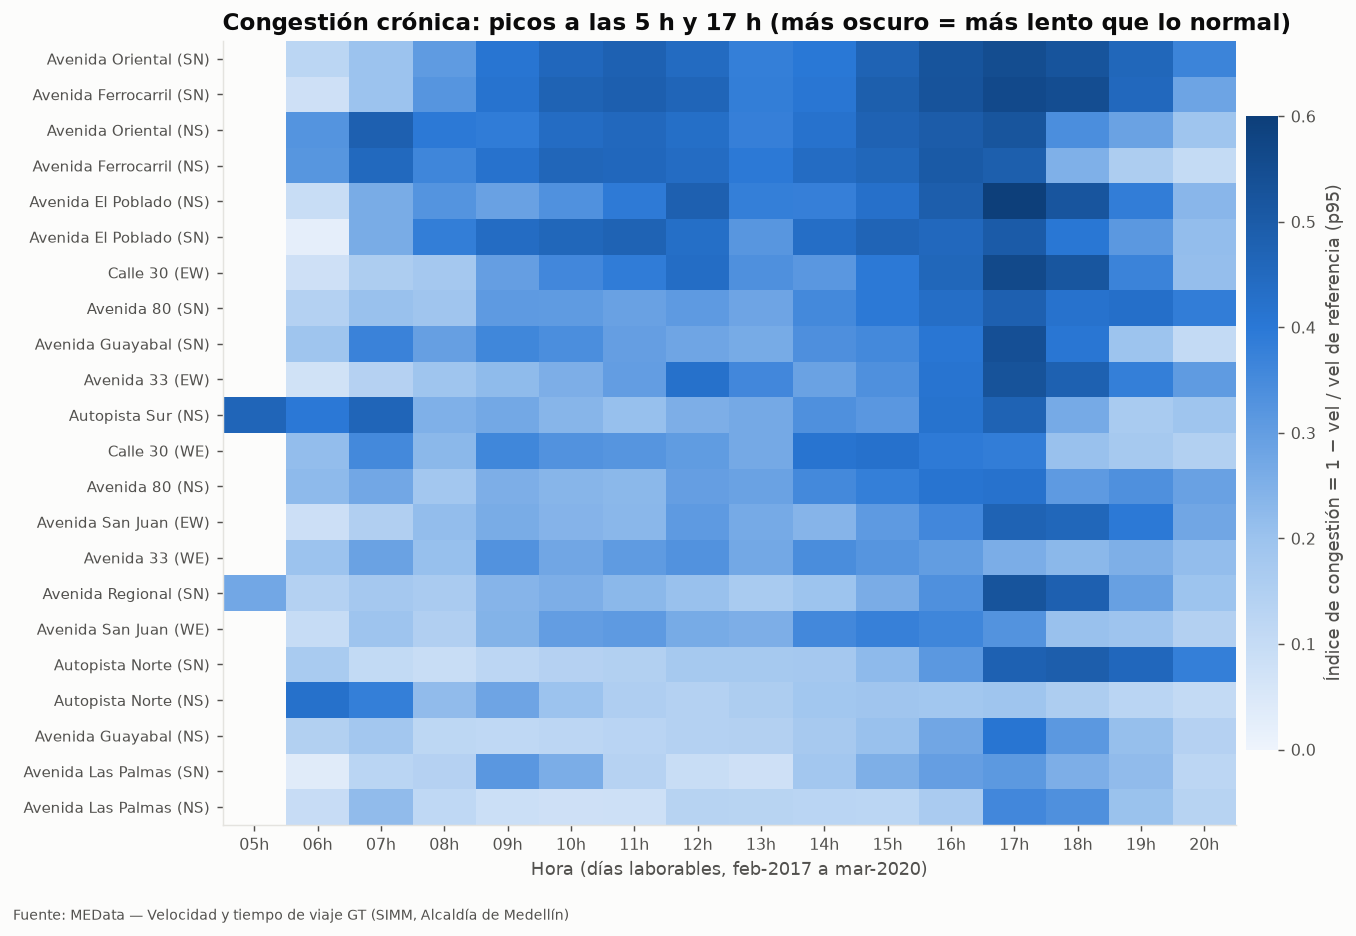

**02_eod2025_viajes_por_hora.png**

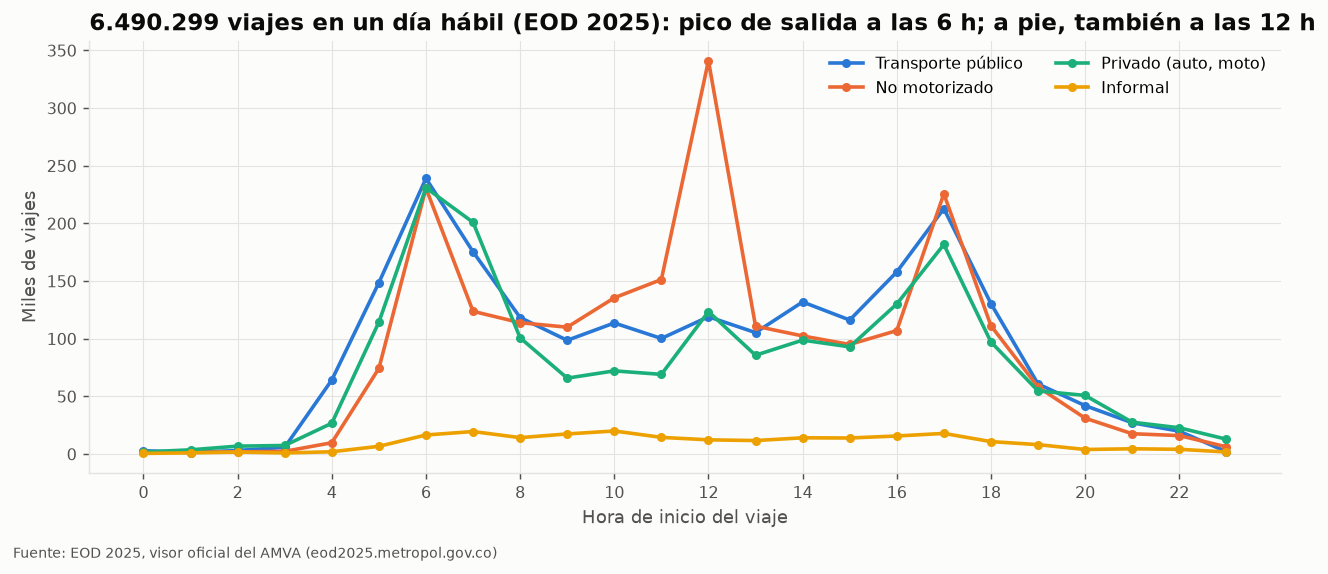

**03_eod2025_reparto_modal.png**

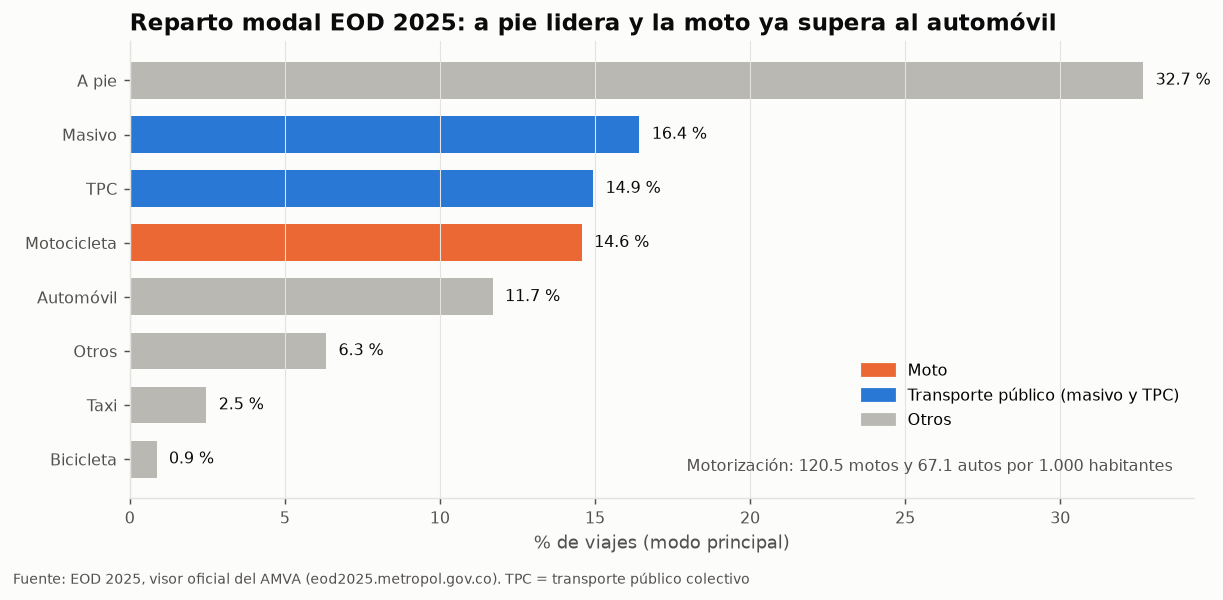

**04_eod2025_densidad_destinos.png**

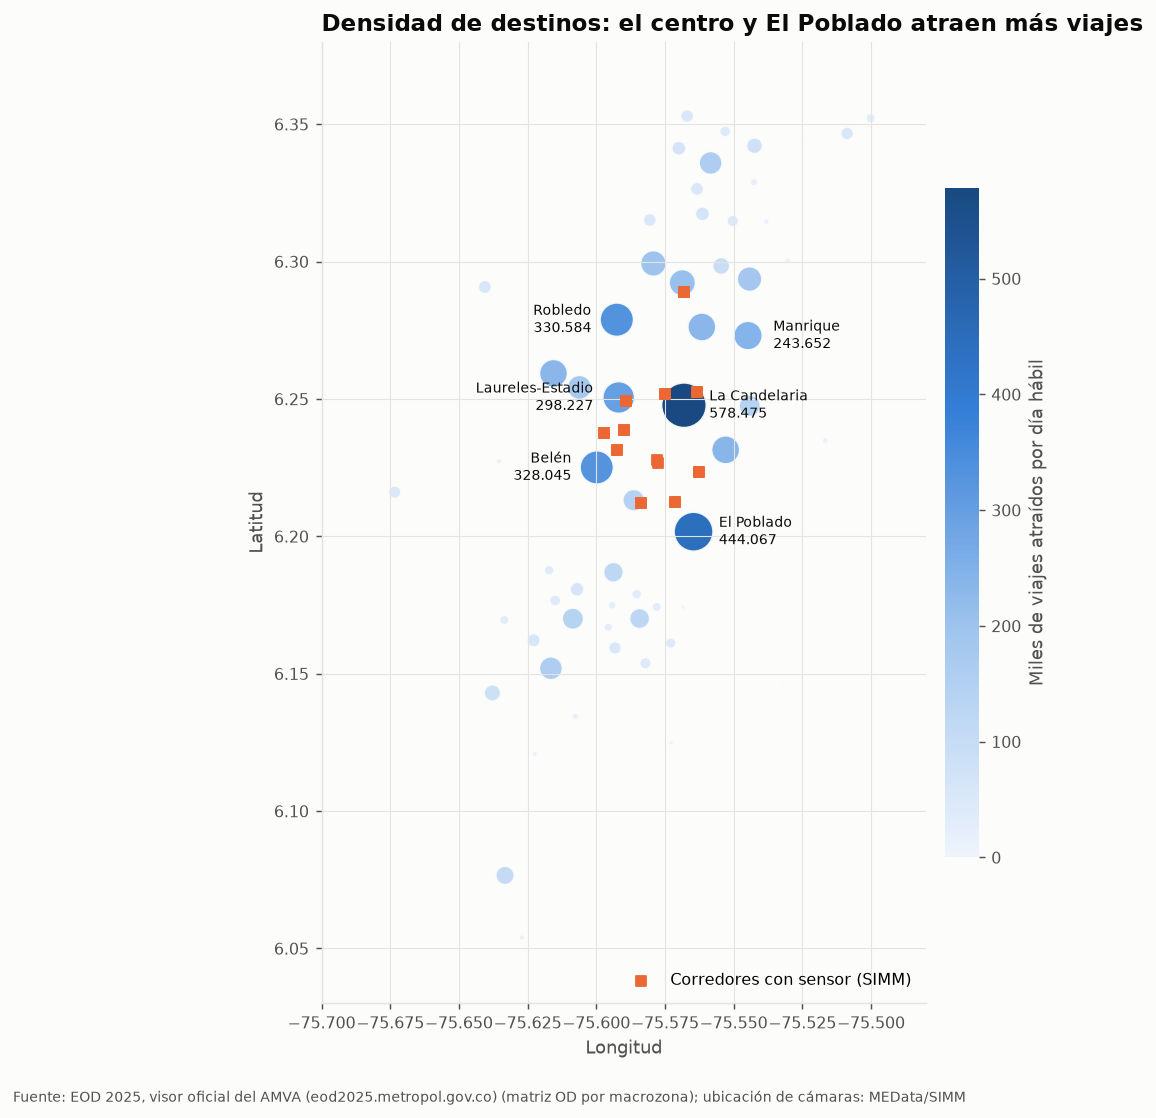

**05_siniestralidad_vial.png**

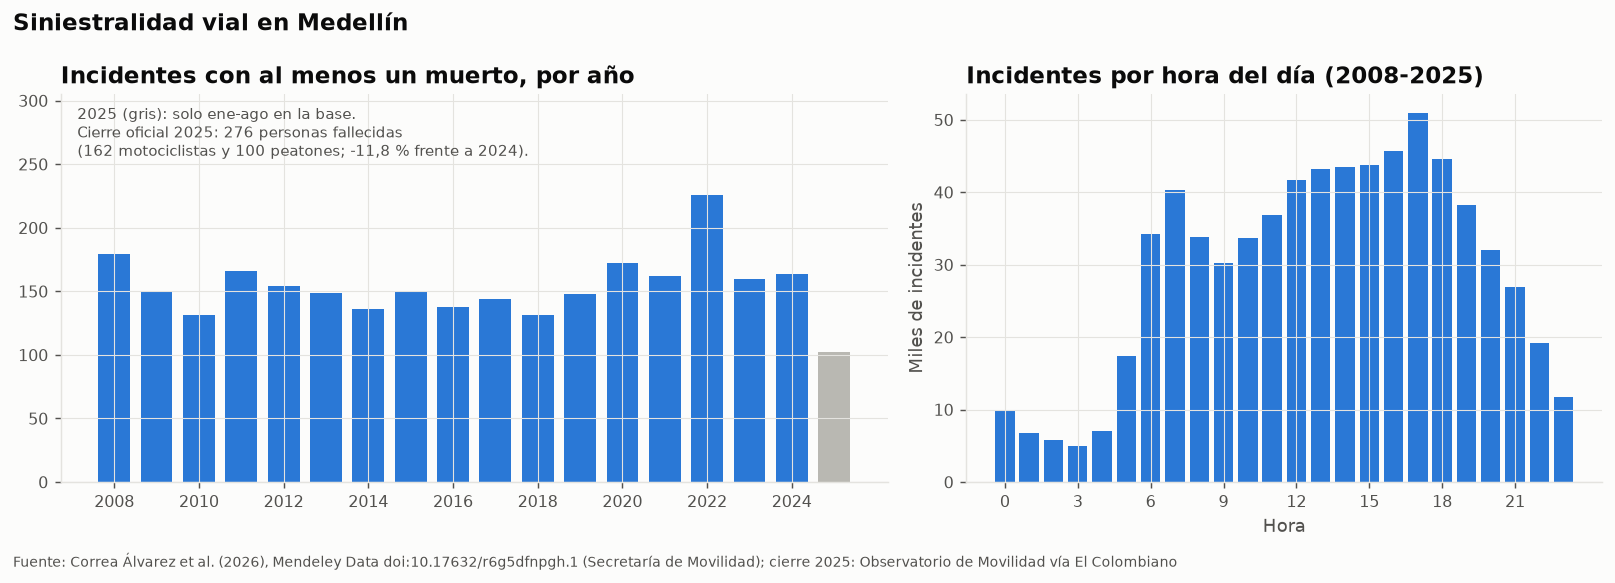

**06_horas_en_colapso_por_tramo.png**

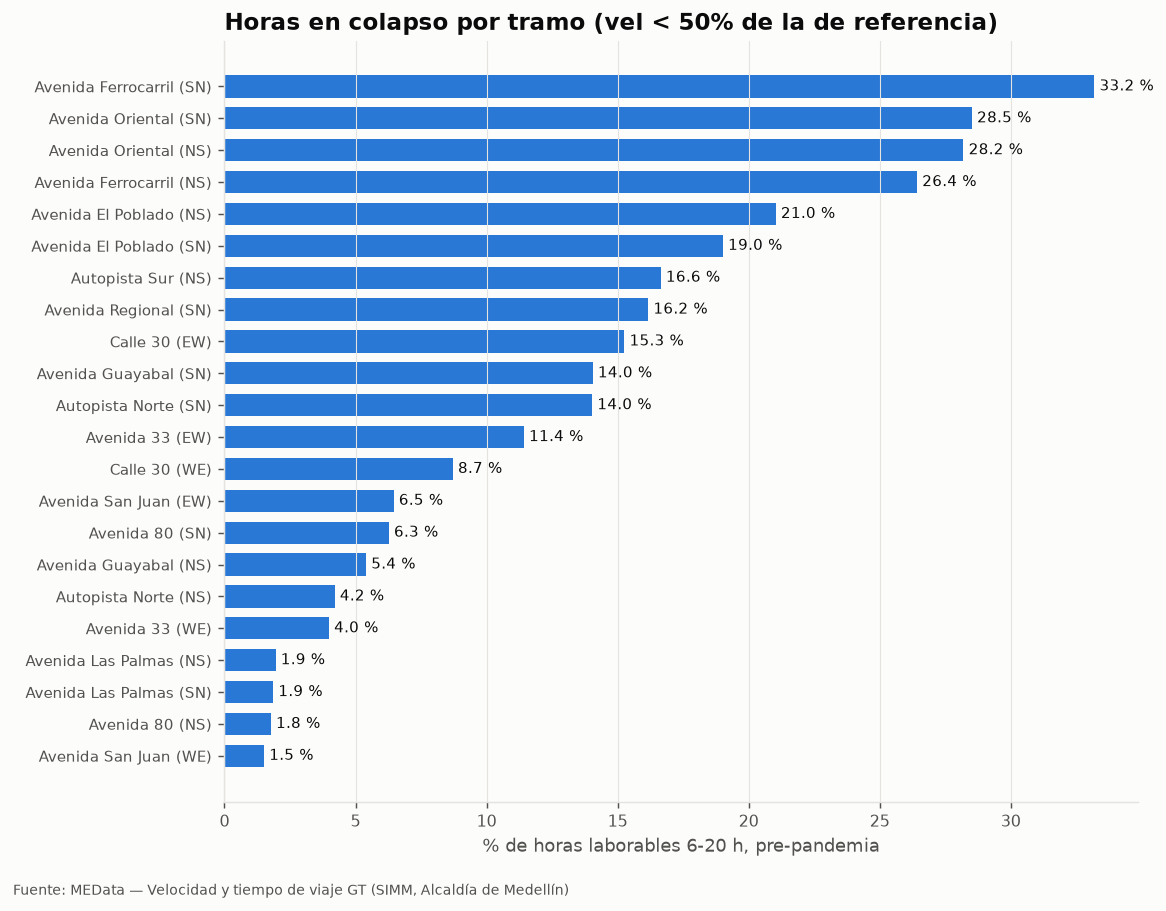

**07_drift_pandemia.png**

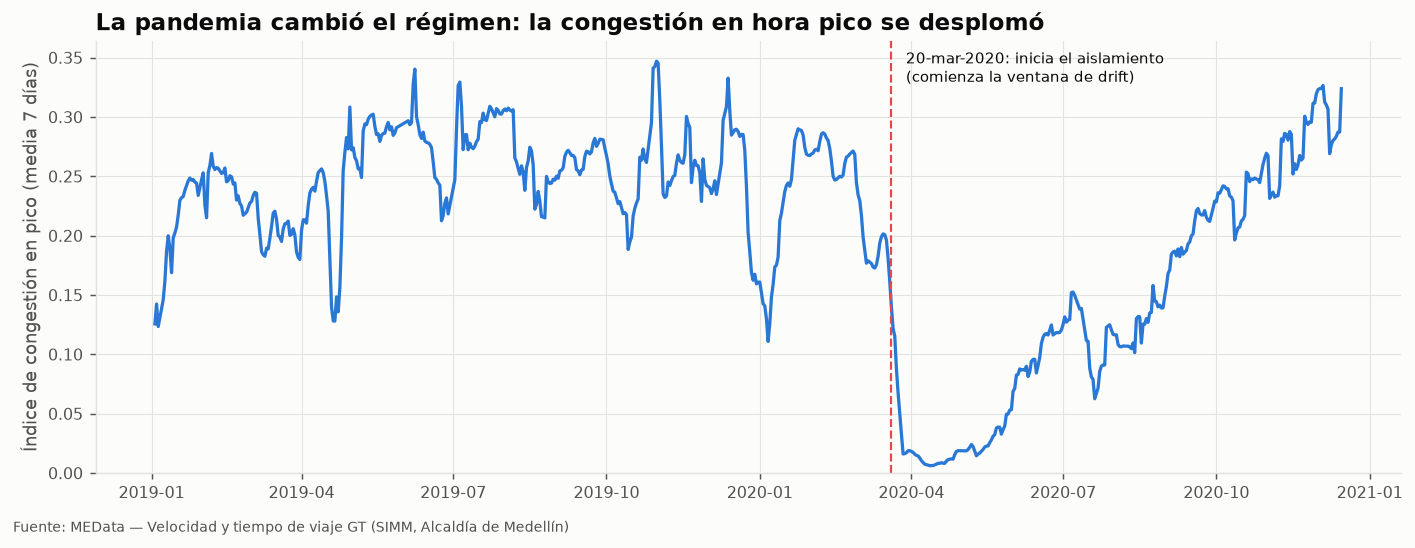

**08_lluvia_vs_colapso.png**

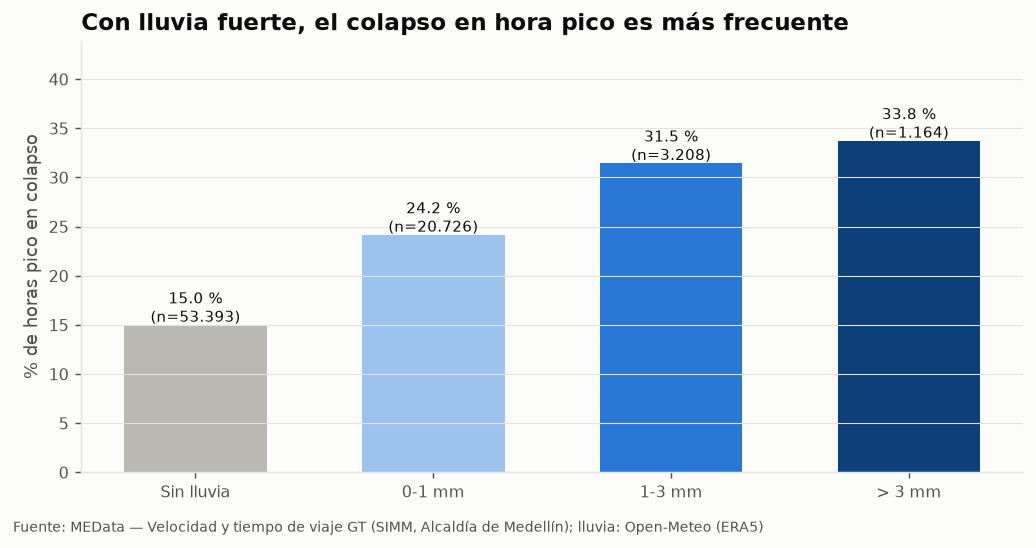

**09_composicion_vehicular_aforos.png**

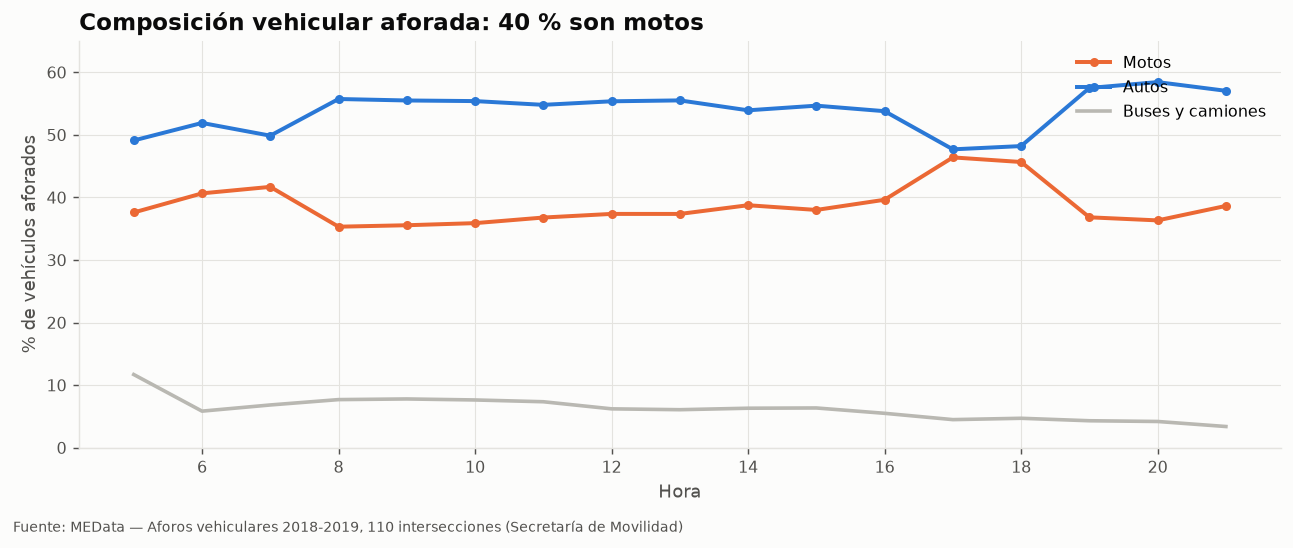

In [56]:
for ruta in sorted(config.EDA_FIGURES.glob("*.png")):
    display(Markdown(f"**{ruta.name}**"))
    display(Image(filename=str(ruta), width=900))

## B.6 Features y split temporal

In [57]:
spec = json.loads((config.DATA_PROCESSED / "feature_spec.json").read_text(encoding="utf-8"))
print("Features:", len(spec["features"]))
print("Filas por partición:", spec["filas"])
print("Tasa de colapso:", spec["tasa_colapso"])
print("Sensores:", spec.get("fuente_sensores", "serie GT"))
print("Drift / holdout:", spec["ventana_drift"])
pd.read_parquet(config.DATA_PROCESSED / "train.parquet").head()

Features: 35
Filas por partición: {'train': 423483, 'test': 111484, 'valid': 84172, 'drift': 70606}
Tasa de colapso: {'drift': 0.1394, 'test': 0.1194, 'train': 0.0729, 'valid': 0.1119}
Sensores: Cámaras ARS/CCTV SIMM (Observatorio de Movilidad de Medellín), serie horaria derivada (2019-09-01 → 2026-09-03)
Drift / holdout: ['2026-01-01', '2026-09-03']


,timestamp,tramo_id,particion,hora_sin,hora_cos,dow_sin,dow_cos,mes_sin,mes_cos,es_fin_semana,...,eod_viajes_generados_mz,eod_viajes_atraidos_mz,velocidad_kmh_lag1,velocidad_kmh_lag2,velocidad_kmh_lag3,ratio_vel_lag1,ratio_vel_lag2,ratio_vel_lag3,y_velocidad_1h,y_colapso_1h
0,2019-09-01 06:00:00,AUTOPISTA_NORTE_NS,train,1.000000,6.123234e-17,-0.781831,0.62349,-1.0,-1.836970e-16,1,...,208449.3,208719.3,NaN,NaN,NaN,NaN,NaN,NaN,50.696078,0
1,2019-09-01 07:00:00,AUTOPISTA_NORTE_NS,train,0.965926,-2.588190e-01,-0.781831,0.62349,-1.0,-1.836970e-16,1,...,208449.3,208719.3,52.541667,NaN,NaN,1.204278,NaN,NaN,48.525134,0
2,2019-09-01 08:00:00,AUTOPISTA_NORTE_NS,train,0.866025,-5.000000e-01,-0.781831,0.62349,-1.0,-1.836970e-16,1,...,208449.3,208719.3,50.696078,52.541667,NaN,1.161976,1.204278,NaN,50.498235,0
3,2019-09-01 09:00:00,AUTOPISTA_NORTE_NS,train,0.707107,-7.071068e-01,-0.781831,0.62349,-1.0,-1.836970e-16,1,...,208449.3,208719.3,48.525134,50.696078,52.541667,1.112217,1.161976,1.204278,50.248578,0
4,2019-09-01 10:00:00,AUTOPISTA_NORTE_NS,train,0.500000,-8.660254e-01,-0.781831,0.62349,-1.0,-1.836970e-16,1,...,208449.3,208719.3,50.498235,48.525134,50.696078,1.157442,1.112217,1.161976,49.928431,0


## B.7 Corridas en MLflow

In [58]:
import mlflow
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT], order_by=["start_time DESC"])
cols = ["tags.tarea", "tags.modelo", "metrics.valid_rmse", "metrics.valid_wape", "metrics.valid_pr_auc",
        "metrics.valid_recall_colapso", "metrics.test_rmse", "metrics.test_pr_auc", "tags.seleccionado"]
runs[runs["tags.tarea"].notna()][[c for c in cols if c in runs.columns]].head(12)

,tags.tarea,tags.modelo,metrics.valid_rmse,metrics.valid_wape,metrics.valid_pr_auc,metrics.valid_recall_colapso,metrics.test_rmse,metrics.test_pr_auc,tags.seleccionado
0,colapso,lightgbm,NaN,NaN,0.847780,0.793946,NaN,0.840823,true
1,colapso,random_forest,NaN,NaN,0.836798,0.797770,NaN,0.839438,NaN
2,colapso,logistica,NaN,NaN,0.807267,0.771641,NaN,0.802635,NaN
3,colapso,regla_umbral,NaN,NaN,0.658657,0.719278,NaN,0.668969,NaN
4,velocidad,mlp,2.102661,0.055049,NaN,NaN,2.105688,NaN,true
5,velocidad,lightgbm,2.153734,0.055743,NaN,NaN,2.029171,NaN,NaN
6,velocidad,random_forest,2.157082,0.056589,NaN,NaN,2.072959,NaN,NaN
7,velocidad,ridge,2.409386,0.062431,NaN,NaN,2.309547,NaN,NaN
8,velocidad,perfil_historico,5.777902,0.169922,NaN,NaN,5.654467,NaN,NaN
10,colapso,lightgbm,NaN,NaN,0.696169,0.696731,NaN,0.638817,NaN


In [59]:
for m in mlflow.MlflowClient().search_registered_models():
    print(m.name, dict(m.aliases or {}))

mobipredict-colapso {'champion': '2'}
mobipredict-velocidad {'champion': '2'}


## B.8 Comparación y decisión

In [60]:
comp = pd.read_csv(config.COMPARISON_FILE)
display(comp[comp.tarea == "velocidad"][["modelo", "seleccionado", "valid_rmse", "valid_wape", "test_mae", "test_rmse", "drift_mae", "latencia_ms_1000"]])
display(comp[comp.tarea == "colapso"][["modelo", "seleccionado", "valid_pr_auc", "valid_recall_colapso", "test_pr_auc", "test_recall_colapso", "test_precision_colapso", "umbral"]])

,modelo,seleccionado,valid_rmse,valid_wape,test_mae,test_rmse,drift_mae,latencia_ms_1000
0,perfil_historico,False,5.7779,0.1699,4.4691,5.6545,5.0126,0.1650
1,ridge,False,2.4094,0.0624,1.6482,2.3095,1.8577,2.0847
2,random_forest,False,2.1571,0.0566,1.4622,2.0730,1.6900,64.8680
3,lightgbm,False,2.1537,0.0557,1.4362,2.0292,1.6772,21.2763
4,mlp,True,2.1027,0.0550,1.5031,2.1057,1.7361,5.0451


,modelo,seleccionado,valid_pr_auc,valid_recall_colapso,test_pr_auc,test_recall_colapso,test_precision_colapso,umbral
5,regla_umbral,False,0.6587,0.7193,0.6690,0.6976,0.6456,0.5570
6,logistica,False,0.8073,0.7716,0.8026,0.7535,0.7219,0.8627
7,random_forest,False,0.8368,0.7978,0.8394,0.8104,0.7220,0.7100
8,lightgbm,True,0.8478,0.7939,0.8408,0.7944,0.7380,0.3482


In [61]:
display(Markdown(config.DECISION_FILE.read_text(encoding="utf-8")))

# Decisión de modelo — MobiPredict

Generado automáticamente el 2026-11-19T01:26:22+00:00 por `src/mobipredict/selection.py`.

## Resumen

- **Velocidad a 1 hora:** `mlp` — RMSE de prueba 2.11 km/h, MAE 1.50 km/h, WAPE 5.9 % (perfil histórico: WAPE 17.6 %).
- **Colapso a 1 hora:** `lightgbm` — PR-AUC de prueba 0.841, recall 0.79, precisión 0.74 con umbral 0.348 (regla base: PR-AUC 0.669).

## Datos y protocolo

- Sensores: Cámaras ARS/CCTV SIMM (Observatorio de Movilidad de Medellín), serie horaria derivada (2019-09-01 → 2026-09-03), 22 tramos, lecturas horarias 6:00-20:00.
- Split temporal: entrenamiento hasta 2024-01-01, validación hasta 2025-01-01, prueba hasta 2026-01-01. La hora frontera de cada partición se descarta para que el objetivo no cruce de una a otra.
- Drift / holdout reciente: 2026-01-01 a 2026-09-03, solo para diagnóstico.
- Colapso = velocidad < 50% de la velocidad de referencia del tramo (percentil 95 del entrenamiento). Tasa de colapso: drift 13.9%, test 11.9%, train 7.3%, valid 11.2%.
- Hiperparámetros con validación cruzada temporal (TimeSeriesSplit, 3 cortes): RandomizedSearchCV y Optuna.
- Selección y umbral de decisión se fijan en **validación**; **prueba** solo se reporta.

## Velocidad a 1 hora

| Modelo | RMSE val | WAPE val | MAE pico val | MAE test | RMSE test | R² test | ms/1000 filas |
| --- | --- | --- | --- | --- | --- | --- | --- |
| **mlp** ✔ | 2.10 | 0.055 | 1.55 | 1.50 | 2.11 | 0.889 | 5.0 |
| lightgbm | 2.15 | 0.056 | 1.65 | 1.44 | 2.03 | 0.897 | 21.3 |
| random_forest | 2.16 | 0.057 | 1.62 | 1.46 | 2.07 | 0.893 | 64.9 |
| ridge | 2.41 | 0.062 | 1.84 | 1.65 | 2.31 | 0.867 | 2.1 |
| perfil_historico | 5.78 | 0.170 | 4.54 | 4.47 | 5.65 | 0.202 | 0.2 |

Unidades: km/h. WAPE = error absoluto total / velocidad total.

**Razonamiento**

- mlp obtiene el menor RMSE de validación (2.10 km/h) y reduce el WAPE 67.6 % frente al perfil histórico.
- En prueba, lightgbm queda ligeramente mejor en RMSE (2.029 frente a 2.106). No se cambia la elección: hacerlo usaría el conjunto de prueba para seleccionar. La diferencia se vigila en producción con el esquema champion/challenger.

## Colapso a 1 hora

| Modelo | PR-AUC val | Recall val | Precisión val | Brier val | PR-AUC test | Recall test | Precisión test | Falsas alarmas/día (red) | ms/1000 filas |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **lightgbm** ✔ | 0.848 | 0.794 | 0.735 | 0.038 | 0.841 | 0.794 | 0.738 | 10.3 | 5.2 |
| random_forest | 0.837 | 0.798 | 0.721 | 0.056 | 0.839 | 0.810 | 0.722 | 11.4 | 49.2 |
| logistica | 0.807 | 0.772 | 0.708 | 0.096 | 0.803 | 0.753 | 0.722 | 10.6 | 1.8 |
| regla_umbral | 0.659 | 0.719 | 0.635 | 0.065 | 0.669 | 0.698 | 0.646 | 14.0 | 0.2 |

**Razonamiento**

- lightgbm obtiene PR-AUC de validación 0.848 con recall 0.79 y precisión 0.73 (umbral 0.348).
- En prueba el ganador también es el mejor en PR-AUC: la decisión se sostiene fuera de muestra.
- Se prioriza recall: una alerta perdida cuesta más que una falsa alarma que un operador descarta.

## Prueba de estrés: holdout reciente (drift)

| Modelo | MAE test | MAE drift | WAPE drift |
| --- | --- | --- | --- |
| **mlp** ✔ | 1.50 | 1.74 | 0.068 |
| lightgbm | 1.44 | 1.68 | 0.065 |
| random_forest | 1.46 | 1.69 | 0.066 |
| ridge | 1.65 | 1.86 | 0.072 |
| perfil_historico | 4.47 | 5.01 | 0.195 |

| Modelo | PR-AUC test | PR-AUC drift | Recall drift | Precisión drift | Falsas alarmas/día drift |
| --- | --- | --- | --- | --- | --- |
| **lightgbm** ✔ | 0.841 | 0.842 | 0.796 | 0.758 | 10.5 |
| random_forest | 0.839 | 0.843 | 0.821 | 0.745 | 11.6 |
| logistica | 0.803 | 0.803 | 0.721 | 0.759 | 9.5 |
| regla_umbral | 0.669 | 0.689 | 0.688 | 0.672 | 13.9 |

— = no aplica: sin colapsos reales en el periodo no se pueden medir recall ni PR-AUC.

La tasa de colapso del periodo de drift es 13.9% frente a 11.9% en prueba: la congestión sigue creciendo año a año. Que las métricas se sostengan en este periodo, que el modelo nunca vio, indica que generaliza a datos más recientes; aun así el monitoreo debe vigilar la tasa de alertas y disparar el reentrenamiento cuando cambie el régimen, no solo por calendario.

## Riesgos y siguientes pasos

- La serie ARS sale de una exportación de las bases diarias de cámaras ARS/CCTV del Observatorio de Movilidad, no de una descarga pública automática: para operar hay que conectar el feed del SIMM.
- Las cámaras ARS miden velocidad en un punto, no tiempo de viaje del corredor; el tiempo de viaje se estima con la longitud del tramo. Las métricas no son comparables 1 a 1 con las del modelo GT (2017-2020).
- Revisar el umbral de colapso y el de alerta con la Secretaría de Movilidad.
- Evaluar un modelo de grafos espacio-temporal como challenger con más tramos.

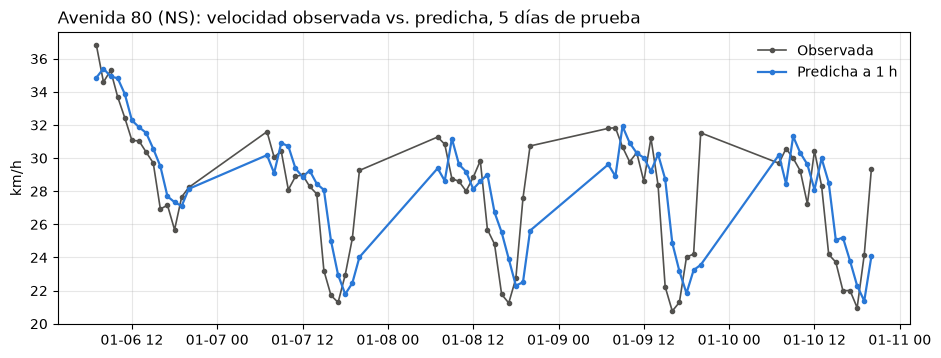

In [62]:
import matplotlib.pyplot as plt, joblib
from mobipredict.features import FEATURES_NUM
modelo = joblib.load(config.MODEL_SPEED_FILE)
test = pd.read_parquet(config.DATA_PROCESSED / "test.parquet")
t = test[test.tramo_id == "AVENIDA_80_NS"].sort_values("timestamp")
t = t[t.timestamp.dt.normalize().isin(t.timestamp.dt.normalize().drop_duplicates().iloc[5:10])]
x = t["timestamp"] + pd.Timedelta(hours=1)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, t["y_velocidad_1h"], "o-", color="#52514e", ms=3, lw=1.2, label="Observada")
ax.plot(x, modelo.predict(t[FEATURES_NUM]), "o-", color="#2a78d6", ms=3, lw=1.6, label="Predicha a 1 h")
ax.set_title("Avenida 80 (NS): velocidad observada vs. predicha, 5 días de prueba", loc="left")
ax.set_ylabel("km/h"); ax.legend(frameon=False); ax.grid(alpha=.3)
plt.show()

---
# Parte C — Servicio y despliegue

In [63]:
from fastapi.testclient import TestClient
from api.main import app
from api.schemas import EJEMPLO_OBS, EJEMPLO_TRAMO
with TestClient(app) as cliente:
    print(cliente.get("/health").json())
    display(pd.Series({k: v for k, v in cliente.get("/valor").json().items() if not isinstance(v, dict)}).to_frame("valor en prueba"))
    r = cliente.post("/predict", json={"tramo_id": EJEMPLO_TRAMO, "observaciones": EJEMPLO_OBS})
    display(pd.Series(r.json()).to_frame("respuesta"))

{'status': 'ok', 'modelos_cargados': True, 'modelo_velocidad': 'mlp', 'modelo_colapso': 'lightgbm', 'horizonte_min': 60, 'entrenado_utc': '2026-11-19T01:26:22+00:00', 'detalle': None}


,valor en prueba
periodo,test
desde,2025-01-01T06:00:00
hasta,2025-12-31T19:00:00
dias,365
horizonte_min,60
pct_colapsos_sin_aviso,0.2942
alertas_por_dia,39.3
lecturas,111484
tramos,22
colapsos_reales,13312


,respuesta
tramo_id,AVENIDA_80_NS
corredor,Avenida 80
sentido,NS
timestamp_prediccion,2025-02-11T18:00:00
horizonte_min,60
velocidad_predicha_kmh,16.54
tiempo_viaje_predicho_min,18.5
velocidad_referencia_kmh,22.6
probabilidad_colapso,0.0067
alerta_colapso,False


In [64]:
!"{sys.executable}" -m pytest -q tests

...........................................                              [100%]
============================== warnings summary ===============================
.venv\Lib\site-packages\fastapi\testclient.py:1
  C:\Users\User\Documents\Proyecto Final\mobipredict\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
43 passed, 1 warning in 8.67s


## Despliegue

```bash
python scripts/descargar_datos.py && python run_pipeline.py      # serie GT + EDA
python scripts/convertir_ars_a_sensores.py --entrada <carpeta>   # serie ARS
python scripts/reentrenar_con_ars.py                             # modelo vigente
uvicorn api.main:app --port 8000
docker compose up --build                  # trainer -> API (:8000) + MLflow UI (:5000)
```

Fuentes, licencias y tratamiento de calidad: `docs/fuentes_de_datos.md` y `data/fuentes_datos.csv`.